In [6]:
# Kara sea general case study:
# download all data for the formation period in 2014, eg.

import numpy as np
from numpy import ma

import matplotlib.pyplot as plt
from compiler.ast import flatten

import datetime, time
import pickle
import netCDF4

import matplotlib.pyplot as plt

import os, sys
sys.path.append('/home/cercache/users/atarasen/codes/python/')
sys.path.append('/home3/homedir7/perso/atarasen/codes/python/')
sys.path.append('/home3/homedir7/perso/atarasen/codes/python/collocation')

import nice_functions as nf
import nice_functions2 as nf2
reload(nf2)
#import ncdfView as nv

import plot_stereo
reload(plot_stereo)

import S1_open_process_and_visu as S1_open
reload (S1_open)

import collocation as colloc
reload(colloc)

import data_analysis as dt
reload(dt)

import buoy as buoy_module
reload (buoy_module)

import data_analysis
reload(data_analysis)

sys.path.append('/home3/homedir7/perso/atarasen/codes/python/posada/')
sys.path.append('/home3/homedir7/perso/atarasen/codes/python/cmod/')


from posada.Handlers.sar import SAR
from posada.Models.swath import Swath
from posada.Readers.safe import SAFEGeoTiffFile


fpath = '/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/'
# fpathout = '/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/mosaics/'
fpathout = '/export/home/data/S1/Kara/mosaics/'

In [ ]:
# part 1: download all the data for Kara Sea:

lonmin_s='52'; lonmax_s='104';
latmin_s='69'; latmax_s='81'
day_str1 ='2015-10-01'
day_str2 ='2015-11-10'
# day_str1 ='2014-10-01'
# day_str2 ='2014-11-10'

os.system('/home/cercache/users/atarasen/codes/python/peps/peps_download.py -w %s \
-c S1 --lonmin %s --lonmax %s --latmin %s --latmax %s -a /home/cercache/users/atarasen/codes/python/peps/peps.txt \
-d %s -f %s'%(fpath, lonmin_s, lonmax_s, latmin_s, latmax_s, day_str1, day_str2))

In [ ]:
# Part 2:  check for the mosaic and collocation condition

fdir_0=sorted(os.listdir(fpath))
pol= 'hh'

s1_names_dic={}
lat_dic={}; lon_dic={}
corners_dic={}

# Step 2.1: transform all names of S1 files into datetime structures, find all potential mosaics, 
# sort the dictionary by time of sensing.

#Small additional sorting of fnames by date, not taking into account if it is SSH/SDH or GRDH/GRDM:
nf.tic()
temp_dic={}
for fname_full in fdir_0:
        if fname_full[-4:]=='.zip':
            temp_dic[fname_full[17:]]=fname_full

list_of_files = sorted(temp_dic.keys())


# Real sorting:
for counter, name_temp in enumerate(list_of_files):
        fname = temp_dic[name_temp]
        print fname,  counter, 'of', len(fdir_0)
#     try:
        corners, lats, lons = S1_open.s1_get_corners(fpath+'/'+fname, pol, excl_bord = False, )                
        if s1_names_dic=={}: #  Fist special case
            fname_1=fname[:]
            date_1=S1_open.s1nametodatetime(fname_1)            
            s1_names_dic[date_1]=[fname_1]

            lat_dic[date_1]=[lats]
            lon_dic[date_1]=[lons]
            corners_dic[date_1]=[corners]

        else:
            if colloc.mosaic_condition(fname_1, fname)==True:
                s1_names_dic[date_1].append(fname)
                lat_dic[date_1].append(lats)
                lon_dic[date_1].append(lons)
                corners_dic[date_1].append(corners)
            else:
                fname_1=fname[:]
                date_1=S1_open.s1nametodatetime(fname_1)
                s1_names_dic[date_1]=[fname_1]
                lat_dic[date_1]=[lats]
                lon_dic[date_1]=[lons]

                corners_dic[date_1]=[corners]
                
#     except:
#         pass
                     
nf.toc()      
dates = sorted(s1_names_dic.keys())

with open(fpathout+'/Kara.pickle', 'wb') as handle:
    pickle.dump([dates, s1_names_dic, lat_dic, lon_dic, corners_dic], handle, protocol=pickle.HIGHEST_PROTOCOL)

print 'S1 names sorted'                    

2014-10-03 00:36:36 2014-10-03 03:54:03
area of intersection 0.0
cond_area False
2014-10-03 00:36:36 2014-10-03 10:22:48
area of intersection 27.715785047
cond_area True
Images overlap


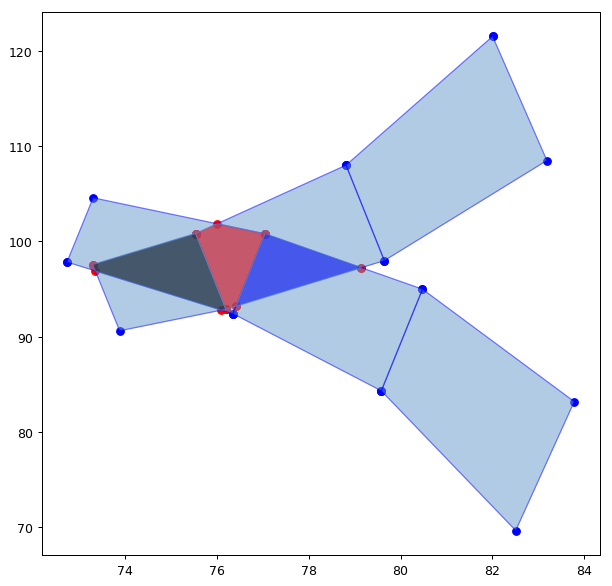

Successful overlap:
['S1A_EW_GRDH_1SDH_20141003T003636_20141003T003740_002658_002F54_ECFA.zip', 'S1A_EW_GRDH_1SDH_20141003T003740_20141003T003840_002658_002F54_A006.zip', 'S1A_EW_GRDH_1SDH_20141003T003840_20141003T003920_002658_002F54_4DD1.zip']
with
['S1A_EW_GRDH_1SDH_20141003T102248_20141003T102352_002664_002F76_222F.zip', 'S1A_EW_GRDH_1SDH_20141003T102352_20141003T102452_002664_002F76_43FC.zip', 'S1A_EW_GRDH_1SDH_20141003T102452_20141003T102553_002664_002F76_F611.zip']

Time difference is  9:46:12
2014-10-03T003636 2014-10-03T102248
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141003T003636_20141003T003740_002658_002F54_ECFA.zip
73.2917480469 92.7906950901 76.1905975342 100.822906494
78.3486 94.1476 83.4977 126.025
76.413499301 93.212212426 79.1446573036 100.79901123
78.3486 94.1476 83.4977 126.025
75.5316085815 92.8835830688 77.042388916 101.849809453
78.3486 94.1476 83.4977 126.025
False True
/home/cercache/users/atarasen/data/Sentinel-1

/usr/local/lib/python2.7/dist-packages/ipykernel/__main__.py:73: DeprecationWarning: elementwise == comparison failed; this will raise an error in the future.


73.2917480469 92.7906950901 76.1905975342 100.822906494
75.1634 89.9553 79.854 111.915
76.413499301 93.212212426 79.1446573036 100.79901123
75.1634 89.9553 79.854 111.915
75.5316085815 92.8835830688 77.042388916 101.849809453
75.1634 89.9553 79.854 111.915
False False
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141003T003840_20141003T003920_002658_002F54_4DD1.zip
73.2917480469 92.7906950901 76.1905975342 100.822906494
72.9671 88.0936 76.3551 104.085
76.413499301 93.212212426 79.1446573036 100.79901123
72.9671 88.0936 76.3551 104.085
75.5316085815 92.8835830688 77.042388916 101.849809453
72.9671 88.0936 76.3551 104.085
False False
73.292 79.144 92.79 101.84
Elapsed time is 64.6604001522 seconds.
Mosaic  1
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141003T102248_20141003T102352_002664_002F76_222F.zip
73.2917480469 92.7906950901 76.1905975342 100.822906494
72.4107 89.0038 77.2137 107.023
76.413499301 93.212212426 79.14

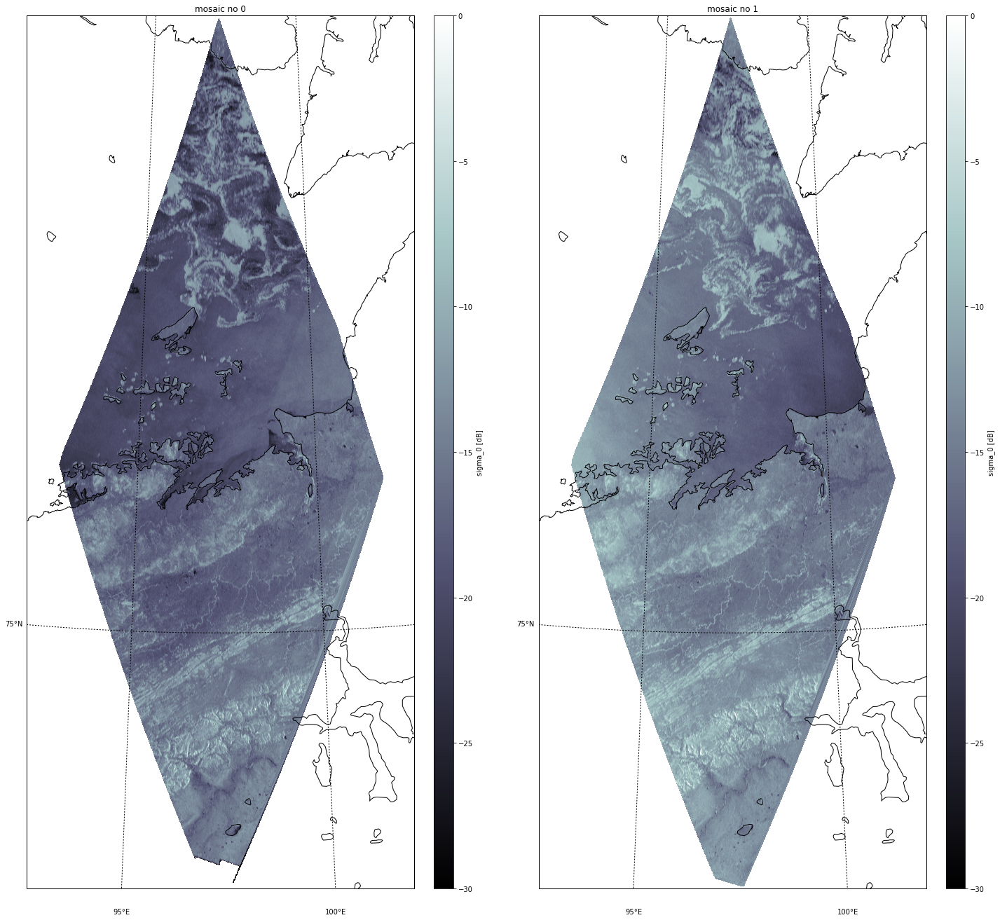

Kara_2014-10-03T003636_2014-10-03T102248_lat-3_lon-2_hh.pickle is created
2014-10-03 03:54:03 2014-10-03 10:22:48
area of intersection 0.237575143023
cond_area False
2014-10-03 03:54:03 2014-10-03 13:38:53
area of intersection 28.304572257
cond_area True
Images overlap


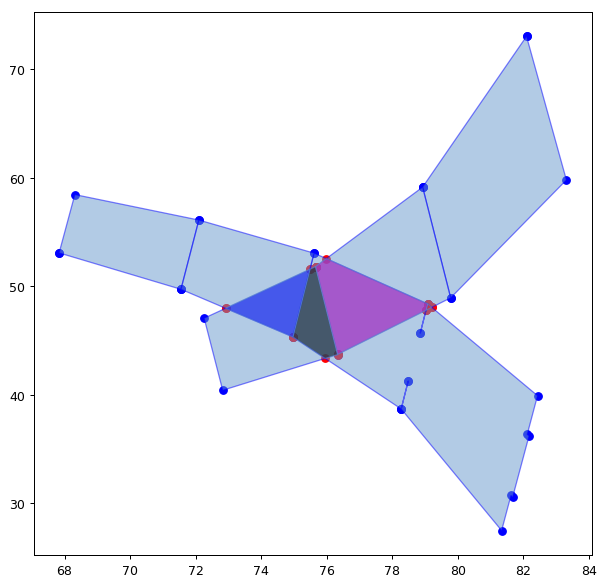

Successful overlap:
['S1A_EW_GRDH_1SDH_20141003T035403_20141003T035507_002660_002F63_5346.zip', 'S1A_EW_GRDH_1SDH_20141003T035507_20141003T035607_002660_002F63_DBA5.zip', 'S1A_EW_GRDH_1SDH_20141003T035607_20141003T035707_002660_002F63_9B6F.zip']
with
['S1A_EW_GRDH_1SDH_20141003T133853_20141003T133957_002666_002F83_CEAF.zip', 'S1A_EW_GRDH_1SDH_20141003T133957_20141003T134057_002666_002F83_0BE7.zip', 'S1A_EW_GRDM_1SDH_20141003T134057_20141003T134157_002666_002F83_0B57.zip', 'S1A_EW_GRDH_1SDH_20141003T134057_20141003T134157_002666_002F83_7D9C.zip', 'S1A_EW_GRDH_1SDH_20141003T134157_20141003T134257_002666_002F83_30DE.zip', 'S1A_EW_GRDM_1SDH_20141003T134157_20141003T134257_002666_002F83_7772.zip']

Time difference is  9:44:50
2014-10-03T035403 2014-10-03T133853
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141003T035403_20141003T035507_002660_002F63_5346.zip
74.9696731567 43.3541226122 76.3344650269 51.8016433716
78.458 45.0106 83.636 77.5619
72.91

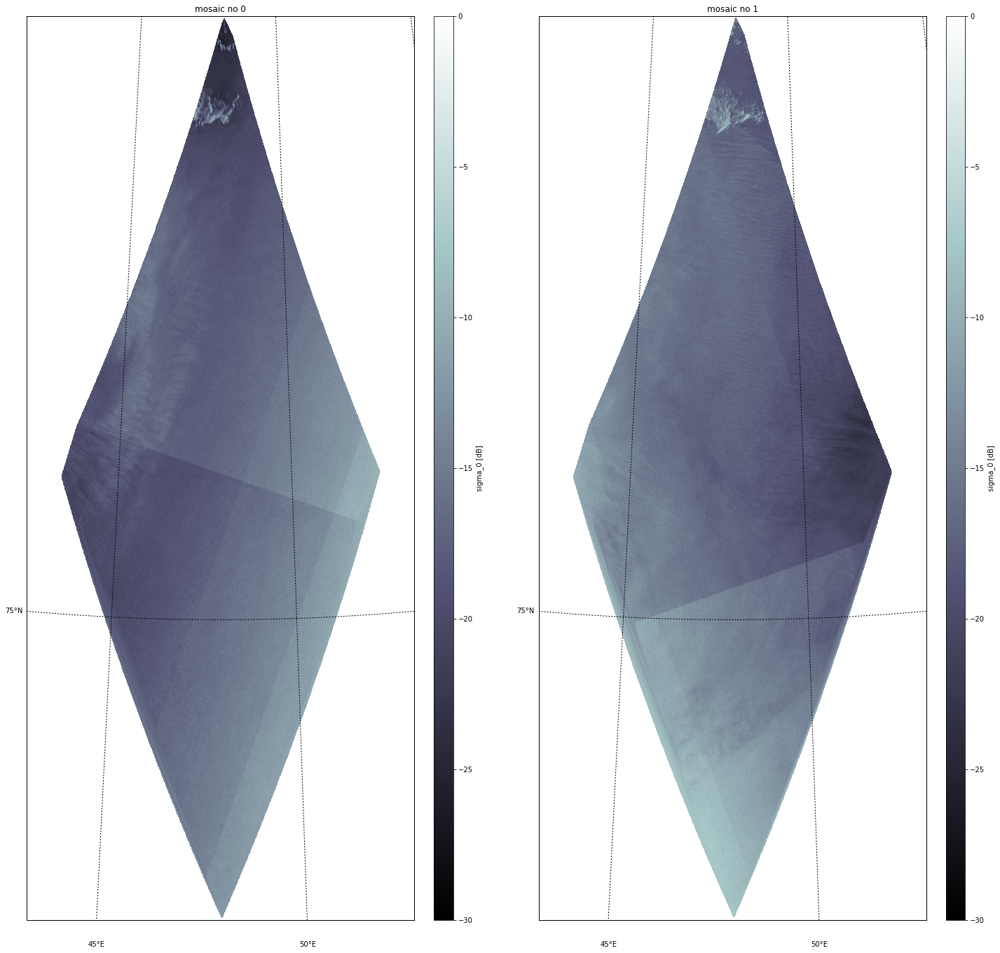

Kara_2014-10-03T035403_2014-10-03T133853_lat-3_lon-2_hh.pickle is created
2014-10-03 10:22:48 2014-10-03 13:38:53
area of intersection 0.0
cond_area False
2014-10-03 10:22:48 2014-10-03 23:41:05
area of intersection 9.8635955296e-06
cond_area False
2014-10-03 10:22:48 2014-10-04 02:56:24
area of intersection 24.6295335776
cond_area True
Images overlap


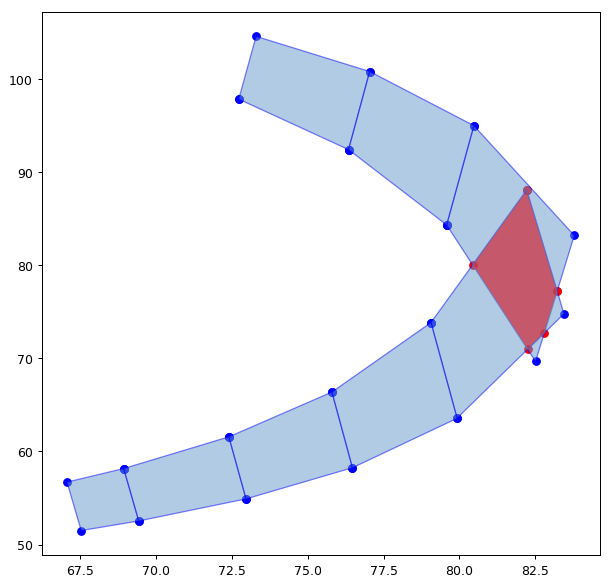

Successful overlap:
['S1A_EW_GRDH_1SDH_20141003T102248_20141003T102352_002664_002F76_222F.zip', 'S1A_EW_GRDH_1SDH_20141003T102352_20141003T102452_002664_002F76_43FC.zip', 'S1A_EW_GRDH_1SDH_20141003T102452_20141003T102553_002664_002F76_F611.zip']
with
['S1A_EW_GRDH_1SDH_20141004T025624_20141004T025729_002674_002FB4_F3E8.zip', 'S1A_EW_GRDH_1SDH_20141004T025729_20141004T025829_002674_002FB4_620A.zip', 'S1A_EW_GRDH_1SDH_20141004T025829_20141004T025929_002674_002FB4_FFFD.zip', 'S1A_EW_GRDH_1SDH_20141004T025929_20141004T030029_002674_002FB4_6028.zip', 'S1A_EW_GRDH_1SDH_20141004T030029_20141004T030101_002674_002FB4_6D3B.zip']

Time difference is  16:33:36
2014-10-03T102248 2014-10-04T025624
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141003T102248_20141003T102352_002664_002F76_222F.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141003T102352_20141003T102452_002664_002F76_43FC.zip
False True
/home/cerca

2014-10-03 13:38:53 2014-10-04 02:56:24
area of intersection 17.8550274661
cond_area True
Images overlap


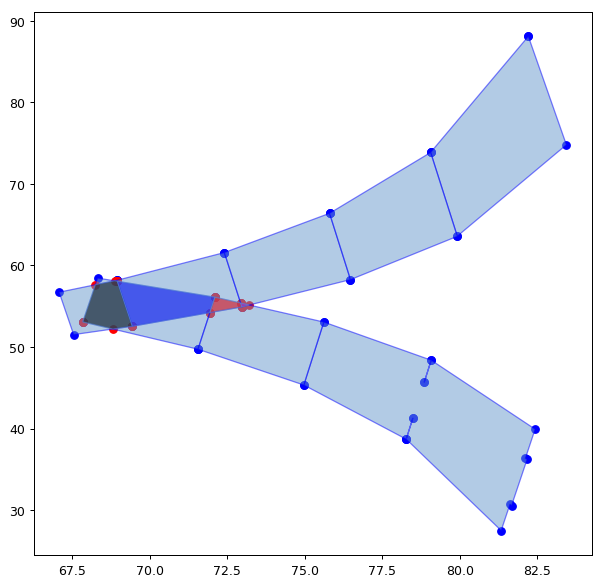

Successful overlap:
['S1A_EW_GRDH_1SDH_20141003T133853_20141003T133957_002666_002F83_CEAF.zip', 'S1A_EW_GRDH_1SDH_20141003T133957_20141003T134057_002666_002F83_0BE7.zip', 'S1A_EW_GRDM_1SDH_20141003T134057_20141003T134157_002666_002F83_0B57.zip', 'S1A_EW_GRDH_1SDH_20141003T134057_20141003T134157_002666_002F83_7D9C.zip', 'S1A_EW_GRDH_1SDH_20141003T134157_20141003T134257_002666_002F83_30DE.zip', 'S1A_EW_GRDM_1SDH_20141003T134157_20141003T134257_002666_002F83_7772.zip']
with
['S1A_EW_GRDH_1SDH_20141004T025624_20141004T025729_002674_002FB4_F3E8.zip', 'S1A_EW_GRDH_1SDH_20141004T025729_20141004T025829_002674_002FB4_620A.zip', 'S1A_EW_GRDH_1SDH_20141004T025829_20141004T025929_002674_002FB4_FFFD.zip', 'S1A_EW_GRDH_1SDH_20141004T025929_20141004T030029_002674_002FB4_6028.zip', 'S1A_EW_GRDH_1SDH_20141004T030029_20141004T030101_002674_002FB4_6D3B.zip']

Time difference is  13:17:31
2014-10-03T133853 2014-10-04T025624
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_

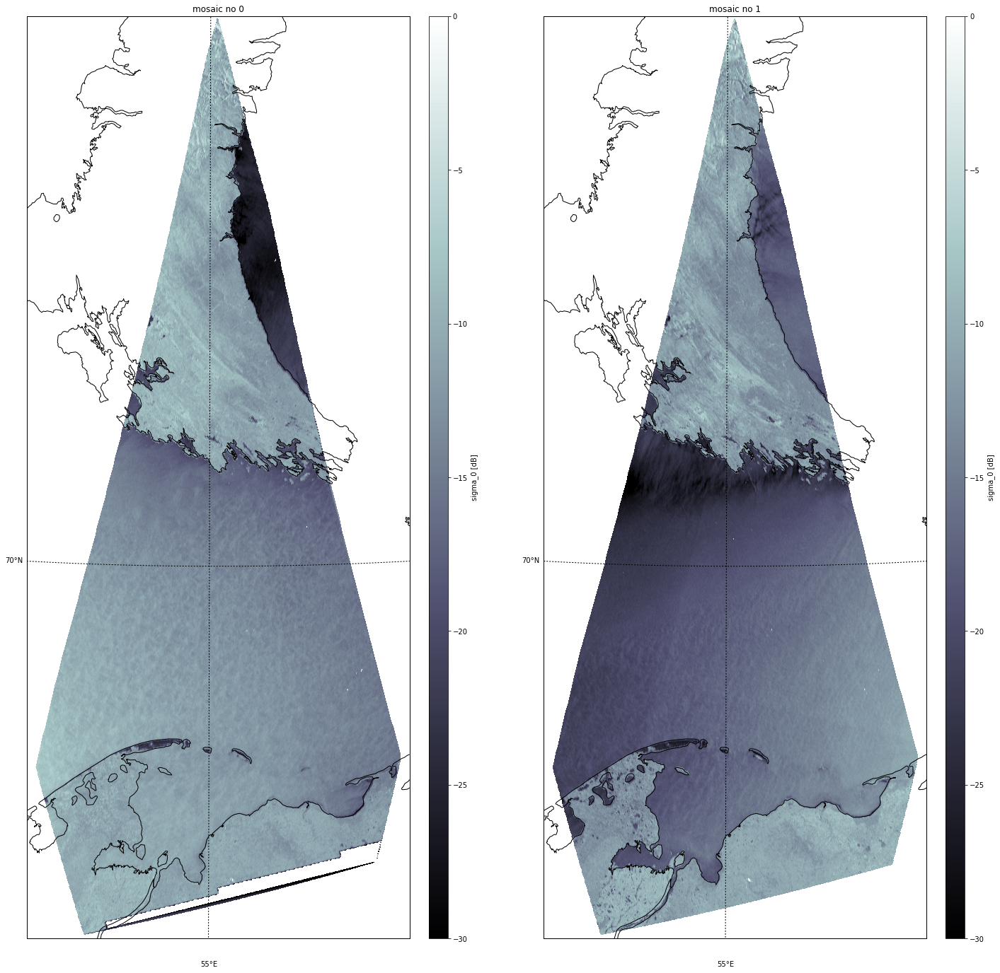

Kara_2014-10-03T133853_2014-10-04T025624_lat-3_lon-2_hh.pickle is created
2014-10-03 23:41:05 2014-10-04 02:56:24
area of intersection 0.0
cond_area False
2014-10-03 23:41:05 2014-10-04 04:35:09
area of intersection 0.0
cond_area False
2014-10-03 23:41:05 2014-10-04 09:27:30
area of intersection 0.0
cond_area False
2014-10-03 23:41:05 2014-10-04 11:04:10
area of intersection 0.0
cond_area False
2014-10-03 23:41:05 2014-10-04 12:45:03
area of intersection 0.0
cond_area False
2014-10-03 23:41:05 2014-10-05 01:58:49
area of intersection 0.0
cond_area False
2014-10-03 23:41:05 2014-10-05 03:37:24
area of intersection 0.0
cond_area False
2014-10-03 23:41:05 2014-10-05 05:16:13
area of intersection 0.0
cond_area False
2014-10-03 23:41:05 2014-10-05 10:06:07
area of intersection 5.91259249711
cond_area True
Images overlap


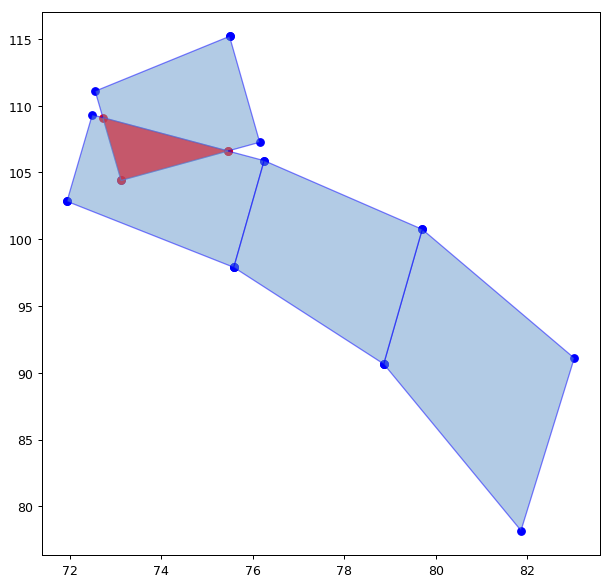

Successful overlap:
['S1A_EW_GRDH_1SDH_20141003T234105_20141003T234157_002672_002FA5_D6D8.zip']
with
['S1A_EW_GRDH_1SDH_20141005T100607_20141005T100711_002693_003022_1BD4.zip', 'S1A_EW_GRDH_1SDH_20141005T100711_20141005T100811_002693_003022_63A6.zip', 'S1A_EW_GRDH_1SDH_20141005T100811_20141005T100911_002693_003022_3A8A.zip']

Time difference is  1 day, 10:25:02
2014-10-03T234105 2014-10-05T100607
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141003T234105_20141003T234157_002672_002FA5_D6D8.zip
False True
no HV data found
2014-10-04 02:56:24 2014-10-04 04:35:09
area of intersection 0.0
cond_area False


2014-10-04 02:56:24 2014-10-04 09:27:30
area of intersection 2.24732359578
cond_area True
Images overlap


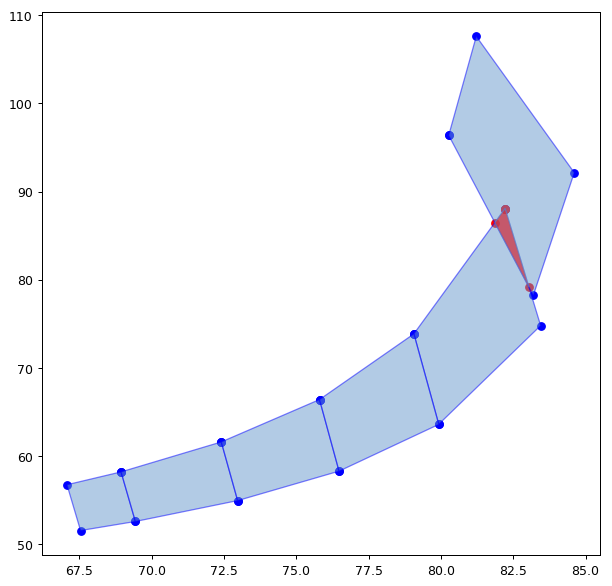

Successful overlap:
['S1A_EW_GRDH_1SDH_20141004T025624_20141004T025729_002674_002FB4_F3E8.zip', 'S1A_EW_GRDH_1SDH_20141004T025729_20141004T025829_002674_002FB4_620A.zip', 'S1A_EW_GRDH_1SDH_20141004T025829_20141004T025929_002674_002FB4_FFFD.zip', 'S1A_EW_GRDH_1SDH_20141004T025929_20141004T030029_002674_002FB4_6028.zip', 'S1A_EW_GRDH_1SDH_20141004T030029_20141004T030101_002674_002FB4_6D3B.zip']
with
['S1A_EW_GRDH_1SSH_20141004T092730_20141004T092834_002678_002FD0_9CFB.zip']

Time difference is  6:31:06
2014-10-04T025624 2014-10-04T092730
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141004T025624_20141004T025729_002674_002FB4_F3E8.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141004T025729_20141004T025829_002674_002FB4_620A.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141004T025829_20141004T025929_002674_002FB4_FFFD.zip
False True
/home/cercache/user

2014-10-04 04:35:09 2014-10-04 11:04:10
area of intersection 1.44379453374
cond_area True
Images overlap


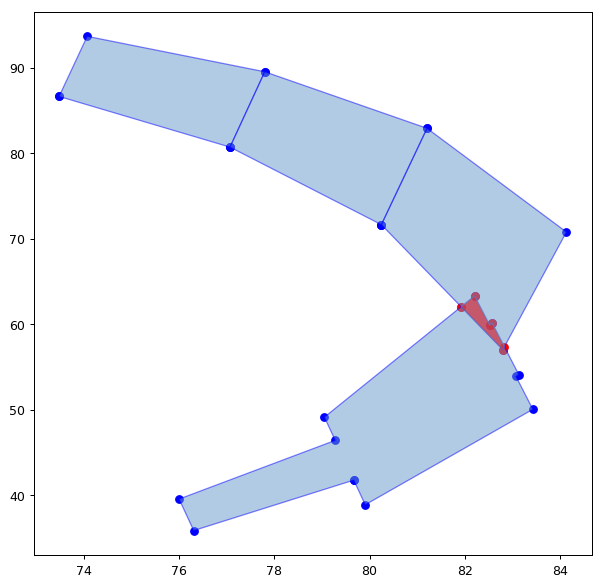

Successful overlap:
['S1A_EW_GRDM_1SDH_20141004T043509_20141004T043613_002675_002FB9_4AD8.zip', 'S1A_EW_GRDH_1SDH_20141004T043509_20141004T043613_002675_002FB9_51B6.zip', 'S1A_EW_GRDM_1SDH_20141004T043613_20141004T043713_002675_002FB9_3C69.zip']
with
['S1A_EW_GRDH_1SDH_20141004T110410_20141004T110514_002679_002FD4_35E5.zip', 'S1A_EW_GRDH_1SDH_20141004T110514_20141004T110614_002679_002FD4_721A.zip', 'S1A_EW_GRDH_1SDH_20141004T110614_20141004T110709_002679_002FD4_4920.zip']

Time difference is  6:29:01
2014-10-04T043509 2014-10-04T110410
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141004T043509_20141004T043613_002675_002FB9_4AD8.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141004T043509_20141004T043613_002675_002FB9_51B6.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141004T043613_20141004T043713_002675_002FB9_3C69.zip
False True
no HV data found
20

2014-10-04 09:27:30 2014-10-04 12:45:03
area of intersection 0.0
cond_area False
2014-10-04 09:27:30 2014-10-05 01:58:49
area of intersection 25.3331840268
cond_area True
Images overlap


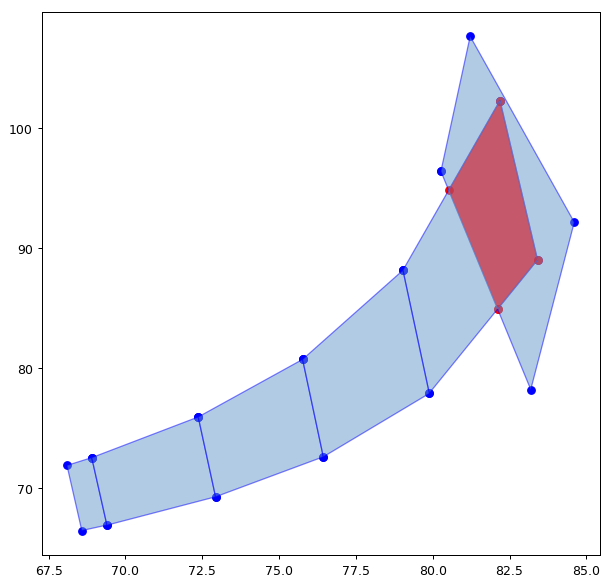

Successful overlap:
['S1A_EW_GRDH_1SSH_20141004T092730_20141004T092834_002678_002FD0_9CFB.zip']
with
['S1A_EW_GRDH_1SDH_20141005T015849_20141005T015953_002688_003004_287A.zip', 'S1A_EW_GRDH_1SDH_20141005T015953_20141005T020053_002688_003004_E498.zip', 'S1A_EW_GRDH_1SDH_20141005T020053_20141005T020153_002688_003004_7F04.zip', 'S1A_EW_GRDH_1SDH_20141005T020153_20141005T020253_002688_003004_6547.zip', 'S1A_EW_GRDH_1SDH_20141005T020253_20141005T020307_002688_003004_1165.zip']

Time difference is  16:31:19
2014-10-04T092730 2014-10-05T015849
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SSH_20141004T092730_20141004T092834_002678_002FD0_9CFB.zip
False True
no HV data found
2014-10-04 11:04:10 2014-10-04 12:45:03
area of intersection 0.0
cond_area False


2014-10-04 11:04:10 2014-10-05 01:58:49
area of intersection 29.8212718516
cond_area True
Images overlap


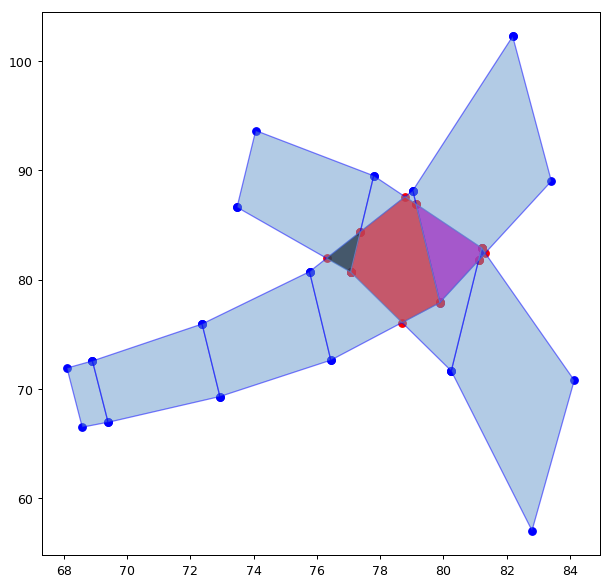

Successful overlap:
['S1A_EW_GRDH_1SDH_20141004T110410_20141004T110514_002679_002FD4_35E5.zip', 'S1A_EW_GRDH_1SDH_20141004T110514_20141004T110614_002679_002FD4_721A.zip', 'S1A_EW_GRDH_1SDH_20141004T110614_20141004T110709_002679_002FD4_4920.zip']
with
['S1A_EW_GRDH_1SDH_20141005T015849_20141005T015953_002688_003004_287A.zip', 'S1A_EW_GRDH_1SDH_20141005T015953_20141005T020053_002688_003004_E498.zip', 'S1A_EW_GRDH_1SDH_20141005T020053_20141005T020153_002688_003004_7F04.zip', 'S1A_EW_GRDH_1SDH_20141005T020153_20141005T020253_002688_003004_6547.zip', 'S1A_EW_GRDH_1SDH_20141005T020253_20141005T020307_002688_003004_1165.zip']

Time difference is  14:54:39
2014-10-04T110410 2014-10-05T015849
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141004T110410_20141004T110514_002679_002FD4_35E5.zip
76.3062442218 80.6934890747 77.3701033491 84.3643345844
73.143 77.1433 77.976 96.2063
81.1097296099 81.7553189012 81.3207469904 82.8929748535
73.143 77.1433 77.976 9

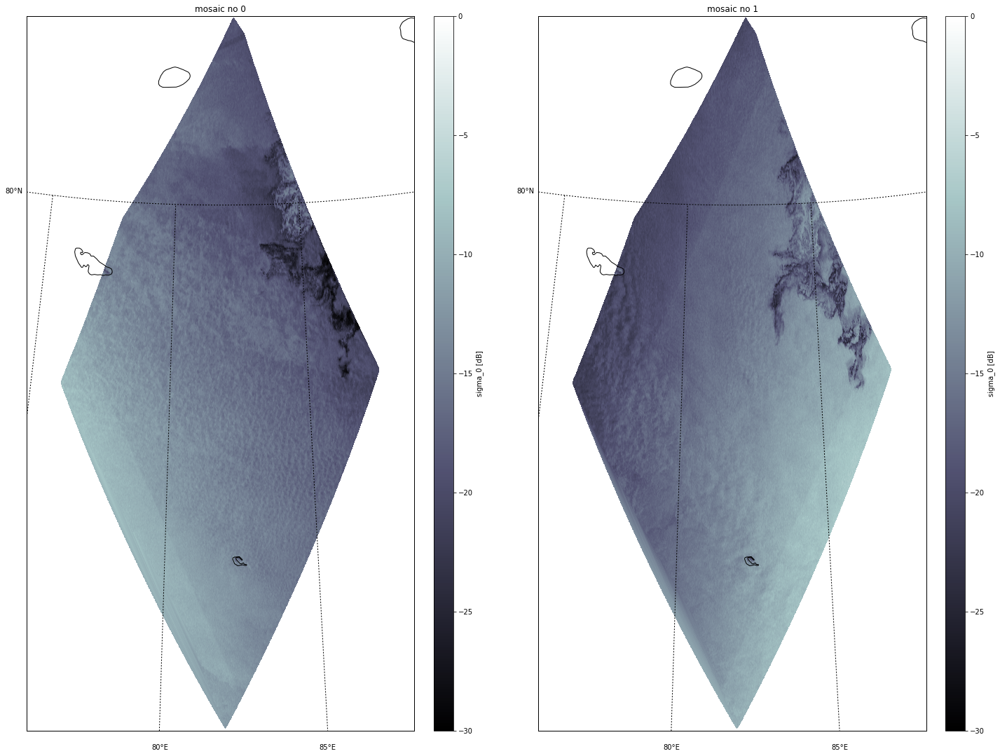

Kara_2014-10-04T110410_2014-10-05T015849_lat-3_lon-2_hh.pickle is created
2014-10-04 12:45:03 2014-10-05 01:58:49
area of intersection 0.0
cond_area False
2014-10-04 12:45:03 2014-10-05 03:37:24
area of intersection 0.0565986053052
cond_area False
2014-10-04 12:45:03 2014-10-05 05:16:13
area of intersection 30.5629924546
cond_area True
Images overlap


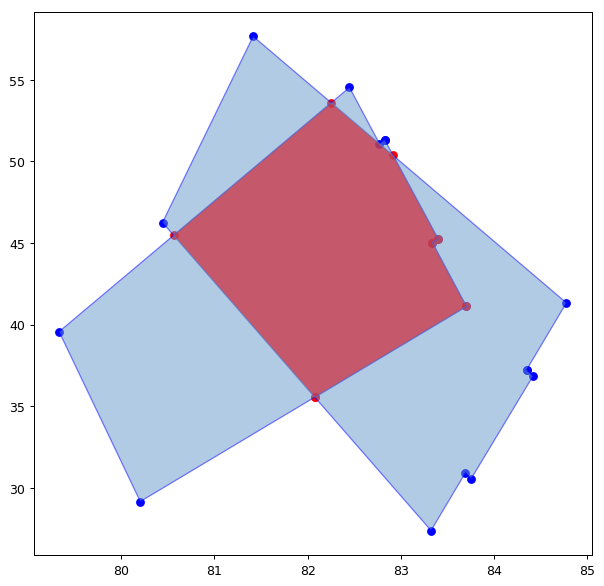

Successful overlap:
['S1A_EW_GRDM_1SSH_20141004T124503_20141004T124607_002680_002FDB_57E9.zip', 'S1A_EW_GRDH_1SSH_20141004T124503_20141004T124607_002680_002FDB_8740.zip']
with
['S1A_EW_GRDH_1SDH_20141005T051613_20141005T051717_002690_003011_5F5A.zip', 'S1A_EW_GRDM_1SDH_20141005T051613_20141005T051717_002690_003011_E390.zip']

Time difference is  16:31:10
2014-10-04T124503 2014-10-05T051613
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SSH_20141004T124503_20141004T124607_002680_002FDB_57E9.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SSH_20141004T124503_20141004T124607_002680_002FDB_8740.zip
False True
no HV data found
2014-10-05 01:58:49 2014-10-05 03:37:24
area of intersection 0.0
cond_area False


2014-10-05 01:58:49 2014-10-05 05:16:13
area of intersection 0.0
cond_area False
2014-10-05 01:58:49 2014-10-05 10:06:07
area of intersection 31.7526860207
cond_area True
Images overlap


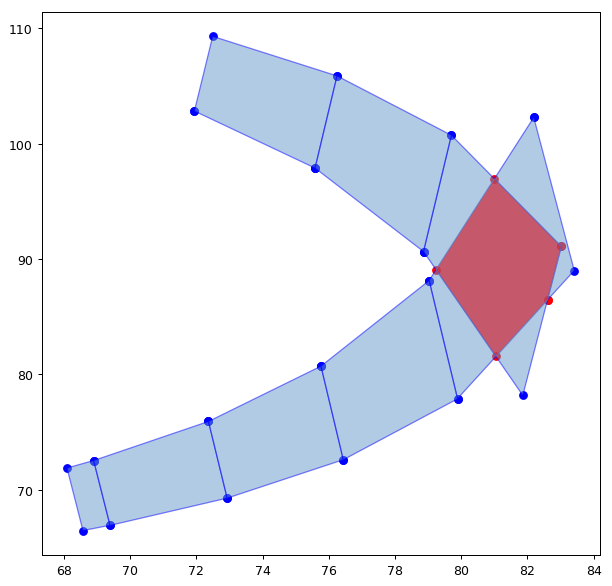

Successful overlap:
['S1A_EW_GRDH_1SDH_20141005T015849_20141005T015953_002688_003004_287A.zip', 'S1A_EW_GRDH_1SDH_20141005T015953_20141005T020053_002688_003004_E498.zip', 'S1A_EW_GRDH_1SDH_20141005T020053_20141005T020153_002688_003004_7F04.zip', 'S1A_EW_GRDH_1SDH_20141005T020153_20141005T020253_002688_003004_6547.zip', 'S1A_EW_GRDH_1SDH_20141005T020253_20141005T020307_002688_003004_1165.zip']
with
['S1A_EW_GRDH_1SDH_20141005T100607_20141005T100711_002693_003022_1BD4.zip', 'S1A_EW_GRDH_1SDH_20141005T100711_20141005T100811_002693_003022_63A6.zip', 'S1A_EW_GRDH_1SDH_20141005T100811_20141005T100911_002693_003022_3A8A.zip']

Time difference is  8:07:18
2014-10-05T015849 2014-10-05T100607
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141005T015849_20141005T015953_002688_003004_287A.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141005T015953_20141005T020053_002688_003004_E498.zip
False True
/home/cercac

2014-10-05 03:37:24 2014-10-05 10:06:07
area of intersection 0.0
cond_area False
2014-10-05 03:37:24 2014-10-05 13:22:33
area of intersection 0.0
cond_area False
2014-10-05 03:37:24 2014-10-06 01:01:17
area of intersection 0.0
cond_area False
2014-10-05 03:37:24 2014-10-06 04:18:43
area of intersection 9.31334034877
cond_area True
Images overlap


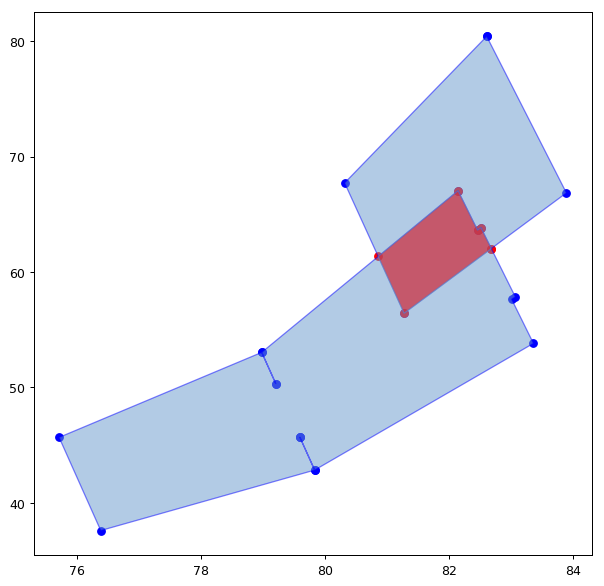

Successful overlap:
['S1A_EW_GRDH_1SSH_20141005T033724_20141005T033813_002689_00300A_DE4A.zip']
with
['S1A_EW_GRDH_1SDH_20141006T041843_20141006T041947_002704_00305E_27A3.zip', 'S1A_EW_GRDM_1SDH_20141006T041843_20141006T041947_002704_00305E_8AE2.zip', 'S1A_EW_GRDH_1SDH_20141006T041947_20141006T042047_002704_00305E_C9D4.zip', 'S1A_EW_GRDM_1SDH_20141006T041947_20141006T042047_002704_00305E_F8F8.zip']

Time difference is  1 day, 0:41:19
2014-10-05T033724 2014-10-06T041843
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SSH_20141005T033724_20141005T033813_002689_00300A_DE4A.zip
False True
no HV data found
2014-10-05 05:16:13 2014-10-05 10:06:07
area of intersection 0.0
cond_area False


2014-10-05 05:16:13 2014-10-05 13:22:33
area of intersection 30.8526545221
cond_area True
Images overlap


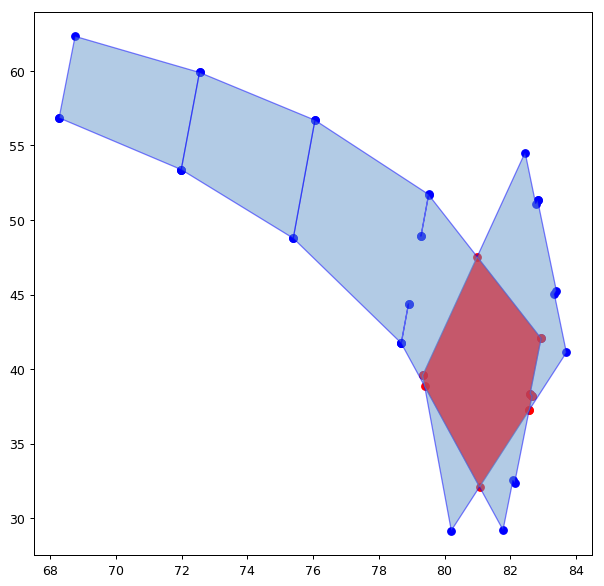

Successful overlap:
['S1A_EW_GRDH_1SDH_20141005T051613_20141005T051717_002690_003011_5F5A.zip', 'S1A_EW_GRDM_1SDH_20141005T051613_20141005T051717_002690_003011_E390.zip']
with
['S1A_EW_GRDH_1SDH_20141005T132233_20141005T132337_002695_00302C_7DE1.zip', 'S1A_EW_GRDH_1SDH_20141005T132337_20141005T132437_002695_00302C_26AE.zip', 'S1A_EW_GRDM_1SDH_20141005T132437_20141005T132537_002695_00302C_958A.zip', 'S1A_EW_GRDH_1SDH_20141005T132437_20141005T132537_002695_00302C_B47B.zip', 'S1A_EW_GRDH_1SDH_20141005T132537_20141005T132639_002695_00302C_7DD1.zip', 'S1A_EW_GRDM_1SDH_20141005T132537_20141005T132639_002695_00302C_D158.zip']

Time difference is  8:06:20
2014-10-05T051613 2014-10-05T132233
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141005T051613_20141005T051717_002690_003011_5F5A.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141005T051613_20141005T051717_002690_003011_E390.zip
False True
no HV data f

2014-10-05 10:06:07 2014-10-06 01:01:17
area of intersection 29.6124757451
cond_area True
Images overlap


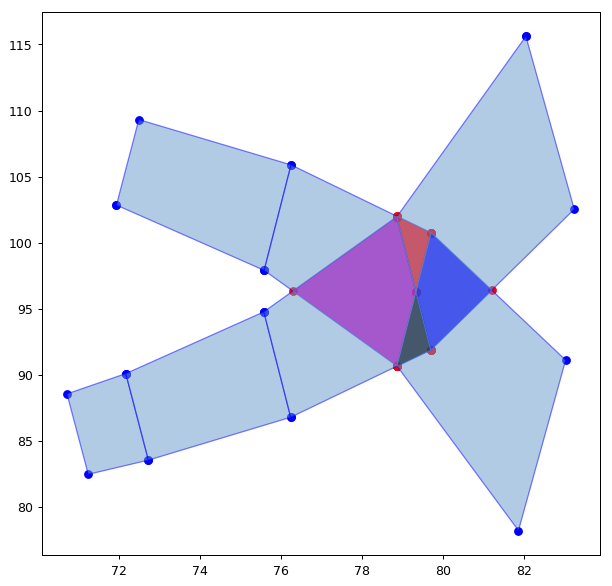

Successful overlap:
['S1A_EW_GRDH_1SDH_20141005T100607_20141005T100711_002693_003022_1BD4.zip', 'S1A_EW_GRDH_1SDH_20141005T100711_20141005T100811_002693_003022_63A6.zip', 'S1A_EW_GRDH_1SDH_20141005T100811_20141005T100911_002693_003022_3A8A.zip']
with
['S1A_EW_GRDH_1SDH_20141006T010117_20141006T010221_002702_00304E_C2A9.zip', 'S1A_EW_GRDH_1SDH_20141006T010221_20141006T010321_002702_00304E_9D1D.zip', 'S1A_EW_GRDH_1SDH_20141006T010321_20141006T010421_002702_00304E_BCF6.zip', 'S1A_EW_GRDH_1SDH_20141006T010421_20141006T010446_002702_00304E_C587.zip']

Time difference is  14:55:10
2014-10-05T100607 2014-10-06T010117
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141005T100607_20141005T100711_002693_003022_1BD4.zip
78.8613052368 90.6394860753 79.6968536377 96.2701876809
71.6363 94.6204 76.4128 111.657
79.329878421 91.8656234741 81.1994593186 100.738960266
71.6363 94.6204 76.4128 111.657
78.8571472168 96.2730643144 79.7026672363 101.98475217
71.6363 94

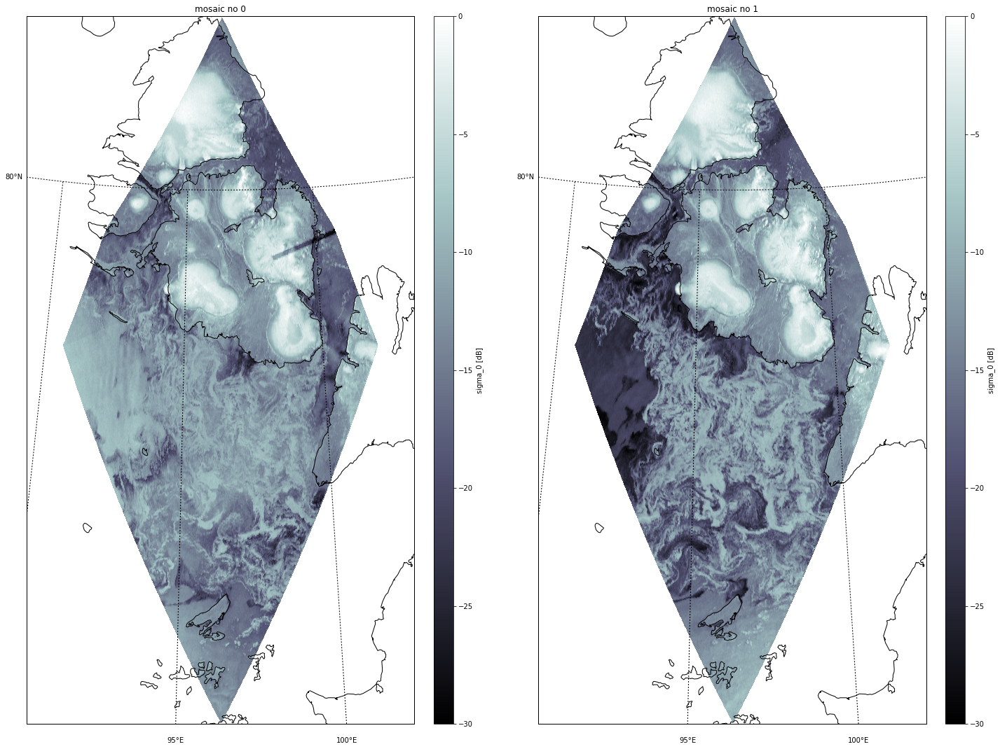

Kara_2014-10-05T100607_2014-10-06T010117_lat-3_lon-2_hh.pickle is created
2014-10-05 13:22:33 2014-10-06 01:01:17
area of intersection 0.0
cond_area False
2014-10-05 13:22:33 2014-10-06 04:18:43
area of intersection 29.6702430076
cond_area True
Images overlap


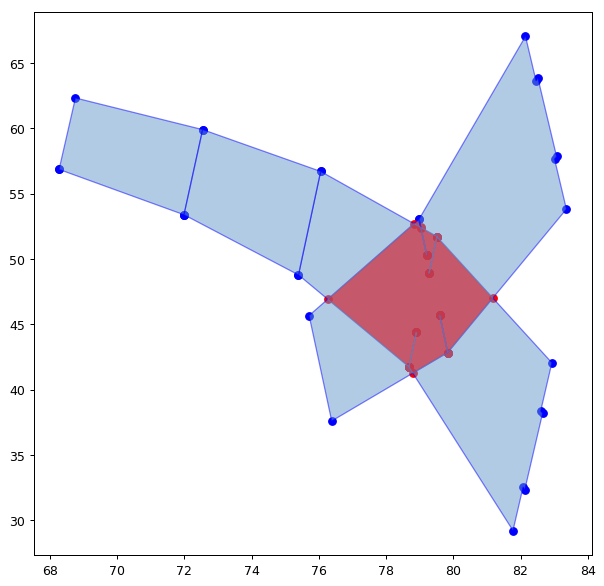

Successful overlap:
['S1A_EW_GRDH_1SDH_20141005T132233_20141005T132337_002695_00302C_7DE1.zip', 'S1A_EW_GRDH_1SDH_20141005T132337_20141005T132437_002695_00302C_26AE.zip', 'S1A_EW_GRDM_1SDH_20141005T132437_20141005T132537_002695_00302C_958A.zip', 'S1A_EW_GRDH_1SDH_20141005T132437_20141005T132537_002695_00302C_B47B.zip', 'S1A_EW_GRDH_1SDH_20141005T132537_20141005T132639_002695_00302C_7DD1.zip', 'S1A_EW_GRDM_1SDH_20141005T132537_20141005T132639_002695_00302C_D158.zip']
with
['S1A_EW_GRDH_1SDH_20141006T041843_20141006T041947_002704_00305E_27A3.zip', 'S1A_EW_GRDM_1SDH_20141006T041843_20141006T041947_002704_00305E_8AE2.zip', 'S1A_EW_GRDH_1SDH_20141006T041947_20141006T042047_002704_00305E_C9D4.zip', 'S1A_EW_GRDM_1SDH_20141006T041947_20141006T042047_002704_00305E_F8F8.zip']

Time difference is  14:56:10
2014-10-05T132233 2014-10-06T041843
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141005T132233_20141005T132337_002695_00302C_7DE1.zip
False True
/hom

2014-10-06 01:01:17 2014-10-06 09:10:05
area of intersection 32.6034370478
cond_area True
Images overlap


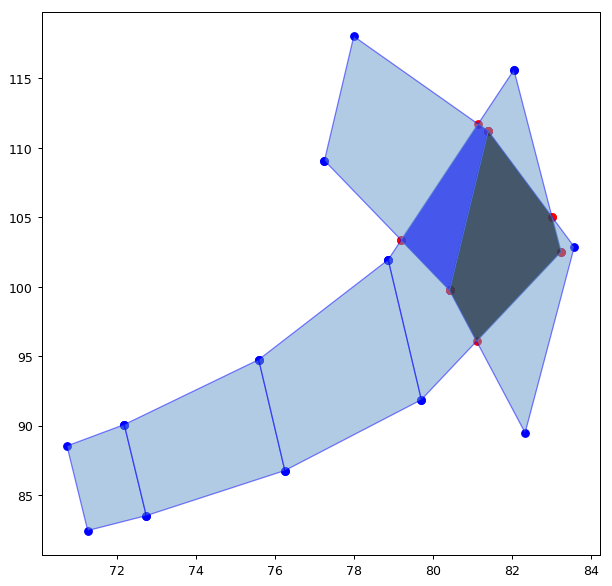

Successful overlap:
['S1A_EW_GRDH_1SDH_20141006T010117_20141006T010221_002702_00304E_C2A9.zip', 'S1A_EW_GRDH_1SDH_20141006T010221_20141006T010321_002702_00304E_9D1D.zip', 'S1A_EW_GRDH_1SDH_20141006T010321_20141006T010421_002702_00304E_BCF6.zip', 'S1A_EW_GRDH_1SDH_20141006T010421_20141006T010446_002702_00304E_C587.zip']
with
['S1A_EW_GRDH_1SDH_20141006T091005_20141006T091105_002707_003072_A82F.zip', 'S1A_EW_GRDH_1SDH_20141006T091105_20141006T091146_002707_003072_F6D4.zip']

Time difference is  8:08:48
2014-10-06T010117 2014-10-06T091005
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141006T010117_20141006T010221_002702_00304E_C2A9.zip
80.4120254517 96.0800328418 83.2347869873 111.205024719
78.3939 88.0047 83.5472 120.139
79.187595738 99.7531280518 81.3903503418 111.719167769
78.3939 88.0047 83.5472 120.139
False False
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141006T010221_20141006T010321_002702_00304E_9D1D.z

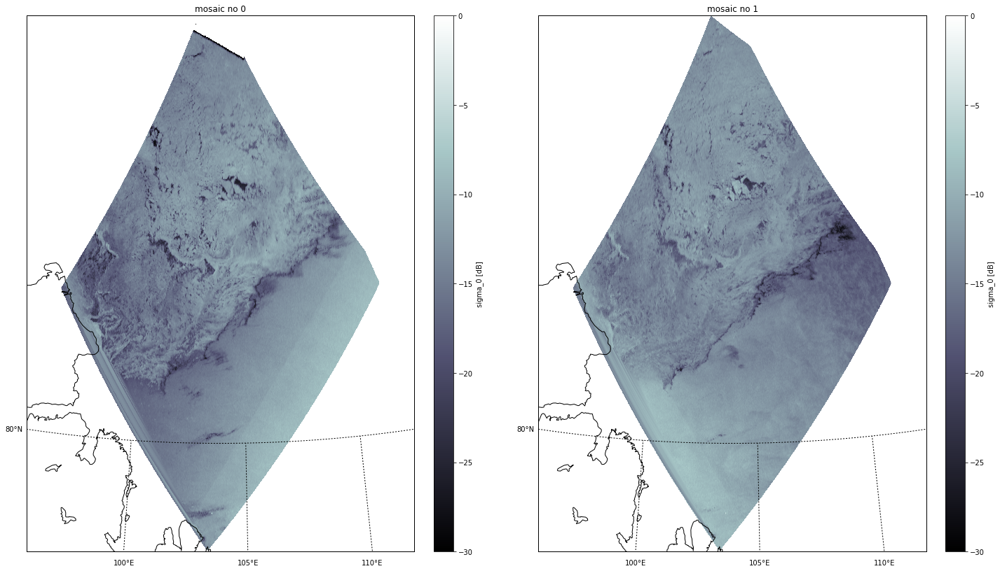

Kara_2014-10-06T010117_2014-10-06T091005_lat-3_lon-2_hh.pickle is created
2014-10-06 04:18:43 2014-10-06 09:10:05
area of intersection 0.0
cond_area False
2014-10-06 04:18:43 2014-10-07 00:03:41
area of intersection 0.0
cond_area False
2014-10-06 04:18:43 2014-10-07 03:21:08
area of intersection 2.86290098383
cond_area True
Images overlap


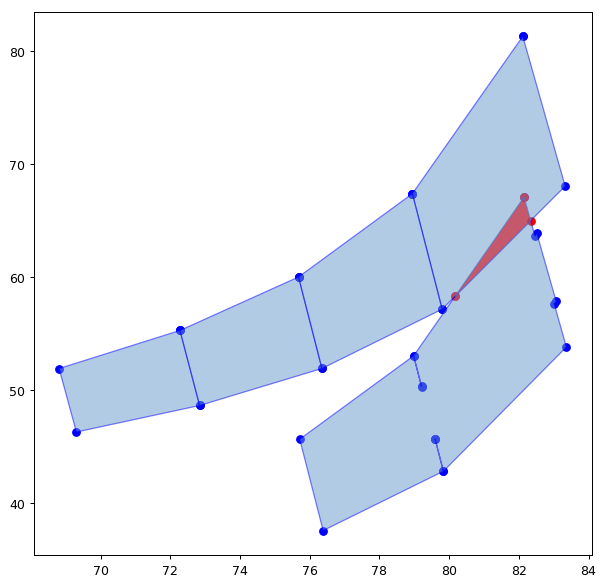

Successful overlap:
['S1A_EW_GRDH_1SDH_20141006T041843_20141006T041947_002704_00305E_27A3.zip', 'S1A_EW_GRDM_1SDH_20141006T041843_20141006T041947_002704_00305E_8AE2.zip', 'S1A_EW_GRDH_1SDH_20141006T041947_20141006T042047_002704_00305E_C9D4.zip', 'S1A_EW_GRDM_1SDH_20141006T041947_20141006T042047_002704_00305E_F8F8.zip']
with
['S1A_EW_GRDH_1SDH_20141007T032108_20141007T032212_002718_0030B8_99B4.zip', 'S1A_EW_GRDH_1SDH_20141007T032212_20141007T032312_002718_0030B8_1FF8.zip', 'S1A_EW_GRDH_1SDH_20141007T032312_20141007T032412_002718_0030B8_E3A8.zip', 'S1A_EW_GRDH_1SDH_20141007T032412_20141007T032512_002718_0030B8_2DEE.zip']

Time difference is  23:02:25
2014-10-06T041843 2014-10-07T032108
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141006T041843_20141006T041947_002704_00305E_27A3.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141006T041843_20141006T041947_002704_00305E_8AE2.zip
False True
/home/cerca

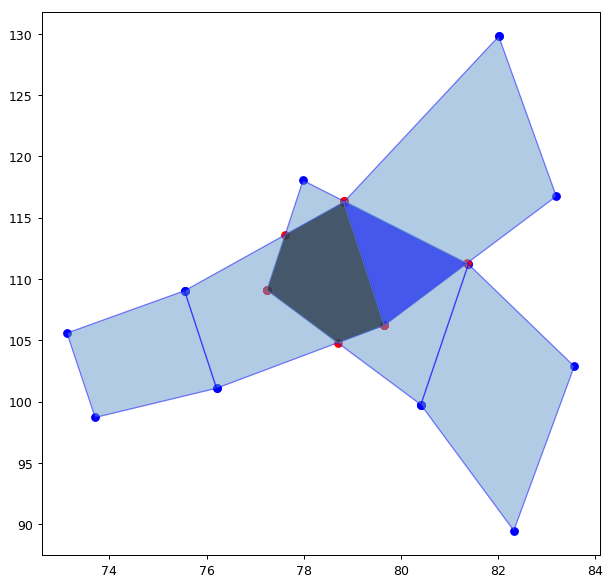

Successful overlap:
['S1A_EW_GRDH_1SDH_20141006T091005_20141006T091105_002707_003072_A82F.zip', 'S1A_EW_GRDH_1SDH_20141006T091105_20141006T091146_002707_003072_F6D4.zip']
with
['S1A_EW_GRDH_1SDH_20141007T000341_20141007T000445_002716_0030A8_40BA.zip', 'S1A_EW_GRDH_1SDH_20141007T000445_20141007T000545_002716_0030A8_E265.zip', 'S1A_EW_GRDH_1SDH_20141007T000545_20141007T000628_002716_0030A8_AD94.zip']

Time difference is  14:53:36
2014-10-06T091005 2014-10-07T000341
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141006T091005_20141006T091105_002707_003072_A82F.zip
77.2447433472 104.798186295 79.6593933105 116.25037384
76.8307 95.474 81.6372 121.387
78.8236083984 106.224830627 81.3575535677 116.320992444
76.8307 95.474 81.6372 121.387
False False
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141006T091105_20141006T091146_002707_003072_F6D4.zip
77.2447433472 104.798186295 79.6593933105 116.25037384
79.8783 84.9607 83

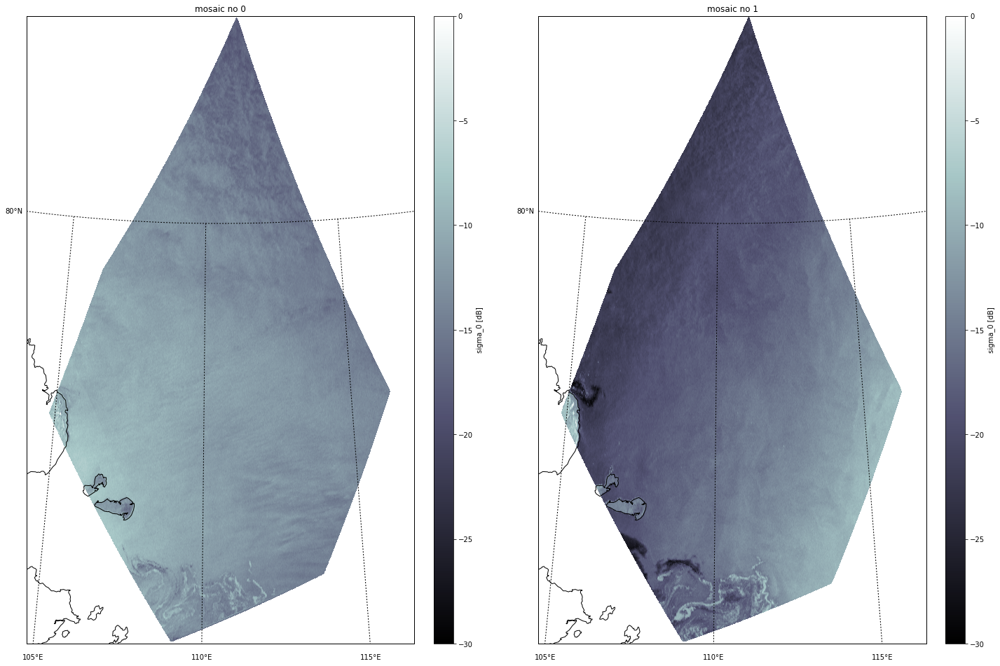

Kara_2014-10-06T091005_2014-10-07T000341_lat-3_lon-2_hh.pickle is created
2014-10-07 00:03:41 2014-10-07 03:21:08
area of intersection 0.0
cond_area False
2014-10-07 00:03:41 2014-10-08 00:44:33
area of intersection 16.7767269738
cond_area True
Images overlap


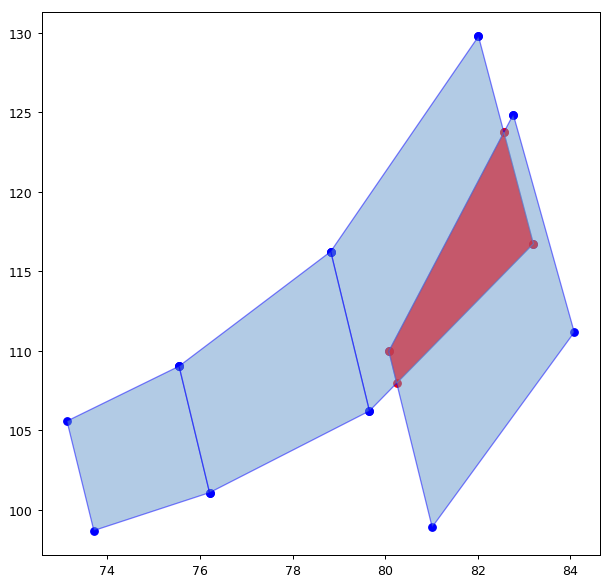

Successful overlap:
['S1A_EW_GRDH_1SDH_20141007T000341_20141007T000445_002716_0030A8_40BA.zip', 'S1A_EW_GRDH_1SDH_20141007T000445_20141007T000545_002716_0030A8_E265.zip', 'S1A_EW_GRDH_1SDH_20141007T000545_20141007T000628_002716_0030A8_AD94.zip']
with
['S1A_EW_GRDH_1SSH_20141008T004433_20141008T004530_002731_0030FD_C37B.zip']

Time difference is  1 day, 0:40:52
2014-10-07T000341 2014-10-08T004433
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141007T000341_20141007T000445_002716_0030A8_40BA.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141007T000445_20141007T000545_002716_0030A8_E265.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141007T000545_20141007T000628_002716_0030A8_AD94.zip
False True
no HV data found
2014-10-07 03:21:08 2014-10-08 00:44:33
area of intersection 0.0
cond_area False


2014-10-07 03:21:08 2014-10-08 02:23:29
area of intersection 2.80420129766
cond_area True
Images overlap


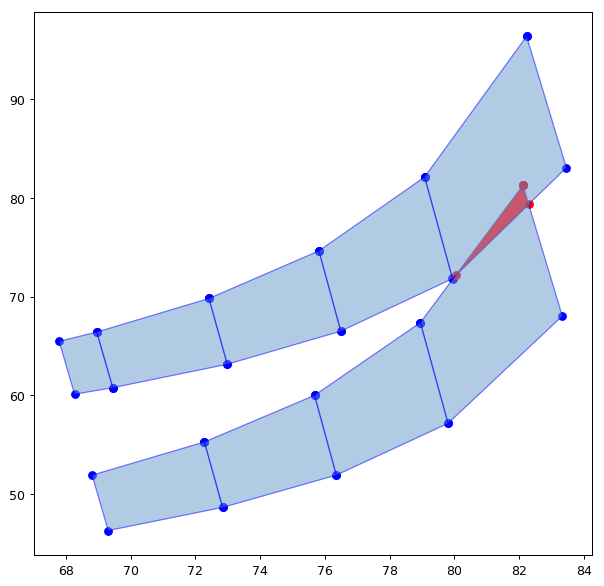

Successful overlap:
['S1A_EW_GRDH_1SDH_20141007T032108_20141007T032212_002718_0030B8_99B4.zip', 'S1A_EW_GRDH_1SDH_20141007T032212_20141007T032312_002718_0030B8_1FF8.zip', 'S1A_EW_GRDH_1SDH_20141007T032312_20141007T032412_002718_0030B8_E3A8.zip', 'S1A_EW_GRDH_1SDH_20141007T032412_20141007T032512_002718_0030B8_2DEE.zip']
with
['S1A_EW_GRDH_1SDH_20141008T022329_20141008T022433_002732_003104_020A.zip', 'S1A_EW_GRDH_1SDH_20141008T022433_20141008T022533_002732_003104_1DBC.zip', 'S1A_EW_GRDH_1SDH_20141008T022533_20141008T022633_002732_003104_7F31.zip', 'S1A_EW_GRDH_1SDH_20141008T022633_20141008T022733_002732_003104_87D3.zip', 'S1A_EW_GRDH_1SDH_20141008T022733_20141008T022753_002732_003104_B4AA.zip']

Time difference is  23:02:21
2014-10-07T032108 2014-10-08T022329
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141007T032108_20141007T032212_002718_0030B8_99B4.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20

2014-10-08 00:44:33 2014-10-08 04:01:49
area of intersection 0.0
cond_area False
2014-10-08 00:44:33 2014-10-08 10:31:12
area of intersection 0.0
cond_area False
2014-10-08 00:44:33 2014-10-08 13:47:04
area of intersection 0.0
cond_area False
2014-10-08 00:44:33 2014-10-09 01:25:57
area of intersection 9.21160145001
cond_area True
Images overlap


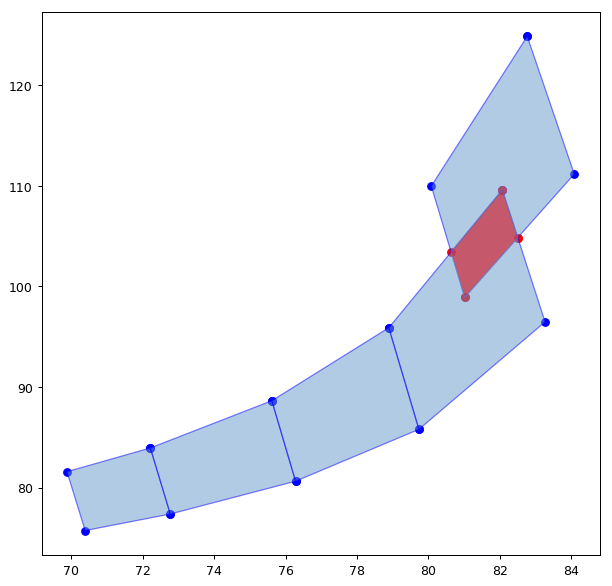

Successful overlap:
['S1A_EW_GRDH_1SSH_20141008T004433_20141008T004530_002731_0030FD_C37B.zip']
with
['S1A_EW_GRDH_1SDH_20141009T012557_20141009T012701_002746_003150_50FB.zip', 'S1A_EW_GRDH_1SDH_20141009T012701_20141009T012801_002746_003150_C647.zip', 'S1A_EW_GRDH_1SDH_20141009T012801_20141009T012901_002746_003150_F2FA.zip', 'S1A_EW_GRDH_1SDH_20141009T012901_20141009T012941_002746_003150_BE72.zip']

Time difference is  1 day, 0:41:24
2014-10-08T004433 2014-10-09T012557
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SSH_20141008T004433_20141008T004530_002731_0030FD_C37B.zip
False True
no HV data found
2014-10-08 02:23:29 2014-10-08 04:01:49
area of intersection 0.0
cond_area False


2014-10-08 02:23:29 2014-10-08 10:31:12
area of intersection 31.5171395553
cond_area True
Images overlap


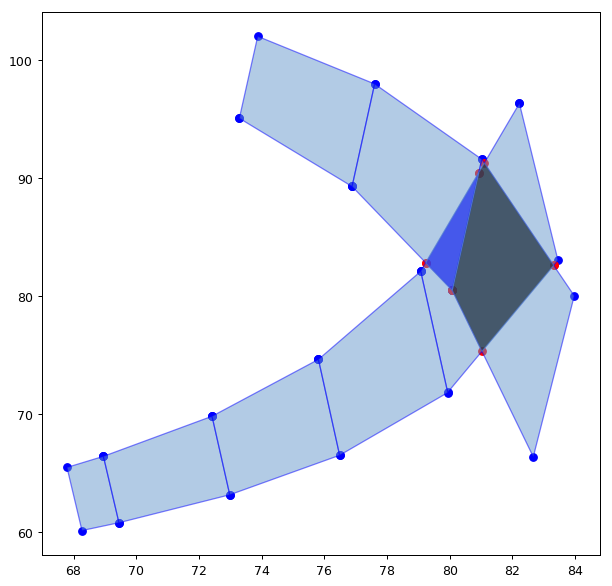

Successful overlap:
['S1A_EW_GRDH_1SDH_20141008T022329_20141008T022433_002732_003104_020A.zip', 'S1A_EW_GRDH_1SDH_20141008T022433_20141008T022533_002732_003104_1DBC.zip', 'S1A_EW_GRDH_1SDH_20141008T022533_20141008T022633_002732_003104_7F31.zip', 'S1A_EW_GRDH_1SDH_20141008T022633_20141008T022733_002732_003104_87D3.zip', 'S1A_EW_GRDH_1SDH_20141008T022733_20141008T022753_002732_003104_B4AA.zip']
with
['S1A_EW_GRDH_1SDH_20141008T103112_20141008T103216_002737_00311B_B563.zip', 'S1A_EW_GRDH_1SDH_20141008T103216_20141008T103316_002737_00311B_8BA0.zip', 'S1A_EW_GRDH_1SDH_20141008T103316_20141008T103411_002737_00311B_C81F.zip']

Time difference is  8:07:43
2014-10-08T022329 2014-10-08T103112
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141008T022329_20141008T022433_002732_003104_020A.zip
80.0822601318 75.3200224715 83.3179427084 91.2938736308
78.6037 67.856 83.781 100.887
79.2365233987 80.5037994385 80.9283388767 90.4851512619
78.6037 67.856 83.781 10

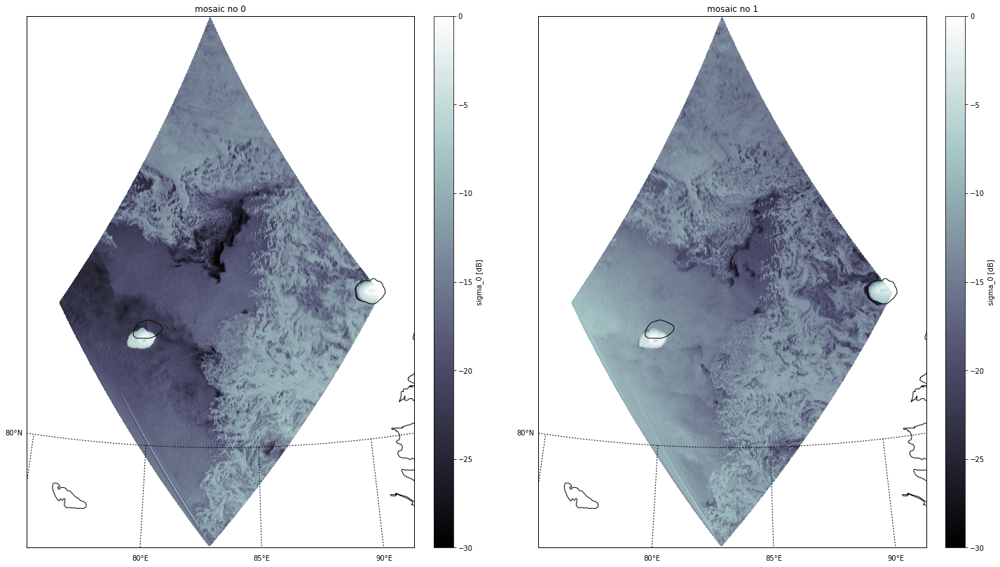

Kara_2014-10-08T022329_2014-10-08T103112_lat-3_lon-2_hh.pickle is created
2014-10-08 04:01:49 2014-10-08 10:31:12
area of intersection 10.7751895894
cond_area True
Images overlap


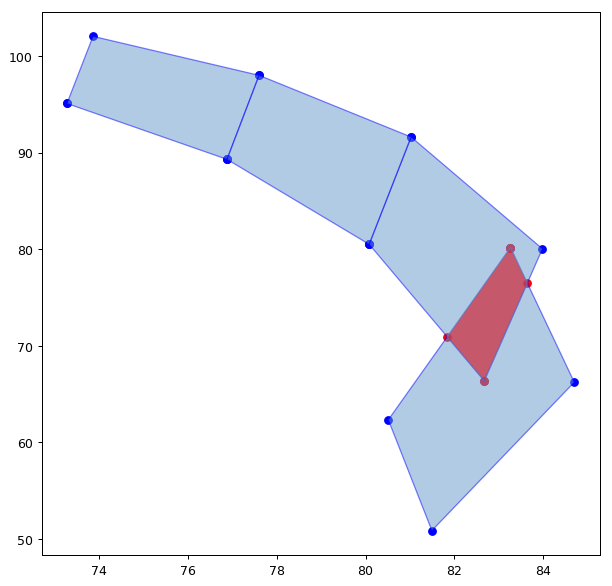

Successful overlap:
['S1A_EW_GRDH_1SSH_20141008T040149_20141008T040250_002733_00310A_B2DA.zip']
with
['S1A_EW_GRDH_1SDH_20141008T103112_20141008T103216_002737_00311B_B563.zip', 'S1A_EW_GRDH_1SDH_20141008T103216_20141008T103316_002737_00311B_8BA0.zip', 'S1A_EW_GRDH_1SDH_20141008T103316_20141008T103411_002737_00311B_C81F.zip']

Time difference is  6:29:23
2014-10-08T040149 2014-10-08T103112
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SSH_20141008T040149_20141008T040250_002733_00310A_B2DA.zip
False True
no HV data found
2014-10-08 10:31:12 2014-10-08 13:47:04
area of intersection 0.0
cond_area False


2014-10-08 10:31:12 2014-10-09 01:25:57
area of intersection 29.769987334
cond_area True
Images overlap


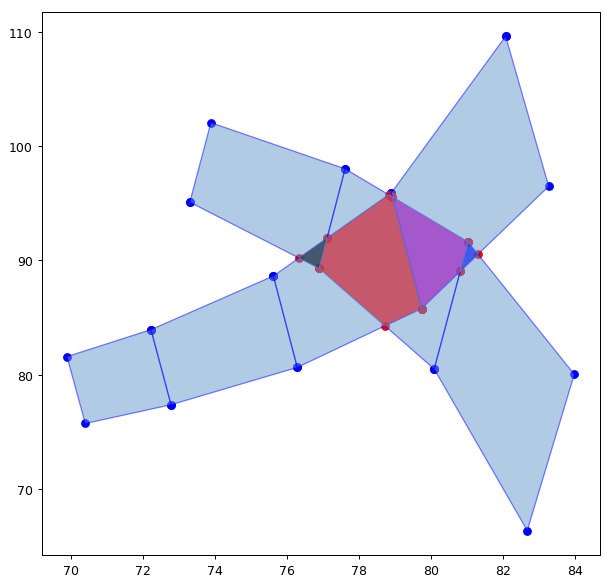

Successful overlap:
['S1A_EW_GRDH_1SDH_20141008T103112_20141008T103216_002737_00311B_B563.zip', 'S1A_EW_GRDH_1SDH_20141008T103216_20141008T103316_002737_00311B_8BA0.zip', 'S1A_EW_GRDH_1SDH_20141008T103316_20141008T103411_002737_00311B_C81F.zip']
with
['S1A_EW_GRDH_1SDH_20141009T012557_20141009T012701_002746_003150_50FB.zip', 'S1A_EW_GRDH_1SDH_20141009T012701_20141009T012801_002746_003150_C647.zip', 'S1A_EW_GRDH_1SDH_20141009T012801_20141009T012901_002746_003150_F2FA.zip', 'S1A_EW_GRDH_1SDH_20141009T012901_20141009T012941_002746_003150_BE72.zip']

Time difference is  14:54:45
2014-10-08T103112 2014-10-09T012557
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141008T103112_20141008T103216_002737_00311B_B563.zip
76.3242335993 89.3069000244 77.1050234897 91.9418772663
72.9631 85.7942 77.7839 104.579
80.8061479119 89.0411973552 81.3003181352 91.6179275513
72.9631 85.7942 77.7839 104.579
76.88697052 84.2727465239 79.7310714722 95.7406945427
72.9631 85

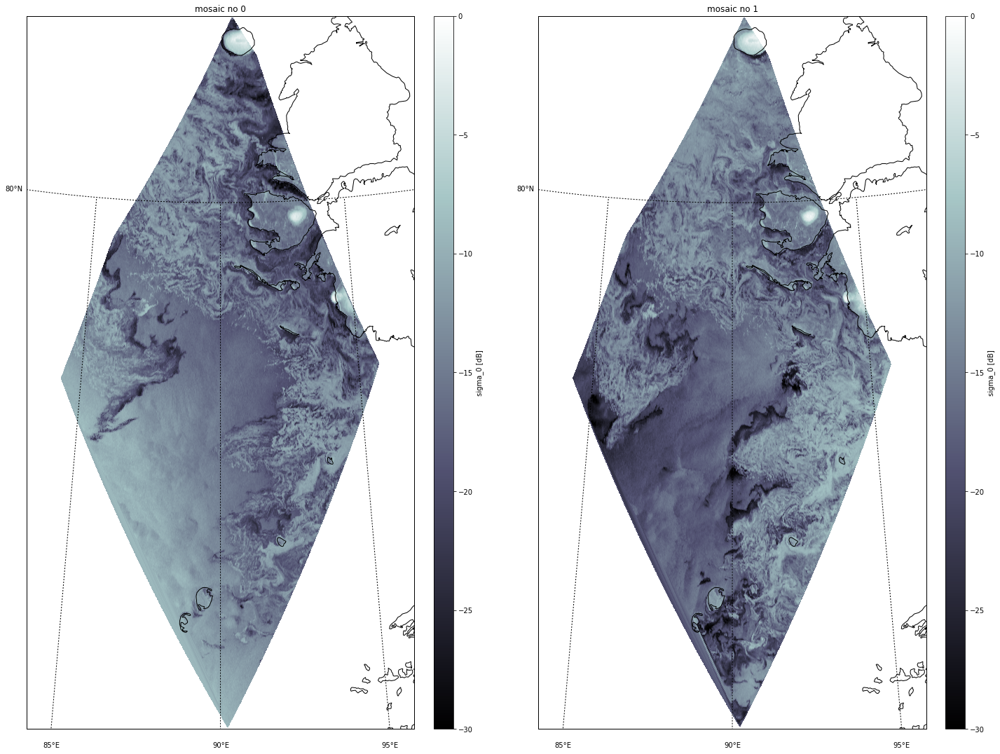

Kara_2014-10-08T103112_2014-10-09T012557_lat-3_lon-2_hh.pickle is created
2014-10-08 13:47:04 2014-10-09 01:25:57
area of intersection 0.0
cond_area False
2014-10-08 13:47:04 2014-10-09 04:43:20
area of intersection 0.0
cond_area False
2014-10-08 13:47:04 2014-10-09 09:34:01
area of intersection 0.0
cond_area False
2014-10-08 13:47:04 2014-10-09 11:14:38
area of intersection 0.0
cond_area False
2014-10-08 13:47:04 2014-10-10 00:28:21
area of intersection 0.0
cond_area False
2014-10-08 13:47:04 2014-10-10 03:45:48
area of intersection 27.77725678
cond_area True
Images overlap


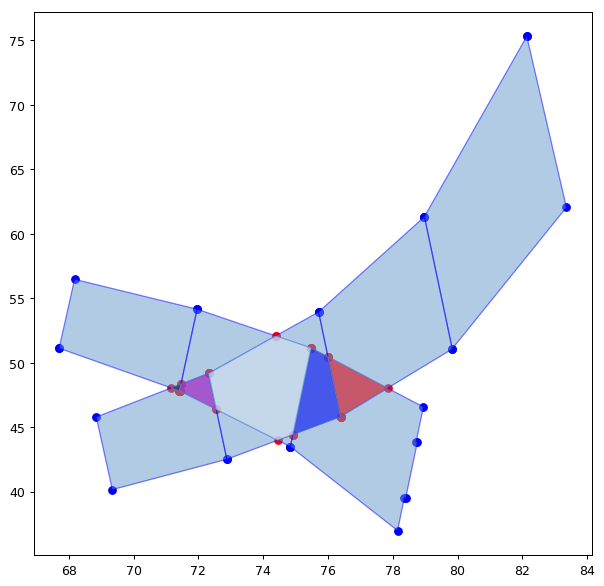

Successful overlap:
['S1A_EW_GRDH_1SDH_20141008T134704_20141008T134809_002739_003129_6176.zip', 'S1A_EW_GRDH_1SDH_20141008T134809_20141008T134909_002739_003129_4760.zip', 'S1A_EW_GRDH_1SDH_20141008T134909_20141008T135009_002739_003129_36BA.zip', 'S1A_EW_GRDM_1SDH_20141008T134909_20141008T135009_002739_003129_6937.zip']
with
['S1A_EW_GRDH_1SDH_20141010T034548_20141010T034652_002762_0031AB_6A59.zip', 'S1A_EW_GRDH_1SDH_20141010T034652_20141010T034752_002762_0031AB_F72B.zip', 'S1A_EW_GRDH_1SDH_20141010T034752_20141010T034852_002762_0031AB_B33A.zip', 'S1A_EW_GRDH_1SDH_20141010T034852_20141010T034952_002762_0031AB_93D9.zip']

Time difference is  1 day, 13:58:44
2014-10-08T134704 2014-10-10T034548
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141008T134704_20141008T134809_002739_003129_6176.zip
71.1600020343 47.8160018921 71.460230282 48.3361162357
67.4353 45.144 72.0937 58.3793
74.9140799645 44.428800219 76.3862686157 51.1481513977
67.4353 45.144 72

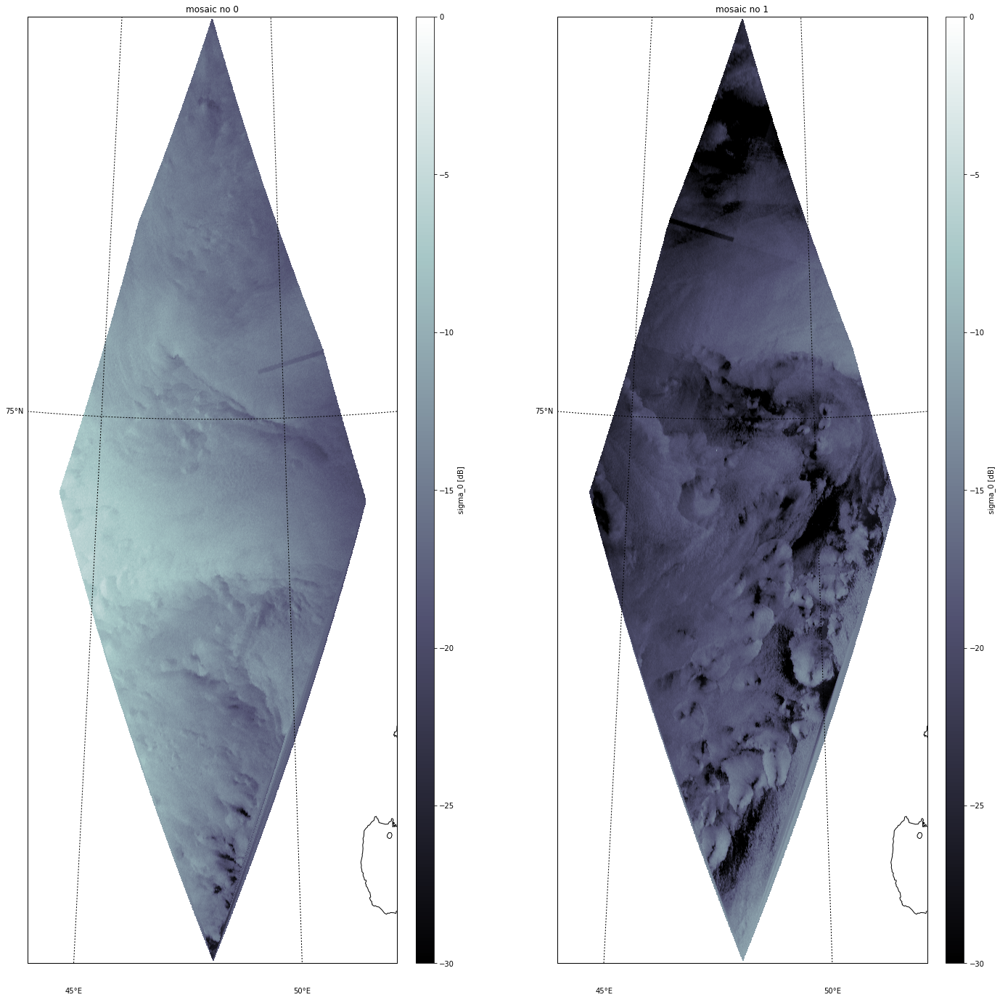

Kara_2014-10-08T134704_2014-10-10T034548_lat-3_lon-2_hh.pickle is created
2014-10-09 01:25:57 2014-10-09 04:43:20
area of intersection 0.0
cond_area False
2014-10-09 01:25:57 2014-10-09 09:34:01
area of intersection 33.3049688988
cond_area True
Images overlap


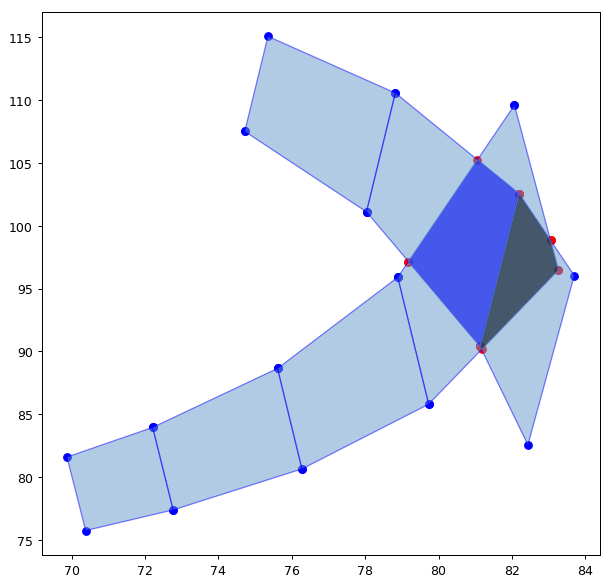

Successful overlap:
['S1A_EW_GRDH_1SDH_20141009T012557_20141009T012701_002746_003150_50FB.zip', 'S1A_EW_GRDH_1SDH_20141009T012701_20141009T012801_002746_003150_C647.zip', 'S1A_EW_GRDH_1SDH_20141009T012801_20141009T012901_002746_003150_F2FA.zip', 'S1A_EW_GRDH_1SDH_20141009T012901_20141009T012941_002746_003150_BE72.zip']
with
['S1A_EW_GRDH_1SDH_20141009T093401_20141009T093501_002751_00316B_BA29.zip', 'S1A_EW_GRDH_1SDH_20141009T093501_20141009T093601_002751_00316B_78F3.zip', 'S1A_EW_GRDH_1SDH_20141009T093601_20141009T093629_002751_00316B_D509.zip']

Time difference is  8:08:04
2014-10-09T012557 2014-10-09T093401
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141009T012557_20141009T012701_002746_003150_50FB.zip
81.1314926147 90.1484506241 83.2654418945 102.549858093
78.424 81.9194 83.5791 114.127
79.1796668312 90.3949737549 82.1913452148 105.246681727
78.424 81.9194 83.5791 114.127
False False
/home/cercache/users/atarasen/data/Sentinel-1_analysis/

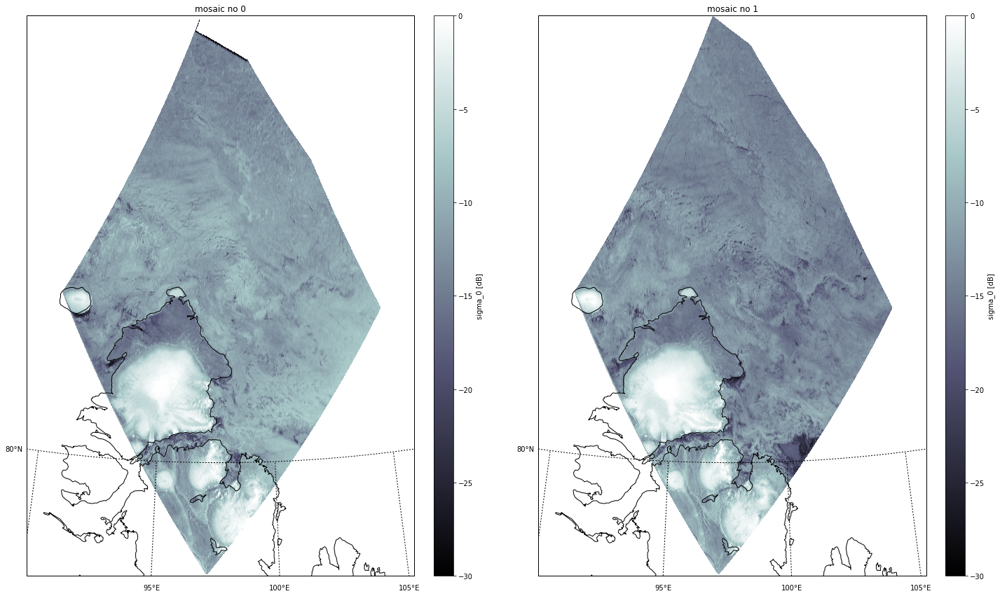

Kara_2014-10-09T012557_2014-10-09T093401_lat-3_lon-2_hh.pickle is created
2014-10-09 04:43:20 2014-10-09 09:34:01
area of intersection 0.0
cond_area False
2014-10-09 04:43:20 2014-10-09 11:14:38
area of intersection 5.95288066086
cond_area True
Images overlap


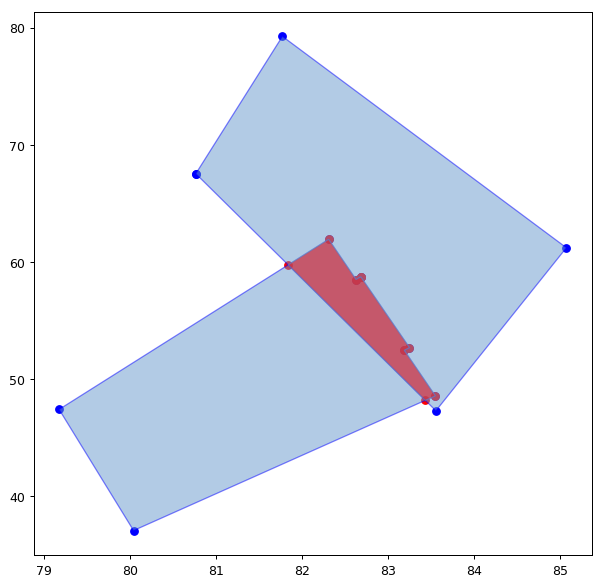

Successful overlap:
['S1A_EW_GRDM_1SDH_20141009T044320_20141009T044425_002748_00315C_5E9D.zip', 'S1A_EW_GRDH_1SDH_20141009T044320_20141009T044425_002748_00315C_63BF.zip']
with
['S1A_EW_GRDH_1SSH_20141009T111438_20141009T111542_002752_003172_F925.zip']

Time difference is  6:31:18
2014-10-09T044320 2014-10-09T111438
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141009T044320_20141009T044425_002748_00315C_5E9D.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141009T044320_20141009T044425_002748_00315C_63BF.zip
False True
no HV data found
2014-10-09 09:34:01 2014-10-09 11:14:38
area of intersection 0.0
cond_area False


2014-10-09 09:34:01 2014-10-10 00:28:21
area of intersection 29.0701363804
cond_area True
Images overlap


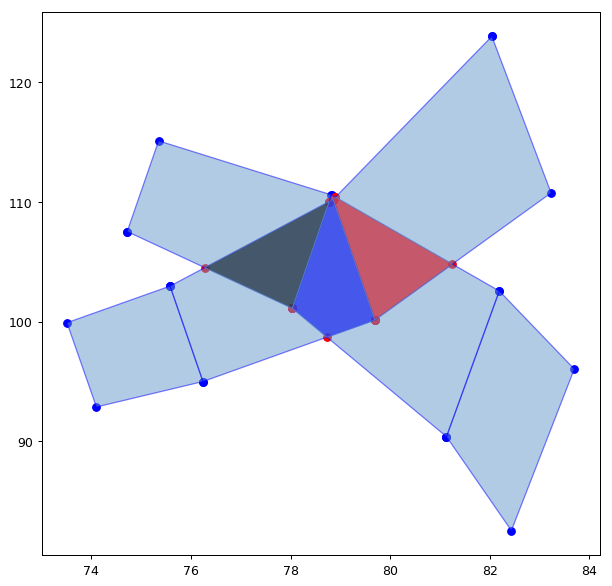

Successful overlap:
['S1A_EW_GRDH_1SDH_20141009T093401_20141009T093501_002751_00316B_BA29.zip', 'S1A_EW_GRDH_1SDH_20141009T093501_20141009T093601_002751_00316B_78F3.zip', 'S1A_EW_GRDH_1SDH_20141009T093601_20141009T093629_002751_00316B_D509.zip']
with
['S1A_EW_GRDH_1SDH_20141010T002821_20141010T002925_002760_00319C_52AA.zip', 'S1A_EW_GRDH_1SDH_20141010T002925_20141010T003025_002760_00319C_1950.zip', 'S1A_EW_GRDH_1SDH_20141010T003025_20141010T003102_002760_00319C_7121.zip']

Time difference is  14:54:20
2014-10-09T093401 2014-10-10T002821
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141009T093401_20141009T093501_002751_00316B_BA29.zip
76.2795210786 101.103988647 78.7758252269 110.003973612
74.3667 97.347 79.0174 117.853
78.0370101929 98.6976563911 79.6951141357 110.181945801
74.3667 97.347 79.0174 117.853
78.8567199707 100.130752563 81.2495870866 110.377561781
74.3667 97.347 79.0174 117.853
False False
/home/cercache/users/atarasen/data/Sentine

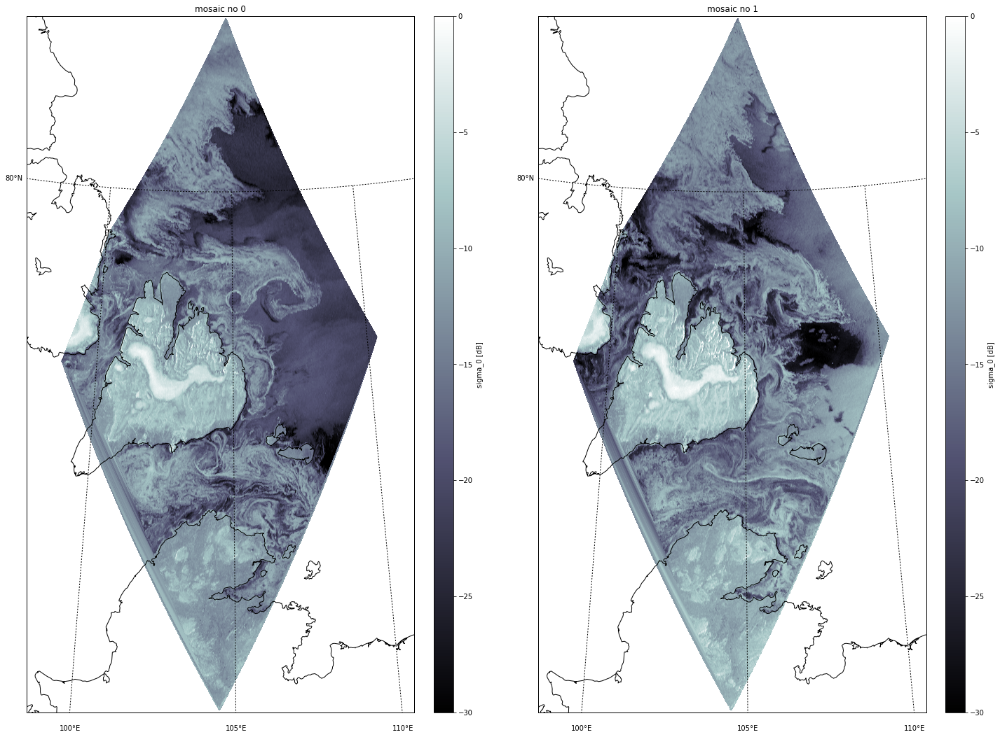

Kara_2014-10-09T093401_2014-10-10T002821_lat-3_lon-2_hh.pickle is created
2014-10-09 11:14:38 2014-10-10 00:28:21
area of intersection 0.0
cond_area False
2014-10-09 11:14:38 2014-10-10 03:45:48
area of intersection 23.5052291361
cond_area True
Images overlap


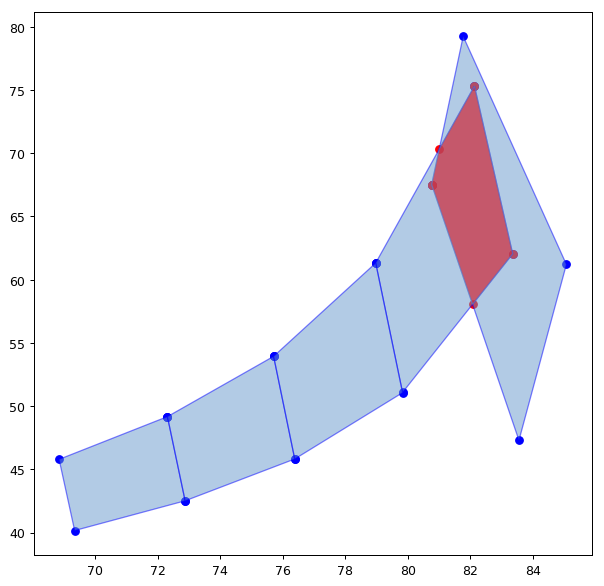

Successful overlap:
['S1A_EW_GRDH_1SSH_20141009T111438_20141009T111542_002752_003172_F925.zip']
with
['S1A_EW_GRDH_1SDH_20141010T034548_20141010T034652_002762_0031AB_6A59.zip', 'S1A_EW_GRDH_1SDH_20141010T034652_20141010T034752_002762_0031AB_F72B.zip', 'S1A_EW_GRDH_1SDH_20141010T034752_20141010T034852_002762_0031AB_B33A.zip', 'S1A_EW_GRDH_1SDH_20141010T034852_20141010T034952_002762_0031AB_93D9.zip']

Time difference is  16:31:10
2014-10-09T111438 2014-10-10T034548
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SSH_20141009T111438_20141009T111542_002752_003172_F925.zip
False True
no HV data found
2014-10-10 00:28:21 2014-10-10 03:45:48
area of intersection 0.0
cond_area False


2014-10-10 00:28:21 2014-10-10 08:37:13
area of intersection 32.6174978855
cond_area True
Images overlap


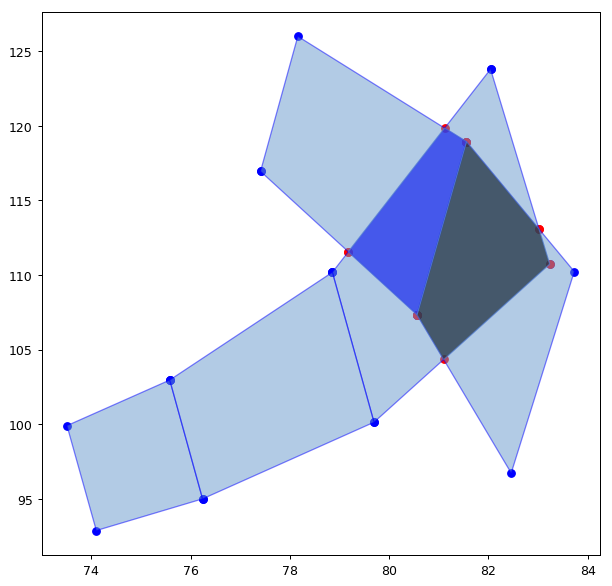

Successful overlap:
['S1A_EW_GRDH_1SDH_20141010T002821_20141010T002925_002760_00319C_52AA.zip', 'S1A_EW_GRDH_1SDH_20141010T002925_20141010T003025_002760_00319C_1950.zip', 'S1A_EW_GRDH_1SDH_20141010T003025_20141010T003102_002760_00319C_7121.zip']
with
['S1A_EW_GRDH_1SDH_20141010T083713_20141010T083813_002765_0031BE_8D86.zip', 'S1A_EW_GRDH_1SDH_20141010T083813_20141010T083854_002765_0031BE_416E.zip']

Time difference is  8:08:52
2014-10-10T002821 2014-10-10T083713
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141010T002821_20141010T002925_002760_00319C_52AA.zip
80.561920166 104.337622047 83.2315139771 118.935722351
78.3947 96.2806 83.5431 128.317
79.1784189109 107.340141296 81.5570373535 119.848982351
78.3947 96.2806 83.5431 128.317
False False
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141010T002925_20141010T003025_002760_00319C_1950.zip
80.561920166 104.337622047 83.2315139771 118.935722351
75.2122 92.0356 7

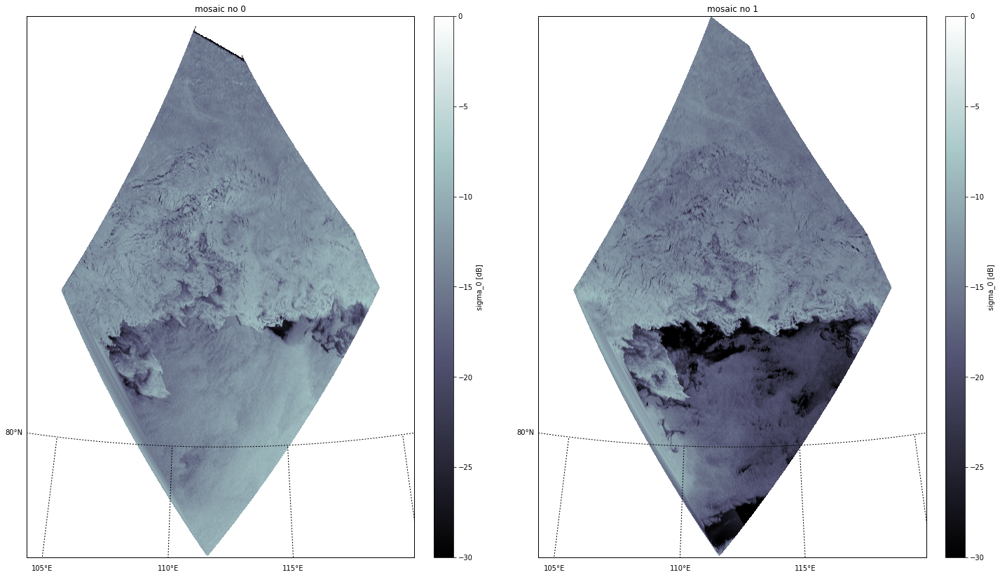

Kara_2014-10-10T002821_2014-10-10T083713_lat-3_lon-2_hh.pickle is created
2014-10-10 03:45:48 2014-10-10 08:37:13
area of intersection 0.0
cond_area False
2014-10-10 03:45:48 2014-10-10 11:52:54
area of intersection 33.4035359108
cond_area True
Images overlap


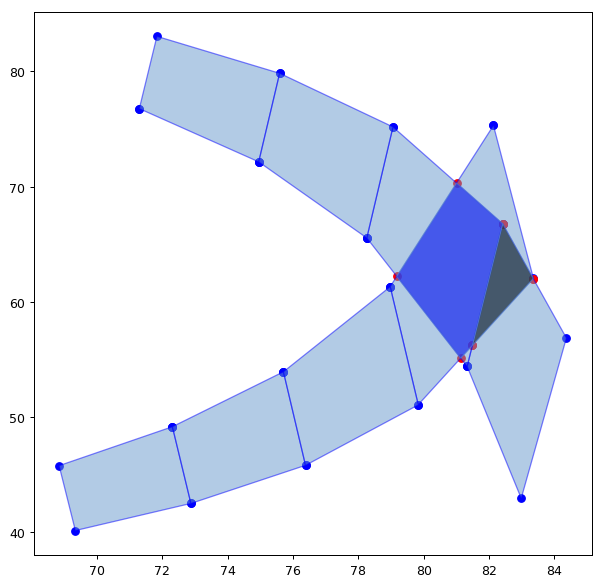

Successful overlap:
['S1A_EW_GRDH_1SDH_20141010T034548_20141010T034652_002762_0031AB_6A59.zip', 'S1A_EW_GRDH_1SDH_20141010T034652_20141010T034752_002762_0031AB_F72B.zip', 'S1A_EW_GRDH_1SDH_20141010T034752_20141010T034852_002762_0031AB_B33A.zip', 'S1A_EW_GRDH_1SDH_20141010T034852_20141010T034952_002762_0031AB_93D9.zip']
with
['S1A_EW_GRDH_1SDH_20141010T115254_20141010T115358_002767_0031C7_38E2.zip', 'S1A_EW_GRDH_1SDH_20141010T115358_20141010T115458_002767_0031C7_54C4.zip', 'S1A_EW_GRDH_1SDH_20141010T115458_20141010T115558_002767_0031C7_72CF.zip', 'S1A_EW_GRDH_1SDH_20141010T115558_20141010T115636_002767_0031C7_5FEF.zip']

Time difference is  8:07:06
2014-10-10T034548 2014-10-10T115254
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141010T034548_20141010T034652_002762_0031AB_6A59.zip
81.4924529243 56.2360824587 83.3537140621 66.7788085938
78.5035 47.1192 83.6828 79.8565
79.178921754 55.1198837635 82.4187316895 70.3148804308
78.5035 47.1192 83.6828

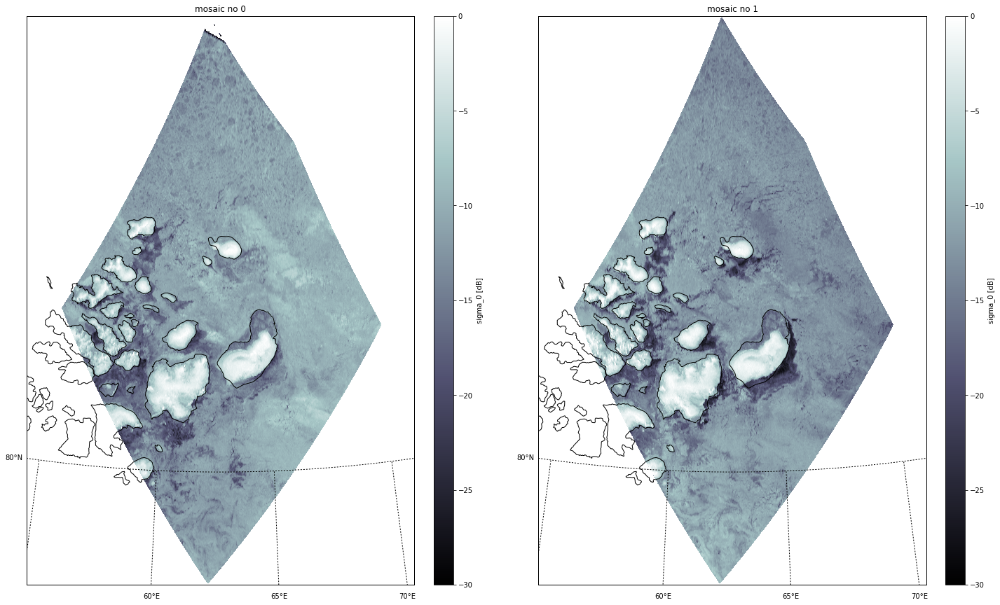

Kara_2014-10-10T034548_2014-10-10T115254_lat-3_lon-2_hh.pickle is created
2014-10-10 08:37:13 2014-10-10 11:52:54
area of intersection 0.0
cond_area False
2014-10-10 08:37:13 2014-10-10 13:33:19
area of intersection 0.0
cond_area False
2014-10-10 08:37:13 2014-10-12 05:07:58
area of intersection 0.0
cond_area False
2014-10-10 08:37:13 2014-10-12 09:58:54
area of intersection 0.0
cond_area False
2014-10-10 08:37:13 2014-10-12 13:14:22
area of intersection 0.0
cond_area False
2014-10-10 08:37:13 2014-10-13 00:52:44
area of intersection 32.3004950825
cond_area True
Images overlap


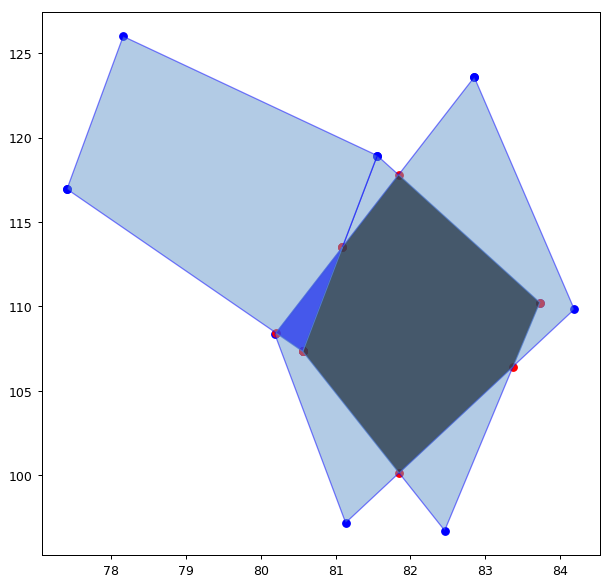

Successful overlap:
['S1A_EW_GRDH_1SDH_20141010T083713_20141010T083813_002765_0031BE_8D86.zip', 'S1A_EW_GRDH_1SDH_20141010T083813_20141010T083854_002765_0031BE_416E.zip']
with
['S1A_EW_GRDH_1SSH_20141013T005244_20141013T005341_002804_00328C_CD76.zip', 'S1A_EW_GRDH_1SSH_20141013T005244_20141013T005341_002804_00328C_E6DE.zip']

Time difference is  2 days, 16:15:31
2014-10-10T083713 2014-10-13T005244
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141010T083713_20141010T083813_002765_0031BE_8D86.zip
80.561920166 100.137297488 83.7283782959 117.795368984
76.9905 103.031 81.8087 129.398
80.2037007113 107.340141296 81.0905580193 113.501444103
76.9905 103.031 81.8087 129.398
False False
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141010T083813_20141010T083854_002765_0031BE_416E.zip
80.561920166 100.137297488 83.7283782959 117.795368984
80.0202 92.1994 84.066 123.572
80.2037007113 107.340141296 81.0905580193 113.501444

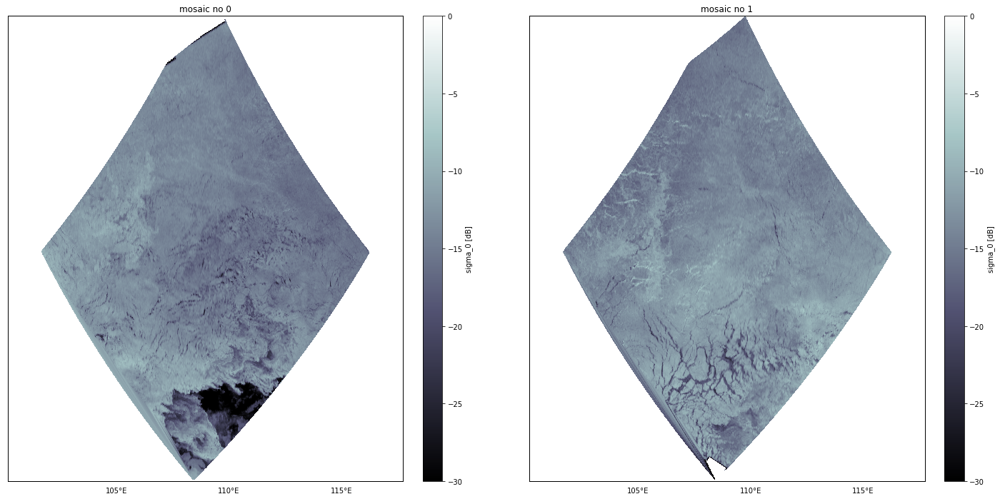

Kara_2014-10-10T083713_2014-10-13T005244_lat-3_lon-2_hh.pickle is created
2014-10-10 11:52:54 2014-10-10 13:33:19
area of intersection 0.0
cond_area False
2014-10-10 11:52:54 2014-10-12 05:07:58
area of intersection 11.6347680166
cond_area True
Images overlap


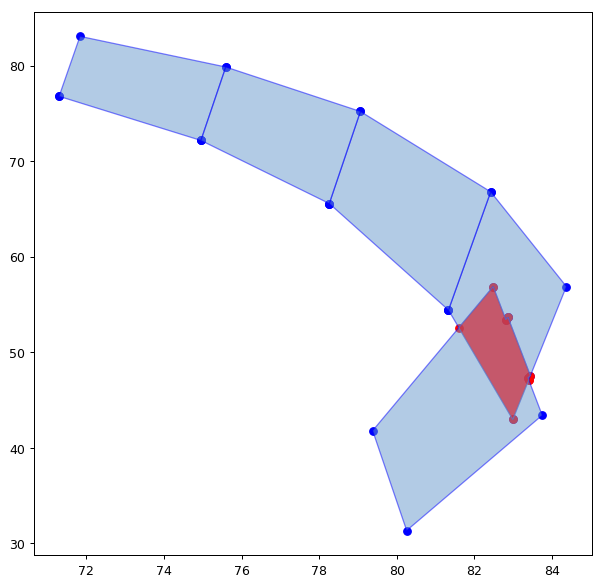

Successful overlap:
['S1A_EW_GRDH_1SDH_20141010T115254_20141010T115358_002767_0031C7_38E2.zip', 'S1A_EW_GRDH_1SDH_20141010T115358_20141010T115458_002767_0031C7_54C4.zip', 'S1A_EW_GRDH_1SDH_20141010T115458_20141010T115558_002767_0031C7_72CF.zip', 'S1A_EW_GRDH_1SDH_20141010T115558_20141010T115636_002767_0031C7_5FEF.zip']
with
['S1A_EW_GRDH_1SDH_20141012T050758_20141012T050902_002792_00324F_1F7F.zip', 'S1A_EW_GRDM_1SDH_20141012T050758_20141012T050902_002792_00324F_7CDB.zip']

Time difference is  1 day, 17:15:04
2014-10-10T115254 2014-10-12T050758
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141010T115254_20141010T115358_002767_0031C7_38E2.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141010T115358_20141010T115458_002767_0031C7_54C4.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141010T115458_20141010T115558_002767_0031C7_72CF.zip
False True
/home/cerca

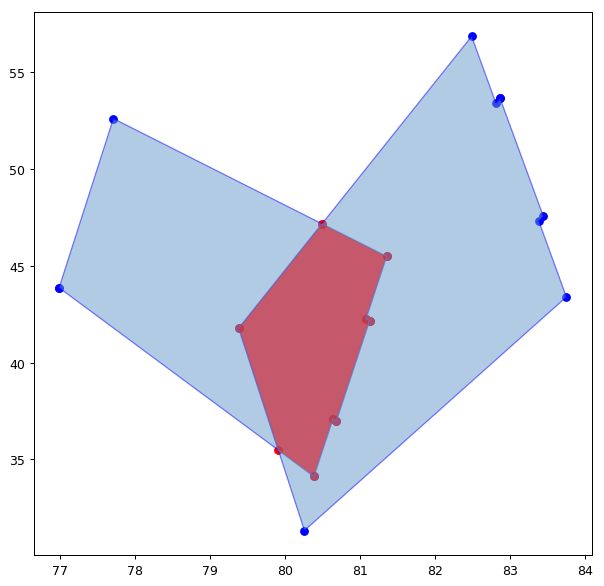

Successful overlap:
['S1A_EW_GRDH_1SDH_20141010T133319_20141010T133423_002768_0031CC_33CD.zip', 'S1A_EW_GRDM_1SDH_20141010T133319_20141010T133423_002768_0031CC_EBAC.zip']
with
['S1A_EW_GRDH_1SDH_20141012T050758_20141012T050902_002792_00324F_1F7F.zip', 'S1A_EW_GRDM_1SDH_20141012T050758_20141012T050902_002792_00324F_7CDB.zip']

Time difference is  1 day, 15:34:39
2014-10-10T133319 2014-10-12T050758
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141010T133319_20141010T133423_002768_0031CC_33CD.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141010T133319_20141010T133423_002768_0031CC_EBAC.zip
False True
no HV data found
2014-10-12 05:07:58 2014-10-12 09:58:54
area of intersection 0.0
cond_area False


2014-10-12 05:07:58 2014-10-12 13:14:22
area of intersection 31.311416967
cond_area True
Images overlap


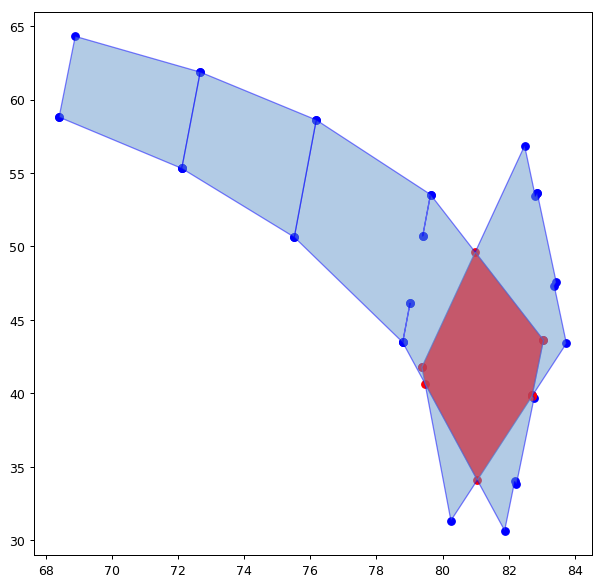

Successful overlap:
['S1A_EW_GRDH_1SDH_20141012T050758_20141012T050902_002792_00324F_1F7F.zip', 'S1A_EW_GRDM_1SDH_20141012T050758_20141012T050902_002792_00324F_7CDB.zip']
with
['S1A_EW_GRDH_1SDH_20141012T131422_20141012T131526_002797_003264_EE1B.zip', 'S1A_EW_GRDH_1SDH_20141012T131526_20141012T131626_002797_003264_A445.zip', 'S1A_EW_GRDM_1SDH_20141012T131626_20141012T131726_002797_003264_653D.zip', 'S1A_EW_GRDH_1SDH_20141012T131626_20141012T131726_002797_003264_CF18.zip', 'S1A_EW_GRDM_1SDH_20141012T131726_20141012T131827_002797_003264_8DB3.zip', 'S1A_EW_GRDH_1SDH_20141012T131726_20141012T131827_002797_003264_DB94.zip']

Time difference is  8:06:24
2014-10-12T050758 2014-10-12T131422
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141012T050758_20141012T050902_002792_00324F_1F7F.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141012T050758_20141012T050902_002792_00324F_7CDB.zip
False True
no HV data f

2014-10-12 09:58:54 2014-10-13 00:52:44
area of intersection 0.279258024765
cond_area False
2014-10-12 09:58:54 2014-10-13 02:31:44
area of intersection 12.0141938844
cond_area True
Images overlap


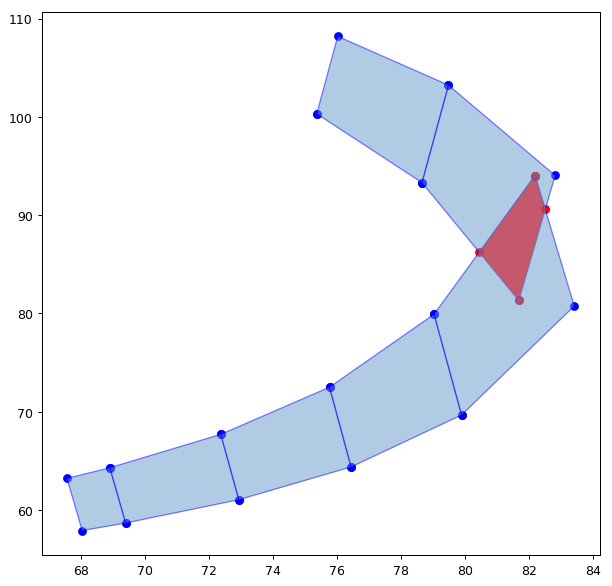

Successful overlap:
['S1A_EW_GRDH_1SDH_20141012T095854_20141012T095954_002795_00325D_AA06.zip', 'S1A_EW_GRDH_1SDH_20141012T095954_20141012T100054_002795_00325D_9A91.zip']
with
['S1A_EW_GRDH_1SDH_20141013T023144_20141013T023248_002805_003293_5B45.zip', 'S1A_EW_GRDH_1SDH_20141013T023248_20141013T023348_002805_003293_0638.zip', 'S1A_EW_GRDH_1SDH_20141013T023348_20141013T023448_002805_003293_6D0A.zip', 'S1A_EW_GRDH_1SDH_20141013T023448_20141013T023548_002805_003293_15AE.zip', 'S1A_EW_GRDH_1SDH_20141013T023548_20141013T023611_002805_003293_6157.zip']

Time difference is  16:32:50
2014-10-12T095854 2014-10-13T023144
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141012T095854_20141012T095954_002795_00325D_AA06.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141012T095954_20141012T100054_002795_00325D_9A91.zip
False True
no HV data found
2014-10-12 13:14:22 2014-10-13 00:52:44
area of intersection 0.0
cond

2014-10-12 13:14:22 2014-10-13 02:31:44
area of intersection 14.8550415998
cond_area True
Images overlap


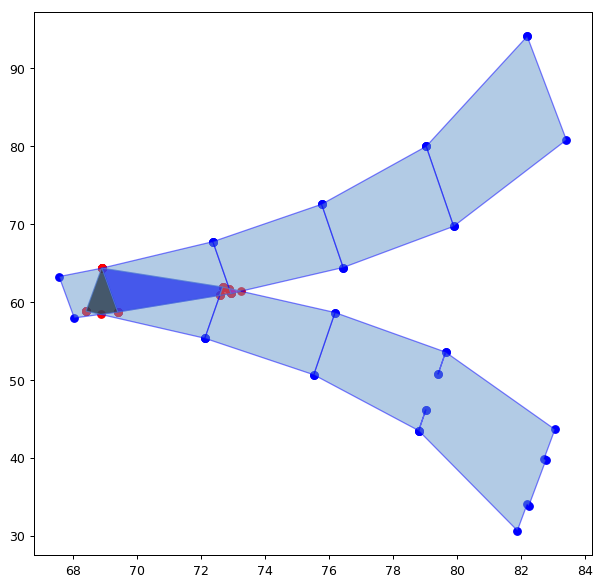

Successful overlap:
['S1A_EW_GRDH_1SDH_20141012T131422_20141012T131526_002797_003264_EE1B.zip', 'S1A_EW_GRDH_1SDH_20141012T131526_20141012T131626_002797_003264_A445.zip', 'S1A_EW_GRDM_1SDH_20141012T131626_20141012T131726_002797_003264_653D.zip', 'S1A_EW_GRDH_1SDH_20141012T131626_20141012T131726_002797_003264_CF18.zip', 'S1A_EW_GRDM_1SDH_20141012T131726_20141012T131827_002797_003264_8DB3.zip', 'S1A_EW_GRDH_1SDH_20141012T131726_20141012T131827_002797_003264_DB94.zip']
with
['S1A_EW_GRDH_1SDH_20141013T023144_20141013T023248_002805_003293_5B45.zip', 'S1A_EW_GRDH_1SDH_20141013T023248_20141013T023348_002805_003293_0638.zip', 'S1A_EW_GRDH_1SDH_20141013T023348_20141013T023448_002805_003293_6D0A.zip', 'S1A_EW_GRDH_1SDH_20141013T023448_20141013T023548_002805_003293_15AE.zip', 'S1A_EW_GRDH_1SDH_20141013T023548_20141013T023611_002805_003293_6157.zip']

Time difference is  13:17:22
2014-10-12T131422 2014-10-13T023144
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_

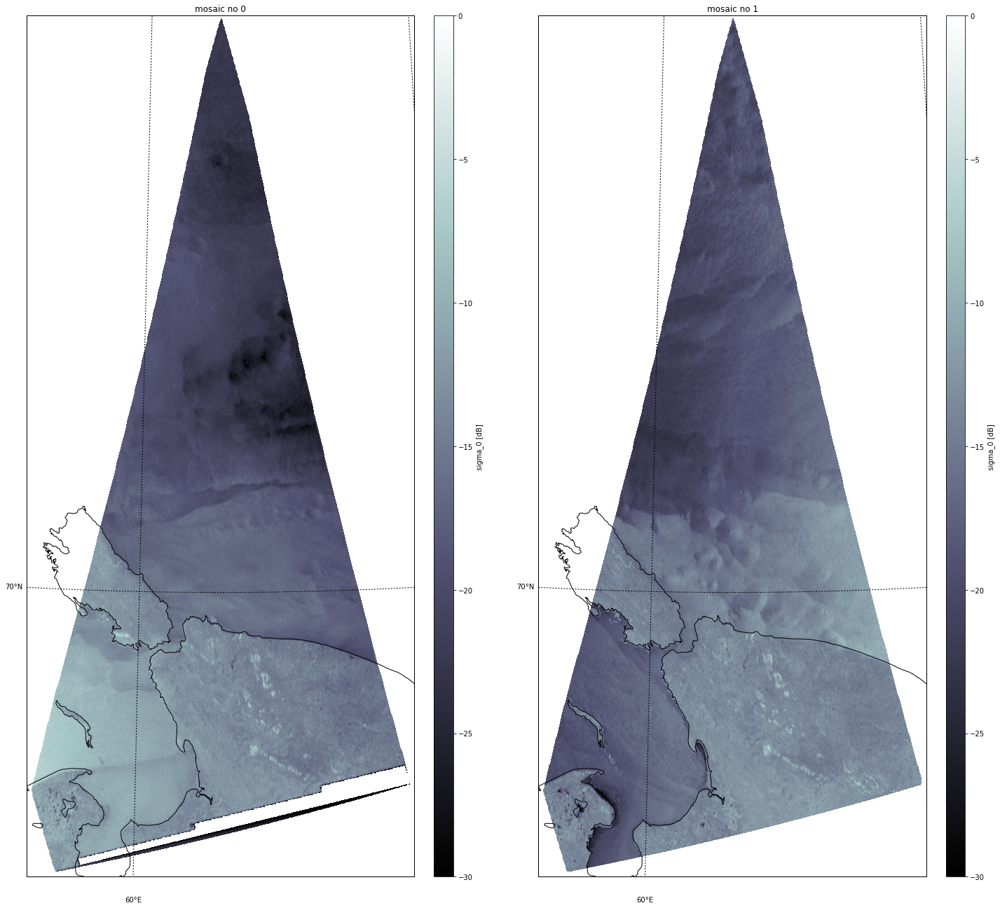

Kara_2014-10-12T131422_2014-10-13T023144_lat-3_lon-2_hh.pickle is created
2014-10-13 00:52:44 2014-10-13 02:31:44
area of intersection 0.0
cond_area False
2014-10-13 00:52:44 2014-10-13 04:09:58
area of intersection 0.0
cond_area False
2014-10-13 00:52:44 2014-10-13 13:57:17
area of intersection 0.0
cond_area False
2014-10-13 00:52:44 2014-10-13 23:56:34
area of intersection 0.0
cond_area False
2014-10-13 00:52:44 2014-10-14 01:34:08
area of intersection 9.63510065594
cond_area True
Images overlap


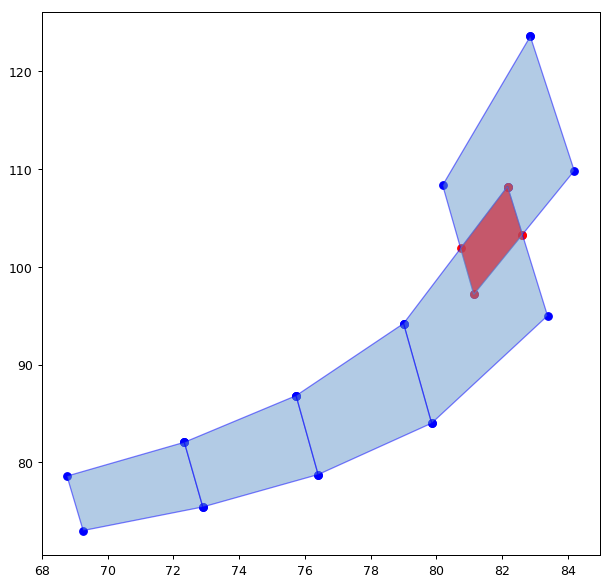

Successful overlap:
['S1A_EW_GRDH_1SSH_20141013T005244_20141013T005341_002804_00328C_CD76.zip', 'S1A_EW_GRDH_1SSH_20141013T005244_20141013T005341_002804_00328C_E6DE.zip']
with
['S1A_EW_GRDH_1SDH_20141014T013408_20141014T013513_002819_0032D4_F023.zip', 'S1A_EW_GRDH_1SDH_20141014T013513_20141014T013613_002819_0032D4_09BB.zip', 'S1A_EW_GRDH_1SDH_20141014T013613_20141014T013713_002819_0032D4_3CDC.zip', 'S1A_EW_GRDH_1SDH_20141014T013713_20141014T013814_002819_0032D4_FFA0.zip']

Time difference is  1 day, 0:41:24
2014-10-13T005244 2014-10-14T013408
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SSH_20141013T005244_20141013T005341_002804_00328C_CD76.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SSH_20141013T005244_20141013T005341_002804_00328C_E6DE.zip
False True
no HV data found
2014-10-13 02:31:44 2014-10-13 04:09:58
area of intersection 0.0
cond_area False


2014-10-13 02:31:44 2014-10-13 13:57:17
area of intersection 0.0
cond_area False
2014-10-13 02:31:44 2014-10-13 23:56:34
area of intersection 0.0
cond_area False
2014-10-13 02:31:44 2014-10-14 01:34:08
area of intersection 3.07997441517
cond_area True
Images overlap


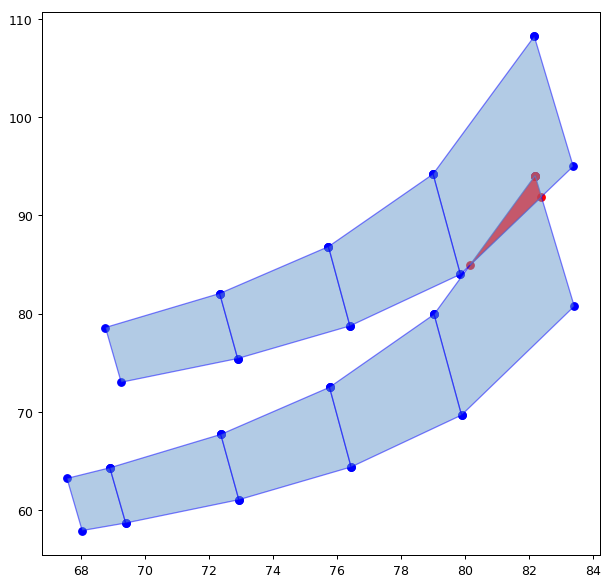

Successful overlap:
['S1A_EW_GRDH_1SDH_20141013T023144_20141013T023248_002805_003293_5B45.zip', 'S1A_EW_GRDH_1SDH_20141013T023248_20141013T023348_002805_003293_0638.zip', 'S1A_EW_GRDH_1SDH_20141013T023348_20141013T023448_002805_003293_6D0A.zip', 'S1A_EW_GRDH_1SDH_20141013T023448_20141013T023548_002805_003293_15AE.zip', 'S1A_EW_GRDH_1SDH_20141013T023548_20141013T023611_002805_003293_6157.zip']
with
['S1A_EW_GRDH_1SDH_20141014T013408_20141014T013513_002819_0032D4_F023.zip', 'S1A_EW_GRDH_1SDH_20141014T013513_20141014T013613_002819_0032D4_09BB.zip', 'S1A_EW_GRDH_1SDH_20141014T013613_20141014T013713_002819_0032D4_3CDC.zip', 'S1A_EW_GRDH_1SDH_20141014T013713_20141014T013814_002819_0032D4_FFA0.zip']

Time difference is  23:02:24
2014-10-13T023144 2014-10-14T013408
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141013T023144_20141013T023248_002805_003293_5B45.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20

2014-10-13 04:09:58 2014-10-13 23:56:34
area of intersection 0.0
cond_area False
2014-10-13 04:09:58 2014-10-14 01:34:08
area of intersection 0.0
cond_area False
2014-10-13 04:09:58 2014-10-14 04:51:35
area of intersection 8.07431299569
cond_area True
Images overlap


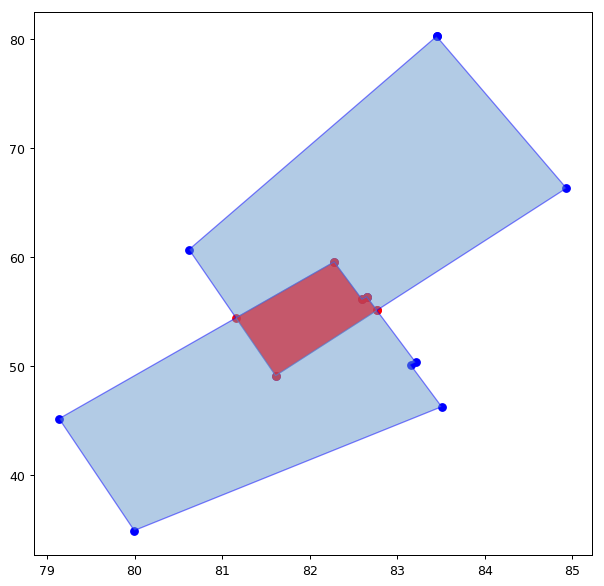

Successful overlap:
['S1A_EW_GRDH_1SSH_20141013T040958_20141013T041102_002806_003297_744E.zip']
with
['S1A_EW_GRDM_1SDH_20141014T045135_20141014T045239_002821_0032E0_2C59.zip', 'S1A_EW_GRDH_1SDH_20141014T045135_20141014T045239_002821_0032E0_46A1.zip']

Time difference is  1 day, 0:41:37
2014-10-13T040958 2014-10-14T045135
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SSH_20141013T040958_20141013T041102_002806_003297_744E.zip
False True
no HV data found
2014-10-13 13:57:17 2014-10-13 23:56:34
area of intersection 0.0
cond_area False


2014-10-13 13:57:17 2014-10-14 01:34:08
area of intersection 0.0
cond_area False
2014-10-13 13:57:17 2014-10-14 04:51:35
area of intersection 0.0
cond_area False
2014-10-13 13:57:17 2014-10-14 11:20:15
area of intersection 0.0
cond_area False
2014-10-13 13:57:17 2014-10-15 00:36:36
area of intersection 0.0
cond_area False
2014-10-13 13:57:17 2014-10-15 03:54:03
area of intersection 11.3805394969
cond_area True
Images overlap


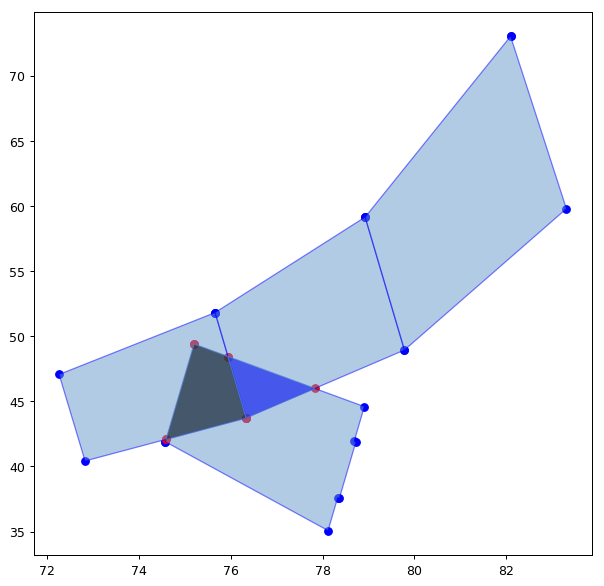

Successful overlap:
['S1A_EW_GRDH_1SDH_20141013T135717_20141013T135822_002812_0032A9_0387.zip', 'S1A_EW_GRDM_1SDH_20141013T135718_20141013T135822_002812_0032A9_4764.zip']
with
['S1A_EW_GRDH_1SDH_20141015T035403_20141015T035507_002835_003324_7DAA.zip', 'S1A_EW_GRDH_1SDH_20141015T035403_20141015T035507_002835_003324_EFD2.zip', 'S1A_EW_GRDH_1SDH_20141015T035507_20141015T035607_002835_003324_B8D5.zip', 'S1A_EW_GRDH_1SDH_20141015T035507_20141015T035607_002835_003324_F38E.zip', 'S1A_EW_GRDH_1SDH_20141015T035607_20141015T035707_002835_003324_0393.zip', 'S1A_EW_GRDH_1SDH_20141015T035607_20141015T035707_002835_003324_E135.zip']

Time difference is  1 day, 13:56:46
2014-10-13T135717 2014-10-15T035403
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141013T135717_20141013T135822_002812_0032A9_0387.zip
74.5926019479 42.0749474854 76.334487915 49.3815612793
74.2267 31.3054 79.1066 52.1285
75.9417585322 43.7256889343 77.8310992321 48.425876714
74.2267 31.3054 

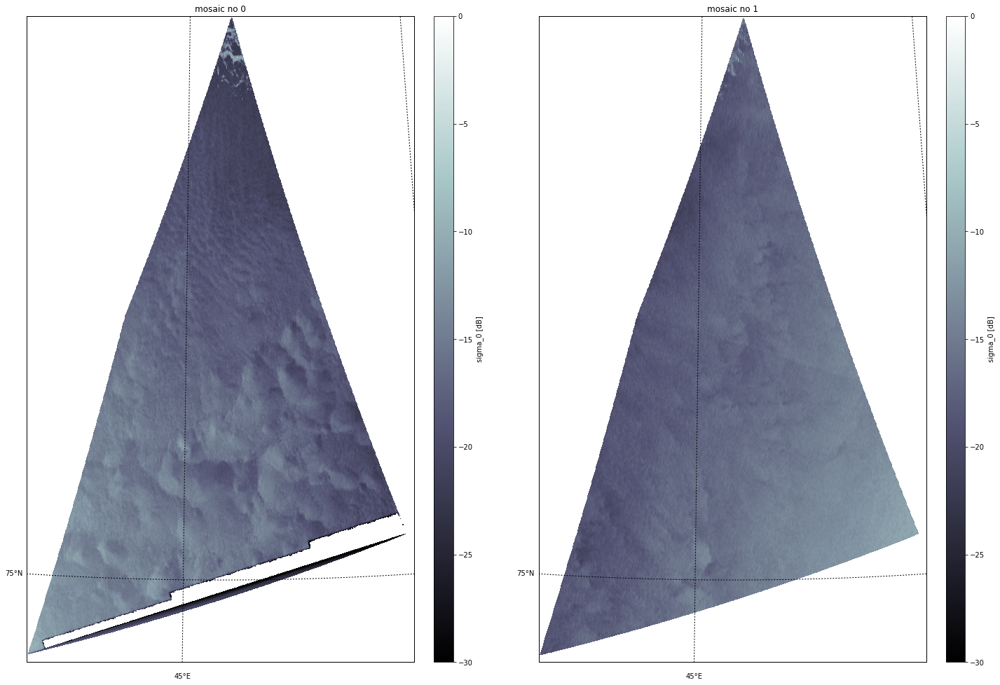

Kara_2014-10-13T135717_2014-10-15T035403_lat-3_lon-2_hh.pickle is created
2014-10-13 23:56:34 2014-10-14 01:34:08
area of intersection 0.0
cond_area False
2014-10-13 23:56:34 2014-10-14 04:51:35
area of intersection 0.0
cond_area False
2014-10-13 23:56:34 2014-10-14 11:20:15
area of intersection 0.0
cond_area False
2014-10-13 23:56:34 2014-10-15 00:36:36
area of intersection 1.82155675833
cond_area True
Images overlap


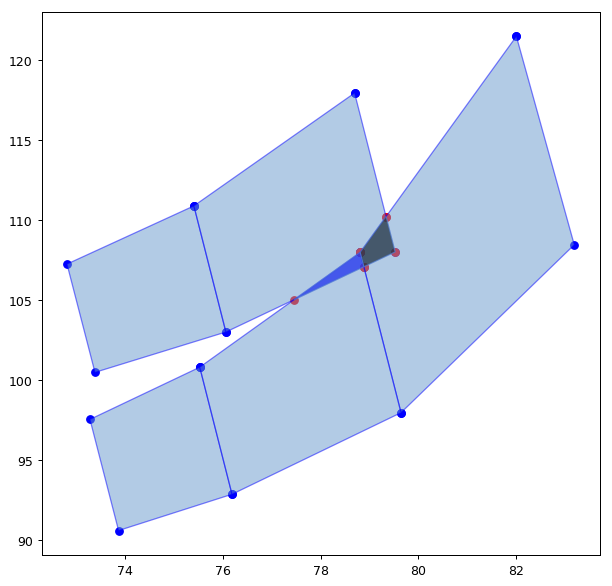

Successful overlap:
['S1A_EW_GRDH_1SDH_20141013T235634_20141013T235734_002818_0032CB_1A7F.zip', 'S1A_EW_GRDH_1SDH_20141013T235734_20141013T235819_002818_0032CB_0F48.zip']
with
['S1A_EW_GRDH_1SDH_20141015T003636_20141015T003740_002833_003319_94EB.zip', 'S1A_EW_GRDH_1SDH_20141015T003740_20141015T003840_002833_003319_8C20.zip', 'S1A_EW_GRDH_1SDH_20141015T003840_20141015T003920_002833_003319_32E2.zip']

Time difference is  1 day, 0:40:02
2014-10-13T235634 2014-10-15T003636
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141013T235634_20141013T235734_002818_0032CB_1A7F.zip
78.8096389771 107.103857616 79.5228805542 110.234607398
75.0466 100.119 79.7299 121.85
77.4579870594 105.038314756 78.8838309444 107.995346069
75.0466 100.119 79.7299 121.85
False False
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141013T235734_20141013T235819_002818_0032CB_0F48.zip
78.8096389771 107.103857616 79.5228805542 110.234607398
72.5017 98

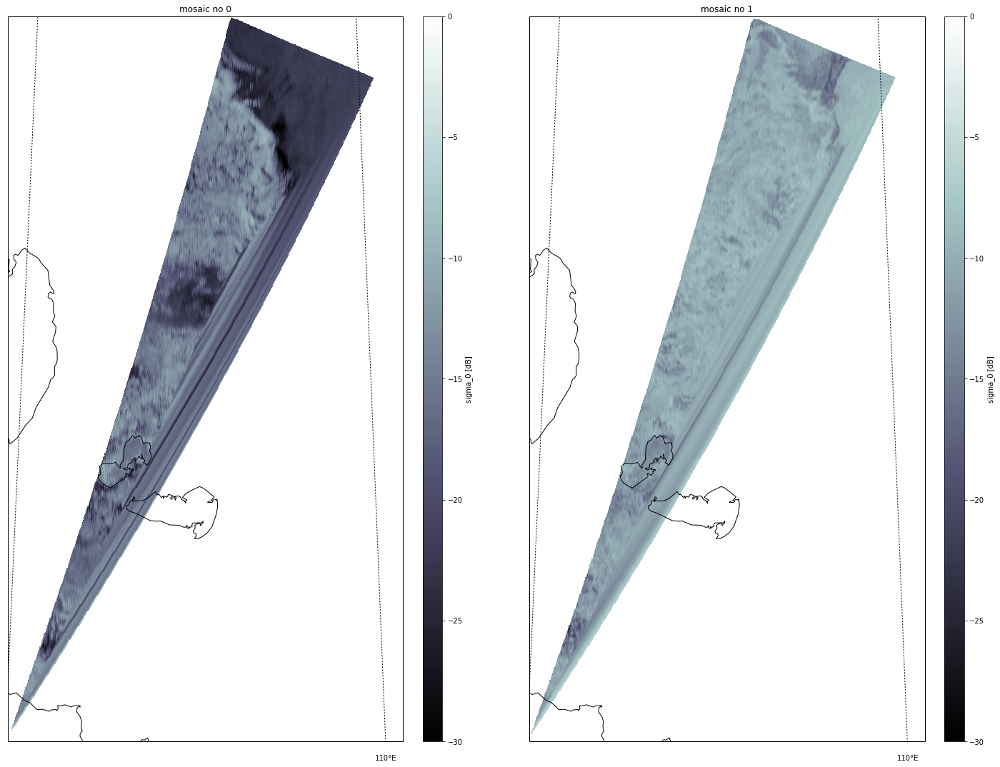

Kara_2014-10-13T235634_2014-10-15T003636_lat-3_lon-2_hh.pickle is created
2014-10-14 01:34:08 2014-10-14 04:51:35
area of intersection 0.0
cond_area False
2014-10-14 01:34:08 2014-10-14 11:20:15
area of intersection 28.1229173986
cond_area True
Images overlap


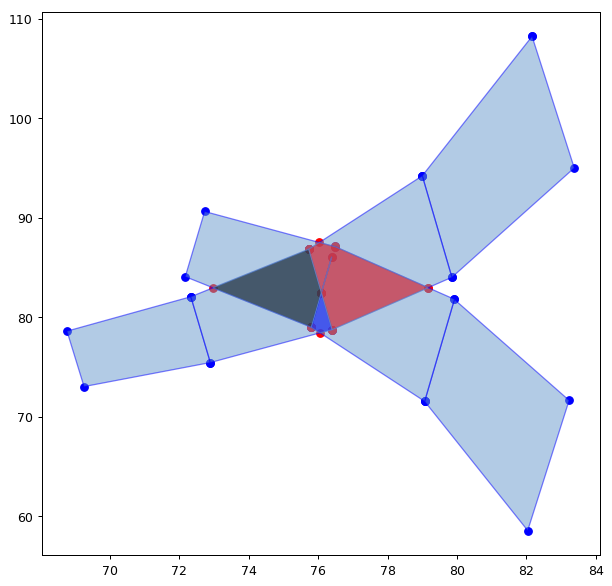

Successful overlap:
['S1A_EW_GRDH_1SDH_20141014T013408_20141014T013513_002819_0032D4_F023.zip', 'S1A_EW_GRDH_1SDH_20141014T013513_20141014T013613_002819_0032D4_09BB.zip', 'S1A_EW_GRDH_1SDH_20141014T013613_20141014T013713_002819_0032D4_3CDC.zip', 'S1A_EW_GRDH_1SDH_20141014T013713_20141014T013814_002819_0032D4_FFA0.zip']
with
['S1A_EW_GRDH_1SDH_20141014T112015_20141014T112119_002825_0032F5_AAB3.zip', 'S1A_EW_GRDH_1SDH_20141014T112119_20141014T112219_002825_0032F5_F1BE.zip', 'S1A_EW_GRDH_1SDH_20141014T112219_20141014T112319_002825_0032F5_9024.zip']

Time difference is  9:46:07
2014-10-14T013408 2014-10-14T112015
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141014T013408_20141014T013513_002819_0032D4_F023.zip
72.9727508022 78.9789199829 76.093183066 86.812538147
78.5304 80.0754 83.6971 112.747
75.8043212891 78.4120164132 76.4024505615 82.4616446446
78.5304 80.0754 83.6971 112.747
75.7319030762 78.7415771484 79.1684312626 87.4952442392
78.5304 80.

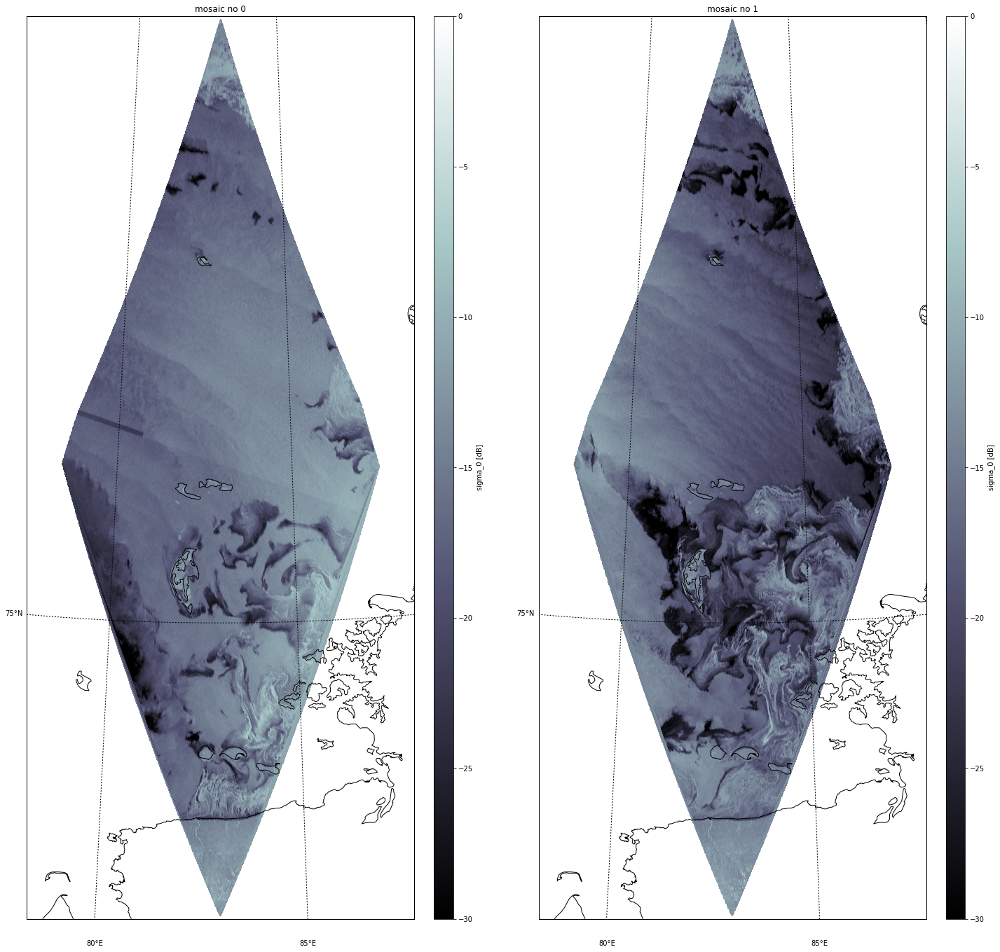

Kara_2014-10-14T013408_2014-10-14T112015_lat-3_lon-2_hh.pickle is created
2014-10-14 04:51:35 2014-10-14 11:20:15
area of intersection 0.0
cond_area False
2014-10-14 04:51:35 2014-10-15 00:36:36
area of intersection 0.0
cond_area False
2014-10-14 04:51:35 2014-10-15 03:54:03
area of intersection 3.22386674157
cond_area True
Images overlap


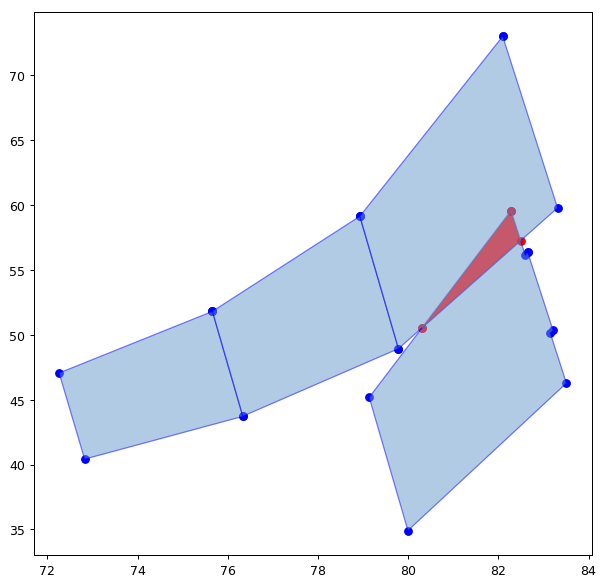

Successful overlap:
['S1A_EW_GRDM_1SDH_20141014T045135_20141014T045239_002821_0032E0_2C59.zip', 'S1A_EW_GRDH_1SDH_20141014T045135_20141014T045239_002821_0032E0_46A1.zip']
with
['S1A_EW_GRDH_1SDH_20141015T035403_20141015T035507_002835_003324_7DAA.zip', 'S1A_EW_GRDH_1SDH_20141015T035403_20141015T035507_002835_003324_EFD2.zip', 'S1A_EW_GRDH_1SDH_20141015T035507_20141015T035607_002835_003324_B8D5.zip', 'S1A_EW_GRDH_1SDH_20141015T035507_20141015T035607_002835_003324_F38E.zip', 'S1A_EW_GRDH_1SDH_20141015T035607_20141015T035707_002835_003324_0393.zip', 'S1A_EW_GRDH_1SDH_20141015T035607_20141015T035707_002835_003324_E135.zip']

Time difference is  23:02:28
2014-10-14T045135 2014-10-15T035403
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141014T045135_20141014T045239_002821_0032E0_2C59.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141014T045135_20141014T045239_002821_0032E0_46A1.zip
False True
no HV data 

2014-10-14 11:20:15 2014-10-15 03:54:03
area of intersection 16.7301609493
cond_area True
Images overlap


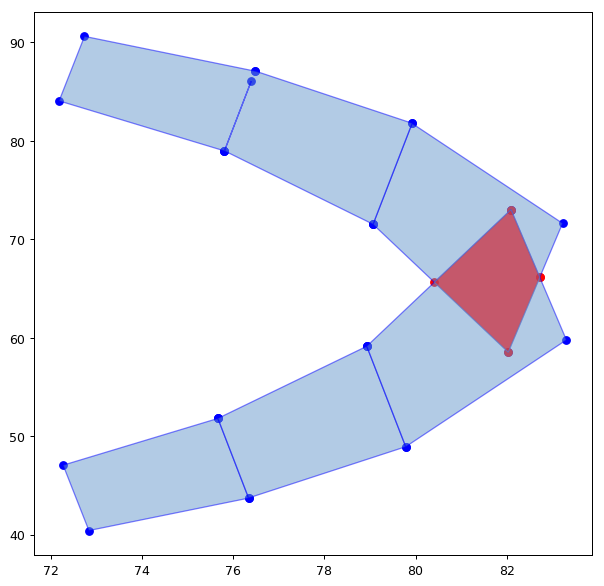

Successful overlap:
['S1A_EW_GRDH_1SDH_20141014T112015_20141014T112119_002825_0032F5_AAB3.zip', 'S1A_EW_GRDH_1SDH_20141014T112119_20141014T112219_002825_0032F5_F1BE.zip', 'S1A_EW_GRDH_1SDH_20141014T112219_20141014T112319_002825_0032F5_9024.zip']
with
['S1A_EW_GRDH_1SDH_20141015T035403_20141015T035507_002835_003324_7DAA.zip', 'S1A_EW_GRDH_1SDH_20141015T035403_20141015T035507_002835_003324_EFD2.zip', 'S1A_EW_GRDH_1SDH_20141015T035507_20141015T035607_002835_003324_B8D5.zip', 'S1A_EW_GRDH_1SDH_20141015T035507_20141015T035607_002835_003324_F38E.zip', 'S1A_EW_GRDH_1SDH_20141015T035607_20141015T035707_002835_003324_0393.zip', 'S1A_EW_GRDH_1SDH_20141015T035607_20141015T035707_002835_003324_E135.zip']

Time difference is  16:33:48
2014-10-14T112015 2014-10-15T035403
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141014T112015_20141014T112119_002825_0032F5_AAB3.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20

2014-10-15 00:36:36 2014-10-15 10:22:48
area of intersection 27.7173067781
cond_area True
Images overlap


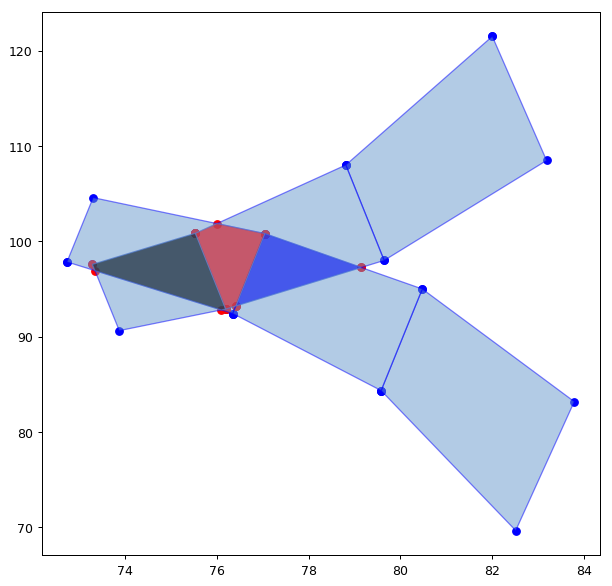

Successful overlap:
['S1A_EW_GRDH_1SDH_20141015T003636_20141015T003740_002833_003319_94EB.zip', 'S1A_EW_GRDH_1SDH_20141015T003740_20141015T003840_002833_003319_8C20.zip', 'S1A_EW_GRDH_1SDH_20141015T003840_20141015T003920_002833_003319_32E2.zip']
with
['S1A_EW_GRDH_1SDH_20141015T102248_20141015T102352_002839_00333A_82C1.zip', 'S1A_EW_GRDH_1SDH_20141015T102352_20141015T102452_002839_00333A_B709.zip', 'S1A_EW_GRDH_1SDH_20141015T102452_20141015T102553_002839_00333A_336F.zip']

Time difference is  9:46:12
2014-10-15T003636 2014-10-15T102248
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141015T003636_20141015T003740_002833_003319_94EB.zip
73.287940979 92.7904903361 76.1906509399 100.823051453
78.3496 94.1495 83.4946 126.009
76.4134970557 93.212271003 79.1443198386 100.798309326
78.3496 94.1495 83.4946 126.009
75.5316543579 92.8837051392 77.0423431396 101.849489956
78.3496 94.1495 83.4946 126.009
False True
/home/cercache/users/atarasen/data/Sentinel

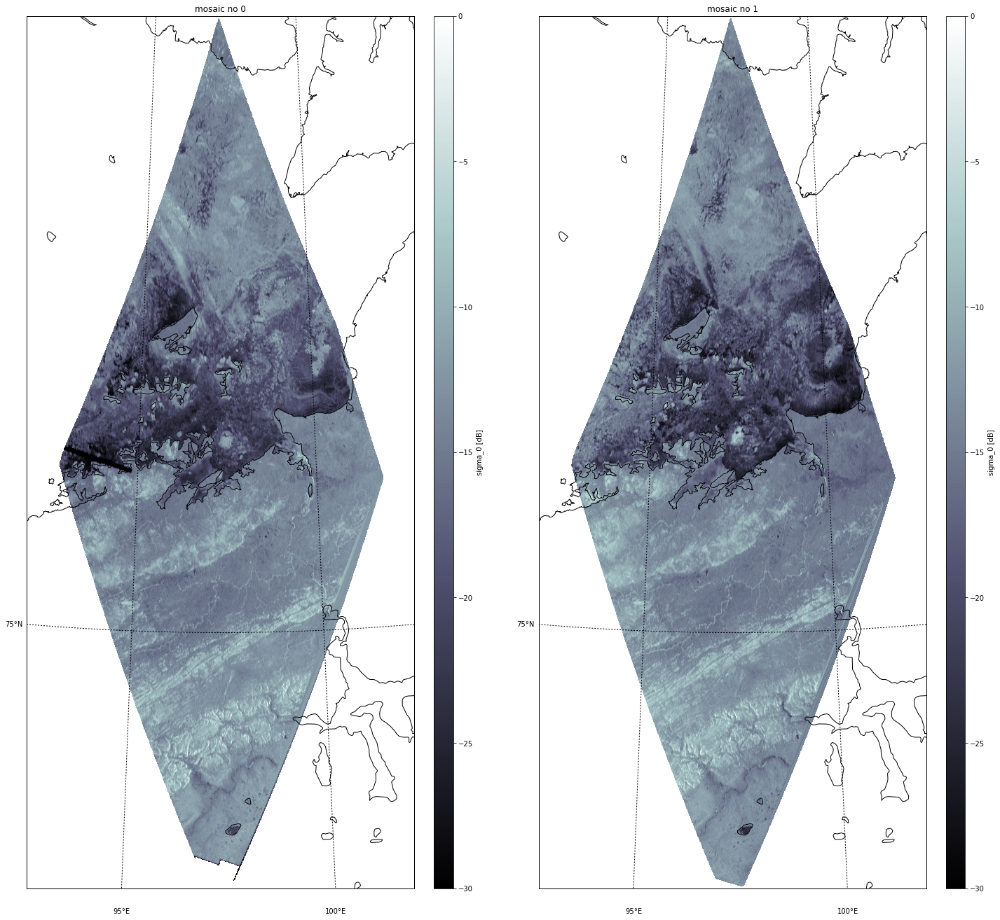

Kara_2014-10-15T003636_2014-10-15T102248_lat-3_lon-2_hh.pickle is created
2014-10-15 03:54:03 2014-10-15 10:22:48
area of intersection 0.229772017151
cond_area False
2014-10-15 03:54:03 2014-10-15 13:38:53
area of intersection 28.3034945807
cond_area True
Images overlap


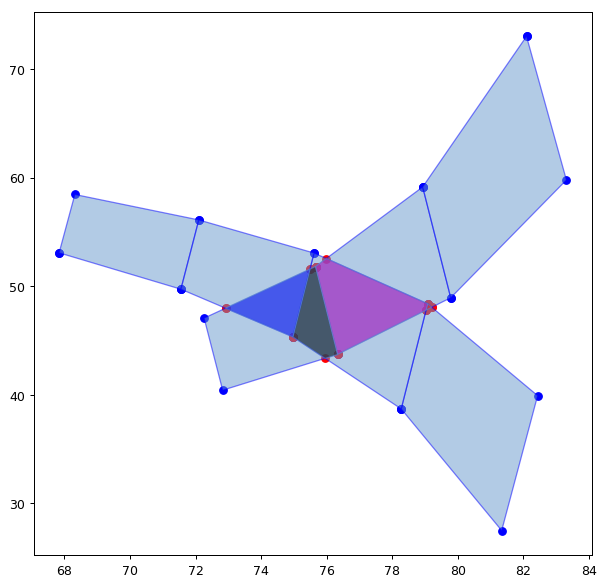

Successful overlap:
['S1A_EW_GRDH_1SDH_20141015T035403_20141015T035507_002835_003324_7DAA.zip', 'S1A_EW_GRDH_1SDH_20141015T035403_20141015T035507_002835_003324_EFD2.zip', 'S1A_EW_GRDH_1SDH_20141015T035507_20141015T035607_002835_003324_B8D5.zip', 'S1A_EW_GRDH_1SDH_20141015T035507_20141015T035607_002835_003324_F38E.zip', 'S1A_EW_GRDH_1SDH_20141015T035607_20141015T035707_002835_003324_0393.zip', 'S1A_EW_GRDH_1SDH_20141015T035607_20141015T035707_002835_003324_E135.zip']
with
['S1A_EW_GRDH_1SDH_20141015T133853_20141015T133957_002841_003343_2C8E.zip', 'S1A_EW_GRDH_1SDH_20141015T133957_20141015T134057_002841_003343_3DD5.zip', 'S1A_EW_GRDH_1SDH_20141015T134057_20141015T134157_002841_003343_0CDA.zip', 'S1A_EW_GRDH_1SDH_20141015T134157_20141015T134257_002841_003343_C898.zip']

Time difference is  9:44:50
2014-10-15T035403 2014-10-15T133853
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141015T035403_20141015T035507_002835_003324_7DAA.zip
74.9696502686 43

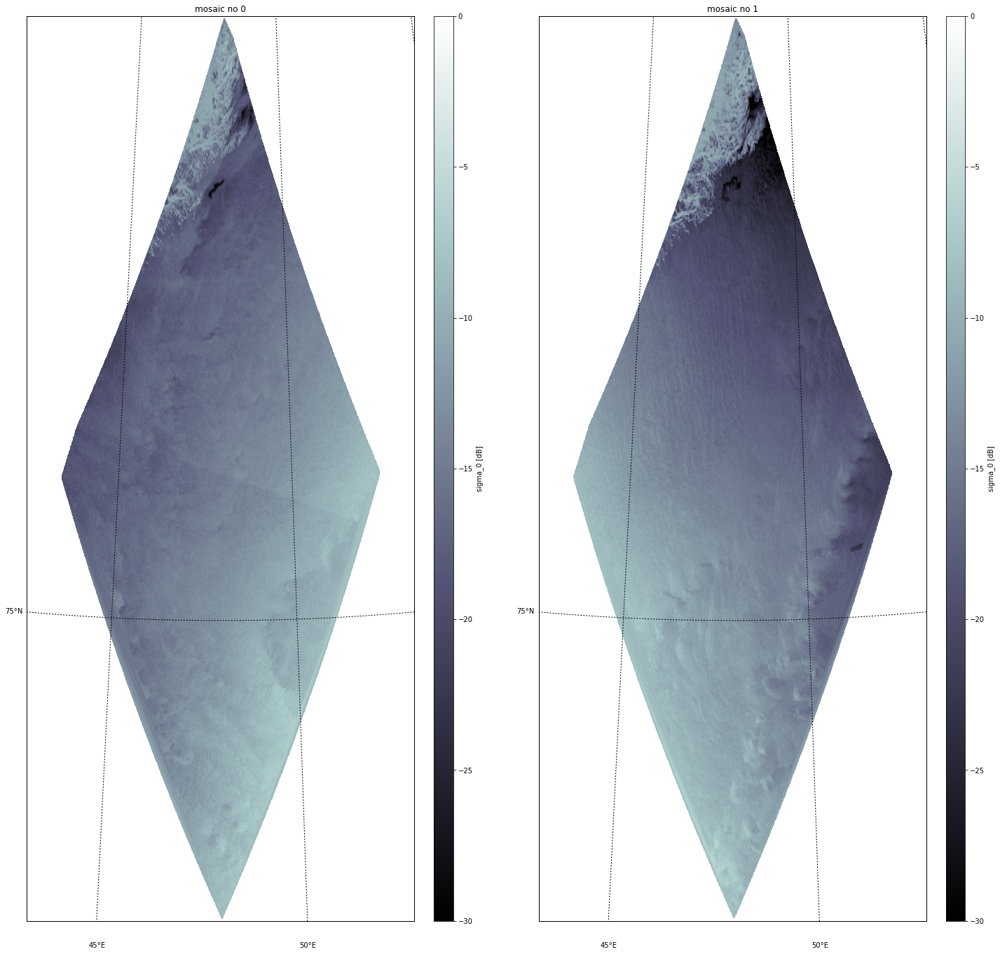

Kara_2014-10-15T035403_2014-10-15T133853_lat-3_lon-2_hh.pickle is created
2014-10-15 10:22:48 2014-10-15 13:38:53
area of intersection 0.0
cond_area False
2014-10-15 10:22:48 2014-10-15 23:41:05
area of intersection 0.0
cond_area False
2014-10-15 10:22:48 2014-10-16 02:56:25
area of intersection 24.6099642638
cond_area True
Images overlap


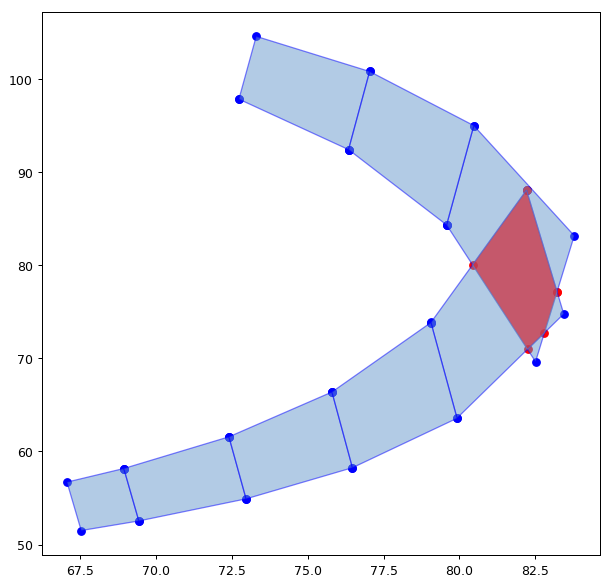

Successful overlap:
['S1A_EW_GRDH_1SDH_20141015T102248_20141015T102352_002839_00333A_82C1.zip', 'S1A_EW_GRDH_1SDH_20141015T102352_20141015T102452_002839_00333A_B709.zip', 'S1A_EW_GRDH_1SDH_20141015T102452_20141015T102553_002839_00333A_336F.zip']
with
['S1A_EW_GRDH_1SDH_20141016T025625_20141016T025729_002849_003376_BCB3.zip', 'S1A_EW_GRDH_1SDH_20141016T025729_20141016T025829_002849_003376_D015.zip', 'S1A_EW_GRDH_1SDH_20141016T025829_20141016T025929_002849_003376_E990.zip', 'S1A_EW_GRDH_1SDH_20141016T025929_20141016T030029_002849_003376_DC2D.zip', 'S1A_EW_GRDH_1SDH_20141016T030029_20141016T030101_002849_003376_618B.zip']

Time difference is  16:33:37
2014-10-15T102248 2014-10-16T025625
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141015T102248_20141015T102352_002839_00333A_82C1.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141015T102352_20141015T102452_002839_00333A_B709.zip
False True
/home/cerca

2014-10-15 13:38:53 2014-10-16 02:56:25
area of intersection 17.8295883828
cond_area True
Images overlap


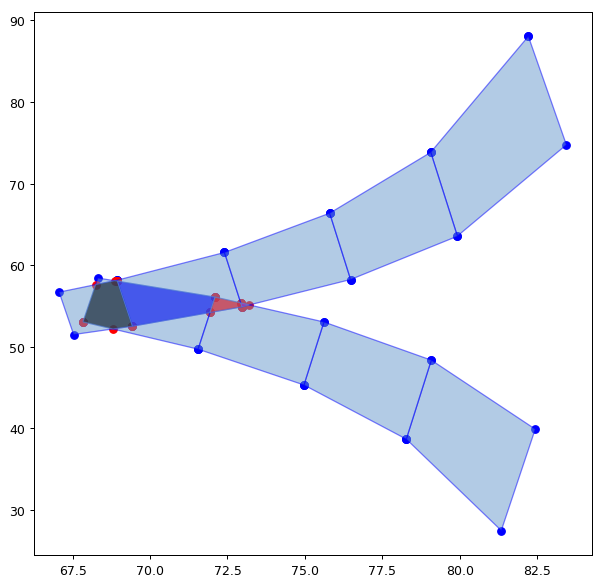

Successful overlap:
['S1A_EW_GRDH_1SDH_20141015T133853_20141015T133957_002841_003343_2C8E.zip', 'S1A_EW_GRDH_1SDH_20141015T133957_20141015T134057_002841_003343_3DD5.zip', 'S1A_EW_GRDH_1SDH_20141015T134057_20141015T134157_002841_003343_0CDA.zip', 'S1A_EW_GRDH_1SDH_20141015T134157_20141015T134257_002841_003343_C898.zip']
with
['S1A_EW_GRDH_1SDH_20141016T025625_20141016T025729_002849_003376_BCB3.zip', 'S1A_EW_GRDH_1SDH_20141016T025729_20141016T025829_002849_003376_D015.zip', 'S1A_EW_GRDH_1SDH_20141016T025829_20141016T025929_002849_003376_E990.zip', 'S1A_EW_GRDH_1SDH_20141016T025929_20141016T030029_002849_003376_DC2D.zip', 'S1A_EW_GRDH_1SDH_20141016T030029_20141016T030101_002849_003376_618B.zip']

Time difference is  13:17:32
2014-10-15T133853 2014-10-16T025625
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141015T133853_20141015T133957_002841_003343_2C8E.zip
67.8375396729 52.1991056668 69.4338607788 58.1066325622
67.5725 47.0324 72.2343 60.3666
68

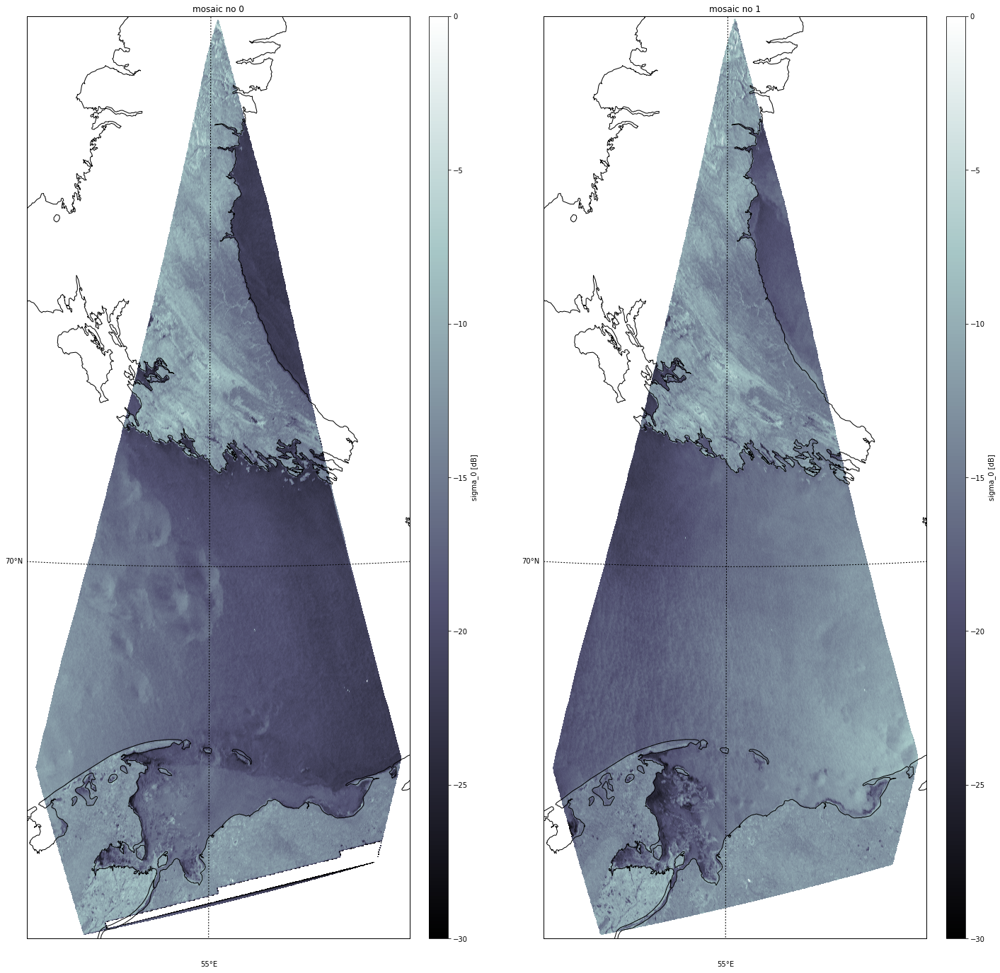

Kara_2014-10-15T133853_2014-10-16T025625_lat-3_lon-2_hh.pickle is created
2014-10-15 23:41:05 2014-10-16 02:56:25
area of intersection 0.0
cond_area False
2014-10-15 23:41:05 2014-10-16 11:04:10
area of intersection 0.0
cond_area False
2014-10-15 23:41:05 2014-10-16 12:45:03
area of intersection 0.0
cond_area False
2014-10-15 23:41:05 2014-10-17 01:58:49
area of intersection 0.0
cond_area False
2014-10-15 23:41:05 2014-10-17 03:37:24
area of intersection 0.0
cond_area False
2014-10-15 23:41:05 2014-10-17 05:16:13
area of intersection 0.0
cond_area False
2014-10-15 23:41:05 2014-10-17 10:06:07
area of intersection 5.92443016784
cond_area True
Images overlap


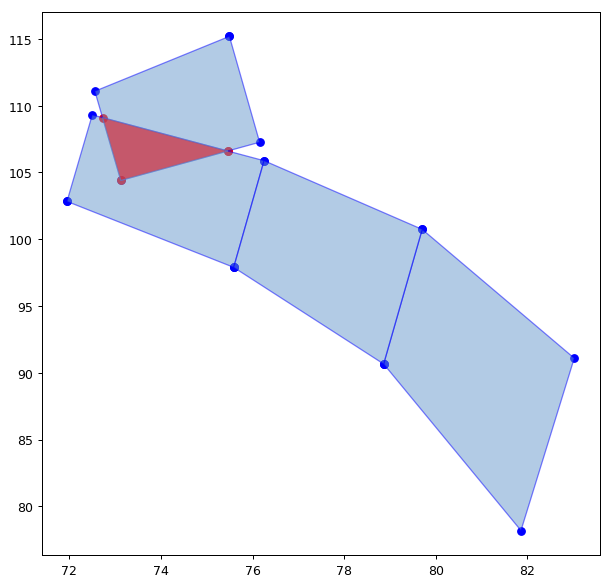

Successful overlap:
['S1A_EW_GRDH_1SDH_20141015T234105_20141015T234157_002847_003366_B9DB.zip']
with
['S1A_EW_GRDH_1SDH_20141017T100607_20141017T100711_002868_0033E4_00C2.zip', 'S1A_EW_GRDH_1SDH_20141017T100711_20141017T100811_002868_0033E4_36A0.zip', 'S1A_EW_GRDH_1SDH_20141017T100811_20141017T100911_002868_0033E4_125F.zip']

Time difference is  1 day, 10:25:02
2014-10-15T234105 2014-10-17T100607
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141015T234105_20141015T234157_002847_003366_B9DB.zip
False True
no HV data found
2014-10-16 02:56:25 2014-10-16 11:04:10
area of intersection 31.5220384498
cond_area True
Images overlap


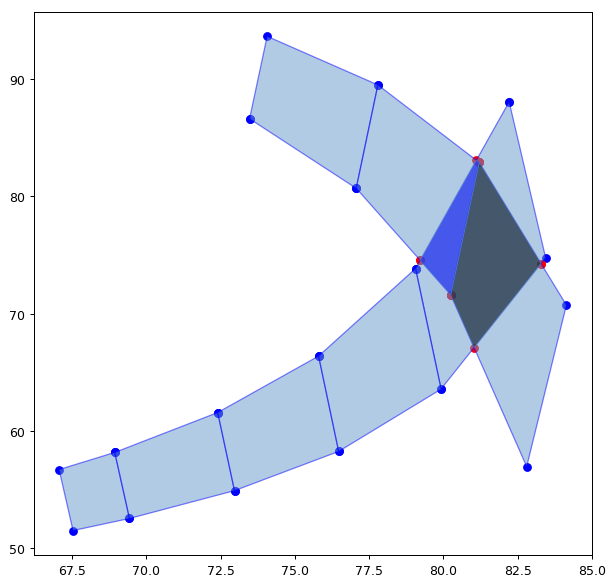

Successful overlap:
['S1A_EW_GRDH_1SDH_20141016T025625_20141016T025729_002849_003376_BCB3.zip', 'S1A_EW_GRDH_1SDH_20141016T025729_20141016T025829_002849_003376_D015.zip', 'S1A_EW_GRDH_1SDH_20141016T025829_20141016T025929_002849_003376_E990.zip', 'S1A_EW_GRDH_1SDH_20141016T025929_20141016T030029_002849_003376_DC2D.zip', 'S1A_EW_GRDH_1SDH_20141016T030029_20141016T030101_002849_003376_618B.zip']
with
['S1A_EW_GRDH_1SDH_20141016T110410_20141016T110514_002854_003397_9269.zip', 'S1A_EW_GRDH_1SDH_20141016T110514_20141016T110614_002854_003397_0432.zip', 'S1A_EW_GRDH_1SDH_20141016T110614_20141016T110709_002854_003397_FEDA.zip']

Time difference is  8:07:45
2014-10-16T025625 2014-10-16T110410
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141016T025625_20141016T025729_002849_003376_BCB3.zip
80.2471313477 67.1140527118 83.2859471119 82.8903274536
78.5905 59.6107 83.7669 92.5874
79.2194034728 71.6239013672 81.2061843872 83.0773681131
78.5905 59.6107 83.766

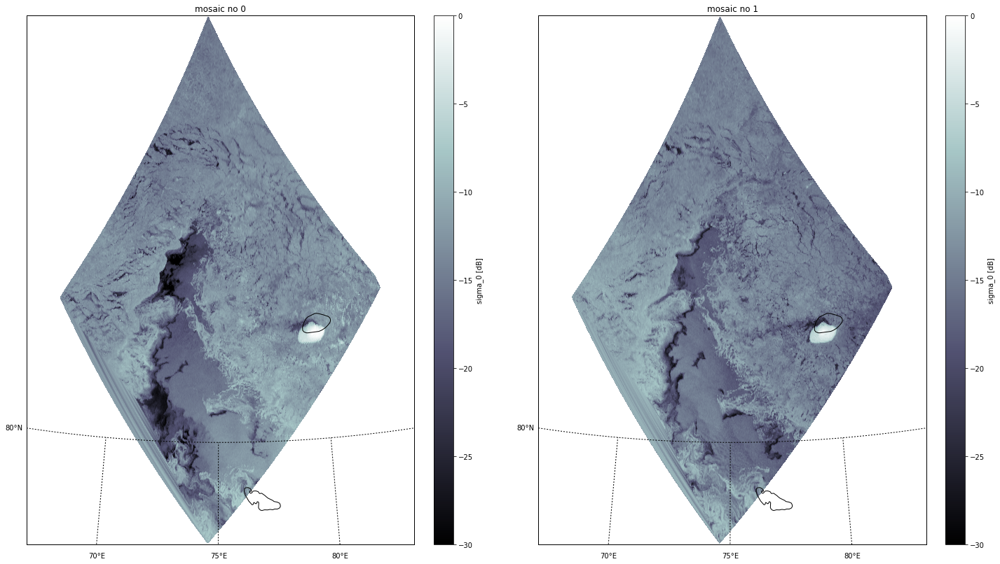

Kara_2014-10-16T025625_2014-10-16T110410_lat-3_lon-2_hh.pickle is created
2014-10-16 11:04:10 2014-10-16 12:45:03
area of intersection 0.0
cond_area False
2014-10-16 11:04:10 2014-10-17 01:58:49
area of intersection 29.819093208
cond_area True
Images overlap


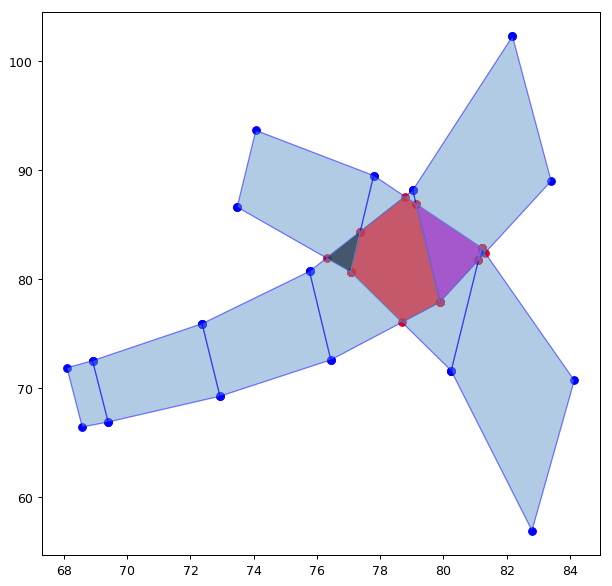

Successful overlap:
['S1A_EW_GRDH_1SDH_20141016T110410_20141016T110514_002854_003397_9269.zip', 'S1A_EW_GRDH_1SDH_20141016T110514_20141016T110614_002854_003397_0432.zip', 'S1A_EW_GRDH_1SDH_20141016T110614_20141016T110709_002854_003397_FEDA.zip']
with
['S1A_EW_GRDH_1SDH_20141017T015849_20141017T015953_002863_0033C8_DF15.zip', 'S1A_EW_GRDH_1SDH_20141017T015953_20141017T020053_002863_0033C8_BB55.zip', 'S1A_EW_GRDH_1SDH_20141017T020053_20141017T020153_002863_0033C8_5317.zip', 'S1A_EW_GRDH_1SDH_20141017T020153_20141017T020253_002863_0033C8_2DF8.zip', 'S1A_EW_GRDH_1SDH_20141017T020253_20141017T020307_002863_0033C8_58EF.zip']

Time difference is  14:54:39
2014-10-16T110410 2014-10-17T015849
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141016T110410_20141016T110514_002854_003397_9269.zip
76.3050273167 80.6917419434 77.3703928049 84.3682510817
73.1462 77.1431 77.9753 96.2022
81.1100405686 81.758798323 81.3199074784 82.8903274536
73.1462 77.1431 77.975

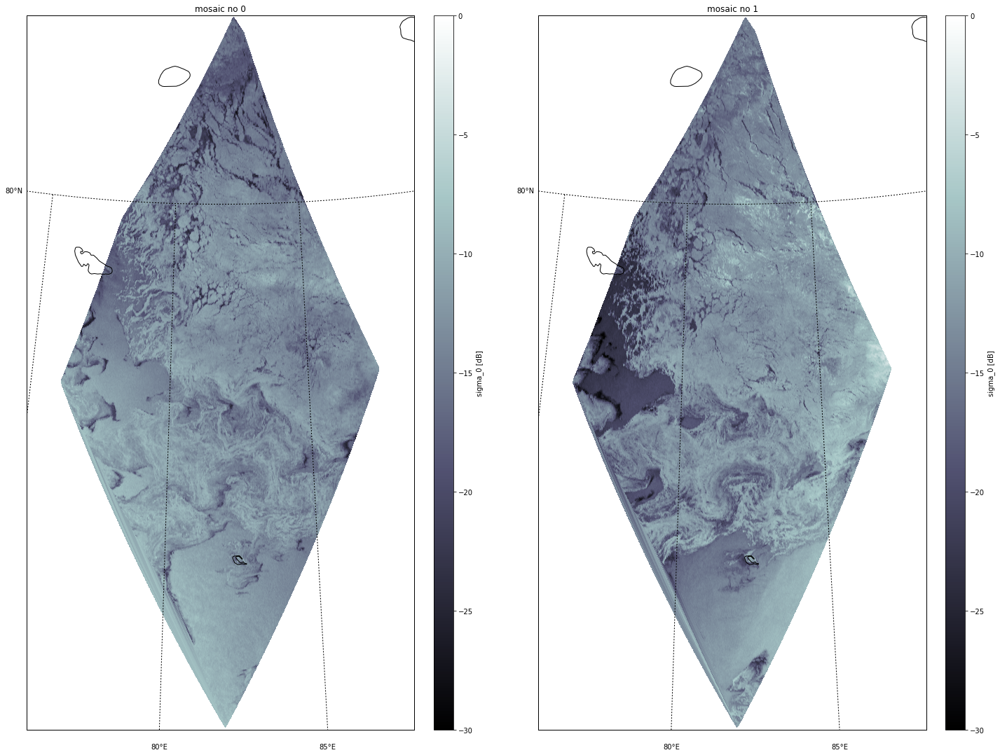

Kara_2014-10-16T110410_2014-10-17T015849_lat-3_lon-2_hh.pickle is created
2014-10-16 12:45:03 2014-10-17 01:58:49
area of intersection 0.0
cond_area False
2014-10-16 12:45:03 2014-10-17 03:37:24
area of intersection 0.0514809198856
cond_area False
2014-10-16 12:45:03 2014-10-17 05:16:13
area of intersection 30.0615026356
cond_area True
Images overlap


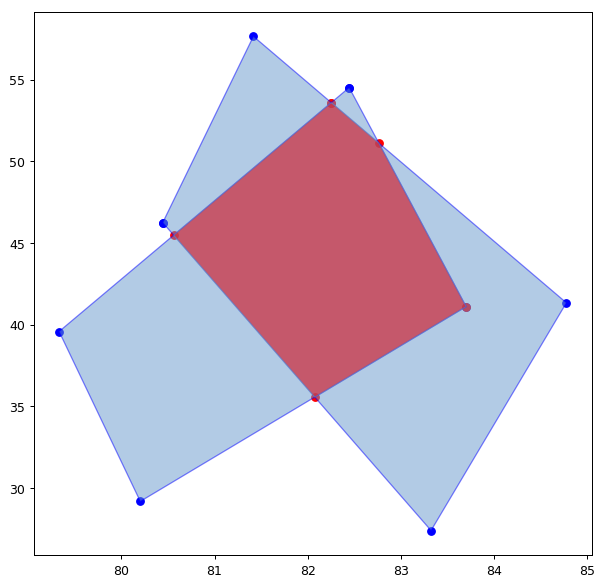

Successful overlap:
['S1A_EW_GRDH_1SSH_20141016T124503_20141016T124607_002855_00339C_CBBD.zip']
with
['S1A_EW_GRDH_1SDH_20141017T051613_20141017T051717_002865_0033D4_7D01.zip']

Time difference is  16:31:10
2014-10-16T124503 2014-10-17T051613
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SSH_20141016T124503_20141016T124607_002855_00339C_CBBD.zip
False True
no HV data found
2014-10-17 01:58:49 2014-10-17 03:37:24
area of intersection 0.0
cond_area False


2014-10-17 01:58:49 2014-10-17 05:16:13
area of intersection 0.0
cond_area False
2014-10-17 01:58:49 2014-10-17 10:06:07
area of intersection 31.7525940982
cond_area True
Images overlap


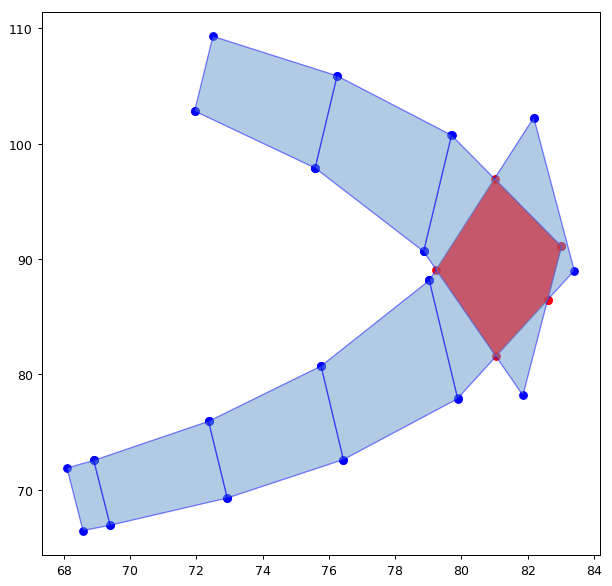

Successful overlap:
['S1A_EW_GRDH_1SDH_20141017T015849_20141017T015953_002863_0033C8_DF15.zip', 'S1A_EW_GRDH_1SDH_20141017T015953_20141017T020053_002863_0033C8_BB55.zip', 'S1A_EW_GRDH_1SDH_20141017T020053_20141017T020153_002863_0033C8_5317.zip', 'S1A_EW_GRDH_1SDH_20141017T020153_20141017T020253_002863_0033C8_2DF8.zip', 'S1A_EW_GRDH_1SDH_20141017T020253_20141017T020307_002863_0033C8_58EF.zip']
with
['S1A_EW_GRDH_1SDH_20141017T100607_20141017T100711_002868_0033E4_00C2.zip', 'S1A_EW_GRDH_1SDH_20141017T100711_20141017T100811_002868_0033E4_36A0.zip', 'S1A_EW_GRDH_1SDH_20141017T100811_20141017T100911_002868_0033E4_125F.zip']

Time difference is  8:07:18
2014-10-17T015849 2014-10-17T100607
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141017T015849_20141017T015953_002863_0033C8_DF15.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141017T015953_20141017T020053_002863_0033C8_BB55.zip
False True
/home/cercac

2014-10-17 03:37:24 2014-10-17 10:06:07
area of intersection 0.0
cond_area False
2014-10-17 03:37:24 2014-10-17 13:22:33
area of intersection 0.0
cond_area False
2014-10-17 03:37:24 2014-10-18 01:01:17
area of intersection 0.0
cond_area False
2014-10-17 03:37:24 2014-10-18 04:18:43
area of intersection 9.17094941627
cond_area True
Images overlap


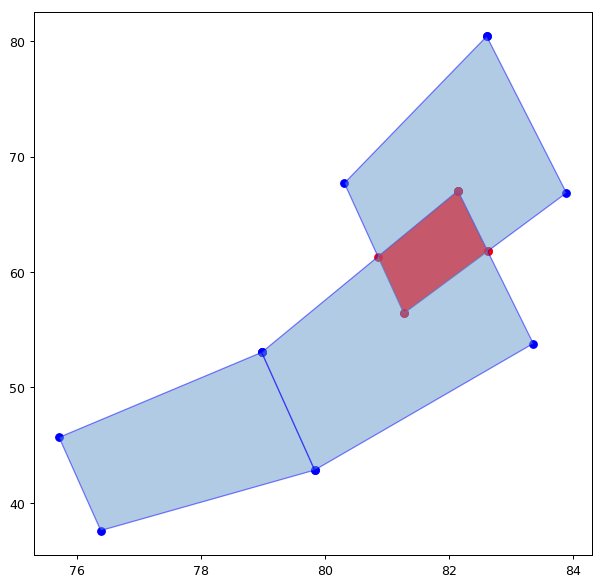

Successful overlap:
['S1A_EW_GRDH_1SSH_20141017T033724_20141017T033813_002864_0033CE_673B.zip']
with
['S1A_EW_GRDH_1SDH_20141018T041843_20141018T041947_002879_00341F_4E6A.zip', 'S1A_EW_GRDH_1SDH_20141018T041947_20141018T042047_002879_00341F_82C7.zip']

Time difference is  1 day, 0:41:19
2014-10-17T033724 2014-10-18T041843
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SSH_20141017T033724_20141017T033813_002864_0033CE_673B.zip
False True
no HV data found
2014-10-17 05:16:13 2014-10-17 10:06:07
area of intersection 0.0
cond_area False


2014-10-17 05:16:13 2014-10-17 13:22:33
area of intersection 30.8274826458
cond_area True
Images overlap


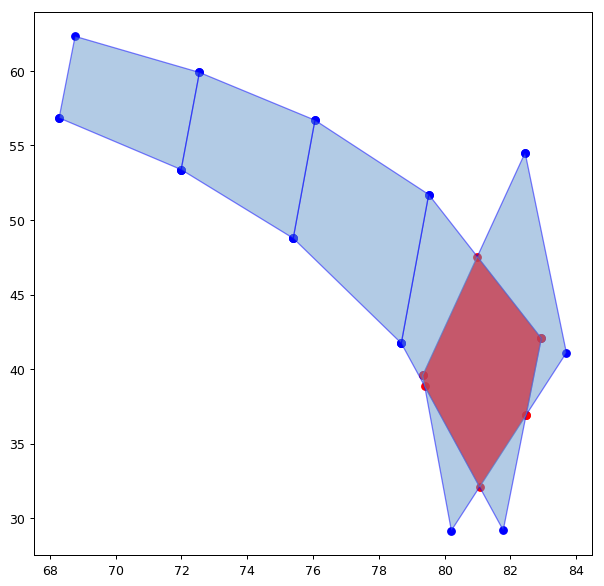

Successful overlap:
['S1A_EW_GRDH_1SDH_20141017T051613_20141017T051717_002865_0033D4_7D01.zip']
with
['S1A_EW_GRDH_1SDH_20141017T132233_20141017T132337_002870_0033EE_33A6.zip', 'S1A_EW_GRDH_1SDH_20141017T132337_20141017T132437_002870_0033EE_E541.zip', 'S1A_EW_GRDH_1SDH_20141017T132437_20141017T132537_002870_0033EE_59B4.zip', 'S1A_EW_GRDH_1SDH_20141017T132537_20141017T132639_002870_0033EE_45E5.zip']

Time difference is  8:06:20
2014-10-17T051613 2014-10-17T132233
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141017T051613_20141017T051717_002865_0033D4_7D01.zip
False True
no HV data found
2014-10-17 10:06:07 2014-10-17 13:22:33
area of intersection 0.0
cond_area False


2014-10-17 10:06:07 2014-10-18 01:01:17
area of intersection 29.6112951037
cond_area True
Images overlap


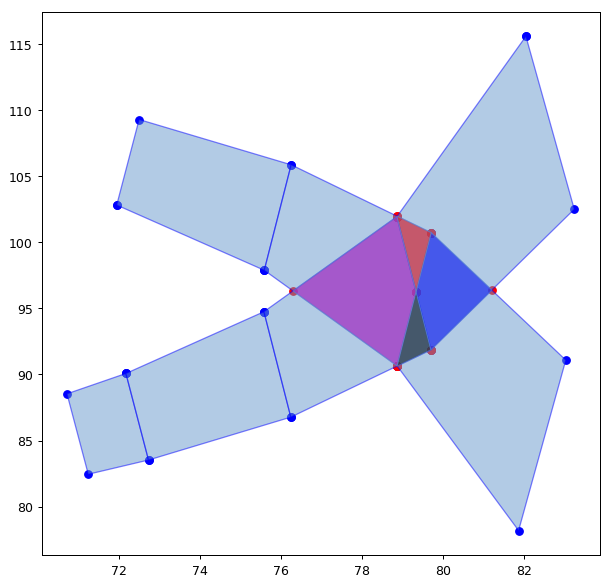

Successful overlap:
['S1A_EW_GRDH_1SDH_20141017T100607_20141017T100711_002868_0033E4_00C2.zip', 'S1A_EW_GRDH_1SDH_20141017T100711_20141017T100811_002868_0033E4_36A0.zip', 'S1A_EW_GRDH_1SDH_20141017T100811_20141017T100911_002868_0033E4_125F.zip']
with
['S1A_EW_GRDH_1SDH_20141018T010117_20141018T010221_002877_003414_3C66.zip', 'S1A_EW_GRDH_1SDH_20141018T010221_20141018T010321_002877_003414_8FC7.zip', 'S1A_EW_GRDH_1SDH_20141018T010321_20141018T010421_002877_003414_2CDD.zip', 'S1A_EW_GRDH_1SDH_20141018T010421_20141018T010446_002877_003414_DC85.zip']

Time difference is  14:55:10
2014-10-17T100607 2014-10-18T010117
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141017T100607_20141017T100711_002868_0033E4_00C2.zip
78.8609619141 90.6418848992 79.6964950562 96.2696585766
71.6395 94.6189 76.4121 111.652
79.329877047 91.8703842163 81.1977492518 100.734970093
71.6395 94.6189 76.4121 111.652
78.8566513062 96.2725506427 79.7024536133 101.983323771
71.6395 9

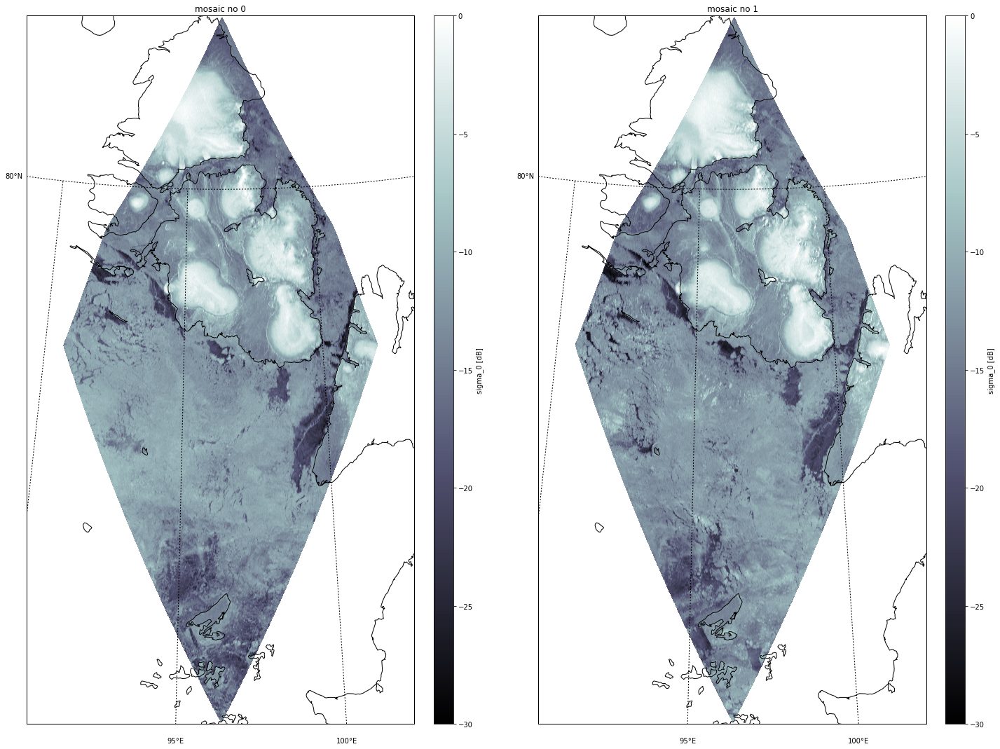

Kara_2014-10-17T100607_2014-10-18T010117_lat-3_lon-2_hh.pickle is created
2014-10-17 13:22:33 2014-10-18 01:01:17
area of intersection 0.0
cond_area False
2014-10-17 13:22:33 2014-10-18 04:18:43
area of intersection 29.7015578699
cond_area True
Images overlap


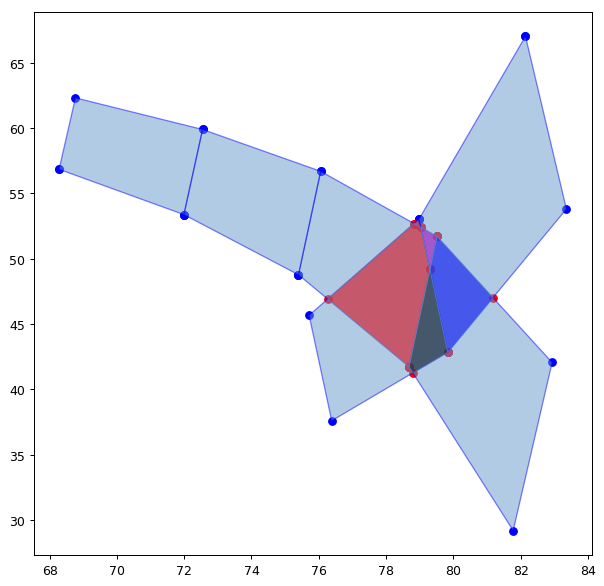

Successful overlap:
['S1A_EW_GRDH_1SDH_20141017T132233_20141017T132337_002870_0033EE_33A6.zip', 'S1A_EW_GRDH_1SDH_20141017T132337_20141017T132437_002870_0033EE_E541.zip', 'S1A_EW_GRDH_1SDH_20141017T132437_20141017T132537_002870_0033EE_59B4.zip', 'S1A_EW_GRDH_1SDH_20141017T132537_20141017T132639_002870_0033EE_45E5.zip']
with
['S1A_EW_GRDH_1SDH_20141018T041843_20141018T041947_002879_00341F_4E6A.zip', 'S1A_EW_GRDH_1SDH_20141018T041947_20141018T042047_002879_00341F_82C7.zip']

Time difference is  14:56:10
2014-10-17T132233 2014-10-18T041843
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141017T132233_20141017T132337_002870_0033EE_33A6.zip
78.6815490723 41.26321762 79.8354034424 49.1848543646
68.0126 50.6409 72.6833 64.2757
79.3040271291 42.8392524719 81.1785969103 51.7079086304
68.0126 50.6409 72.6833 64.2757
76.2652241778 41.735458374 79.3036666574 52.6951210905
68.0126 50.6409 72.6833 64.2757
79.0349037518 49.1891623573 79.514251709 52.3996751652

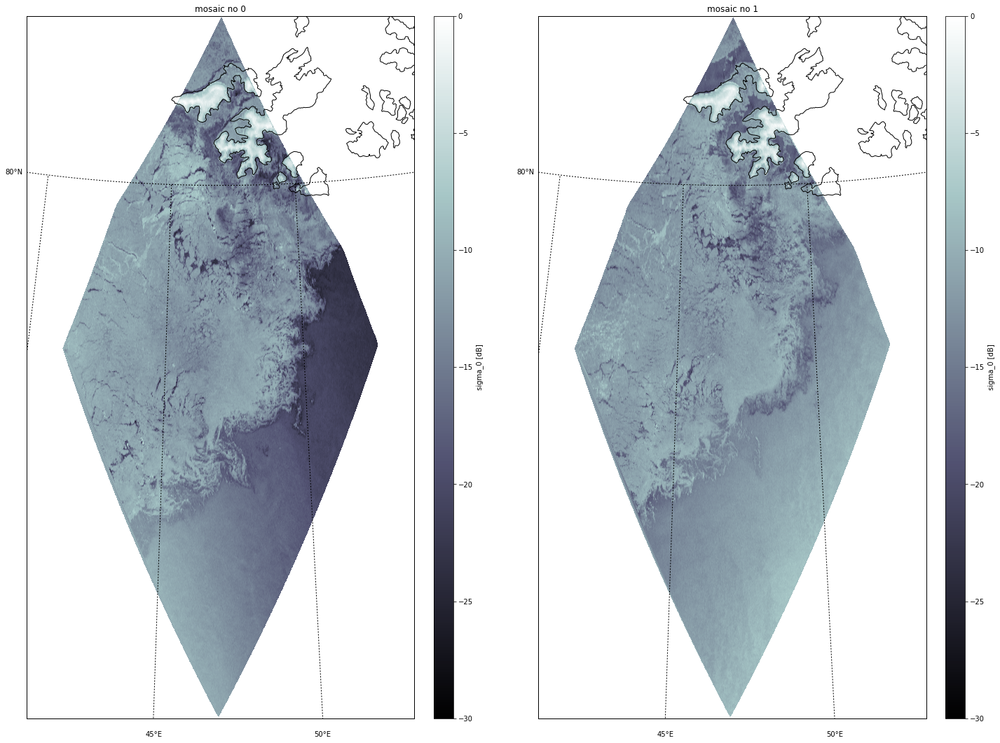

Kara_2014-10-17T132233_2014-10-18T041843_lat-3_lon-2_hh.pickle is created
2014-10-18 01:01:17 2014-10-18 04:18:43
area of intersection 0.0
cond_area False
2014-10-18 01:01:17 2014-10-18 10:49:49
area of intersection 0.0
cond_area False
2014-10-18 01:01:17 2014-10-18 12:25:07
area of intersection 0.0
cond_area False
2014-10-18 01:01:17 2014-10-19 00:03:41
area of intersection 2.19487047237
cond_area True
Images overlap


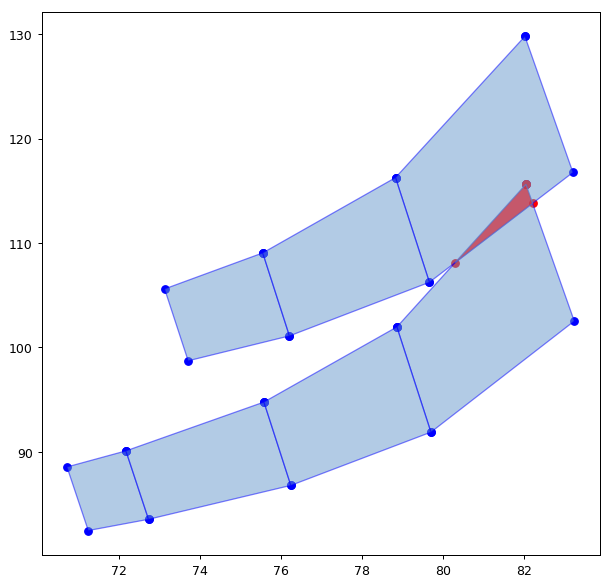

Successful overlap:
['S1A_EW_GRDH_1SDH_20141018T010117_20141018T010221_002877_003414_3C66.zip', 'S1A_EW_GRDH_1SDH_20141018T010221_20141018T010321_002877_003414_8FC7.zip', 'S1A_EW_GRDH_1SDH_20141018T010321_20141018T010421_002877_003414_2CDD.zip', 'S1A_EW_GRDH_1SDH_20141018T010421_20141018T010446_002877_003414_DC85.zip']
with
['S1A_EW_GRDH_1SDH_20141019T000341_20141019T000445_002891_003463_0581.zip', 'S1A_EW_GRDH_1SDH_20141019T000445_20141019T000545_002891_003463_E613.zip', 'S1A_EW_GRDH_1SDH_20141019T000545_20141019T000628_002891_003463_5ECD.zip']

Time difference is  23:02:24
2014-10-18T010117 2014-10-19T000341
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141018T010117_20141018T010221_002877_003414_3C66.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141018T010221_20141018T010321_002877_003414_8FC7.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141018T

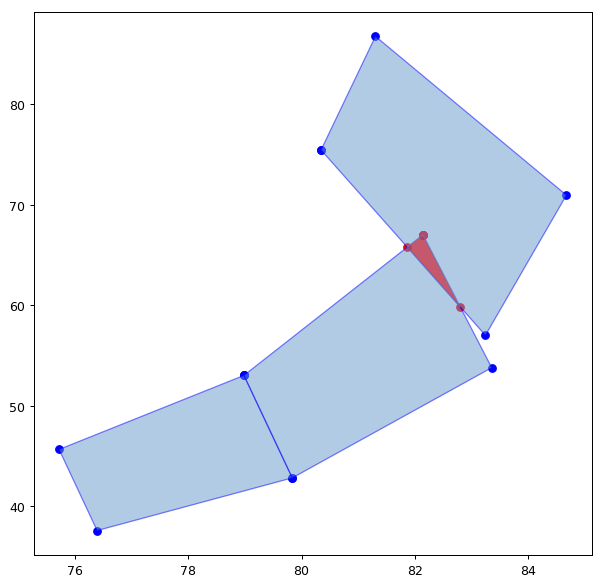

Successful overlap:
['S1A_EW_GRDH_1SDH_20141018T041843_20141018T041947_002879_00341F_4E6A.zip', 'S1A_EW_GRDH_1SDH_20141018T041947_20141018T042047_002879_00341F_82C7.zip']
with
['S1A_EW_GRDH_1SSH_20141018T104949_20141018T105053_002883_003439_D72E.zip']

Time difference is  6:31:06
2014-10-18T041843 2014-10-18T104949
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141018T041843_20141018T041947_002879_00341F_4E6A.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141018T041947_20141018T042047_002879_00341F_82C7.zip
False True
no HV data found
2014-10-18 10:49:49 2014-10-18 12:25:07
area of intersection 0.0
cond_area False


2014-10-18 10:49:49 2014-10-19 00:03:41
area of intersection 0.0
cond_area False
2014-10-18 10:49:49 2014-10-19 03:21:08
area of intersection 23.819106266
cond_area True
Images overlap


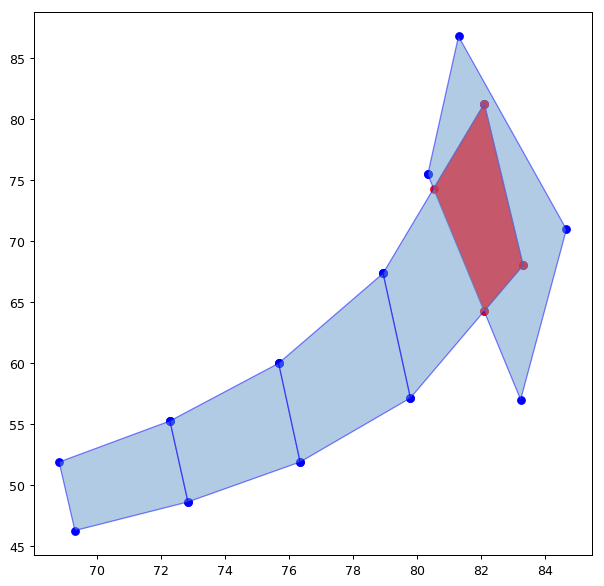

Successful overlap:
['S1A_EW_GRDH_1SSH_20141018T104949_20141018T105053_002883_003439_D72E.zip']
with
['S1A_EW_GRDH_1SDH_20141019T032108_20141019T032212_002893_003471_2B99.zip', 'S1A_EW_GRDH_1SDH_20141019T032212_20141019T032312_002893_003471_96A9.zip', 'S1A_EW_GRDH_1SDH_20141019T032312_20141019T032412_002893_003471_5CCE.zip', 'S1A_EW_GRDH_1SDH_20141019T032412_20141019T032512_002893_003471_01D3.zip']

Time difference is  16:31:19
2014-10-18T104949 2014-10-19T032108
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SSH_20141018T104949_20141018T105053_002883_003439_D72E.zip
False True
no HV data found
2014-10-18 12:25:07 2014-10-19 00:03:41
area of intersection 0.0
cond_area False


2014-10-18 12:25:07 2014-10-19 03:21:08
area of intersection 30.0999702669
cond_area True
Images overlap


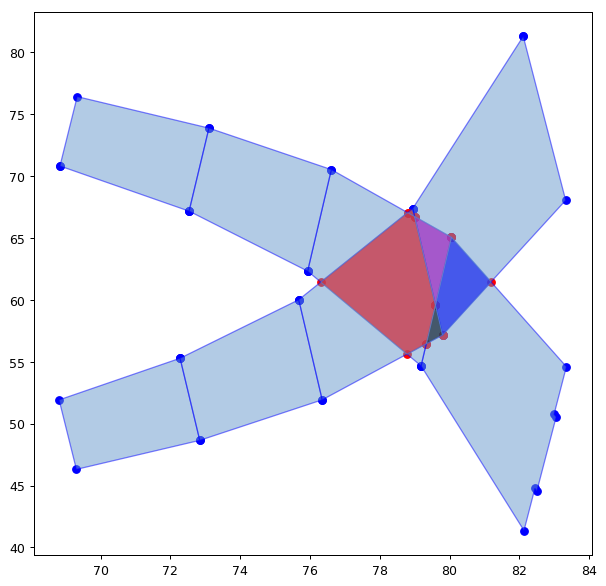

Successful overlap:
['S1A_EW_GRDH_1SDH_20141018T122507_20141018T122611_002884_00343D_3D2D.zip', 'S1A_EW_GRDH_1SDH_20141018T122611_20141018T122711_002884_00343D_E16E.zip', 'S1A_EW_GRDH_1SDH_20141018T122711_20141018T122811_002884_00343D_CAE3.zip', 'S1A_EW_GRDH_1SDH_20141018T122811_20141018T122911_002884_00343D_5891.zip', 'S1A_EW_GRDM_1SDH_20141018T122811_20141018T122911_002884_00343D_E17D.zip']
with
['S1A_EW_GRDH_1SDH_20141019T032108_20141019T032212_002893_003471_2B99.zip', 'S1A_EW_GRDH_1SDH_20141019T032212_20141019T032312_002893_003471_96A9.zip', 'S1A_EW_GRDH_1SDH_20141019T032312_20141019T032412_002893_003471_5CCE.zip', 'S1A_EW_GRDH_1SDH_20141019T032412_20141019T032512_002893_003471_01D3.zip']

Time difference is  14:56:01
2014-10-18T122507 2014-10-19T032108
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141018T122507_20141018T122611_002884_00343D_3D2D.zip
79.334119784 56.4530664788 79.8002166748 59.5869162527
68.5605 64.3456 73.2441 78.4133
79.

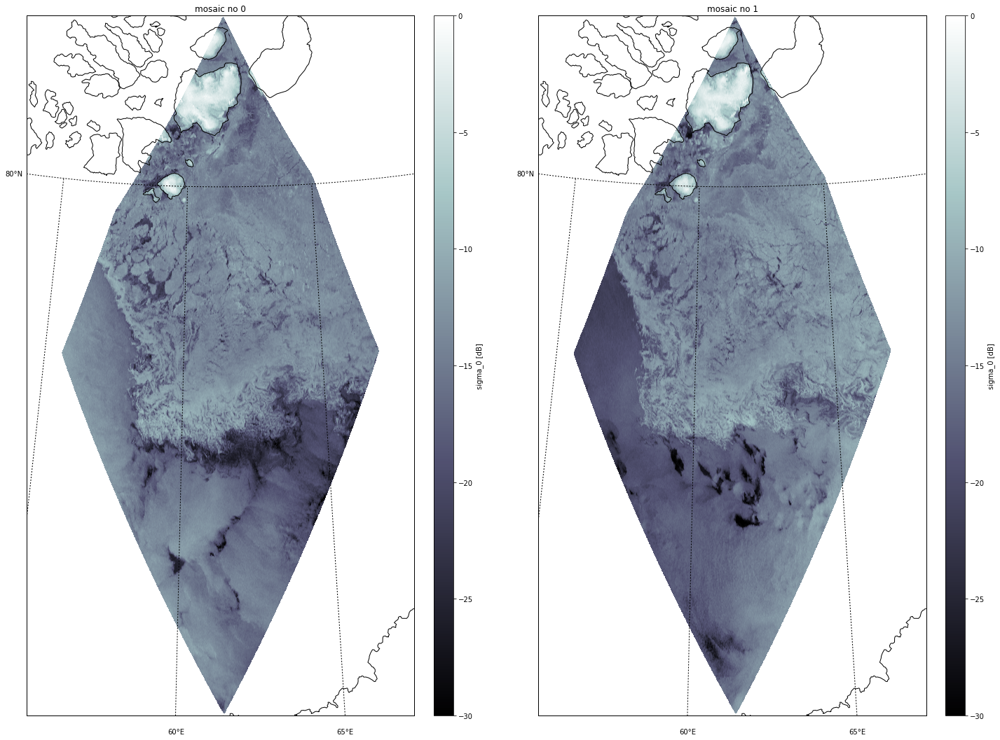

Kara_2014-10-18T122507_2014-10-19T032108_lat-3_lon-2_hh.pickle is created
2014-10-19 00:03:41 2014-10-19 03:21:08
area of intersection 0.0
cond_area False
2014-10-19 00:03:41 2014-10-19 08:13:39
area of intersection 14.4490199009
cond_area True
Images overlap


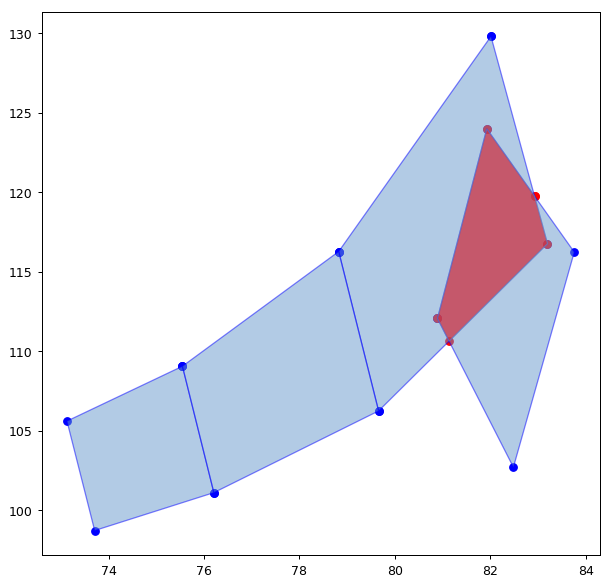

Successful overlap:
['S1A_EW_GRDH_1SDH_20141019T000341_20141019T000445_002891_003463_0581.zip', 'S1A_EW_GRDH_1SDH_20141019T000445_20141019T000545_002891_003463_E613.zip', 'S1A_EW_GRDH_1SDH_20141019T000545_20141019T000628_002891_003463_5ECD.zip']
with
['S1A_EW_GRDH_1SDH_20141019T081339_20141019T081414_002896_00347A_69A9.zip']

Time difference is  8:09:58
2014-10-19T000341 2014-10-19T081339
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141019T000341_20141019T000445_002891_003463_0581.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141019T000445_20141019T000545_002891_003463_E613.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141019T000545_20141019T000628_002891_003463_5ECD.zip
False True
no HV data found
2014-10-19 03:21:08 2014-10-19 08:13:39
area of intersection 0.0
cond_area False


2014-10-19 03:21:08 2014-10-19 09:51:36
area of intersection 0.0875104532953
cond_area False
2014-10-19 03:21:08 2014-10-19 11:28:23
area of intersection 31.4845636852
cond_area True
Images overlap


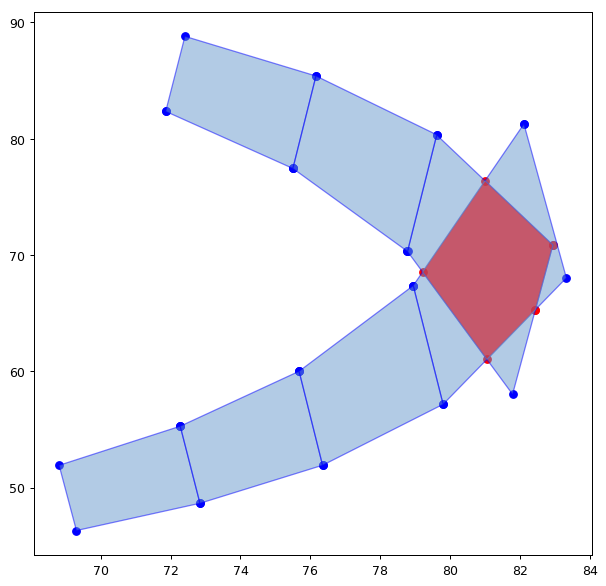

Successful overlap:
['S1A_EW_GRDH_1SDH_20141019T032108_20141019T032212_002893_003471_2B99.zip', 'S1A_EW_GRDH_1SDH_20141019T032212_20141019T032312_002893_003471_96A9.zip', 'S1A_EW_GRDH_1SDH_20141019T032312_20141019T032412_002893_003471_5CCE.zip', 'S1A_EW_GRDH_1SDH_20141019T032412_20141019T032512_002893_003471_01D3.zip']
with
['S1A_EW_GRDH_1SDH_20141019T112823_20141019T112927_002898_003485_02C3.zip', 'S1A_EW_GRDH_1SDH_20141019T112927_20141019T113027_002898_003485_03C9.zip', 'S1A_EW_GRDH_1SDH_20141019T113027_20141019T113127_002898_003485_6A1A.zip']

Time difference is  8:07:15
2014-10-19T032108 2014-10-19T112823
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141019T032108_20141019T032212_002893_003471_2B99.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141019T032212_20141019T032312_002893_003471_96A9.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141019T0

2014-10-19 08:13:39 2014-10-19 11:28:23
area of intersection 0.0
cond_area False
2014-10-19 08:13:39 2014-10-20 00:44:33
area of intersection 29.0524650398
cond_area True
Images overlap


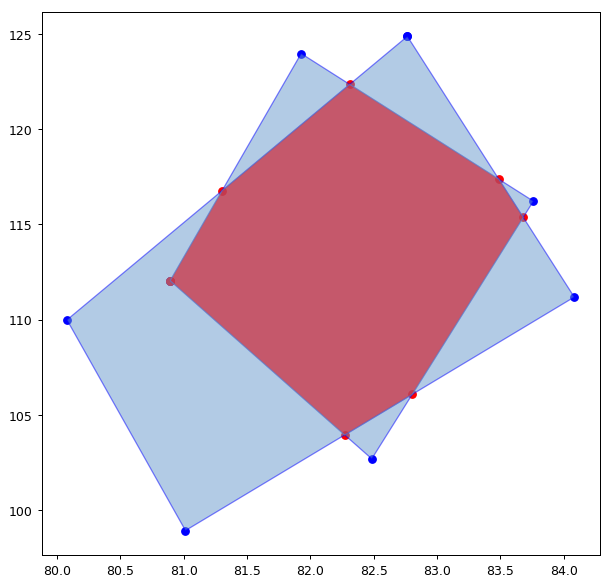

Successful overlap:
['S1A_EW_GRDH_1SDH_20141019T081339_20141019T081414_002896_00347A_69A9.zip']
with
['S1A_EW_GRDH_1SSH_20141020T004433_20141020T004530_002906_0034AB_17B4.zip']

Time difference is  16:30:54
2014-10-19T081339 2014-10-20T004433
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141019T081339_20141019T081414_002896_00347A_69A9.zip
False True
no HV data found
2014-10-19 09:51:36 2014-10-19 11:28:23
area of intersection 0.0
cond_area False


2014-10-19 09:51:36 2014-10-20 00:44:33
area of intersection 0.60826092344
cond_area True
Images overlap


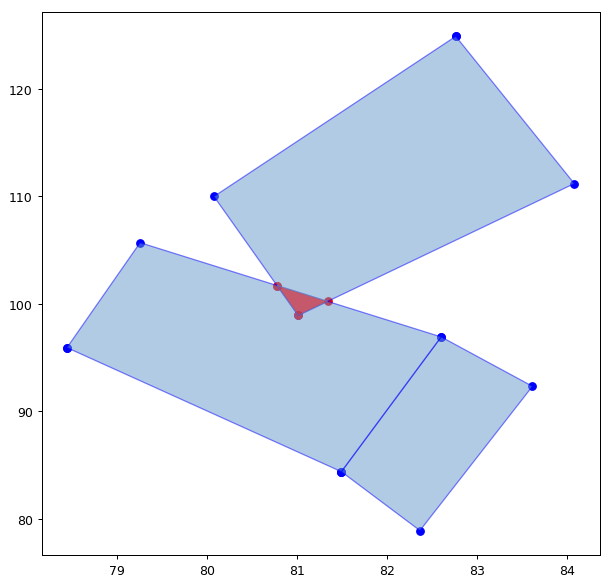

Successful overlap:
['S1A_EW_GRDH_1SDH_20141019T095136_20141019T095236_002897_00347E_D3F4.zip', 'S1A_EW_GRDH_1SDH_20141019T095236_20141019T095255_002897_00347E_2076.zip']
with
['S1A_EW_GRDH_1SSH_20141020T004433_20141020T004530_002906_0034AB_17B4.zip']

Time difference is  14:52:57
2014-10-19T095136 2014-10-20T004433
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141019T095136_20141019T095236_002897_00347E_D3F4.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141019T095236_20141019T095255_002897_00347E_2076.zip
False True
no HV data found
2014-10-19 11:28:23 2014-10-20 00:44:33
area of intersection 0.0
cond_area False


2014-10-19 11:28:23 2014-10-20 02:23:29
area of intersection 29.8527109747
cond_area True
Images overlap


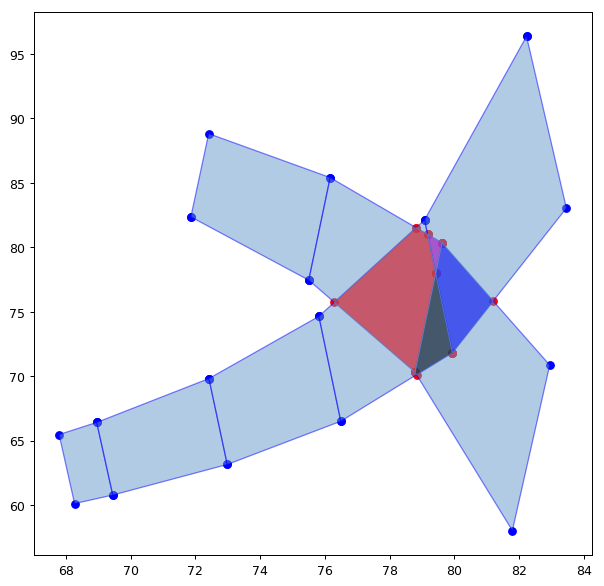

Successful overlap:
['S1A_EW_GRDH_1SDH_20141019T112823_20141019T112927_002898_003485_02C3.zip', 'S1A_EW_GRDH_1SDH_20141019T112927_20141019T113027_002898_003485_03C9.zip', 'S1A_EW_GRDH_1SDH_20141019T113027_20141019T113127_002898_003485_6A1A.zip']
with
['S1A_EW_GRDH_1SDH_20141020T022329_20141020T022433_002907_0034B4_CA9D.zip', 'S1A_EW_GRDH_1SDH_20141020T022433_20141020T022533_002907_0034B4_E0E7.zip', 'S1A_EW_GRDH_1SDH_20141020T022533_20141020T022633_002907_0034B4_040B.zip', 'S1A_EW_GRDH_1SDH_20141020T022633_20141020T022733_002907_0034B4_5D91.zip', 'S1A_EW_GRDH_1SDH_20141020T022733_20141020T022753_002907_0034B4_C559.zip']

Time difference is  14:55:06
2014-10-19T112823 2014-10-20T022329
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141019T112823_20141019T112927_002898_003485_02C3.zip
78.7810211182 70.1100395802 79.9382095337 77.9852474898
71.5534 74.1851 76.3234 91.1446
79.4220031215 71.8206481934 81.1958196602 80.3237991333
71.5534 74.1851 76.32

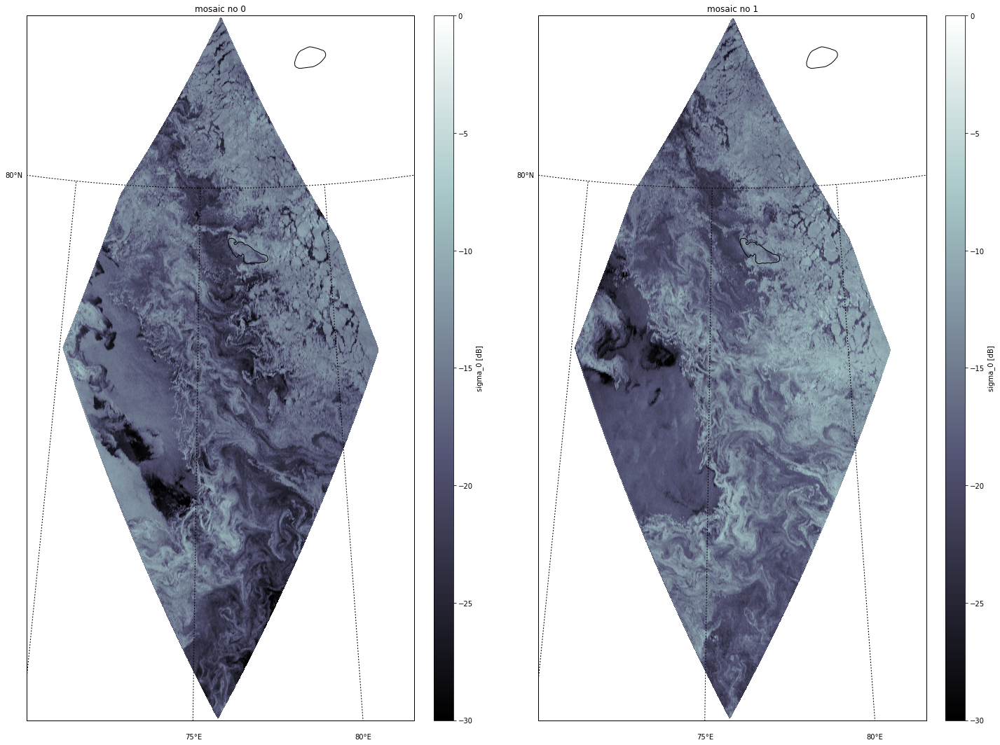

Kara_2014-10-19T112823_2014-10-20T022329_lat-3_lon-2_hh.pickle is created
2014-10-20 00:44:33 2014-10-20 02:23:29
area of intersection 0.0
cond_area False
2014-10-20 00:44:33 2014-10-20 04:01:49
area of intersection 0.0
cond_area False
2014-10-20 00:44:33 2014-10-20 10:31:12
area of intersection 0.0
cond_area False
2014-10-20 00:44:33 2014-10-20 13:47:04
area of intersection 0.0
cond_area False
2014-10-20 00:44:33 2014-10-21 01:25:57
area of intersection 9.20787816762
cond_area True
Images overlap


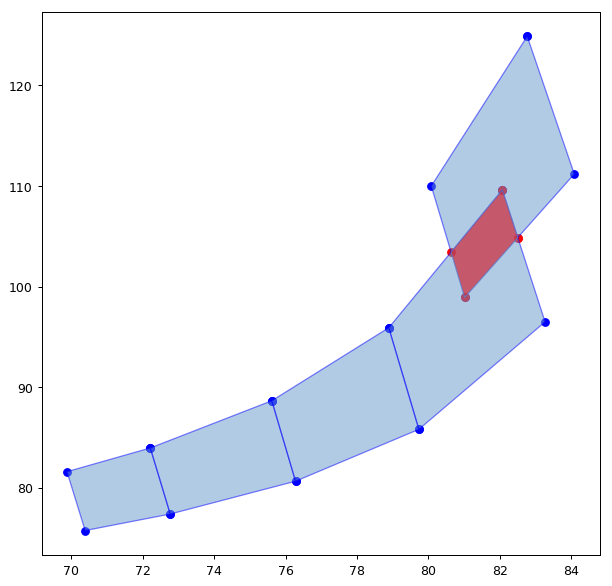

Successful overlap:
['S1A_EW_GRDH_1SSH_20141020T004433_20141020T004530_002906_0034AB_17B4.zip']
with
['S1A_EW_GRDH_1SDH_20141021T012557_20141021T012701_002921_003501_018A.zip', 'S1A_EW_GRDH_1SDH_20141021T012701_20141021T012801_002921_003501_BC91.zip', 'S1A_EW_GRDH_1SDH_20141021T012801_20141021T012901_002921_003501_FC68.zip', 'S1A_EW_GRDH_1SDH_20141021T012901_20141021T012941_002921_003501_3E82.zip']

Time difference is  1 day, 0:41:24
2014-10-20T004433 2014-10-21T012557
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SSH_20141020T004433_20141020T004530_002906_0034AB_17B4.zip
False True
no HV data found
2014-10-20 02:23:29 2014-10-20 04:01:49
area of intersection 0.0
cond_area False


2014-10-20 02:23:29 2014-10-20 10:31:12
area of intersection 31.5557587756
cond_area True
Images overlap


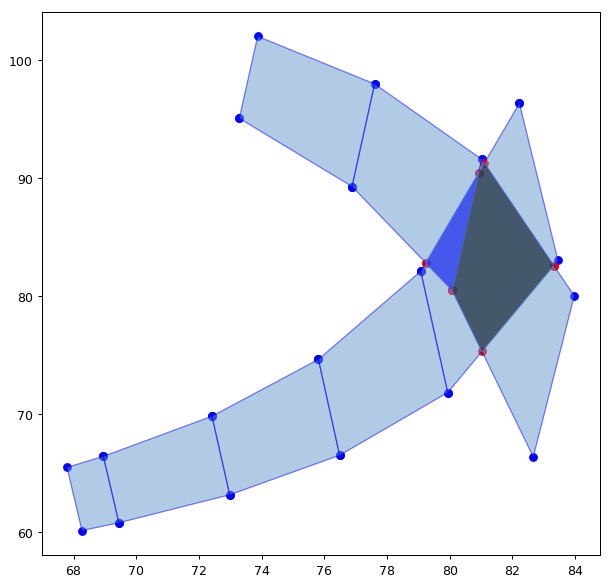

Successful overlap:
['S1A_EW_GRDH_1SDH_20141020T022329_20141020T022433_002907_0034B4_CA9D.zip', 'S1A_EW_GRDH_1SDH_20141020T022433_20141020T022533_002907_0034B4_E0E7.zip', 'S1A_EW_GRDH_1SDH_20141020T022533_20141020T022633_002907_0034B4_040B.zip', 'S1A_EW_GRDH_1SDH_20141020T022633_20141020T022733_002907_0034B4_5D91.zip', 'S1A_EW_GRDH_1SDH_20141020T022733_20141020T022753_002907_0034B4_C559.zip']
with
['S1A_EW_GRDH_1SDH_20141020T103112_20141020T103216_002912_0034D0_2F9E.zip', 'S1A_EW_GRDH_1SDH_20141020T103216_20141020T103316_002912_0034D0_BD09.zip', 'S1A_EW_GRDH_1SDH_20141020T103316_20141020T103411_002912_0034D0_C6F2.zip']

Time difference is  8:07:43
2014-10-20T022329 2014-10-20T103112
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141020T022329_20141020T022433_002907_0034B4_CA9D.zip
80.081741333 75.3053213729 83.3199887283 91.2898495903
78.6033 67.862 83.7809 100.892
79.2358888219 80.5000610352 80.92795427 90.4827235499
78.6033 67.862 83.7809 100

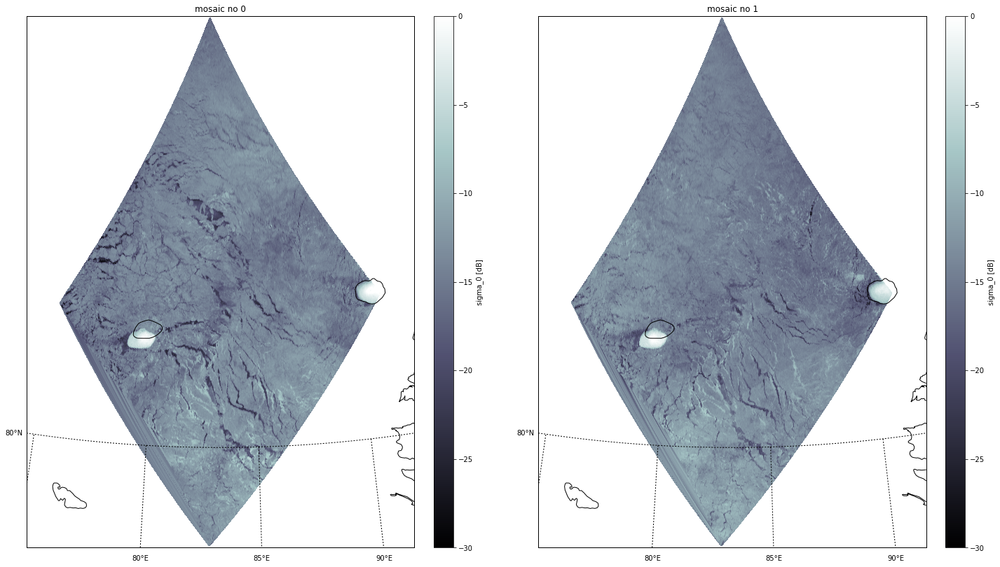

Kara_2014-10-20T022329_2014-10-20T103112_lat-3_lon-2_hh.pickle is created
2014-10-20 04:01:49 2014-10-20 10:31:12
area of intersection 10.7922850084
cond_area True
Images overlap


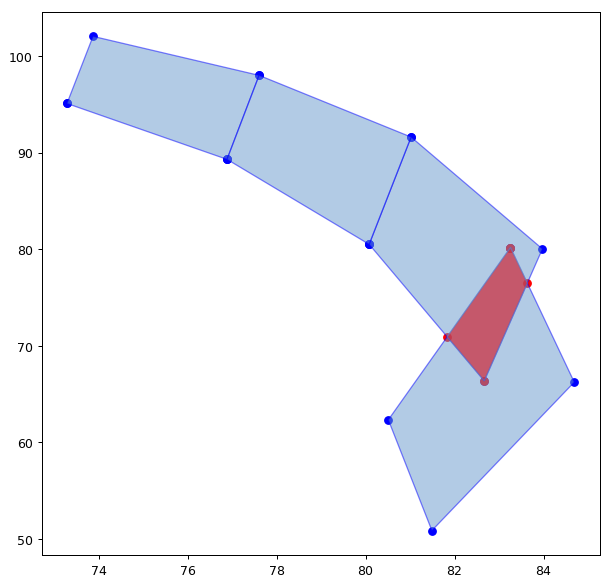

Successful overlap:
['S1A_EW_GRDH_1SSH_20141020T040149_20141020T040250_002908_0034B9_4171.zip']
with
['S1A_EW_GRDH_1SDH_20141020T103112_20141020T103216_002912_0034D0_2F9E.zip', 'S1A_EW_GRDH_1SDH_20141020T103216_20141020T103316_002912_0034D0_BD09.zip', 'S1A_EW_GRDH_1SDH_20141020T103316_20141020T103411_002912_0034D0_C6F2.zip']

Time difference is  6:29:23
2014-10-20T040149 2014-10-20T103112
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SSH_20141020T040149_20141020T040250_002908_0034B9_4171.zip
False True
no HV data found
2014-10-20 10:31:12 2014-10-20 13:47:04
area of intersection 0.0
cond_area False


2014-10-20 10:31:12 2014-10-21 01:25:57
area of intersection 29.7638691218
cond_area True
Images overlap


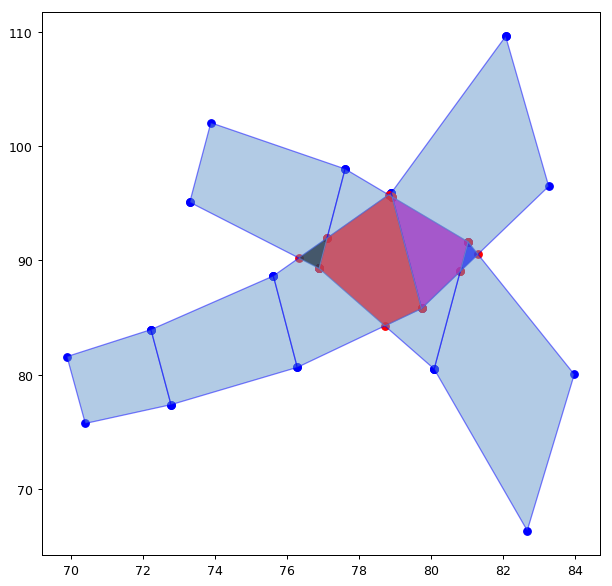

Successful overlap:
['S1A_EW_GRDH_1SDH_20141020T103112_20141020T103216_002912_0034D0_2F9E.zip', 'S1A_EW_GRDH_1SDH_20141020T103216_20141020T103316_002912_0034D0_BD09.zip', 'S1A_EW_GRDH_1SDH_20141020T103316_20141020T103411_002912_0034D0_C6F2.zip']
with
['S1A_EW_GRDH_1SDH_20141021T012557_20141021T012701_002921_003501_018A.zip', 'S1A_EW_GRDH_1SDH_20141021T012701_20141021T012801_002921_003501_BC91.zip', 'S1A_EW_GRDH_1SDH_20141021T012801_20141021T012901_002921_003501_FC68.zip', 'S1A_EW_GRDH_1SDH_20141021T012901_20141021T012941_002921_003501_3E82.zip']

Time difference is  14:54:45
2014-10-20T103112 2014-10-21T012557
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141020T103112_20141020T103216_002912_0034D0_2F9E.zip
76.3223022984 89.3036880493 77.1050215439 91.9453868215
72.9623 85.7917 77.7833 104.576
80.8068125278 89.0484654813 81.2984940802 91.6124572754
72.9623 85.7917 77.7833 104.576
76.8863601685 84.2733469758 79.7308502197 95.7397391465
72.9623 

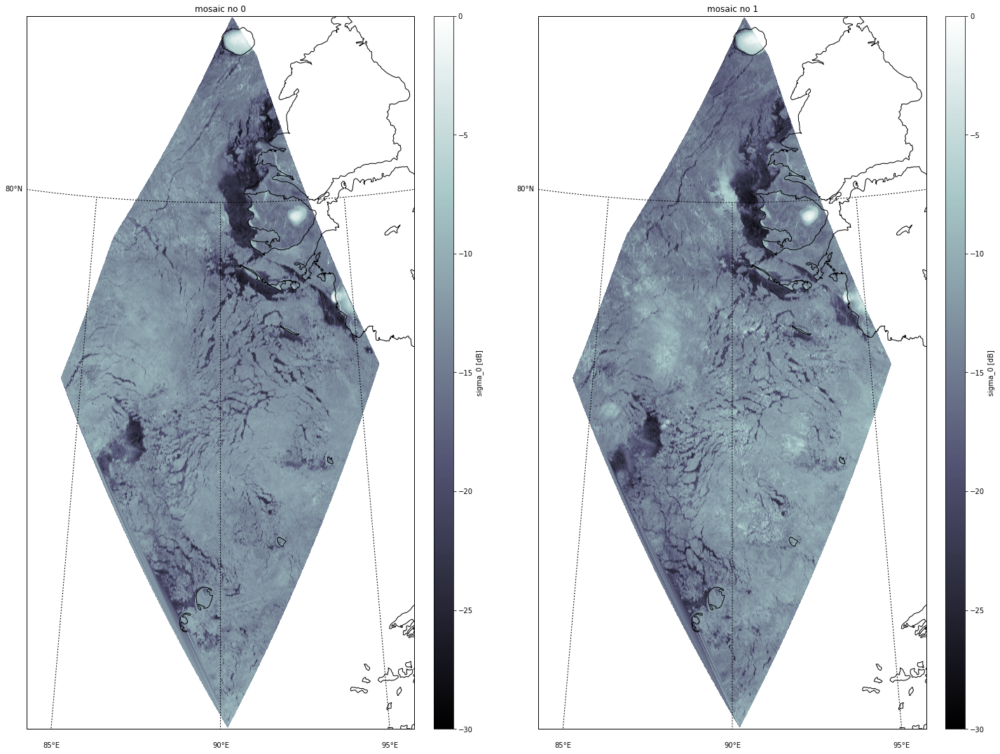

Kara_2014-10-20T103112_2014-10-21T012557_lat-3_lon-2_hh.pickle is created
2014-10-20 13:47:04 2014-10-21 01:25:57
area of intersection 0.0
cond_area False
2014-10-20 13:47:04 2014-10-21 04:43:21
area of intersection 0.0
cond_area False
2014-10-20 13:47:04 2014-10-21 11:14:38
area of intersection 0.0
cond_area False
2014-10-20 13:47:04 2014-10-22 00:28:22
area of intersection 0.0
cond_area False
2014-10-20 13:47:04 2014-10-22 03:45:48
area of intersection 27.750249935
cond_area True
Images overlap


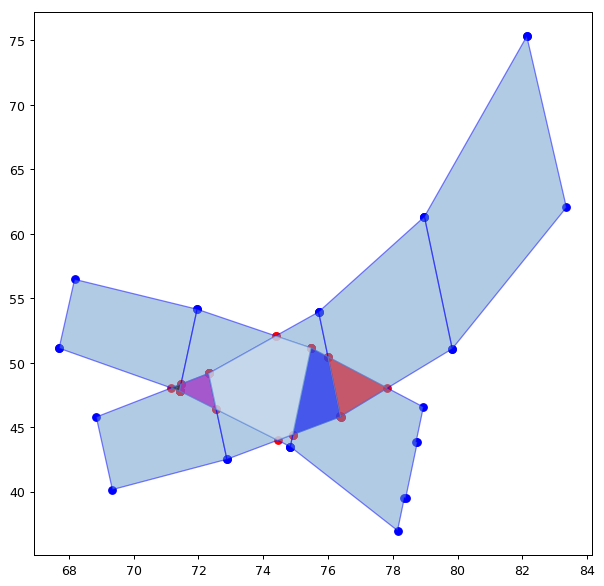

Successful overlap:
['S1A_EW_GRDH_1SDH_20141020T134704_20141020T134809_002914_0034DC_5B9F.zip', 'S1A_EW_GRDH_1SDH_20141020T134809_20141020T134909_002914_0034DC_88DC.zip', 'S1A_EW_GRDH_1SDH_20141020T134909_20141020T135009_002914_0034DC_7086.zip', 'S1A_EW_GRDM_1SDH_20141020T134909_20141020T135009_002914_0034DC_EF96.zip']
with
['S1A_EW_GRDH_1SDH_20141022T034548_20141022T034652_002937_003558_9D11.zip', 'S1A_EW_GRDH_1SDH_20141022T034652_20141022T034752_002937_003558_7345.zip', 'S1A_EW_GRDH_1SDH_20141022T034752_20141022T034852_002937_003558_BB46.zip', 'S1A_EW_GRDH_1SDH_20141022T034852_20141022T034952_002937_003558_C769.zip']

Time difference is  1 day, 13:58:44
2014-10-20T134704 2014-10-22T034548
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141020T134704_20141020T134809_002914_0034DC_5B9F.zip
71.1599537005 47.8134727478 71.4599085774 48.3331081457
67.434 45.1428 72.0924 58.3776
74.9137035054 44.4254370736 76.3864059448 51.1448173523
67.434 45.1428 

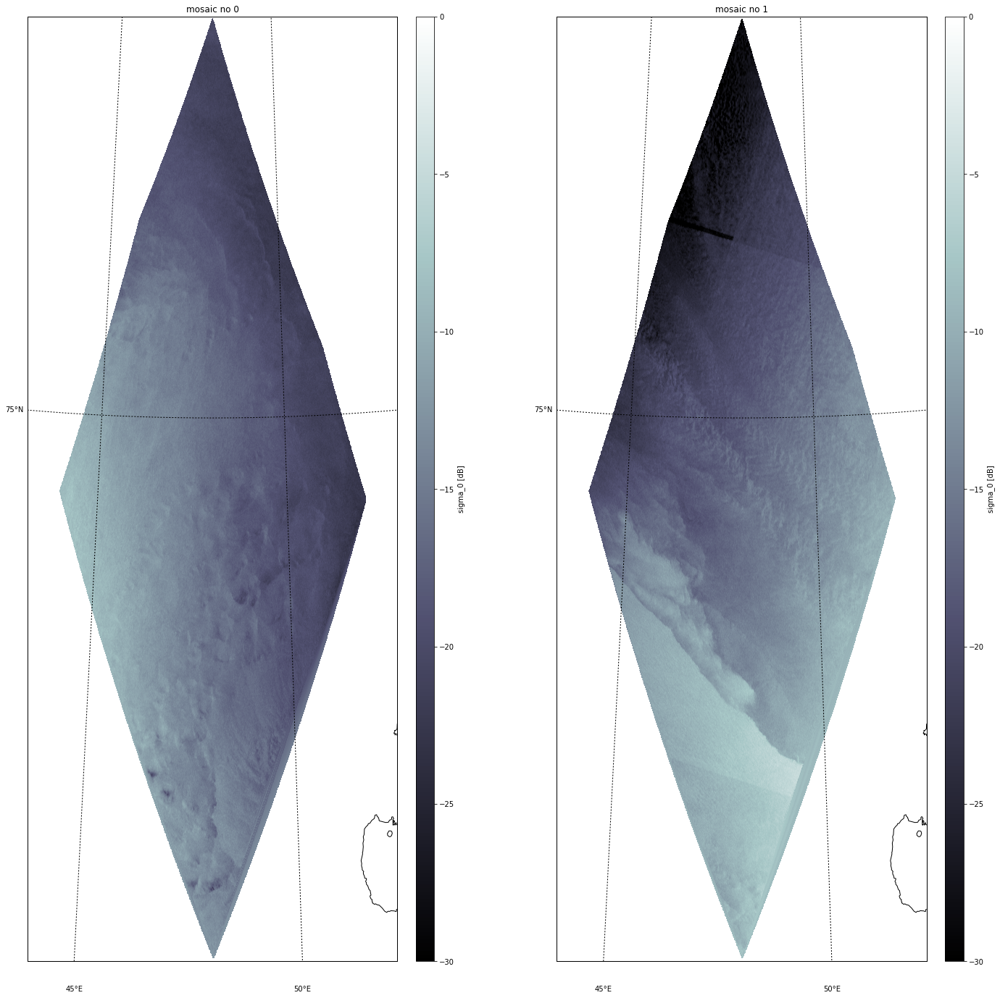

Kara_2014-10-20T134704_2014-10-22T034548_lat-3_lon-2_hh.pickle is created
2014-10-21 01:25:57 2014-10-21 04:43:21
area of intersection 0.0
cond_area False
2014-10-21 01:25:57 2014-10-21 11:14:38
area of intersection 0.0
cond_area False
2014-10-21 01:25:57 2014-10-22 00:28:22
area of intersection 2.32729774107
cond_area True
Images overlap


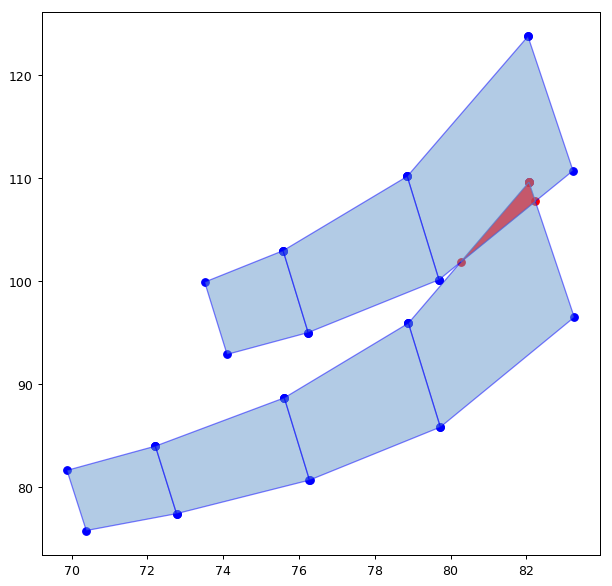

Successful overlap:
['S1A_EW_GRDH_1SDH_20141021T012557_20141021T012701_002921_003501_018A.zip', 'S1A_EW_GRDH_1SDH_20141021T012701_20141021T012801_002921_003501_BC91.zip', 'S1A_EW_GRDH_1SDH_20141021T012801_20141021T012901_002921_003501_FC68.zip', 'S1A_EW_GRDH_1SDH_20141021T012901_20141021T012941_002921_003501_3E82.zip']
with
['S1A_EW_GRDH_1SDH_20141022T002822_20141022T002926_002935_003546_D115.zip', 'S1A_EW_GRDH_1SDH_20141022T002926_20141022T003026_002935_003546_9F86.zip', 'S1A_EW_GRDH_1SDH_20141022T003026_20141022T003102_002935_003546_620E.zip']

Time difference is  23:02:25
2014-10-21T012557 2014-10-22T002822
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141021T012557_20141021T012701_002921_003501_018A.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141021T012701_20141021T012801_002921_003501_BC91.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141021T

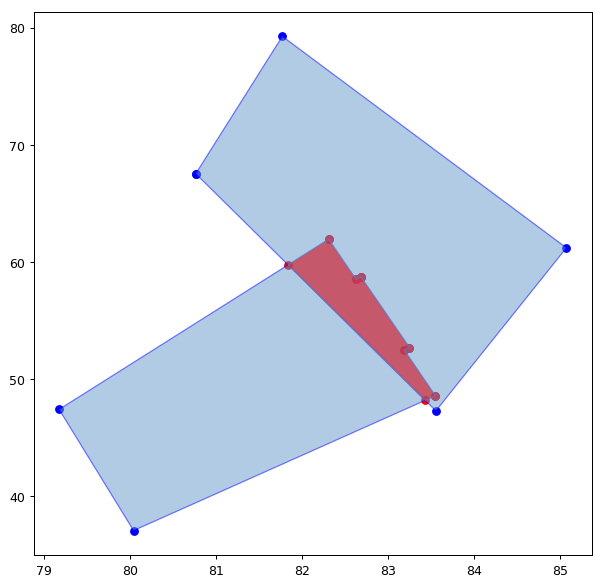

Successful overlap:
['S1A_EW_GRDM_1SDH_20141021T044321_20141021T044425_002923_00350B_488E.zip', 'S1A_EW_GRDH_1SDH_20141021T044321_20141021T044425_002923_00350B_BD32.zip']
with
['S1A_EW_GRDH_1SSH_20141021T111438_20141021T111542_002927_003521_9FAC.zip']

Time difference is  6:31:17
2014-10-21T044321 2014-10-21T111438
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141021T044321_20141021T044425_002923_00350B_488E.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141021T044321_20141021T044425_002923_00350B_BD32.zip
False True
no HV data found
2014-10-21 11:14:38 2014-10-22 00:28:22
area of intersection 0.0
cond_area False


2014-10-21 11:14:38 2014-10-22 03:45:48
area of intersection 23.5325091583
cond_area True
Images overlap


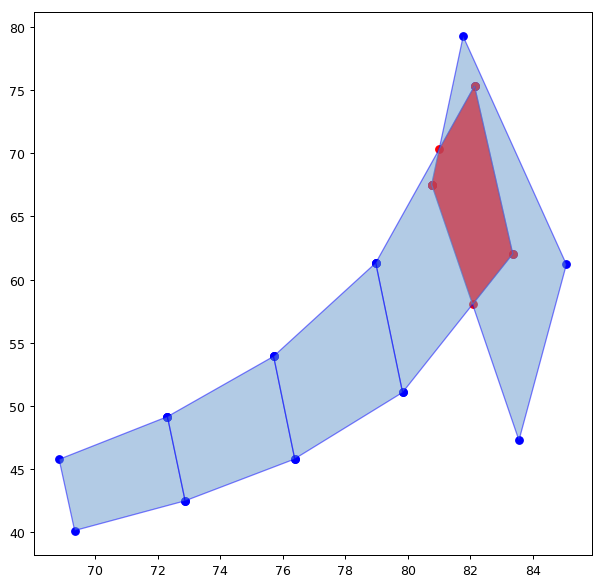

Successful overlap:
['S1A_EW_GRDH_1SSH_20141021T111438_20141021T111542_002927_003521_9FAC.zip']
with
['S1A_EW_GRDH_1SDH_20141022T034548_20141022T034652_002937_003558_9D11.zip', 'S1A_EW_GRDH_1SDH_20141022T034652_20141022T034752_002937_003558_7345.zip', 'S1A_EW_GRDH_1SDH_20141022T034752_20141022T034852_002937_003558_BB46.zip', 'S1A_EW_GRDH_1SDH_20141022T034852_20141022T034952_002937_003558_C769.zip']

Time difference is  16:31:10
2014-10-21T111438 2014-10-22T034548
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SSH_20141021T111438_20141021T111542_002927_003521_9FAC.zip
False True
no HV data found
2014-10-22 00:28:22 2014-10-22 03:45:48
area of intersection 0.0
cond_area False


2014-10-22 00:28:22 2014-10-22 08:37:14
area of intersection 32.6220658026
cond_area True
Images overlap


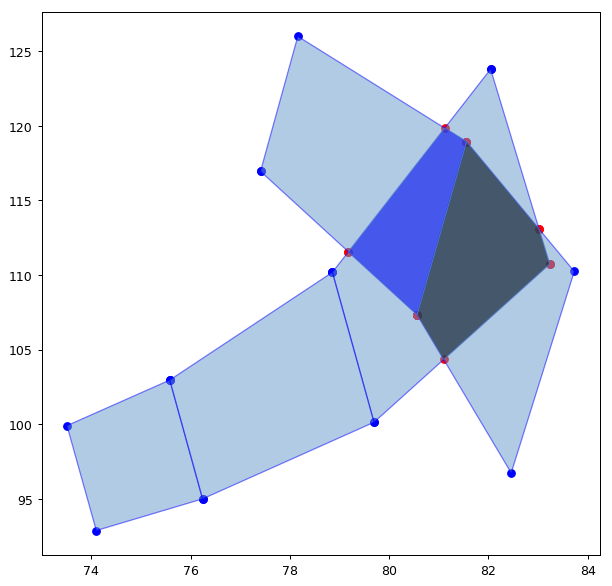

Successful overlap:
['S1A_EW_GRDH_1SDH_20141022T002822_20141022T002926_002935_003546_D115.zip', 'S1A_EW_GRDH_1SDH_20141022T002926_20141022T003026_002935_003546_9F86.zip', 'S1A_EW_GRDH_1SDH_20141022T003026_20141022T003102_002935_003546_620E.zip']
with
['S1A_EW_GRDH_1SDH_20141022T083714_20141022T083814_002940_00356C_3931.zip', 'S1A_EW_GRDH_1SDH_20141022T083814_20141022T083854_002940_00356C_23BD.zip']

Time difference is  8:08:52
2014-10-22T002822 2014-10-22T083714
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141022T002822_20141022T002926_002935_003546_D115.zip
80.5621795654 104.33662838 83.2325134277 118.937805176
78.3957 96.2788 83.5441 128.319
79.1791744278 107.341629028 81.5572128296 119.849551319
78.3957 96.2788 83.5441 128.319
False False
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141022T002926_20141022T003026_002935_003546_9F86.zip
80.5621795654 104.33662838 83.2325134277 118.937805176
75.2124 92.0514 7

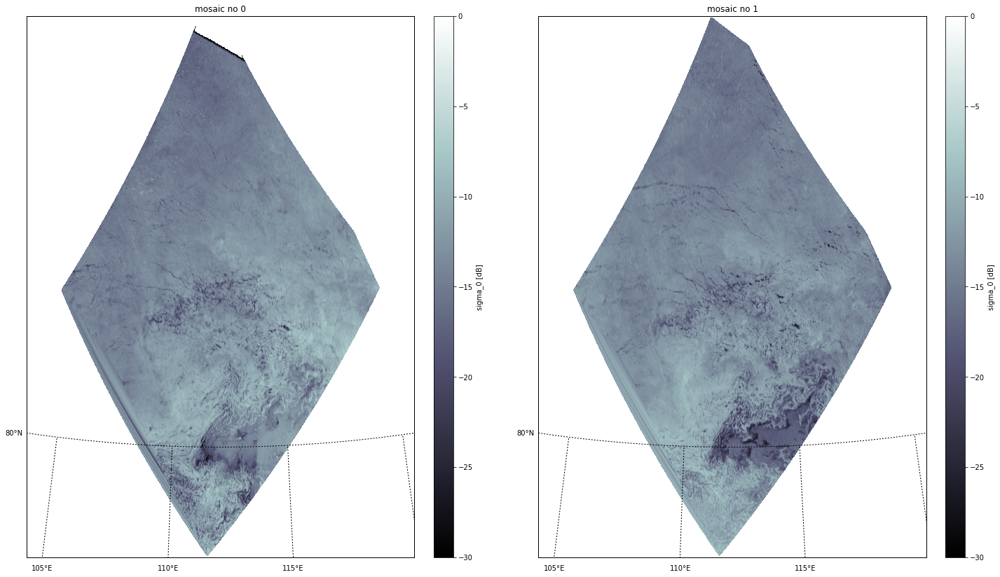

Kara_2014-10-22T002822_2014-10-22T083714_lat-3_lon-2_hh.pickle is created
2014-10-22 03:45:48 2014-10-22 08:37:14
area of intersection 0.0
cond_area False
2014-10-22 03:45:48 2014-10-22 11:52:55
area of intersection 33.3537986033
cond_area True
Images overlap


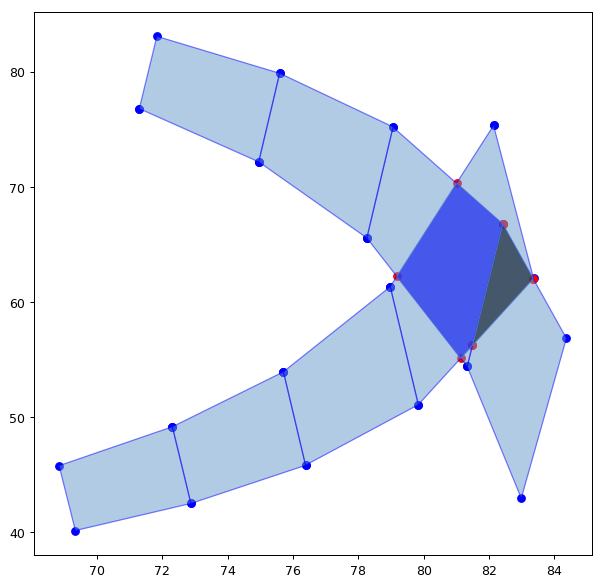

Successful overlap:
['S1A_EW_GRDH_1SDH_20141022T034548_20141022T034652_002937_003558_9D11.zip', 'S1A_EW_GRDH_1SDH_20141022T034652_20141022T034752_002937_003558_7345.zip', 'S1A_EW_GRDH_1SDH_20141022T034752_20141022T034852_002937_003558_BB46.zip', 'S1A_EW_GRDH_1SDH_20141022T034852_20141022T034952_002937_003558_C769.zip']
with
['S1A_EW_GRDH_1SDH_20141022T115255_20141022T115359_002942_00357A_39D8.zip', 'S1A_EW_GRDH_1SDH_20141022T115359_20141022T115459_002942_00357A_B60C.zip', 'S1A_EW_GRDH_1SDH_20141022T115459_20141022T115559_002942_00357A_7E3C.zip', 'S1A_EW_GRDH_1SDH_20141022T115559_20141022T115636_002942_00357A_F3AE.zip']

Time difference is  8:07:07
2014-10-22T034548 2014-10-22T115255
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141022T034548_20141022T034652_002937_003558_9D11.zip
81.4921007269 56.2310117468 83.3504445802 66.7572250366
78.5008 47.1348 83.682 79.8579
79.1788654064 55.1153881982 82.417427063 70.299350295
78.5008 47.1348 83.682 79

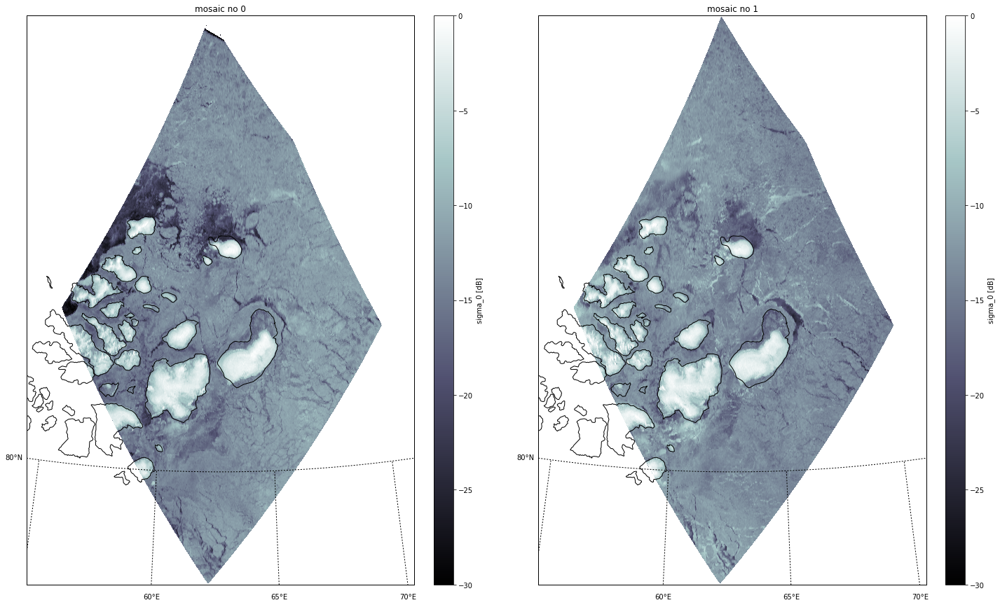

Kara_2014-10-22T034548_2014-10-22T115255_lat-3_lon-2_hh.pickle is created
2014-10-22 08:37:14 2014-10-22 11:52:55
area of intersection 0.0
cond_area False
2014-10-22 08:37:14 2014-10-22 23:32:54
area of intersection 0.0
cond_area False
2014-10-22 08:37:14 2014-10-23 01:09:10
area of intersection 30.0895559233
cond_area True
Images overlap


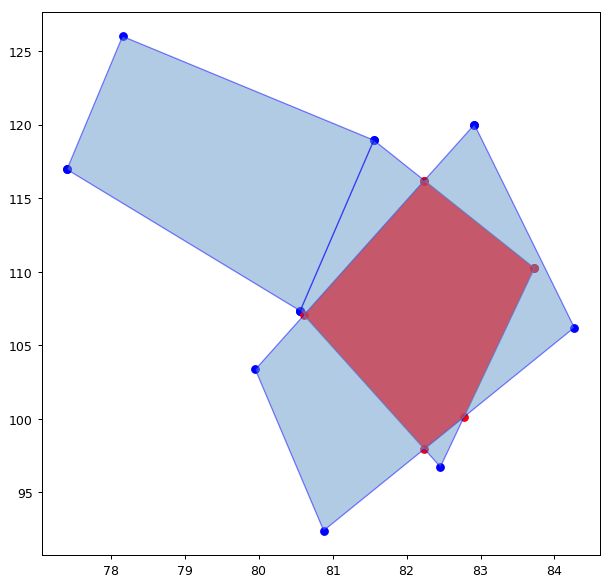

Successful overlap:
['S1A_EW_GRDH_1SDH_20141022T083714_20141022T083814_002940_00356C_3931.zip', 'S1A_EW_GRDH_1SDH_20141022T083814_20141022T083854_002940_00356C_23BD.zip']
with
['S1A_EW_GRDH_1SSH_20141023T010910_20141023T011014_002950_00359C_FA60.zip']

Time difference is  16:31:56
2014-10-22T083714 2014-10-23T010910
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141022T083714_20141022T083814_002940_00356C_3931.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141022T083814_20141022T083854_002940_00356C_23BD.zip
False True
no HV data found
2014-10-22 11:52:55 2014-10-22 23:32:54
area of intersection 0.0
cond_area False


2014-10-22 11:52:55 2014-10-23 01:09:10
area of intersection 0.0
cond_area False
2014-10-22 11:52:55 2014-10-23 02:48:13
area of intersection 29.3815532058
cond_area True
Images overlap


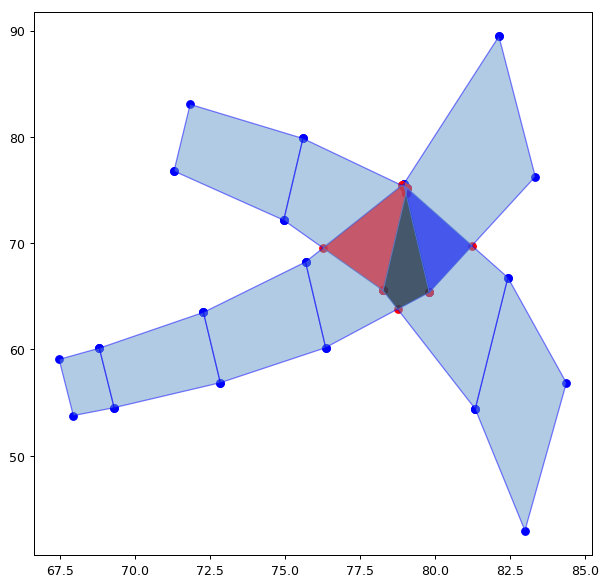

Successful overlap:
['S1A_EW_GRDH_1SDH_20141022T115255_20141022T115359_002942_00357A_39D8.zip', 'S1A_EW_GRDH_1SDH_20141022T115359_20141022T115459_002942_00357A_B60C.zip', 'S1A_EW_GRDH_1SDH_20141022T115459_20141022T115559_002942_00357A_7E3C.zip', 'S1A_EW_GRDH_1SDH_20141022T115559_20141022T115636_002942_00357A_F3AE.zip']
with
['S1A_EW_GRDH_1SDH_20141023T024813_20141023T024917_002951_0035A4_709A.zip', 'S1A_EW_GRDH_1SDH_20141023T024917_20141023T025017_002951_0035A4_0E9C.zip', 'S1A_EW_GRDH_1SDH_20141023T025017_20141023T025117_002951_0035A4_3D17.zip', 'S1A_EW_GRDH_1SDH_20141023T025117_20141023T025217_002951_0035A4_B794.zip', 'S1A_EW_GRDH_1SDH_20141023T025217_20141023T025240_002951_0035A4_0347.zip']

Time difference is  14:55:18
2014-10-22T115255 2014-10-23T024813
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141022T115255_20141022T115359_002942_00357A_39D8.zip
78.2607803345 63.7900451499 79.8012466431 74.6991790965
70.9996 68.9914 75.7504 85.3185
79

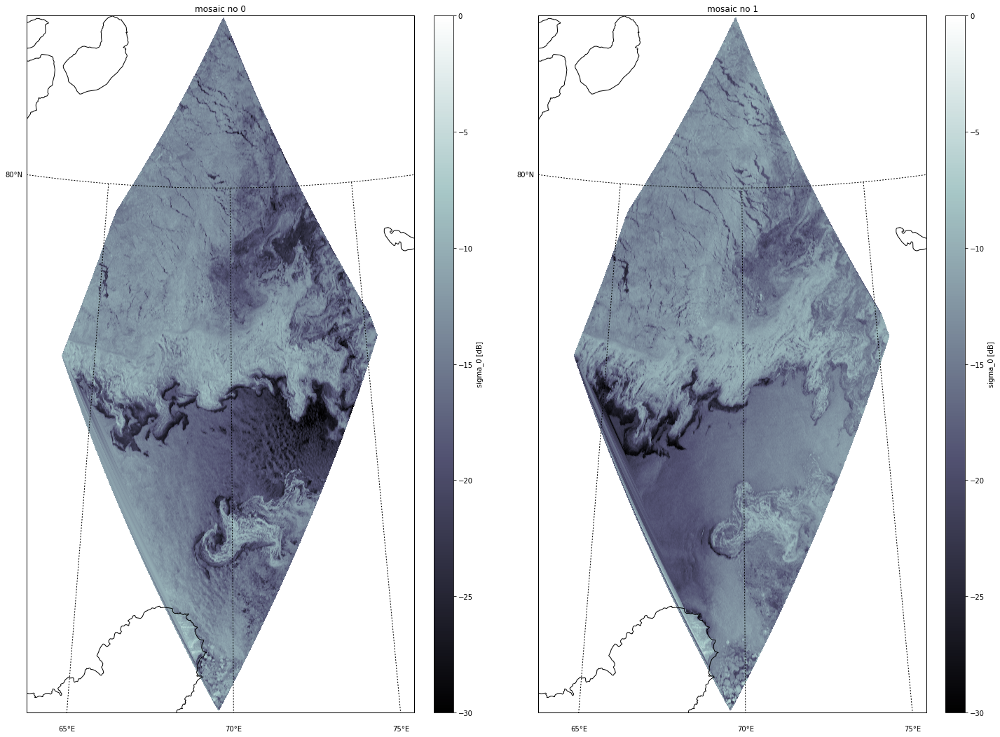

Kara_2014-10-22T115255_2014-10-23T024813_lat-3_lon-2_hh.pickle is created
2014-10-22 23:32:54 2014-10-23 01:09:10
area of intersection 0.0
cond_area False
2014-10-22 23:32:54 2014-10-23 02:48:13
area of intersection 0.0
cond_area False
2014-10-22 23:32:54 2014-10-23 04:26:55
area of intersection 0.0
cond_area False
2014-10-22 23:32:54 2014-10-23 10:57:09
area of intersection 0.0
cond_area False
2014-10-22 23:32:54 2014-10-24 05:07:58
area of intersection 0.0
cond_area False
2014-10-22 23:32:54 2014-10-24 09:58:54
area of intersection 0.0
cond_area False
2014-10-22 23:32:54 2014-10-24 13:14:22
area of intersection 0.0
cond_area False
2014-10-22 23:32:54 2014-10-25 00:52:44
area of intersection 0.0
cond_area False
2014-10-22 23:32:54 2014-10-25 02:31:44
area of intersection 0.0
cond_area False
2014-10-22 23:32:54 2014-10-25 04:09:58
area of intersection 0.0
cond_area False
2014-10-22 23:32:54 2014-10-25 10:41:34
area of intersection 0.0
cond_area False
2014-10-22 23:32:54 2014-10-25 13:5

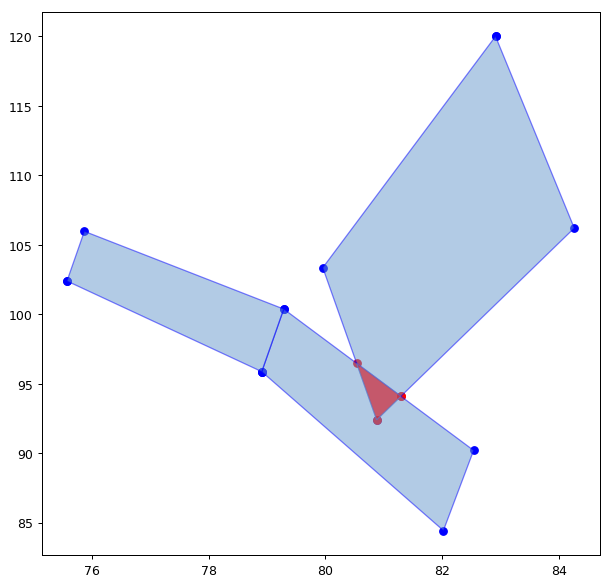

Successful overlap:
['S1A_EW_GRDH_1SSH_20141023T010910_20141023T011014_002950_00359C_FA60.zip']
with
['S1A_EW_GRDM_1SDH_20141024T095854_20141024T095954_002970_003603_BDDA.zip', 'S1A_EW_GRDM_1SDH_20141024T095954_20141024T100054_002970_003603_EC31.zip']

Time difference is  1 day, 8:49:44
2014-10-23T010910 2014-10-24T095854
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SSH_20141023T010910_20141023T011014_002950_00359C_FA60.zip
False True
no HV data found
2014-10-23 02:48:13 2014-10-23 04:26:55
area of intersection 0.0
cond_area False


2014-10-23 02:48:13 2014-10-23 10:57:09
area of intersection 32.6246098259
cond_area True
Images overlap


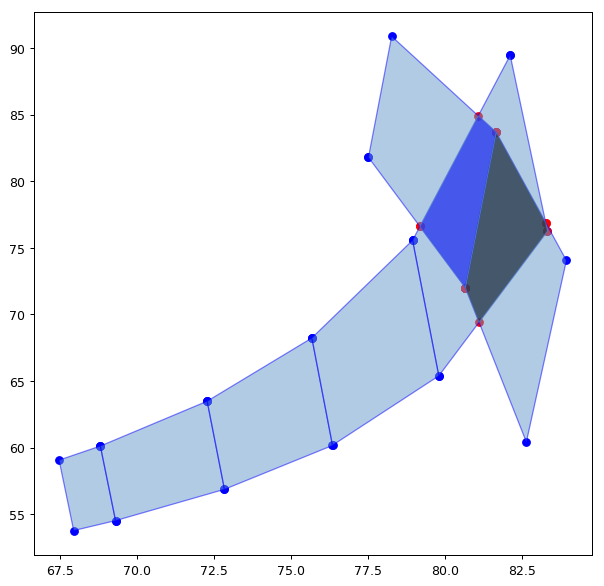

Successful overlap:
['S1A_EW_GRDH_1SDH_20141023T024813_20141023T024917_002951_0035A4_709A.zip', 'S1A_EW_GRDH_1SDH_20141023T024917_20141023T025017_002951_0035A4_0E9C.zip', 'S1A_EW_GRDH_1SDH_20141023T025017_20141023T025117_002951_0035A4_3D17.zip', 'S1A_EW_GRDH_1SDH_20141023T025117_20141023T025217_002951_0035A4_B794.zip', 'S1A_EW_GRDH_1SDH_20141023T025217_20141023T025240_002951_0035A4_0347.zip']
with
['S1A_EW_GRDH_1SDH_20141023T105709_20141023T105809_002956_0035C1_2124.zip', 'S1A_EW_GRDH_1SDH_20141023T105809_20141023T105852_002956_0035C1_980E.zip']

Time difference is  8:08:56
2014-10-23T024813 2014-10-23T105709
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141023T024813_20141023T024917_002951_0035A4_709A.zip
80.6630935669 69.4097258777 83.3297729492 83.6705780029
78.4822 61.4792 83.6476 93.984
79.1876899529 72.0147705078 81.6639175415 84.9059271596
78.4822 61.4792 83.6476 93.984
False False
/home/cercache/users/atarasen/data/Sentinel-1_analysis/

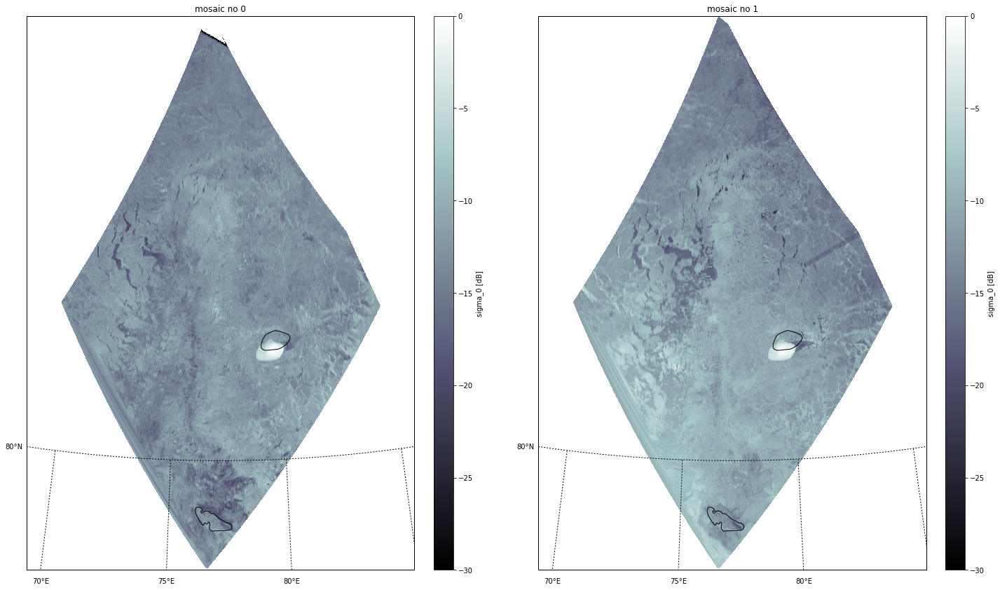

Kara_2014-10-23T024813_2014-10-23T105709_lat-3_lon-2_hh.pickle is created
2014-10-23 04:26:55 2014-10-23 10:57:09
area of intersection 1.21104725226
cond_area True
Images overlap


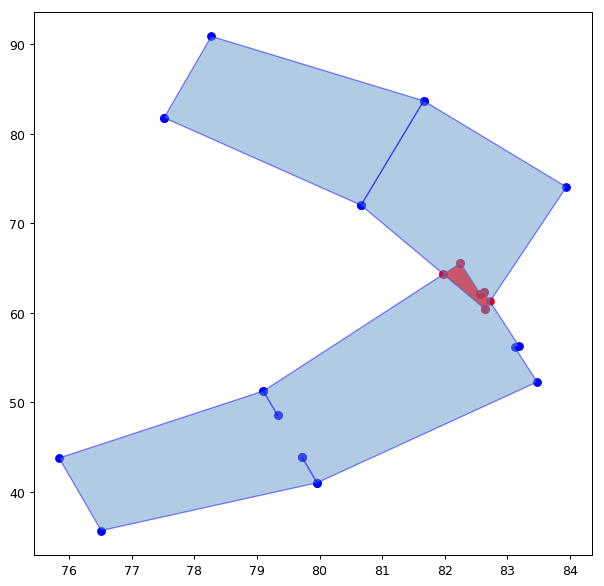

Successful overlap:
['S1A_EW_GRDH_1SDH_20141023T042655_20141023T042759_002952_0035A9_4CC7.zip', 'S1A_EW_GRDM_1SDH_20141023T042655_20141023T042759_002952_0035A9_7A24.zip', 'S1A_EW_GRDM_1SDH_20141023T042759_20141023T042859_002952_0035A9_3E49.zip', 'S1A_EW_GRDH_1SDH_20141023T042759_20141023T042859_002952_0035A9_E1AD.zip']
with
['S1A_EW_GRDH_1SDH_20141023T105709_20141023T105809_002956_0035C1_2124.zip', 'S1A_EW_GRDH_1SDH_20141023T105809_20141023T105852_002956_0035C1_980E.zip']

Time difference is  6:30:14
2014-10-23T042655 2014-10-23T105709
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141023T042655_20141023T042759_002952_0035A9_4CC7.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141023T042655_20141023T042759_002952_0035A9_7A24.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141023T042759_20141023T042859_002952_0035A9_3E49.zip
False True
/home/cercache/user

2014-10-23 10:57:09 2014-10-24 09:58:54
area of intersection 0.0
cond_area False
2014-10-23 10:57:09 2014-10-24 13:14:22
area of intersection 0.0
cond_area False
2014-10-23 10:57:09 2014-10-25 00:52:44
area of intersection 0.0
cond_area False
2014-10-23 10:57:09 2014-10-25 02:31:44
area of intersection 14.2915289111
cond_area True
Images overlap


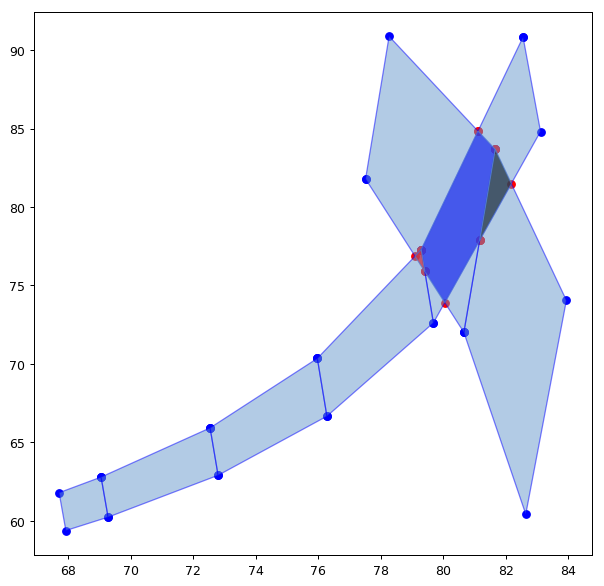

Successful overlap:
['S1A_EW_GRDH_1SDH_20141023T105709_20141023T105809_002956_0035C1_2124.zip', 'S1A_EW_GRDH_1SDH_20141023T105809_20141023T105852_002956_0035C1_980E.zip']
with
['S1A_EW_GRDM_1SDH_20141025T023144_20141025T023248_002980_00363B_8534.zip', 'S1A_EW_GRDM_1SDH_20141025T023248_20141025T023348_002980_00363B_83D1.zip', 'S1A_EW_GRDM_1SDH_20141025T023348_20141025T023448_002980_00363B_24F6.zip', 'S1A_EW_GRDM_1SDH_20141025T023448_20141025T023548_002980_00363B_7507.zip', 'S1A_EW_GRDM_1SDH_20141025T023548_20141025T023611_002980_00363B_EB26.zip']

Time difference is  1 day, 15:34:35
2014-10-23T105709 2014-10-25T023144
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDH_1SDH_20141023T105709_20141023T105809_002956_0035C1_2124.zip
81.166340941 77.8740913413 82.1816594884 83.6705780029
77.0984 67.695 81.9179 94.2904
79.2972793579 73.9112708345 81.6639175415 84.8347757287
77.0984 67.695 81.9179 94.2904
79.1018477382 75.9022328793 79.4118574354 77.2720947266
77.0

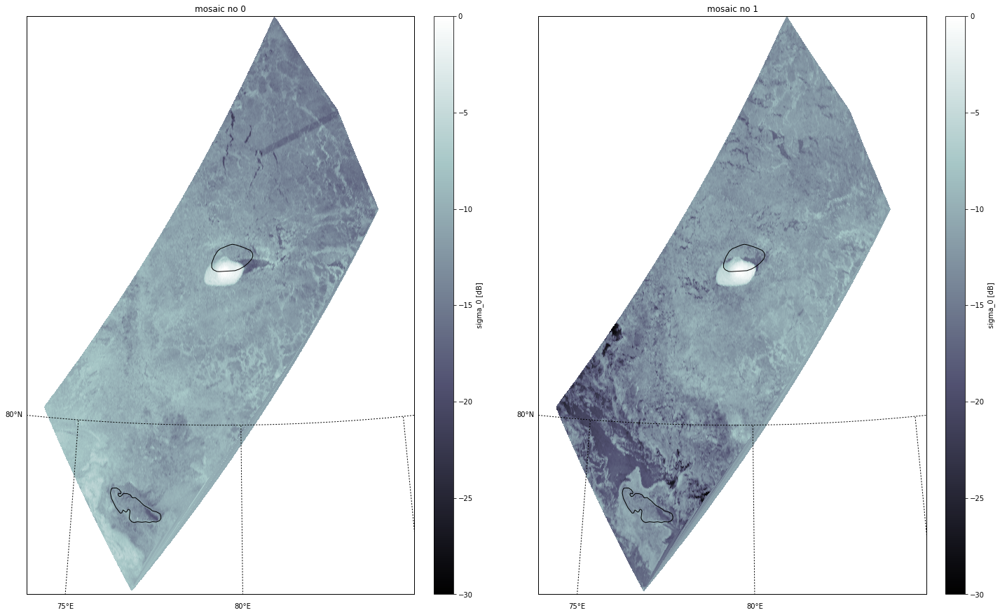

Kara_2014-10-23T105709_2014-10-25T023144_lat-3_lon-2_hh.pickle is created
2014-10-24 05:07:58 2014-10-24 09:58:54
area of intersection 0.0
cond_area False
2014-10-24 05:07:58 2014-10-24 13:14:22
area of intersection 6.48282969817
cond_area True
Images overlap


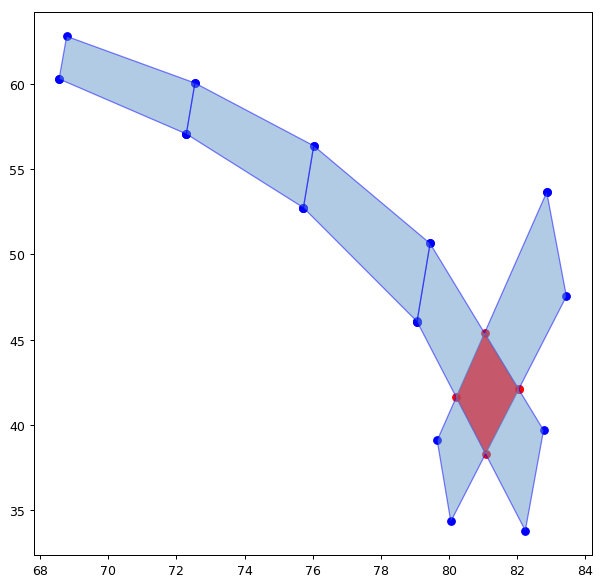

Successful overlap:
['S1A_EW_GRDM_1SDH_20141024T050758_20141024T050902_002967_0035F7_1539.zip']
with
['S1A_EW_GRDM_1SDH_20141024T131422_20141024T131526_002972_00360D_C82E.zip', 'S1A_EW_GRDM_1SDH_20141024T131526_20141024T131626_002972_00360D_7487.zip', 'S1A_EW_GRDM_1SDH_20141024T131626_20141024T131726_002972_00360D_AC16.zip', 'S1A_EW_GRDM_1SDH_20141024T131726_20141024T131828_002972_00360D_3394.zip']

Time difference is  8:06:24
2014-10-24T050758 2014-10-24T131422
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141024T050758_20141024T050902_002967_0035F7_1539.zip
False True
no HV data found
2014-10-24 09:58:54 2014-10-24 13:14:22
area of intersection 0.0
cond_area False


2014-10-24 09:58:54 2014-10-25 00:52:44
area of intersection 0.0
cond_area False
2014-10-24 09:58:54 2014-10-25 02:31:44
area of intersection 2.32571275458
cond_area True
Images overlap


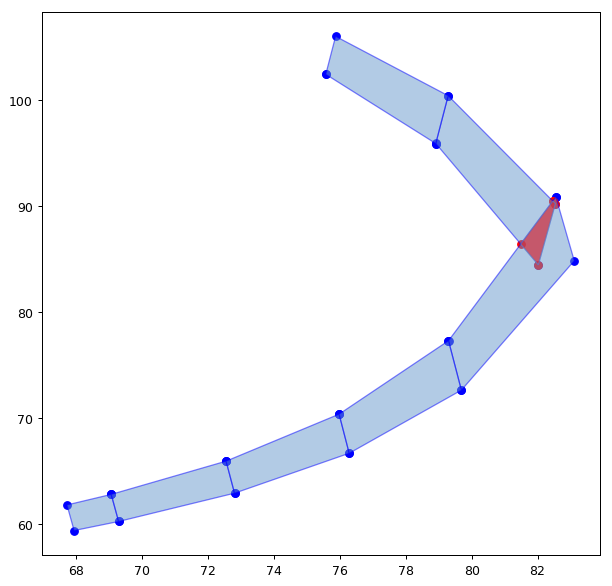

Successful overlap:
['S1A_EW_GRDM_1SDH_20141024T095854_20141024T095954_002970_003603_BDDA.zip', 'S1A_EW_GRDM_1SDH_20141024T095954_20141024T100054_002970_003603_EC31.zip']
with
['S1A_EW_GRDM_1SDH_20141025T023144_20141025T023248_002980_00363B_8534.zip', 'S1A_EW_GRDM_1SDH_20141025T023248_20141025T023348_002980_00363B_83D1.zip', 'S1A_EW_GRDM_1SDH_20141025T023348_20141025T023448_002980_00363B_24F6.zip', 'S1A_EW_GRDM_1SDH_20141025T023448_20141025T023548_002980_00363B_7507.zip', 'S1A_EW_GRDM_1SDH_20141025T023548_20141025T023611_002980_00363B_EB26.zip']

Time difference is  16:32:50
2014-10-24T095854 2014-10-25T023144
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141024T095854_20141024T095954_002970_003603_BDDA.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141024T095954_20141024T100054_002970_003603_EC31.zip
False True
no HV data found
2014-10-24 13:14:22 2014-10-25 00:52:44
area of intersection 0.0
cond

2014-10-24 13:14:22 2014-10-25 02:31:44
area of intersection 3.13881272397
cond_area True
Images overlap


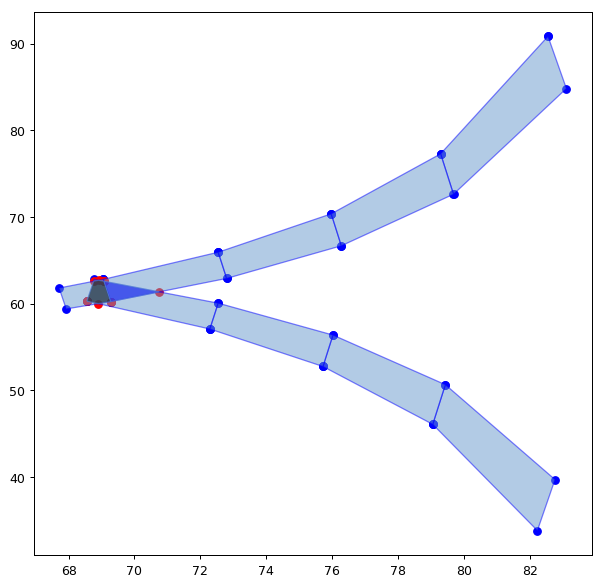

Successful overlap:
['S1A_EW_GRDM_1SDH_20141024T131422_20141024T131526_002972_00360D_C82E.zip', 'S1A_EW_GRDM_1SDH_20141024T131526_20141024T131626_002972_00360D_7487.zip', 'S1A_EW_GRDM_1SDH_20141024T131626_20141024T131726_002972_00360D_AC16.zip', 'S1A_EW_GRDM_1SDH_20141024T131726_20141024T131828_002972_00360D_3394.zip']
with
['S1A_EW_GRDM_1SDH_20141025T023144_20141025T023248_002980_00363B_8534.zip', 'S1A_EW_GRDM_1SDH_20141025T023248_20141025T023348_002980_00363B_83D1.zip', 'S1A_EW_GRDM_1SDH_20141025T023348_20141025T023448_002980_00363B_24F6.zip', 'S1A_EW_GRDM_1SDH_20141025T023448_20141025T023548_002980_00363B_7507.zip', 'S1A_EW_GRDM_1SDH_20141025T023548_20141025T023611_002980_00363B_EB26.zip']

Time difference is  13:17:22
2014-10-24T131422 2014-10-25T023144
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141024T131422_20141024T131526_002972_00360D_C82E.zip
68.5584945679 59.9922679079 69.2803497314 62.6832329427
68.1427 52.5975 72.8113 66.2408
69

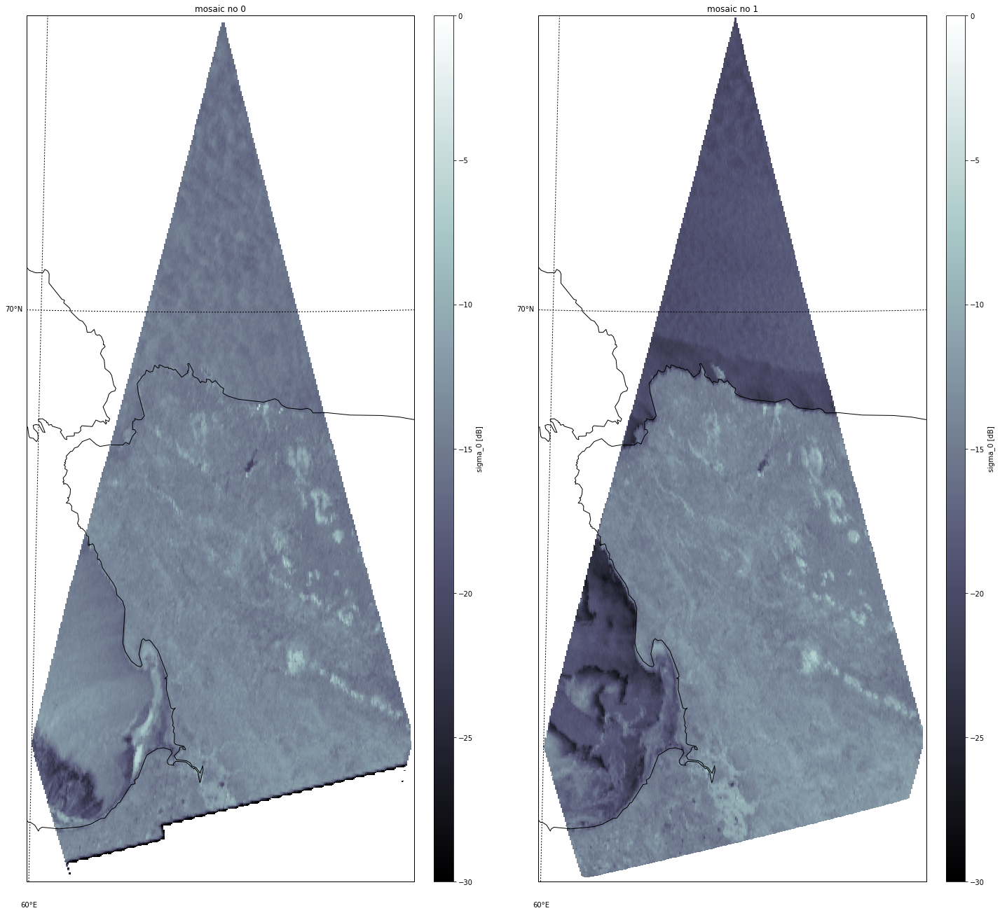

Kara_2014-10-24T131422_2014-10-25T023144_lat-3_lon-2_hh.pickle is created
2014-10-25 00:52:44 2014-10-25 02:31:44
area of intersection 0.0
cond_area False
2014-10-25 00:52:44 2014-10-25 04:09:58
area of intersection 0.0
cond_area False
2014-10-25 00:52:44 2014-10-25 10:41:34
area of intersection 0.0
cond_area False
2014-10-25 00:52:44 2014-10-25 13:57:18
area of intersection 0.0
cond_area False
2014-10-25 00:52:44 2014-10-25 23:56:34
area of intersection 0.0
cond_area False
2014-10-25 00:52:44 2014-10-26 01:34:09
area of intersection 0.0
cond_area False
2014-10-25 00:52:44 2014-10-26 04:51:35
area of intersection 0.0
cond_area False
2014-10-25 00:52:44 2014-10-26 11:20:15
area of intersection 0.0
cond_area False
2014-10-25 00:52:44 2014-10-27 00:36:36
area of intersection 7.6113379881
cond_area True
Images overlap


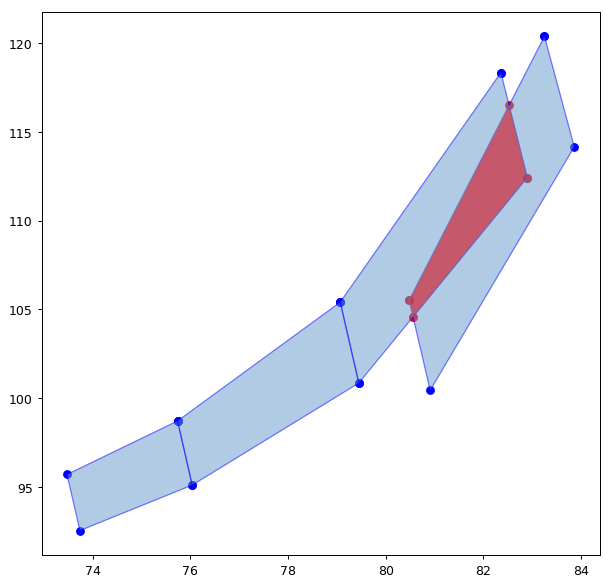

Successful overlap:
['S1A_EW_GRDM_1SSH_20141025T005244_20141025T005342_002979_003633_2870.zip']
with
['S1A_EW_GRDM_1SDH_20141027T003636_20141027T003740_003008_0036D6_B6EF.zip', 'S1A_EW_GRDM_1SDH_20141027T003740_20141027T003840_003008_0036D6_9561.zip', 'S1A_EW_GRDM_1SDH_20141027T003840_20141027T003920_003008_0036D6_8CC4.zip']

Time difference is  1 day, 23:43:52
2014-10-25T005244 2014-10-27T003636
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SSH_20141025T005244_20141025T005342_002979_003633_2870.zip
False True
no HV data found
2014-10-25 02:31:44 2014-10-25 04:09:58
area of intersection 0.0
cond_area False


2014-10-25 02:31:44 2014-10-25 10:41:34
area of intersection 5.3663004991
cond_area True
Images overlap


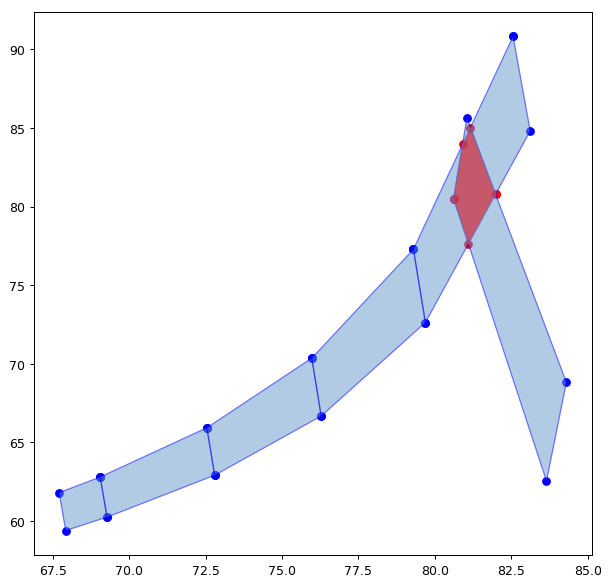

Successful overlap:
['S1A_EW_GRDM_1SDH_20141025T023144_20141025T023248_002980_00363B_8534.zip', 'S1A_EW_GRDM_1SDH_20141025T023248_20141025T023348_002980_00363B_83D1.zip', 'S1A_EW_GRDM_1SDH_20141025T023348_20141025T023448_002980_00363B_24F6.zip', 'S1A_EW_GRDM_1SDH_20141025T023448_20141025T023548_002980_00363B_7507.zip', 'S1A_EW_GRDM_1SDH_20141025T023548_20141025T023611_002980_00363B_EB26.zip']
with
['S1A_EW_GRDM_1SSH_20141025T104134_20141025T104238_002985_003651_03EC.zip']

Time difference is  8:09:50
2014-10-25T023144 2014-10-25T104134
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141025T023144_20141025T023248_002980_00363B_8534.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141025T023248_20141025T023348_002980_00363B_83D1.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141025T023348_20141025T023448_002980_00363B_24F6.zip
False True
/home/cercache/user

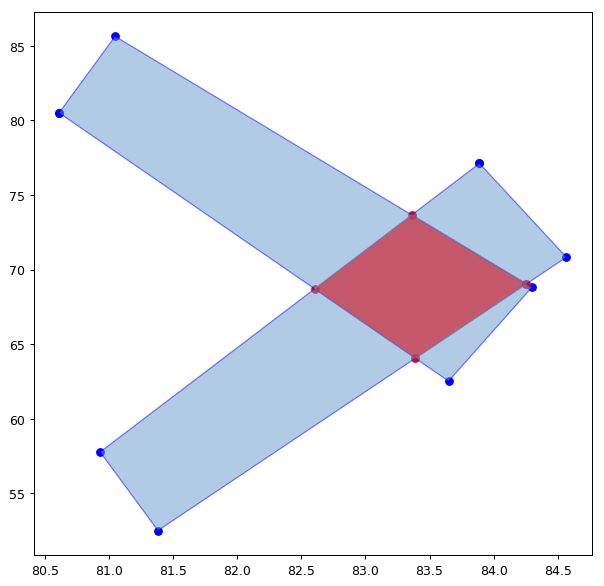

Successful overlap:
['S1A_EW_GRDM_1SSH_20141025T040958_20141025T041102_002981_003641_C013.zip']
with
['S1A_EW_GRDM_1SSH_20141025T104134_20141025T104238_002985_003651_03EC.zip']

Time difference is  6:31:36
2014-10-25T040958 2014-10-25T104134
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SSH_20141025T040958_20141025T041102_002981_003641_C013.zip
False True
no HV data found
2014-10-25 10:41:34 2014-10-25 13:57:18
area of intersection 0.0
cond_area False


2014-10-25 10:41:34 2014-10-25 23:56:34
area of intersection 0.0
cond_area False
2014-10-25 10:41:34 2014-10-26 01:34:09
area of intersection 0.0
cond_area False
2014-10-25 10:41:34 2014-10-26 04:51:35
area of intersection 0.0
cond_area False
2014-10-25 10:41:34 2014-10-26 11:20:15
area of intersection 0.168072261272
cond_area False
2014-10-25 10:41:34 2014-10-27 00:36:36
area of intersection 0.0
cond_area False
2014-10-25 10:41:34 2014-10-27 03:54:03
area of intersection 0.0128060814528
cond_area False
2014-10-25 10:41:34 2014-10-27 13:38:53
area of intersection 0.0
cond_area False
2014-10-25 10:41:34 2014-10-27 23:41:05
area of intersection 0.0
cond_area False
2014-10-25 10:41:34 2014-10-28 02:56:24
area of intersection 6.64889022085
cond_area True
Images overlap


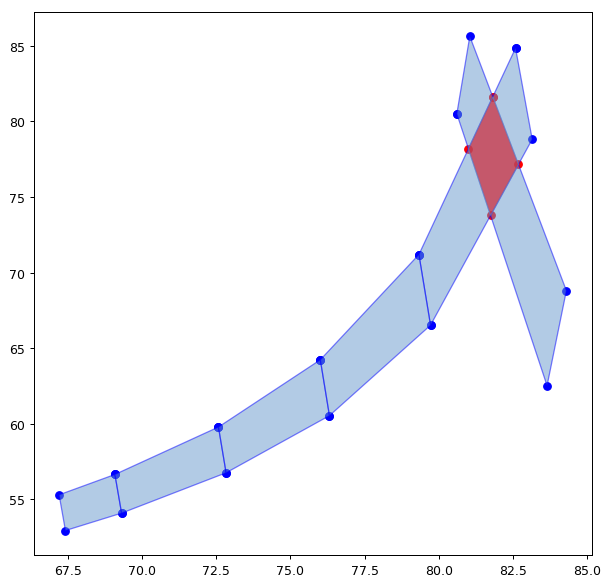

Successful overlap:
['S1A_EW_GRDM_1SSH_20141025T104134_20141025T104238_002985_003651_03EC.zip']
with
['S1A_EW_GRDM_1SDH_20141028T025624_20141028T025729_003024_003730_0501.zip', 'S1A_EW_GRDM_1SDH_20141028T025729_20141028T025829_003024_003730_8214.zip', 'S1A_EW_GRDM_1SDH_20141028T025829_20141028T025929_003024_003730_AC6F.zip', 'S1A_EW_GRDM_1SDH_20141028T025929_20141028T030029_003024_003730_1754.zip', 'S1A_EW_GRDM_1SDH_20141028T030029_20141028T030101_003024_003730_2787.zip']

Time difference is  2 days, 16:14:50
2014-10-25T104134 2014-10-28T025624
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SSH_20141025T104134_20141025T104238_002985_003651_03EC.zip
False True
no HV data found
2014-10-25 13:57:18 2014-10-25 23:56:34
area of intersection 0.0
cond_area False


2014-10-25 13:57:18 2014-10-26 01:34:09
area of intersection 0.0
cond_area False
2014-10-25 13:57:18 2014-10-26 04:51:35
area of intersection 0.0
cond_area False
2014-10-25 13:57:18 2014-10-26 11:20:15
area of intersection 0.0
cond_area False
2014-10-25 13:57:18 2014-10-27 00:36:36
area of intersection 0.0
cond_area False
2014-10-25 13:57:18 2014-10-27 03:54:03
area of intersection 1.53376961211
cond_area True
Images overlap


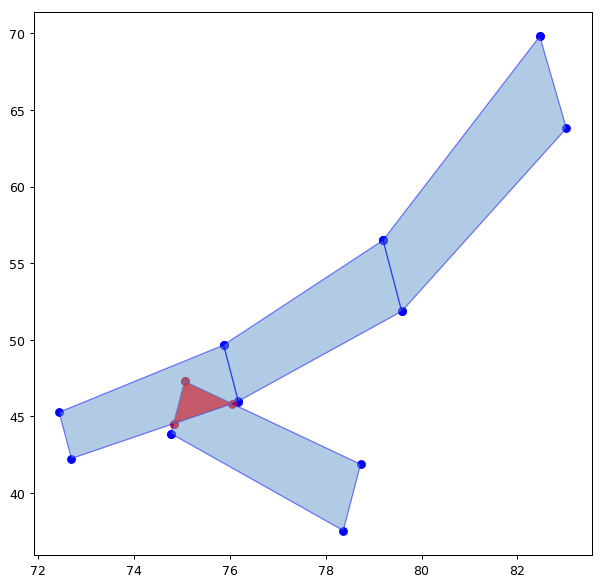

Successful overlap:
['S1A_EW_GRDM_1SDH_20141025T135718_20141025T135822_002987_00365F_9D6B.zip']
with
['S1A_EW_GRDM_1SDH_20141027T035403_20141027T035507_003010_0036E0_911E.zip', 'S1A_EW_GRDM_1SDH_20141027T035507_20141027T035607_003010_0036E0_EC93.zip', 'S1A_EW_GRDM_1SDH_20141027T035607_20141027T035707_003010_0036E0_F5EF.zip']

Time difference is  1 day, 13:56:45
2014-10-25T135718 2014-10-27T035403
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141025T135718_20141025T135822_002987_00365F_9D6B.zip
False True
no HV data found
2014-10-25 23:56:34 2014-10-26 01:34:09
area of intersection 0.0
cond_area False


2014-10-25 23:56:34 2014-10-26 04:51:35
area of intersection 0.0
cond_area False
2014-10-25 23:56:34 2014-10-26 11:20:15
area of intersection 0.0
cond_area False
2014-10-25 23:56:34 2014-10-27 00:36:36
area of intersection 0.0
cond_area False
2014-10-25 23:56:34 2014-10-27 03:54:03
area of intersection 0.0
cond_area False
2014-10-25 23:56:34 2014-10-27 13:38:53
area of intersection 0.0
cond_area False
2014-10-25 23:56:34 2014-10-27 23:41:05
area of intersection 0.0041485131269
cond_area False
2014-10-25 23:56:34 2014-10-28 02:56:24
area of intersection 0.0
cond_area False
2014-10-25 23:56:34 2014-10-28 04:35:09
area of intersection 0.0
cond_area False
2014-10-25 23:56:34 2014-10-28 11:04:10
area of intersection 0.0
cond_area False
2014-10-25 23:56:34 2014-10-28 12:45:03
area of intersection 0.0
cond_area False
2014-10-26 01:34:09 2014-10-26 04:51:35
area of intersection 0.0
cond_area False
2014-10-26 01:34:09 2014-10-26 11:20:15
area of intersection 5.73005473883
cond_area True
Images 

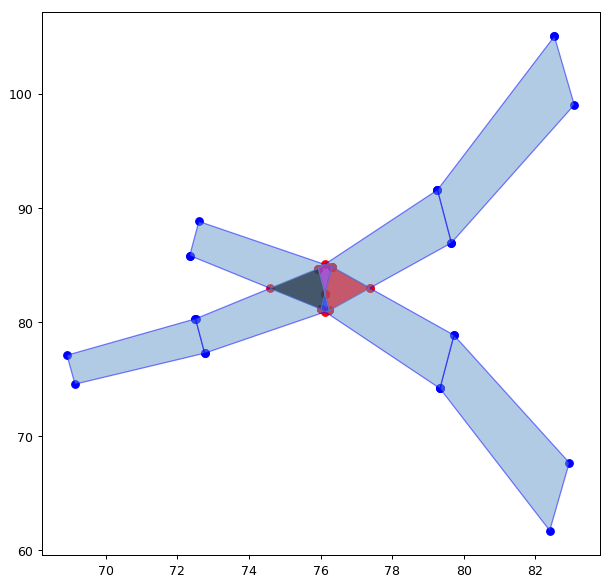

Successful overlap:
['S1A_EW_GRDM_1SDH_20141026T013409_20141026T013513_002994_00368D_CB41.zip', 'S1A_EW_GRDM_1SDH_20141026T013513_20141026T013613_002994_00368D_4B1B.zip', 'S1A_EW_GRDM_1SDH_20141026T013613_20141026T013713_002994_00368D_D0AE.zip', 'S1A_EW_GRDM_1SDH_20141026T013713_20141026T013815_002994_00368D_DA4E.zip']
with
['S1A_EW_GRDM_1SDH_20141026T112015_20141026T112119_003000_0036AC_8FCB.zip', 'S1A_EW_GRDM_1SDH_20141026T112119_20141026T112219_003000_0036AC_D943.zip', 'S1A_EW_GRDM_1SDH_20141026T112219_20141026T112319_003000_0036AC_3B1D.zip']

Time difference is  9:46:06
2014-10-26T013409 2014-10-26T112015
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141026T013409_20141026T013513_002994_00368D_CB41.zip
74.5939734332 81.1270751953 76.1257509487 84.6748962402
78.5365 80.132 83.6918 112.669
76.0153198242 80.8817413698 76.2467422485 82.4578620968
78.5365 80.132 83.6918 112.669
76.1261457288 81.0054016113 77.3752930195 84.8139190674
78.5365 80.

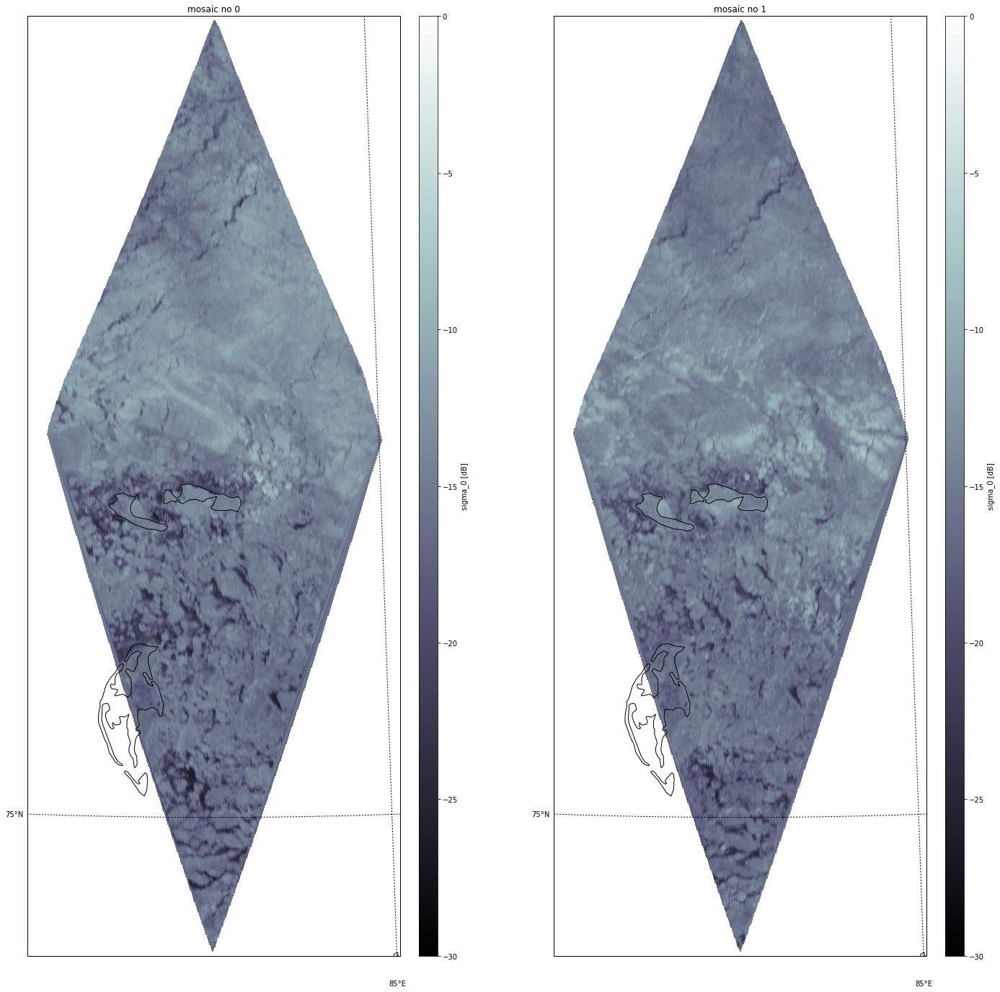

Kara_2014-10-26T013409_2014-10-26T112015_lat-3_lon-2_hh.pickle is created
2014-10-26 04:51:35 2014-10-26 11:20:15
area of intersection 0.0
cond_area False
2014-10-26 04:51:35 2014-10-27 00:36:36
area of intersection 0.0
cond_area False
2014-10-26 04:51:35 2014-10-27 03:54:03
area of intersection 0.0
cond_area False
2014-10-26 04:51:35 2014-10-27 13:38:53
area of intersection 3.20792581744
cond_area True
Images overlap


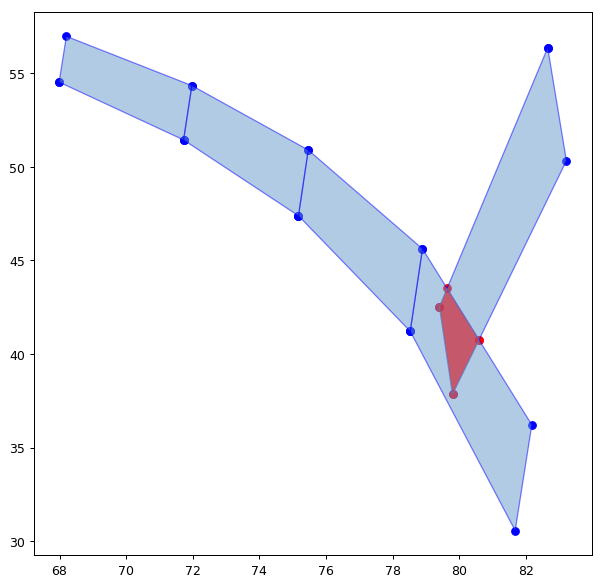

Successful overlap:
['S1A_EW_GRDM_1SDH_20141026T045135_20141026T045239_002996_003696_E863.zip']
with
['S1A_EW_GRDM_1SDH_20141027T133853_20141027T133957_003016_003701_931D.zip', 'S1A_EW_GRDM_1SDH_20141027T133957_20141027T134057_003016_003701_2726.zip', 'S1A_EW_GRDM_1SDH_20141027T134057_20141027T134157_003016_003701_976C.zip', 'S1A_EW_GRDM_1SDH_20141027T134157_20141027T134257_003016_003701_5A3C.zip']

Time difference is  1 day, 8:47:18
2014-10-26T045135 2014-10-27T133853
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141026T045135_20141026T045239_002996_003696_E863.zip
False True
no HV data found
2014-10-26 11:20:15 2014-10-27 00:36:36
area of intersection 0.0
cond_area False


2014-10-26 11:20:15 2014-10-27 03:54:03
area of intersection 5.47929232929
cond_area True
Images overlap


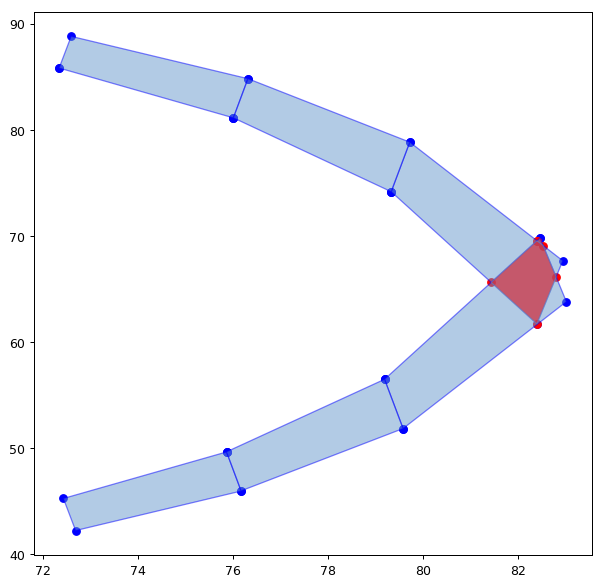

Successful overlap:
['S1A_EW_GRDM_1SDH_20141026T112015_20141026T112119_003000_0036AC_8FCB.zip', 'S1A_EW_GRDM_1SDH_20141026T112119_20141026T112219_003000_0036AC_D943.zip', 'S1A_EW_GRDM_1SDH_20141026T112219_20141026T112319_003000_0036AC_3B1D.zip']
with
['S1A_EW_GRDM_1SDH_20141027T035403_20141027T035507_003010_0036E0_911E.zip', 'S1A_EW_GRDM_1SDH_20141027T035507_20141027T035607_003010_0036E0_EC93.zip', 'S1A_EW_GRDM_1SDH_20141027T035607_20141027T035707_003010_0036E0_F5EF.zip']

Time difference is  16:33:48
2014-10-26T112015 2014-10-27T035403
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141026T112015_20141026T112119_003000_0036AC_8FCB.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141026T112119_20141026T112219_003000_0036AC_D943.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141026T112219_20141026T112319_003000_0036AC_3B1D.zip
False True
no HV data found
2

2014-10-27 00:36:36 2014-10-27 13:38:53
area of intersection 0.0
cond_area False
2014-10-27 00:36:36 2014-10-27 23:41:05
area of intersection 0.0
cond_area False
2014-10-27 00:36:36 2014-10-28 02:56:24
area of intersection 0.0
cond_area False
2014-10-27 00:36:36 2014-10-28 04:35:09
area of intersection 0.0
cond_area False
2014-10-27 00:36:36 2014-10-28 11:04:10
area of intersection 0.0
cond_area False
2014-10-27 00:36:36 2014-10-28 12:45:03
area of intersection 0.0
cond_area False
2014-10-27 00:36:36 2014-10-29 01:58:49
area of intersection 0.0
cond_area False
2014-10-27 00:36:36 2014-10-29 03:37:24
area of intersection 0.0
cond_area False
2014-10-27 00:36:36 2014-10-29 05:16:13
area of intersection 0.0
cond_area False
2014-10-27 00:36:36 2014-10-29 10:06:07
area of intersection 5.76167262589
cond_area True
Images overlap


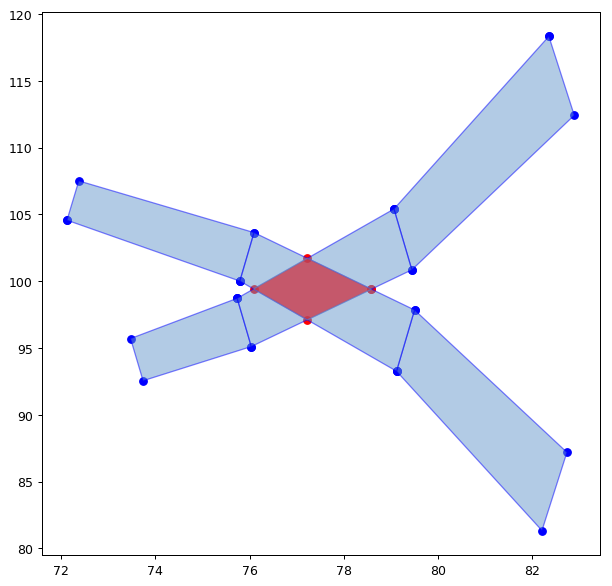

Successful overlap:
['S1A_EW_GRDM_1SDH_20141027T003636_20141027T003740_003008_0036D6_B6EF.zip', 'S1A_EW_GRDM_1SDH_20141027T003740_20141027T003840_003008_0036D6_9561.zip', 'S1A_EW_GRDM_1SDH_20141027T003840_20141027T003920_003008_0036D6_8CC4.zip']
with
['S1A_EW_GRDM_1SDH_20141029T100607_20141029T100711_003043_0037A2_D6D8.zip', 'S1A_EW_GRDM_1SDH_20141029T100711_20141029T100811_003043_0037A2_CCA2.zip', 'S1A_EW_GRDM_1SDH_20141029T100811_20141029T100911_003043_0037A2_34EF.zip']

Time difference is  2 days, 9:29:31
2014-10-27T003636 2014-10-29T100607
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141027T003636_20141027T003740_003008_0036D6_B6EF.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141027T003740_20141027T003840_003008_0036D6_9561.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141027T003840_20141027T003920_003008_0036D6_8CC4.zip
False True
no HV data 

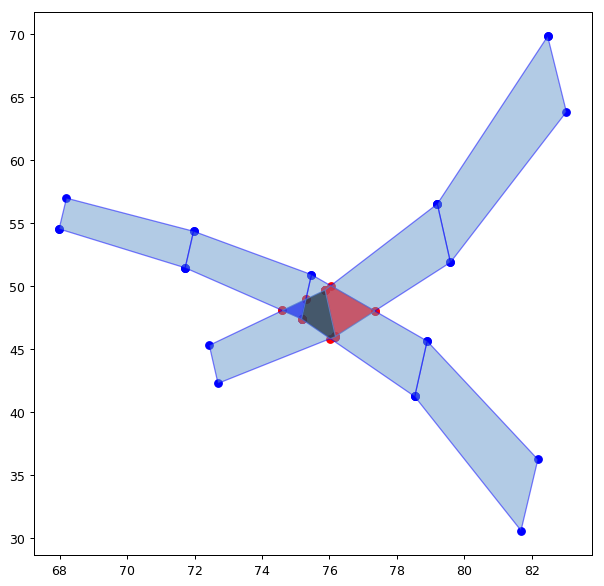

Successful overlap:
['S1A_EW_GRDM_1SDH_20141027T035403_20141027T035507_003010_0036E0_911E.zip', 'S1A_EW_GRDM_1SDH_20141027T035507_20141027T035607_003010_0036E0_EC93.zip', 'S1A_EW_GRDM_1SDH_20141027T035607_20141027T035707_003010_0036E0_F5EF.zip']
with
['S1A_EW_GRDM_1SDH_20141027T133853_20141027T133957_003016_003701_931D.zip', 'S1A_EW_GRDM_1SDH_20141027T133957_20141027T134057_003016_003701_2726.zip', 'S1A_EW_GRDM_1SDH_20141027T134057_20141027T134157_003016_003701_976C.zip', 'S1A_EW_GRDM_1SDH_20141027T134157_20141027T134257_003016_003701_5A3C.zip']

Time difference is  9:44:50
2014-10-27T035403 2014-10-27T133853
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141027T035403_20141027T035507_003010_0036E0_911E.zip
75.1717910767 45.8123231602 76.1782226562 49.6569976807
78.4651 45.0512 83.6291 77.4692
74.6074539841 47.3811912537 75.3007513941 48.928666535
78.4651 45.0512 83.6291 77.4692
75.8706512451 45.9951705933 77.3431682095 50.0109051311
78.4651 45

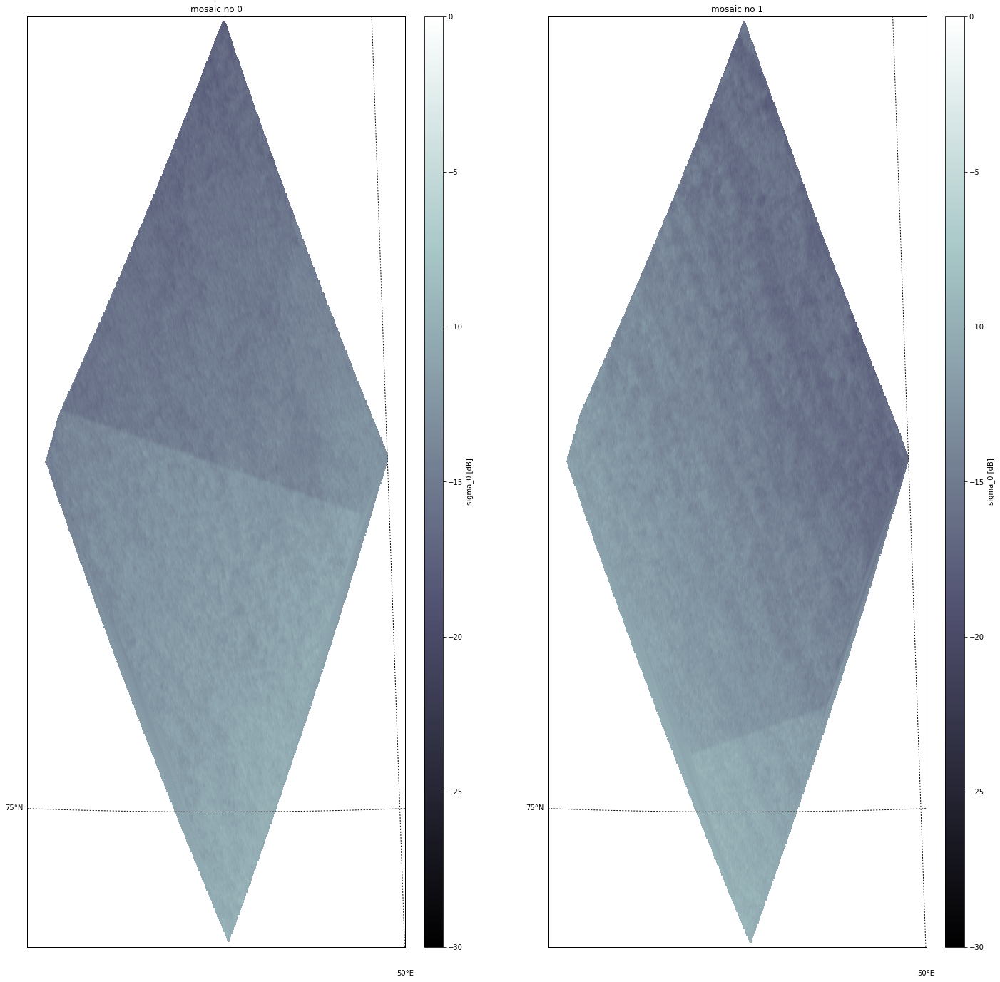

Kara_2014-10-27T035403_2014-10-27T133853_lat-3_lon-2_hh.pickle is created
2014-10-27 13:38:53 2014-10-27 23:41:05
area of intersection 0.0
cond_area False
2014-10-27 13:38:53 2014-10-28 02:56:24
area of intersection 4.26001587764
cond_area True
Images overlap


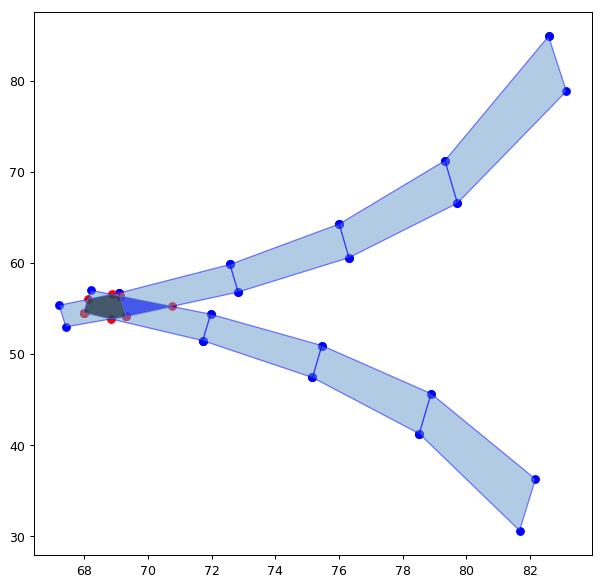

Successful overlap:
['S1A_EW_GRDM_1SDH_20141027T133853_20141027T133957_003016_003701_931D.zip', 'S1A_EW_GRDM_1SDH_20141027T133957_20141027T134057_003016_003701_2726.zip', 'S1A_EW_GRDM_1SDH_20141027T134057_20141027T134157_003016_003701_976C.zip', 'S1A_EW_GRDM_1SDH_20141027T134157_20141027T134257_003016_003701_5A3C.zip']
with
['S1A_EW_GRDM_1SDH_20141028T025624_20141028T025729_003024_003730_0501.zip', 'S1A_EW_GRDM_1SDH_20141028T025729_20141028T025829_003024_003730_8214.zip', 'S1A_EW_GRDM_1SDH_20141028T025829_20141028T025929_003024_003730_AC6F.zip', 'S1A_EW_GRDM_1SDH_20141028T025929_20141028T030029_003024_003730_1754.zip', 'S1A_EW_GRDM_1SDH_20141028T030029_20141028T030101_003024_003730_2787.zip']

Time difference is  13:17:31
2014-10-27T133853 2014-10-28T025624
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141027T133853_20141027T133957_003016_003701_931D.zip
67.9868240356 53.8103817948 69.3171386719 56.4963909013
67.5778 47.0742 72.2341 60.3333
69

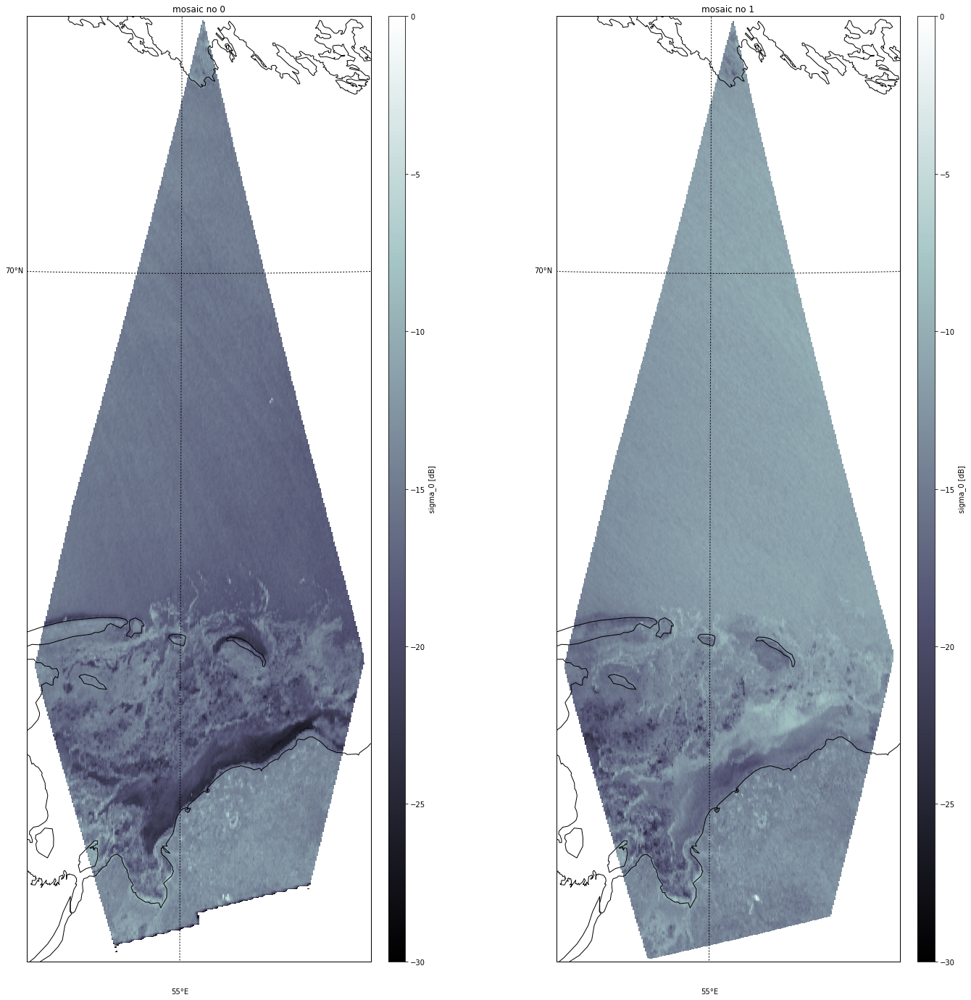

Kara_2014-10-27T133853_2014-10-28T025624_lat-3_lon-2_hh.pickle is created
2014-10-27 23:41:05 2014-10-28 02:56:24
area of intersection 0.0
cond_area False
2014-10-27 23:41:05 2014-10-28 04:35:09
area of intersection 0.0
cond_area False
2014-10-27 23:41:05 2014-10-28 11:04:10
area of intersection 0.0
cond_area False
2014-10-27 23:41:05 2014-10-28 12:45:03
area of intersection 0.0
cond_area False
2014-10-27 23:41:05 2014-10-29 01:58:49
area of intersection 0.0
cond_area False
2014-10-27 23:41:05 2014-10-29 03:37:24
area of intersection 0.0
cond_area False
2014-10-27 23:41:05 2014-10-29 05:16:13
area of intersection 0.0
cond_area False
2014-10-27 23:41:05 2014-10-29 10:06:07
area of intersection 0.105715875028
cond_area False
2014-10-27 23:41:05 2014-10-29 13:22:33
area of intersection 0.0
cond_area False
2014-10-27 23:41:05 2014-10-30 01:01:16
area of intersection 0.0
cond_area False
2014-10-27 23:41:05 2014-10-30 04:18:43
area of intersection 0.0
cond_area False
2014-10-27 23:41:05 2014

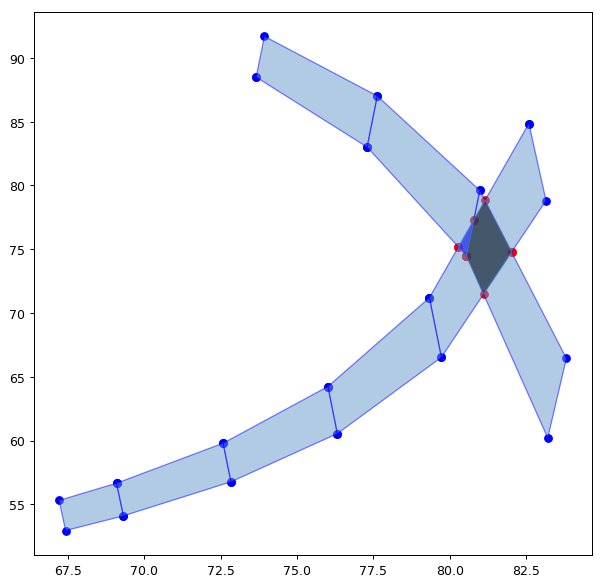

Successful overlap:
['S1A_EW_GRDM_1SDH_20141028T025624_20141028T025729_003024_003730_0501.zip', 'S1A_EW_GRDM_1SDH_20141028T025729_20141028T025829_003024_003730_8214.zip', 'S1A_EW_GRDM_1SDH_20141028T025829_20141028T025929_003024_003730_AC6F.zip', 'S1A_EW_GRDM_1SDH_20141028T025929_20141028T030029_003024_003730_1754.zip', 'S1A_EW_GRDM_1SDH_20141028T030029_20141028T030101_003024_003730_2787.zip']
with
['S1A_EW_GRDM_1SDH_20141028T110410_20141028T110514_003029_003750_73F0.zip', 'S1A_EW_GRDM_1SDH_20141028T110514_20141028T110614_003029_003750_BD90.zip', 'S1A_EW_GRDM_1SDH_20141028T110614_20141028T110709_003029_003750_F773.zip']

Time difference is  8:07:46
2014-10-28T025624 2014-10-28T110410
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141028T025624_20141028T025729_003024_003730_0501.zip
80.544418335 71.4813226137 82.0214747079 78.8244091123
78.597 59.6737 83.7619 92.5155
80.2803527412 74.4843444824 80.7830810331 77.2842695643
78.597 59.6737 83.7619 9

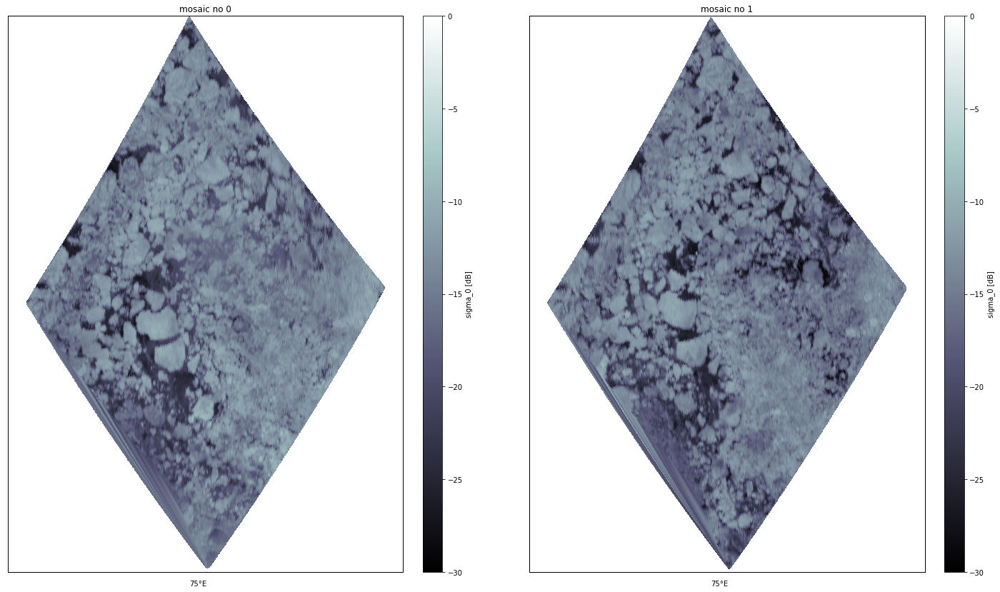

Kara_2014-10-28T025624_2014-10-28T110410_lat-3_lon-2_hh.pickle is created
2014-10-28 04:35:09 2014-10-28 11:04:10
area of intersection 0.0
cond_area False
2014-10-28 04:35:09 2014-10-28 12:45:03
area of intersection 4.62547028165
cond_area True
Images overlap


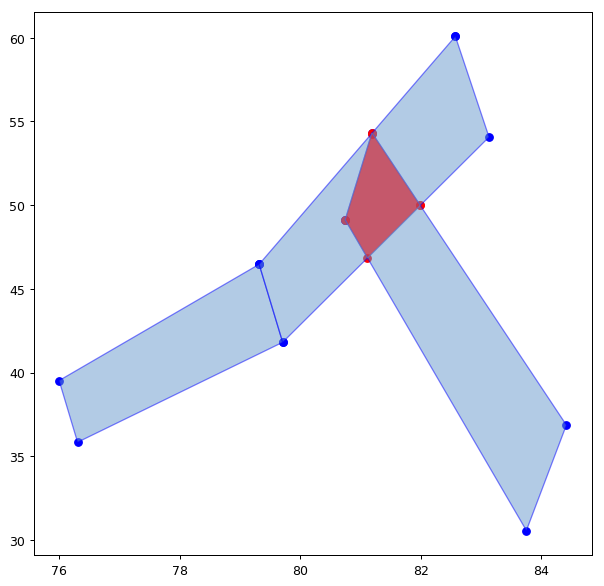

Successful overlap:
['S1A_EW_GRDM_1SDH_20141028T043509_20141028T043613_003025_003735_C705.zip', 'S1A_EW_GRDM_1SDH_20141028T043613_20141028T043713_003025_003735_EAED.zip']
with
['S1A_EW_GRDM_1SSH_20141028T124503_20141028T124607_003030_003757_9B23.zip']

Time difference is  8:09:54
2014-10-28T043509 2014-10-28T124503
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141028T043509_20141028T043613_003025_003735_C705.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141028T043613_20141028T043713_003025_003735_EAED.zip
False True
no HV data found
2014-10-28 11:04:10 2014-10-28 12:45:03
area of intersection 0.0
cond_area False


2014-10-28 11:04:10 2014-10-29 01:58:49
area of intersection 6.32603291318
cond_area True
Images overlap


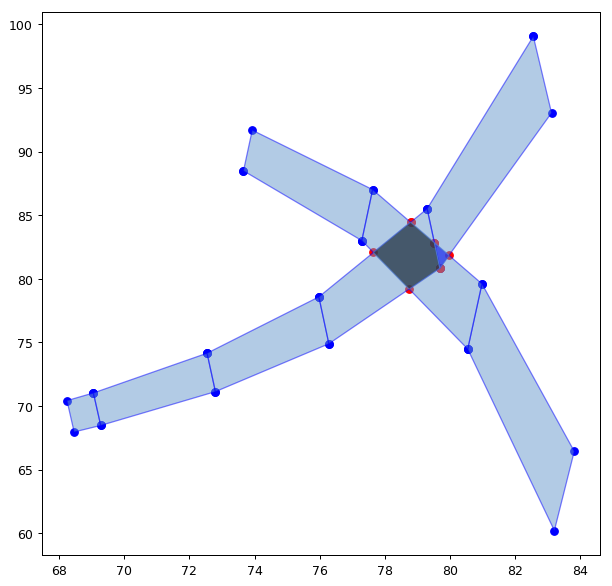

Successful overlap:
['S1A_EW_GRDM_1SDH_20141028T110410_20141028T110514_003029_003750_73F0.zip', 'S1A_EW_GRDM_1SDH_20141028T110514_20141028T110614_003029_003750_BD90.zip', 'S1A_EW_GRDM_1SDH_20141028T110614_20141028T110709_003029_003750_F773.zip']
with
['S1A_EW_GRDM_1SDH_20141029T015849_20141029T015953_003038_003785_D36B.zip', 'S1A_EW_GRDM_1SDH_20141029T015953_20141029T020053_003038_003785_843D.zip', 'S1A_EW_GRDM_1SDH_20141029T020053_20141029T020153_003038_003785_C94E.zip', 'S1A_EW_GRDM_1SDH_20141029T020153_20141029T020253_003038_003785_964B.zip', 'S1A_EW_GRDM_1SDH_20141029T020253_20141029T020307_003038_003785_576B.zip']

Time difference is  14:54:39
2014-10-28T110410 2014-10-29T015849
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141028T110410_20141028T110514_003029_003750_73F0.zip
77.6508980033 79.1987057991 79.688583374 84.4456463507
73.1525 77.1966 77.9745 96.1606
79.5224952058 80.8452148438 79.9693081299 82.8293313859
73.1525 77.1966 77.974

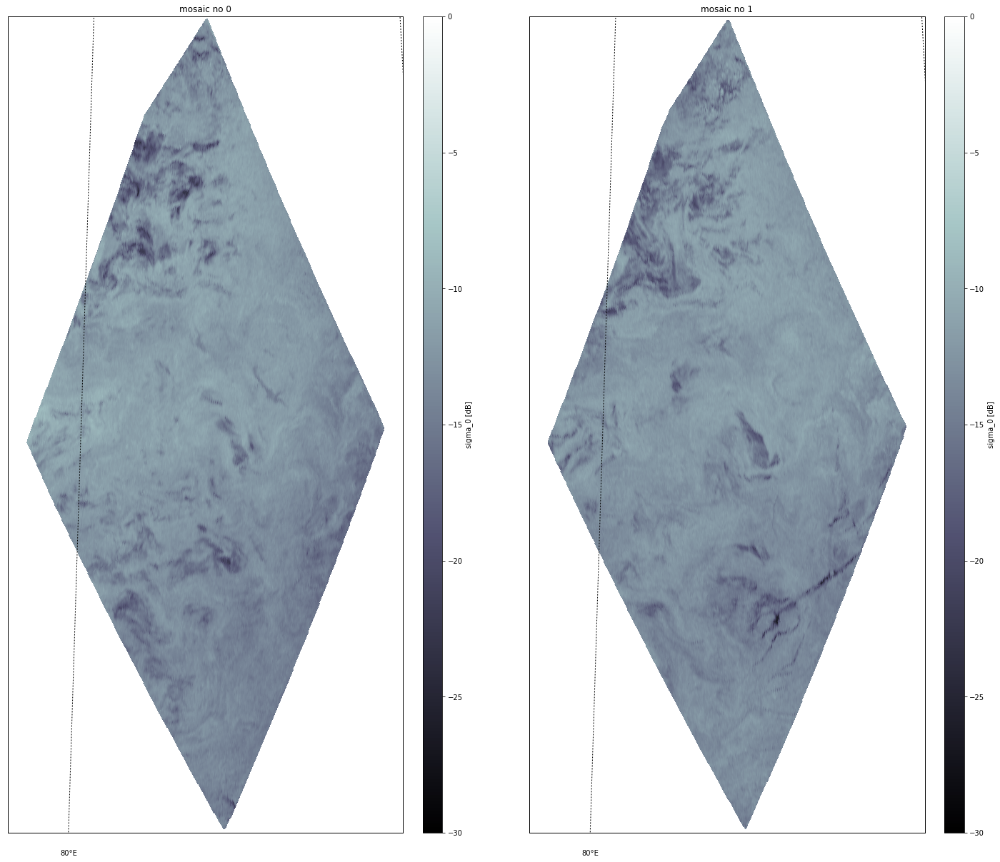

Kara_2014-10-28T110410_2014-10-29T015849_lat-3_lon-2_hh.pickle is created
2014-10-28 12:45:03 2014-10-29 01:58:49
area of intersection 0.0
cond_area False
2014-10-28 12:45:03 2014-10-29 03:37:24
area of intersection 0.0
cond_area False
2014-10-28 12:45:03 2014-10-29 05:16:13
area of intersection 6.92048811327
cond_area True
Images overlap


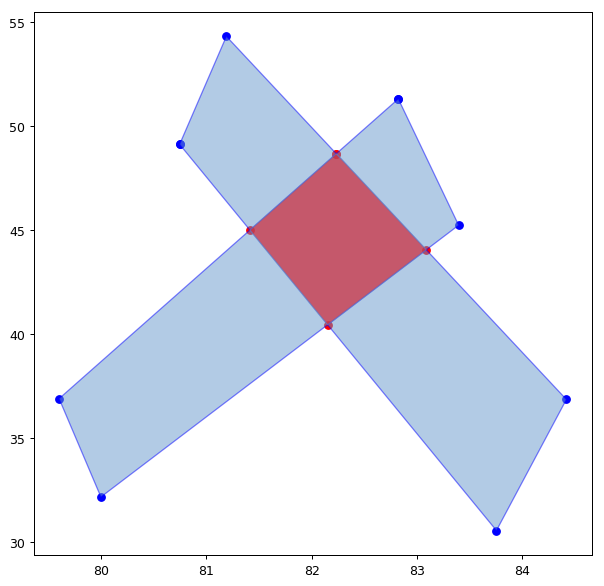

Successful overlap:
['S1A_EW_GRDM_1SSH_20141028T124503_20141028T124607_003030_003757_9B23.zip']
with
['S1A_EW_GRDM_1SDH_20141029T051613_20141029T051717_003040_003790_FB0E.zip']

Time difference is  16:31:10
2014-10-28T124503 2014-10-29T051613
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SSH_20141028T124503_20141028T124607_003030_003757_9B23.zip
False True
no HV data found
2014-10-29 01:58:49 2014-10-29 03:37:24
area of intersection 0.0
cond_area False


2014-10-29 01:58:49 2014-10-29 05:16:13
area of intersection 0.0
cond_area False
2014-10-29 01:58:49 2014-10-29 10:06:07
area of intersection 6.67676737537
cond_area True
Images overlap


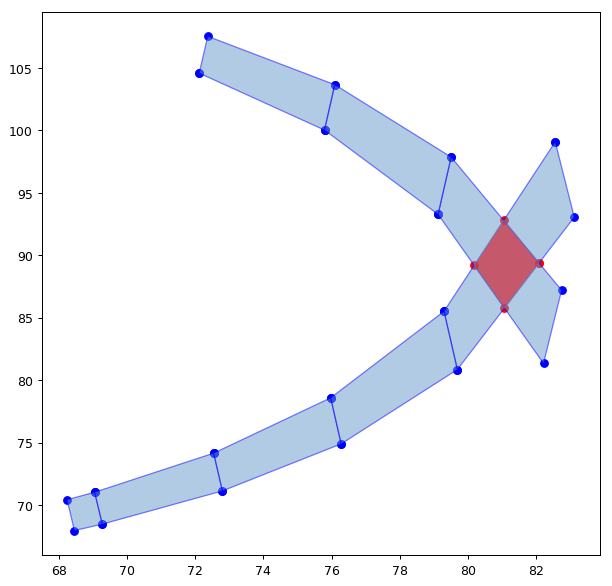

Successful overlap:
['S1A_EW_GRDM_1SDH_20141029T015849_20141029T015953_003038_003785_D36B.zip', 'S1A_EW_GRDM_1SDH_20141029T015953_20141029T020053_003038_003785_843D.zip', 'S1A_EW_GRDM_1SDH_20141029T020053_20141029T020153_003038_003785_C94E.zip', 'S1A_EW_GRDM_1SDH_20141029T020153_20141029T020253_003038_003785_964B.zip', 'S1A_EW_GRDM_1SDH_20141029T020253_20141029T020307_003038_003785_576B.zip']
with
['S1A_EW_GRDM_1SDH_20141029T100607_20141029T100711_003043_0037A2_D6D8.zip', 'S1A_EW_GRDM_1SDH_20141029T100711_20141029T100811_003043_0037A2_CCA2.zip', 'S1A_EW_GRDM_1SDH_20141029T100811_20141029T100911_003043_0037A2_34EF.zip']

Time difference is  8:07:18
2014-10-29T015849 2014-10-29T100607
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141029T015849_20141029T015953_003038_003785_D36B.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141029T015953_20141029T020053_003038_003785_843D.zip
False True
/home/cercac

2014-10-29 03:37:24 2014-10-29 10:06:07
area of intersection 0.0
cond_area False
2014-10-29 03:37:24 2014-10-29 13:22:33
area of intersection 0.0
cond_area False
2014-10-29 03:37:24 2014-10-30 01:01:16
area of intersection 0.0
cond_area False
2014-10-29 03:37:24 2014-10-30 04:18:43
area of intersection 0.0
cond_area False
2014-10-29 03:37:24 2014-10-30 10:49:48
area of intersection 7.29141237313
cond_area True
Images overlap


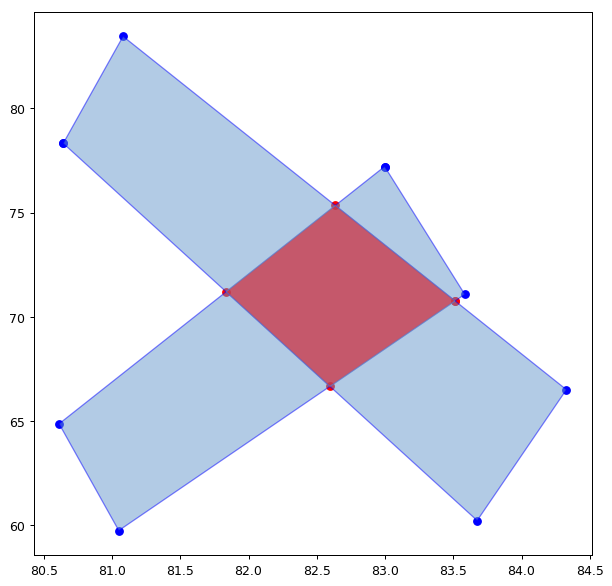

Successful overlap:
['S1A_EW_GRDM_1SSH_20141029T033724_20141029T033813_003039_00378A_EDA2.zip']
with
['S1A_EW_GRDM_1SSH_20141030T104948_20141030T105052_003058_0037F2_0950.zip']

Time difference is  1 day, 7:12:24
2014-10-29T033724 2014-10-30T104948
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SSH_20141029T033724_20141029T033813_003039_00378A_EDA2.zip
False True
no HV data found
2014-10-29 05:16:13 2014-10-29 10:06:07
area of intersection 0.0
cond_area False


2014-10-29 05:16:13 2014-10-29 13:22:33
area of intersection 6.52997344051
cond_area True
Images overlap


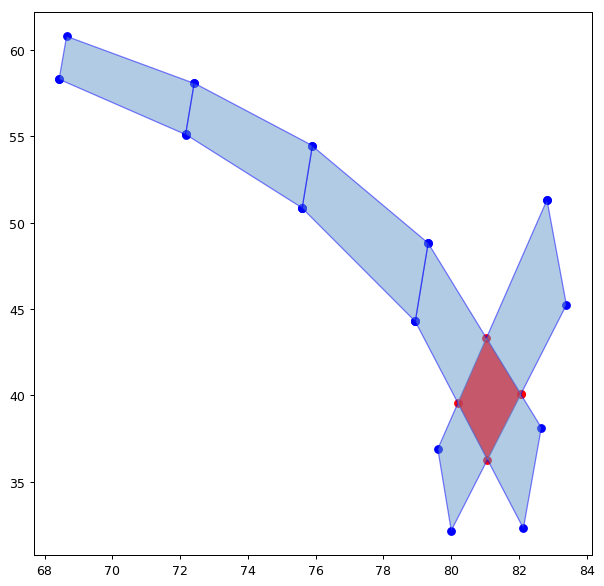

Successful overlap:
['S1A_EW_GRDM_1SDH_20141029T051613_20141029T051717_003040_003790_FB0E.zip']
with
['S1A_EW_GRDM_1SDH_20141029T132233_20141029T132337_003045_0037AE_3A4D.zip', 'S1A_EW_GRDM_1SDH_20141029T132337_20141029T132437_003045_0037AE_0550.zip', 'S1A_EW_GRDM_1SDH_20141029T132437_20141029T132537_003045_0037AE_82A6.zip', 'S1A_EW_GRDM_1SDH_20141029T132537_20141029T132639_003045_0037AE_FCF0.zip']

Time difference is  8:06:20
2014-10-29T051613 2014-10-29T132233
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141029T051613_20141029T051717_003040_003790_FB0E.zip
False True
no HV data found
2014-10-29 10:06:07 2014-10-29 13:22:33
area of intersection 0.0
cond_area False


2014-10-29 10:06:07 2014-10-30 01:01:16
area of intersection 6.52425042333
cond_area True
Images overlap


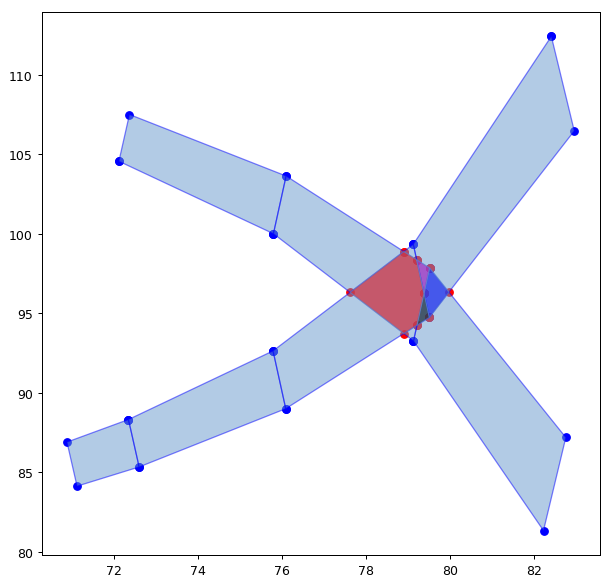

Successful overlap:
['S1A_EW_GRDM_1SDH_20141029T100607_20141029T100711_003043_0037A2_D6D8.zip', 'S1A_EW_GRDM_1SDH_20141029T100711_20141029T100811_003043_0037A2_CCA2.zip', 'S1A_EW_GRDM_1SDH_20141029T100811_20141029T100911_003043_0037A2_34EF.zip']
with
['S1A_EW_GRDM_1SDH_20141030T010116_20141030T010220_003052_0037CF_CFF6.zip', 'S1A_EW_GRDM_1SDH_20141030T010220_20141030T010320_003052_0037CF_8FC0.zip', 'S1A_EW_GRDM_1SDH_20141030T010320_20141030T010420_003052_0037CF_3B11.zip', 'S1A_EW_GRDM_1SDH_20141030T010420_20141030T010446_003052_0037CF_A996.zip']

Time difference is  14:55:09
2014-10-29T100607 2014-10-30T010116
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141029T100607_20141029T100711_003043_0037A2_D6D8.zip
79.2072043638 94.2578217714 79.5013122559 96.2654591905
71.6465 94.6771 76.4123 111.621
79.3752748055 94.7537841797 79.9664789023 97.8469467163
71.6465 94.6771 76.4123 111.621
77.6165219551 93.7317859091 79.3748827705 98.8894057596
71.6465 

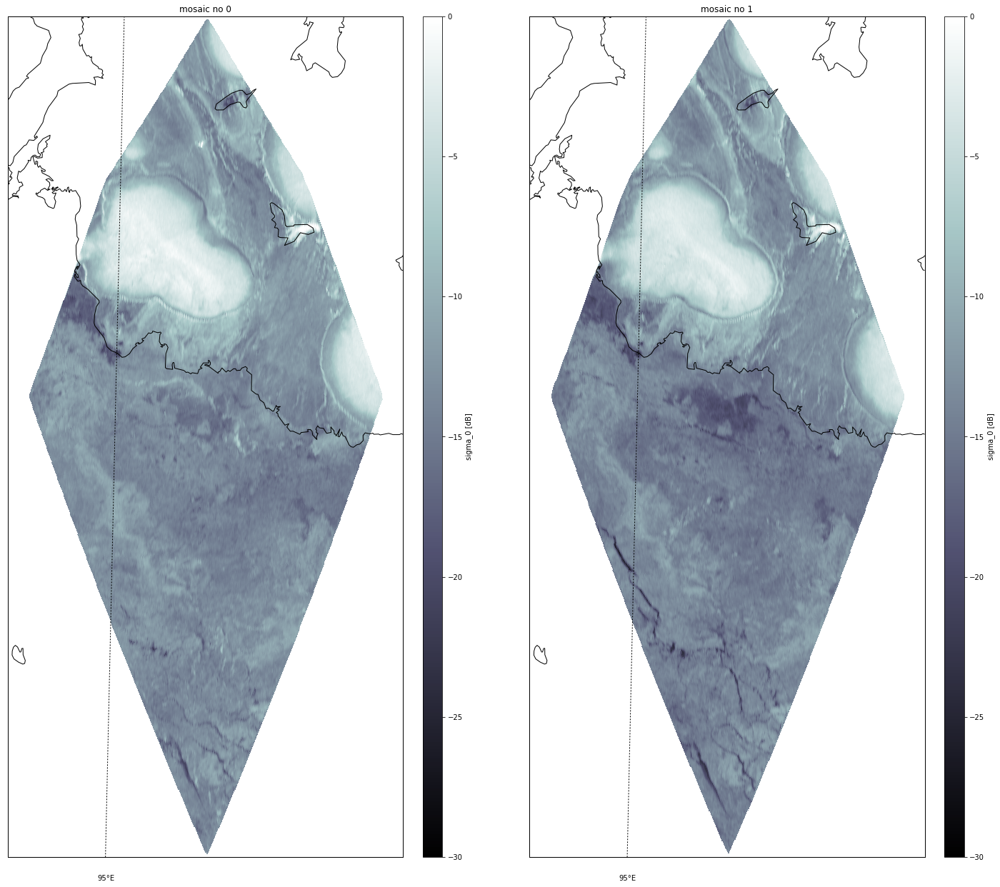

Kara_2014-10-29T100607_2014-10-30T010116_lat-3_lon-2_hh.pickle is created
2014-10-29 13:22:33 2014-10-30 01:01:16
area of intersection 0.0
cond_area False
2014-10-29 13:22:33 2014-10-30 04:18:43
area of intersection 6.51285158327
cond_area True
Images overlap


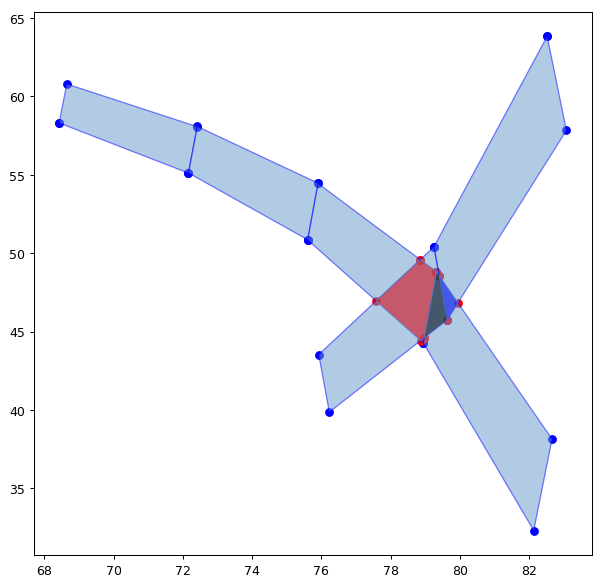

Successful overlap:
['S1A_EW_GRDM_1SDH_20141029T132233_20141029T132337_003045_0037AE_3A4D.zip', 'S1A_EW_GRDM_1SDH_20141029T132337_20141029T132437_003045_0037AE_0550.zip', 'S1A_EW_GRDM_1SDH_20141029T132437_20141029T132537_003045_0037AE_82A6.zip', 'S1A_EW_GRDM_1SDH_20141029T132537_20141029T132639_003045_0037AE_FCF0.zip']
with
['S1A_EW_GRDM_1SDH_20141030T041843_20141030T041947_003054_0037DC_864A.zip', 'S1A_EW_GRDM_1SDH_20141030T041947_20141030T042047_003054_0037DC_7C29.zip']

Time difference is  14:56:10
2014-10-29T132233 2014-10-30T041843
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141029T132233_20141029T132337_003045_0037AE_3A4D.zip
78.9635182484 44.5964805663 79.6364822388 48.8205375671
68.0161 50.6705 72.6826 64.2426
79.4034244883 45.7628555298 79.9400325817 48.5455221585
68.0161 50.6705 72.6826 64.2426
77.5807812716 44.4293222161 79.3171615601 49.58667152
68.0161 50.6705 72.6826 64.2426
False True
/home/cercache/users/atarasen/data/Sentine

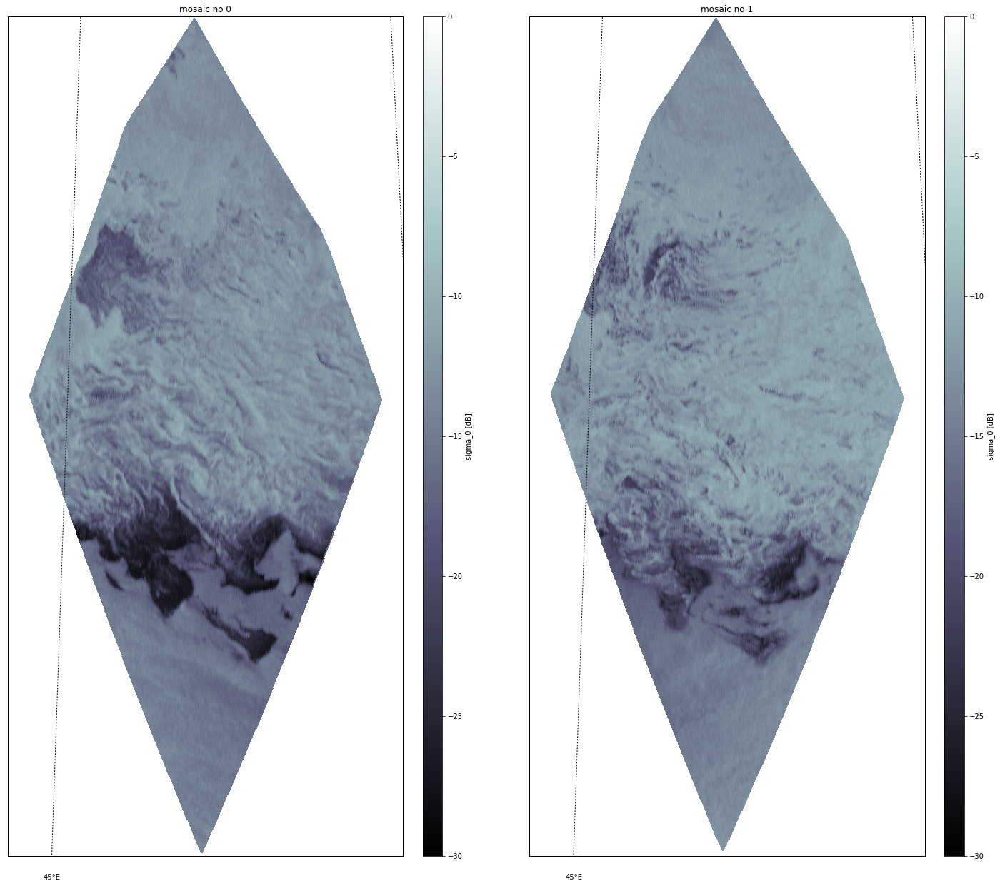

Kara_2014-10-29T132233_2014-10-30T041843_lat-3_lon-2_hh.pickle is created
2014-10-30 01:01:16 2014-10-30 04:18:43
area of intersection 0.0
cond_area False
2014-10-30 01:01:16 2014-10-30 10:49:48
area of intersection 0.0
cond_area False
2014-10-30 01:01:16 2014-10-31 00:03:41
area of intersection 0.0
cond_area False
2014-10-30 01:01:16 2014-10-31 03:21:07
area of intersection 0.0
cond_area False
2014-10-30 01:01:16 2014-10-31 09:50:36
area of intersection 0.000290086663319
cond_area False
2014-10-30 01:01:16 2014-10-31 11:28:23
area of intersection 1.12430861451
cond_area True
Images overlap


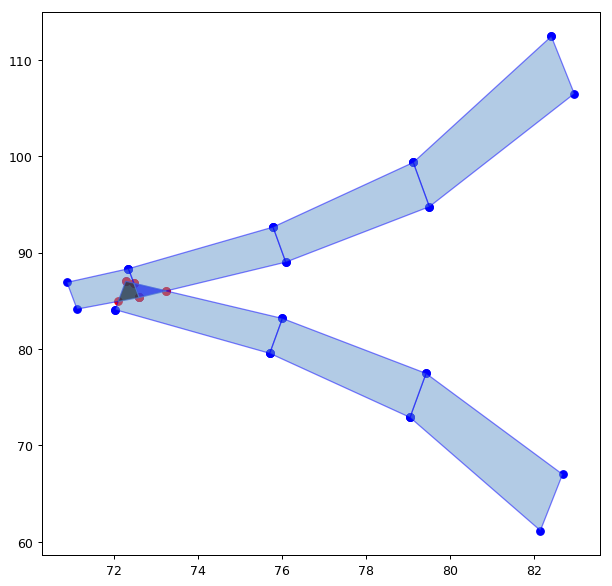

Successful overlap:
['S1A_EW_GRDM_1SDH_20141030T010116_20141030T010220_003052_0037CF_CFF6.zip', 'S1A_EW_GRDM_1SDH_20141030T010220_20141030T010320_003052_0037CF_8FC0.zip', 'S1A_EW_GRDM_1SDH_20141030T010320_20141030T010420_003052_0037CF_3B11.zip', 'S1A_EW_GRDM_1SDH_20141030T010420_20141030T010446_003052_0037CF_A996.zip']
with
['S1A_EW_GRDM_1SDH_20141031T112823_20141031T112927_003073_003848_C258.zip', 'S1A_EW_GRDM_1SDH_20141031T112927_20141031T113027_003073_003848_F3FD.zip', 'S1A_EW_GRDM_1SDH_20141031T113027_20141031T113127_003073_003848_C90B.zip']

Time difference is  1 day, 10:27:07
2014-10-30T010116 2014-10-31T112823
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141030T010116_20141030T010220_003052_0037CF_CFF6.zip
72.1063315079 84.9329991581 72.601890564 87.0101242065
78.3994 88.078 83.538 120.059
72.477165677 85.338722229 73.2458579818 86.8100238289
78.3994 88.078 83.538 120.059
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysi

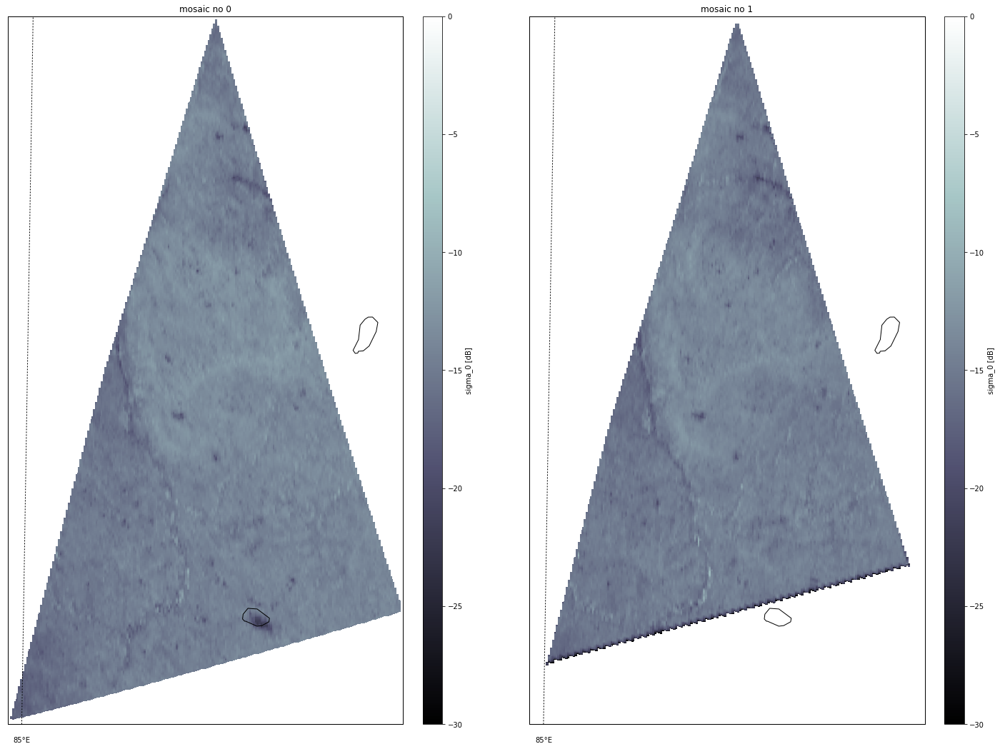

Kara_2014-10-30T010116_2014-10-31T112823_lat-3_lon-2_hh.pickle is created
2014-10-30 04:18:43 2014-10-30 10:49:48
area of intersection 0.0
cond_area False
2014-10-30 04:18:43 2014-10-31 00:03:41
area of intersection 0.0
cond_area False
2014-10-30 04:18:43 2014-10-31 03:21:07
area of intersection 0.0
cond_area False
2014-10-30 04:18:43 2014-10-31 09:50:36
area of intersection 0.0
cond_area False
2014-10-30 04:18:43 2014-10-31 11:28:23
area of intersection 0.173321553823
cond_area False
2014-10-30 04:18:43 2014-11-01 00:44:32
area of intersection 0.0
cond_area False
2014-10-30 04:18:43 2014-11-01 02:23:29
area of intersection 0.0
cond_area False
2014-10-30 04:18:43 2014-11-01 04:01:49
area of intersection 5.47120380057
cond_area True
Images overlap


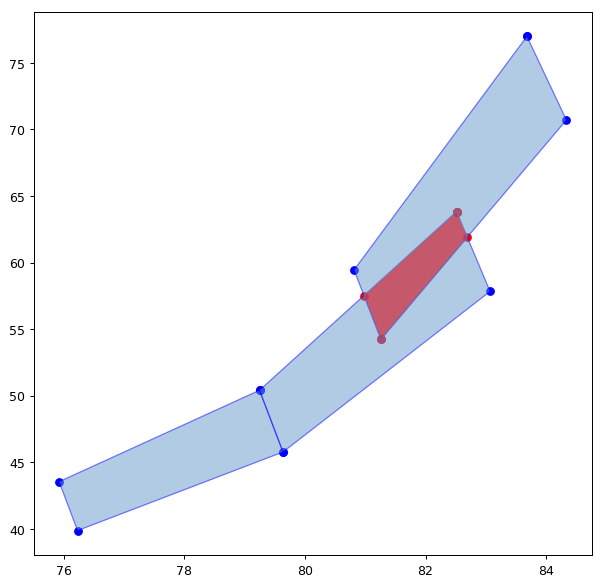

Successful overlap:
['S1A_EW_GRDM_1SDH_20141030T041843_20141030T041947_003054_0037DC_864A.zip', 'S1A_EW_GRDM_1SDH_20141030T041947_20141030T042047_003054_0037DC_7C29.zip']
with
['S1A_EW_GRDM_1SSH_20141101T040149_20141101T040250_003083_003880_C536.zip']

Time difference is  1 day, 23:43:06
2014-10-30T041843 2014-11-01T040149
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141030T041843_20141030T041947_003054_0037DC_864A.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141030T041947_20141030T042047_003054_0037DC_7C29.zip
False True
no HV data found
2014-10-30 10:49:48 2014-10-31 00:03:41
area of intersection 0.0
cond_area False


2014-10-30 10:49:48 2014-10-31 03:21:07
area of intersection 6.9950628055
cond_area True
Images overlap


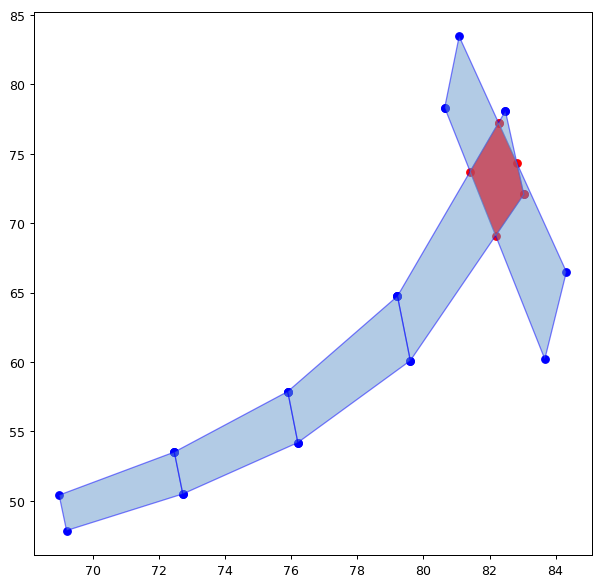

Successful overlap:
['S1A_EW_GRDM_1SSH_20141030T104948_20141030T105052_003058_0037F2_0950.zip']
with
['S1A_EW_GRDM_1SDH_20141031T032107_20141031T032212_003068_00382E_25B6.zip', 'S1A_EW_GRDM_1SDH_20141031T032212_20141031T032312_003068_00382E_3C95.zip', 'S1A_EW_GRDM_1SDH_20141031T032312_20141031T032412_003068_00382E_634E.zip', 'S1A_EW_GRDM_1SDH_20141031T032412_20141031T032512_003068_00382E_CBE7.zip']

Time difference is  16:31:19
2014-10-30T104948 2014-10-31T032107
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SSH_20141030T104948_20141030T105052_003058_0037F2_0950.zip
False True
no HV data found
2014-10-31 00:03:41 2014-10-31 03:21:07
area of intersection 0.0
cond_area False


2014-10-31 00:03:41 2014-10-31 09:50:36
area of intersection 4.70137867834
cond_area True
Images overlap


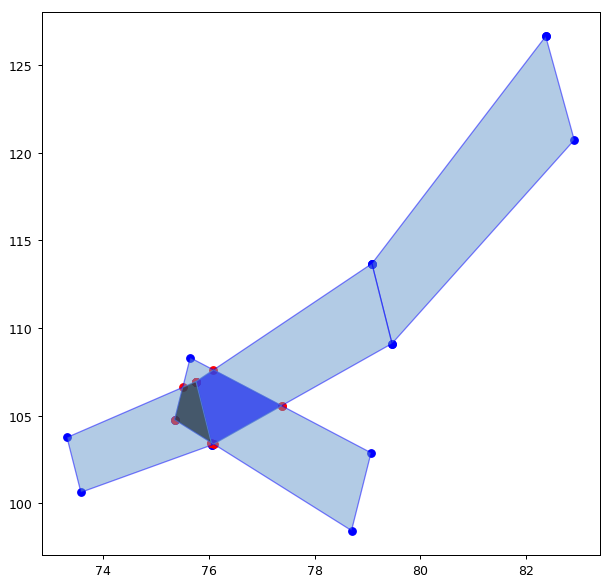

Successful overlap:
['S1A_EW_GRDM_1SDH_20141031T000341_20141031T000445_003066_003820_A819.zip', 'S1A_EW_GRDM_1SDH_20141031T000445_20141031T000545_003066_003820_43DC.zip', 'S1A_EW_GRDM_1SDH_20141031T000545_20141031T000628_003066_003820_462D.zip']
with
['S1A_EW_GRDM_1SDH_20141031T095036_20141031T095136_003072_003840_A6E6.zip']

Time difference is  9:46:55
2014-10-31T000341 2014-10-31T095036
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141031T000341_20141031T000445_003066_003820_A819.zip
75.3490829468 103.470540466 76.0419564478 106.945579529
78.3676 102.459 83.5028 134.237
75.7540969849 103.387464067 77.3724420929 107.611659173
78.3676 102.459 83.5028 134.237
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141031T000445_20141031T000545_003066_003820_43DC.zip
75.3490829468 103.470540466 76.0419564478 106.945579529
75.1872 98.2158 79.8648 120.122
75.7540969849 103.387464067 77.3724420929 107.611659173
75.

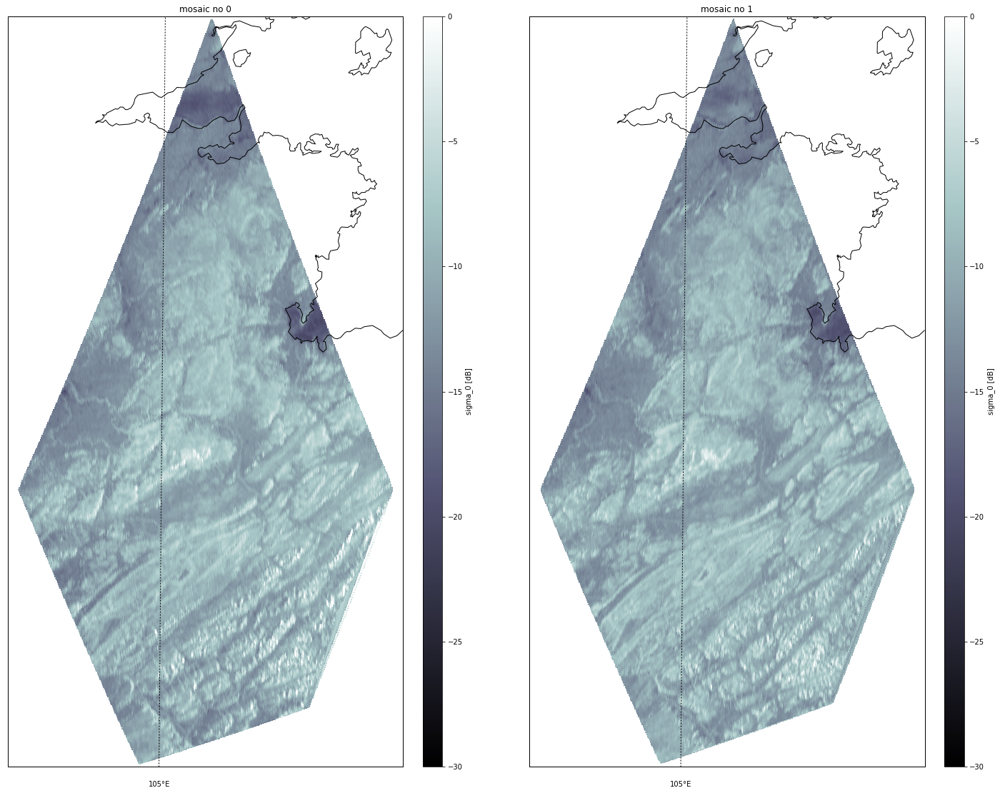

Kara_2014-10-31T000341_2014-10-31T095036_lat-3_lon-2_hh.pickle is created
2014-10-31 03:21:07 2014-10-31 09:50:36
area of intersection 0.0
cond_area False
2014-10-31 03:21:07 2014-10-31 11:28:23
area of intersection 6.78414153078
cond_area True
Images overlap


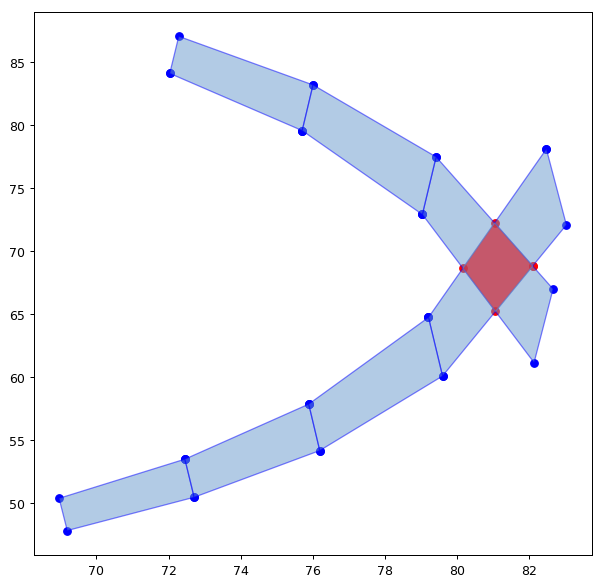

Successful overlap:
['S1A_EW_GRDM_1SDH_20141031T032107_20141031T032212_003068_00382E_25B6.zip', 'S1A_EW_GRDM_1SDH_20141031T032212_20141031T032312_003068_00382E_3C95.zip', 'S1A_EW_GRDM_1SDH_20141031T032312_20141031T032412_003068_00382E_634E.zip', 'S1A_EW_GRDM_1SDH_20141031T032412_20141031T032512_003068_00382E_CBE7.zip']
with
['S1A_EW_GRDM_1SDH_20141031T112823_20141031T112927_003073_003848_C258.zip', 'S1A_EW_GRDM_1SDH_20141031T112927_20141031T113027_003073_003848_F3FD.zip', 'S1A_EW_GRDM_1SDH_20141031T113027_20141031T113127_003073_003848_C90B.zip']

Time difference is  8:07:16
2014-10-31T032107 2014-10-31T112823
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141031T032107_20141031T032212_003068_00382E_25B6.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141031T032212_20141031T032312_003068_00382E_3C95.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141031T0

2014-10-31 09:50:36 2014-11-01 00:44:32
area of intersection 0.0
cond_area False
2014-10-31 09:50:36 2014-11-01 02:23:29
area of intersection 0.0
cond_area False
2014-10-31 09:50:36 2014-11-01 04:01:49
area of intersection 0.0
cond_area False
2014-10-31 09:50:36 2014-11-01 10:32:16
area of intersection 0.0
cond_area False
2014-10-31 09:50:36 2014-11-01 13:47:04
area of intersection 0.0
cond_area False
2014-10-31 09:50:36 2014-11-02 01:25:57
area of intersection 0.0
cond_area False
2014-10-31 09:50:36 2014-11-02 04:43:20
area of intersection 0.0
cond_area False
2014-10-31 09:50:36 2014-11-02 11:14:38
area of intersection 0.0
cond_area False
2014-10-31 09:50:36 2014-11-03 00:28:21
area of intersection 6.28894723112
cond_area True
Images overlap


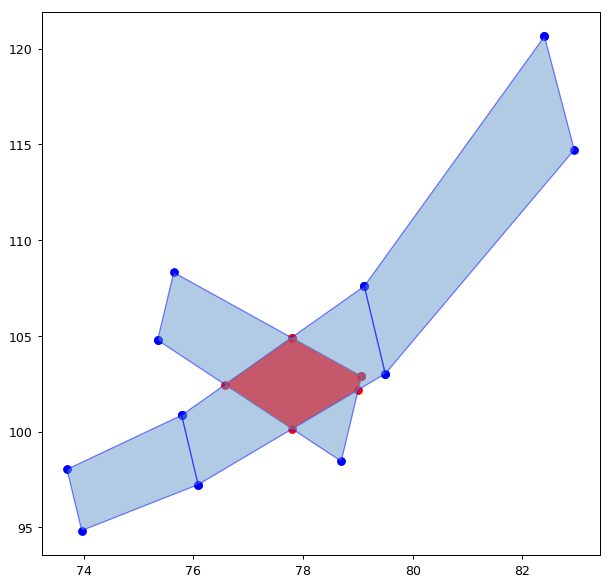

Successful overlap:
['S1A_EW_GRDM_1SDH_20141031T095036_20141031T095136_003072_003840_A6E6.zip']
with
['S1A_EW_GRDM_1SDH_20141103T002821_20141103T002926_003110_003914_D44C.zip', 'S1A_EW_GRDM_1SDH_20141103T002926_20141103T003026_003110_003914_3BFE.zip', 'S1A_EW_GRDM_1SDH_20141103T003026_20141103T003102_003110_003914_8ADF.zip']

Time difference is  2 days, 14:37:45
2014-10-31T095036 2014-11-03T002821
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141031T095036_20141031T095136_003072_003840_A6E6.zip
False True
no HV data found
2014-10-31 11:28:23 2014-11-01 00:44:32
area of intersection 0.0
cond_area False


2014-10-31 11:28:23 2014-11-01 02:23:29
area of intersection 6.60607794902
cond_area True
Images overlap


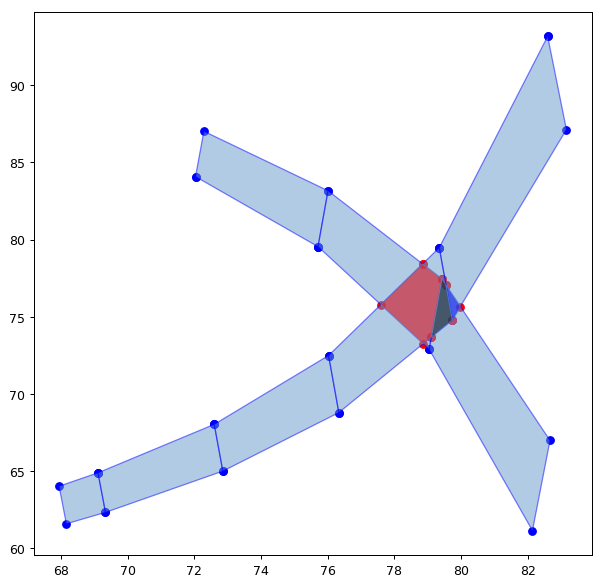

Successful overlap:
['S1A_EW_GRDM_1SDH_20141031T112823_20141031T112927_003073_003848_C258.zip', 'S1A_EW_GRDM_1SDH_20141031T112927_20141031T113027_003073_003848_F3FD.zip', 'S1A_EW_GRDM_1SDH_20141031T113027_20141031T113127_003073_003848_C90B.zip']
with
['S1A_EW_GRDM_1SDH_20141101T022329_20141101T022433_003082_00387B_831A.zip', 'S1A_EW_GRDM_1SDH_20141101T022433_20141101T022533_003082_00387B_077E.zip', 'S1A_EW_GRDM_1SDH_20141101T022533_20141101T022633_003082_00387B_6142.zip', 'S1A_EW_GRDM_1SDH_20141101T022633_20141101T022733_003082_00387B_6529.zip', 'S1A_EW_GRDM_1SDH_20141101T022733_20141101T022753_003082_00387B_B2D1.zip']

Time difference is  14:55:06
2014-10-31T112823 2014-11-01T022329
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141031T112823_20141031T112927_003073_003848_C258.zip
79.1074985854 73.6861047033 79.7365112305 77.4591827393
71.5594 74.2282 76.3232 91.1002
79.5466942258 74.7948989868 79.9786935516 77.0598224125
71.5594 74.2282 76.32

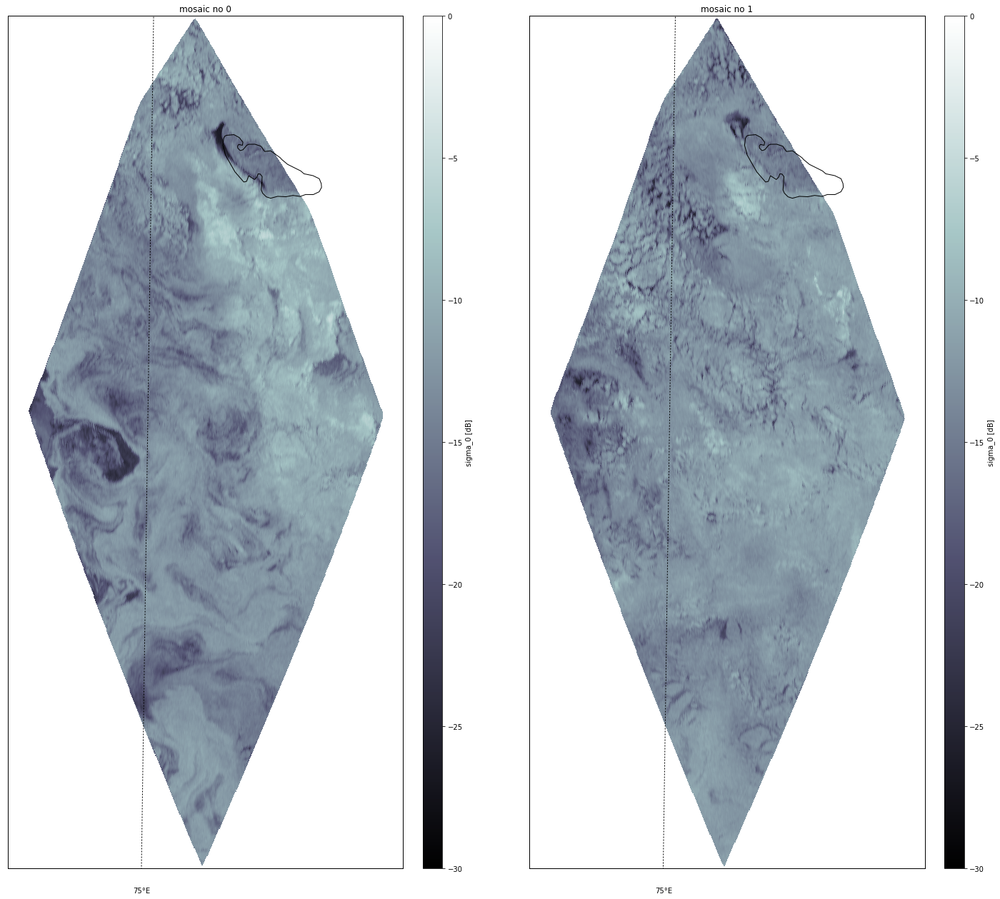

Kara_2014-10-31T112823_2014-11-01T022329_lat-3_lon-2_hh.pickle is created
2014-11-01 00:44:32 2014-11-01 02:23:29
area of intersection 0.0
cond_area False
2014-11-01 00:44:32 2014-11-01 04:01:49
area of intersection 0.0
cond_area False
2014-11-01 00:44:32 2014-11-01 10:32:16
area of intersection 0.0
cond_area False
2014-11-01 00:44:32 2014-11-01 13:47:04
area of intersection 0.0
cond_area False
2014-11-01 00:44:32 2014-11-02 01:25:57
area of intersection 0.0
cond_area False
2014-11-01 00:44:32 2014-11-02 04:43:20
area of intersection 0.0
cond_area False
2014-11-01 00:44:32 2014-11-02 11:14:38
area of intersection 0.0
cond_area False
2014-11-01 00:44:32 2014-11-03 00:28:21
area of intersection 8.00108951447
cond_area True
Images overlap


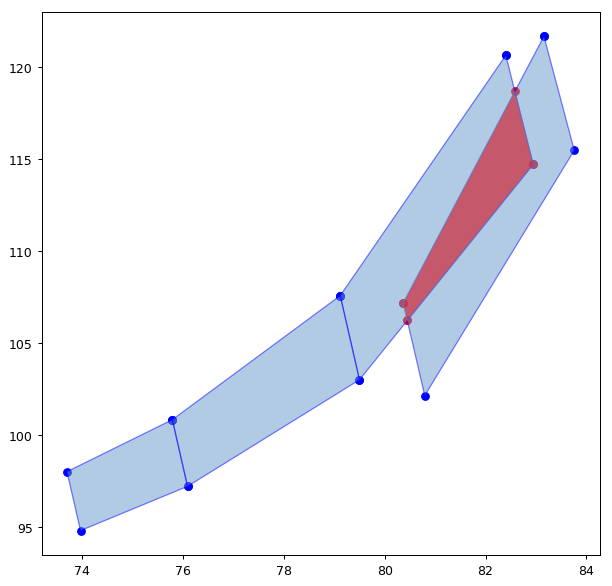

Successful overlap:
['S1A_EW_GRDM_1SSH_20141101T004432_20141101T004530_003081_003872_88A7.zip']
with
['S1A_EW_GRDM_1SDH_20141103T002821_20141103T002926_003110_003914_D44C.zip', 'S1A_EW_GRDM_1SDH_20141103T002926_20141103T003026_003110_003914_3BFE.zip', 'S1A_EW_GRDM_1SDH_20141103T003026_20141103T003102_003110_003914_8ADF.zip']

Time difference is  1 day, 23:43:49
2014-11-01T004432 2014-11-03T002821
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SSH_20141101T004432_20141101T004530_003081_003872_88A7.zip
False True
no HV data found
2014-11-01 02:23:29 2014-11-01 04:01:49
area of intersection 0.0
cond_area False


2014-11-01 02:23:29 2014-11-01 10:32:16
area of intersection 6.19892467581
cond_area True
Images overlap


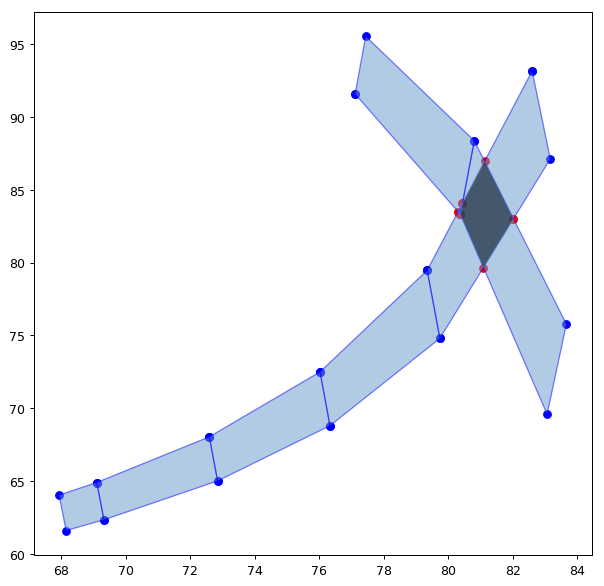

Successful overlap:
['S1A_EW_GRDM_1SDH_20141101T022329_20141101T022433_003082_00387B_831A.zip', 'S1A_EW_GRDM_1SDH_20141101T022433_20141101T022533_003082_00387B_077E.zip', 'S1A_EW_GRDM_1SDH_20141101T022533_20141101T022633_003082_00387B_6142.zip', 'S1A_EW_GRDM_1SDH_20141101T022633_20141101T022733_003082_00387B_6529.zip', 'S1A_EW_GRDM_1SDH_20141101T022733_20141101T022753_003082_00387B_B2D1.zip']
with
['S1A_EW_GRDM_1SDH_20141101T103216_20141101T103316_003087_003892_C6F7.zip', 'S1A_EW_GRDM_1SDH_20141101T103316_20141101T103411_003087_003892_FFA0.zip']

Time difference is  8:08:47
2014-11-01T022329 2014-11-01T103216
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141101T022329_20141101T022433_003082_00387B_831A.zip
80.3734207153 79.6642286632 82.0174148231 86.9577886654
78.6079 67.9329 83.774 100.823
80.3018007646 83.3187332153 80.4368073221 84.0675976788
78.6079 67.9329 83.774 100.823
False False
/home/cercache/users/atarasen/data/Sentinel-1_analysis/

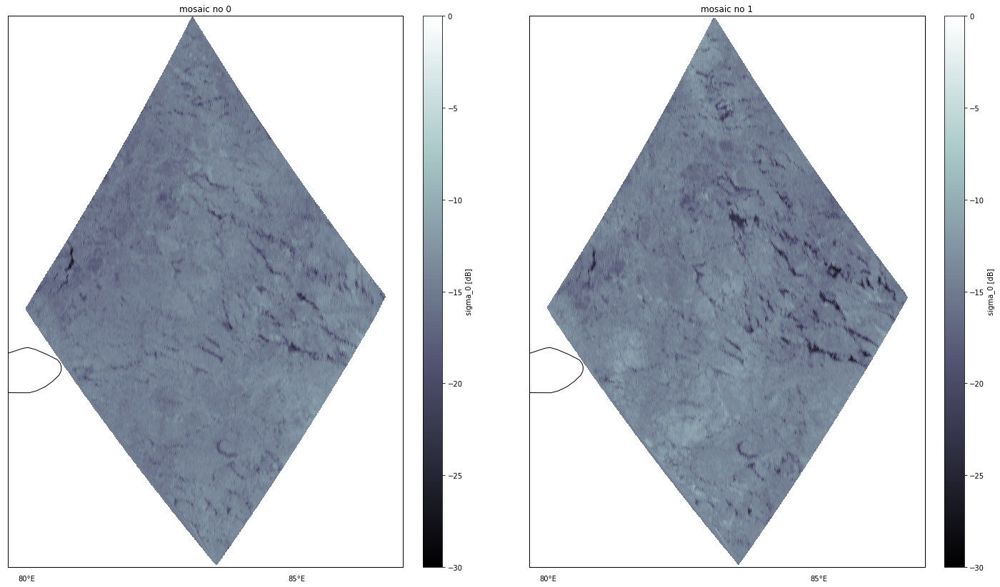

Kara_2014-11-01T022329_2014-11-01T103216_lat-3_lon-2_hh.pickle is created
2014-11-01 04:01:49 2014-11-01 10:32:16
area of intersection 1.92378540034
cond_area True
Images overlap


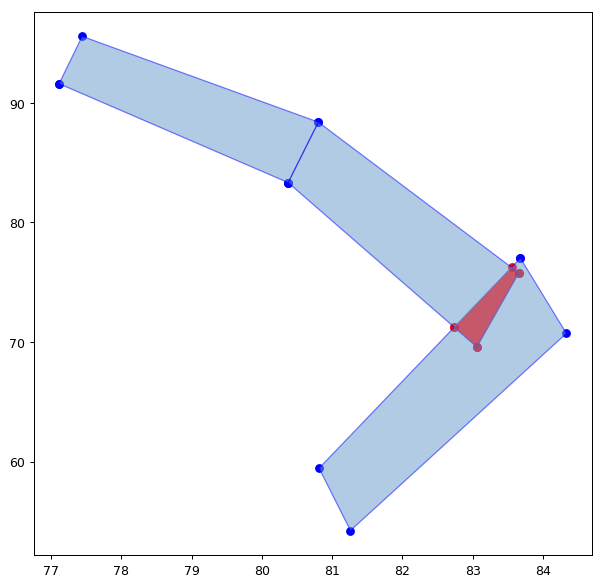

Successful overlap:
['S1A_EW_GRDM_1SSH_20141101T040149_20141101T040250_003083_003880_C536.zip']
with
['S1A_EW_GRDM_1SDH_20141101T103216_20141101T103316_003087_003892_C6F7.zip', 'S1A_EW_GRDM_1SDH_20141101T103316_20141101T103411_003087_003892_FFA0.zip']

Time difference is  6:30:27
2014-11-01T040149 2014-11-01T103216
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SSH_20141101T040149_20141101T040250_003083_003880_C536.zip
False True
no HV data found
2014-11-01 10:32:16 2014-11-01 13:47:04
area of intersection 0.0
cond_area False


2014-11-01 10:32:16 2014-11-02 01:25:57
area of intersection 6.32593608321
cond_area True
Images overlap


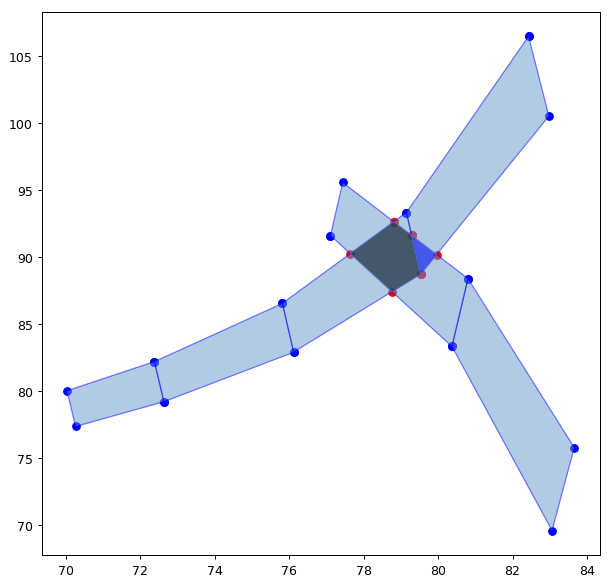

Successful overlap:
['S1A_EW_GRDM_1SDH_20141101T103216_20141101T103316_003087_003892_C6F7.zip', 'S1A_EW_GRDM_1SDH_20141101T103316_20141101T103411_003087_003892_FFA0.zip']
with
['S1A_EW_GRDM_1SDH_20141102T012557_20141102T012701_003096_0038C7_C60A.zip', 'S1A_EW_GRDM_1SDH_20141102T012701_20141102T012801_003096_0038C7_62D7.zip', 'S1A_EW_GRDM_1SDH_20141102T012801_20141102T012901_003096_0038C7_4AD2.zip', 'S1A_EW_GRDM_1SDH_20141102T012901_20141102T012941_003096_0038C7_D101.zip']

Time difference is  14:53:41
2014-11-01T103216 2014-11-02T012557
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141101T103216_20141101T103316_003087_003892_C6F7.zip
77.6429864532 87.3981520588 79.5330200195 92.6150060647
76.4901 76.3589 81.2564 101.19
79.2920984077 88.7105255127 79.9597784799 91.5934195522
76.4901 76.3589 81.2564 101.19
False False
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141101T103316_20141101T103411_003087_003892_FFA0.z

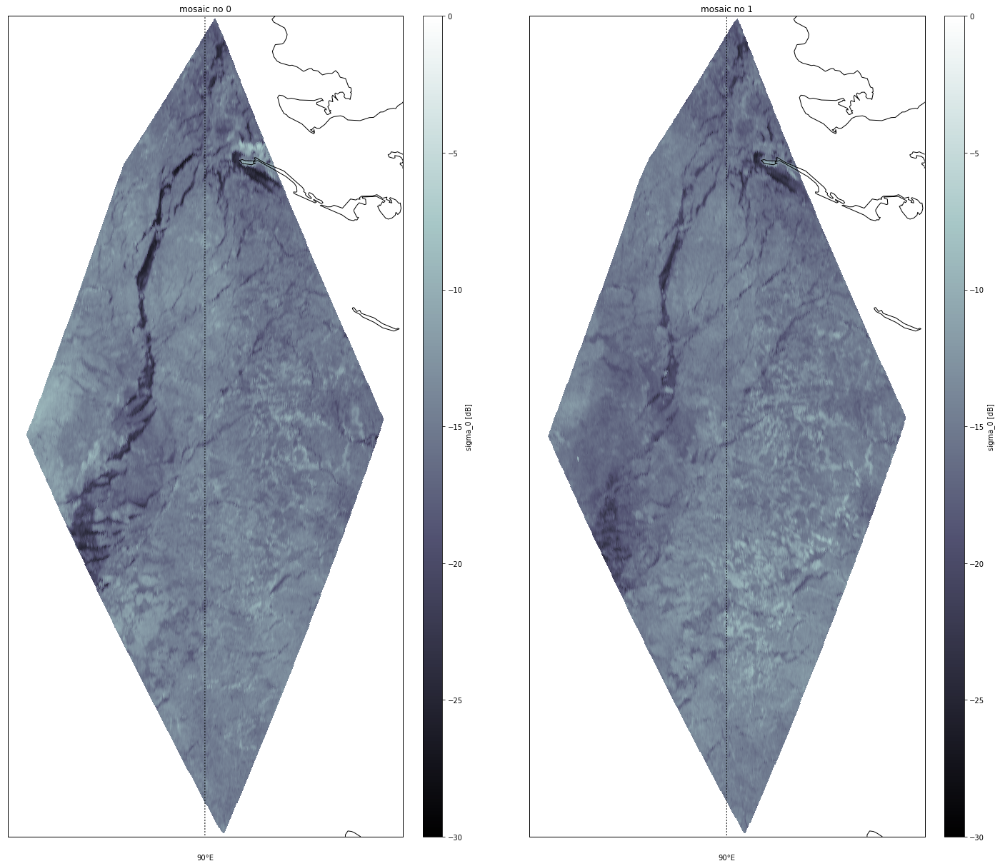

Kara_2014-11-01T103216_2014-11-02T012557_lat-3_lon-2_hh.pickle is created
2014-11-01 13:47:04 2014-11-02 01:25:57
area of intersection 0.0
cond_area False
2014-11-01 13:47:04 2014-11-02 04:43:20
area of intersection 0.0
cond_area False
2014-11-01 13:47:04 2014-11-02 11:14:38
area of intersection 0.0
cond_area False
2014-11-01 13:47:04 2014-11-03 00:28:21
area of intersection 0.0
cond_area False
2014-11-01 13:47:04 2014-11-03 03:46:52
area of intersection 5.91872475378
cond_area True
Images overlap


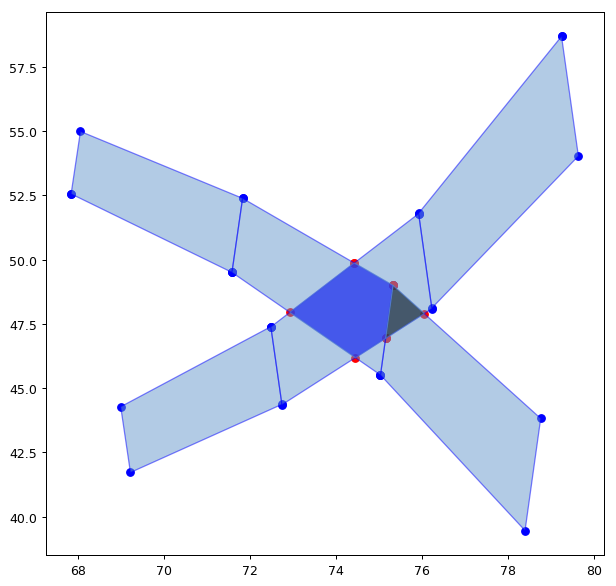

Successful overlap:
['S1A_EW_GRDM_1SDH_20141101T134704_20141101T134808_003089_0038A1_54A9.zip', 'S1A_EW_GRDM_1SDH_20141101T134808_20141101T134908_003089_0038A1_3D04.zip', 'S1A_EW_GRDM_1SDH_20141101T134908_20141101T135008_003089_0038A1_5231.zip']
with
['S1A_EW_GRDM_1SDH_20141103T034652_20141103T034752_003112_003920_504D.zip', 'S1A_EW_GRDM_1SDH_20141103T034752_20141103T034852_003112_003920_85FF.zip', 'S1A_EW_GRDM_1SDH_20141103T034852_20141103T034952_003112_003920_C021.zip']

Time difference is  1 day, 13:59:48
2014-11-01T134704 2014-11-03T034652
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141101T134704_20141101T134808_003089_0038A1_54A9.zip
75.1547441616 46.9422339852 76.0511165359 48.9967002869
67.4394 45.1775 72.0928 58.3387
72.9299334019 46.1889064248 75.3261947632 49.8700238821
67.4394 45.1775 72.0928 58.3387
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141101T134808_20141101T134908_003089_0038A

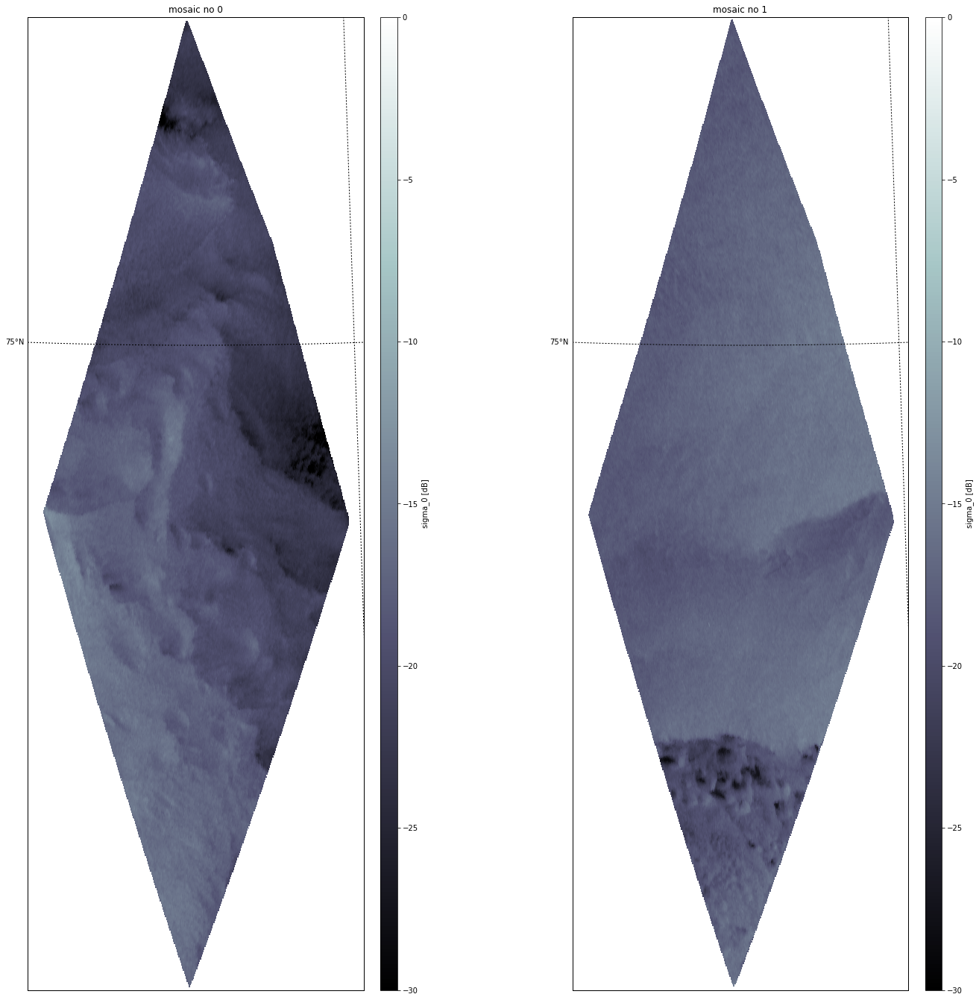

Kara_2014-11-01T134704_2014-11-03T034652_lat-3_lon-2_hh.pickle is created
2014-11-02 01:25:57 2014-11-02 04:43:20
area of intersection 0.0
cond_area False
2014-11-02 01:25:57 2014-11-02 11:14:38
area of intersection 0.0
cond_area False
2014-11-02 01:25:57 2014-11-03 00:28:21
area of intersection 0.0
cond_area False
2014-11-02 01:25:57 2014-11-03 03:46:52
area of intersection 0.0
cond_area False
2014-11-02 01:25:57 2014-11-03 08:37:13
area of intersection 0.0
cond_area False
2014-11-02 01:25:57 2014-11-03 11:52:54
area of intersection 2.59706828936
cond_area True
Images overlap


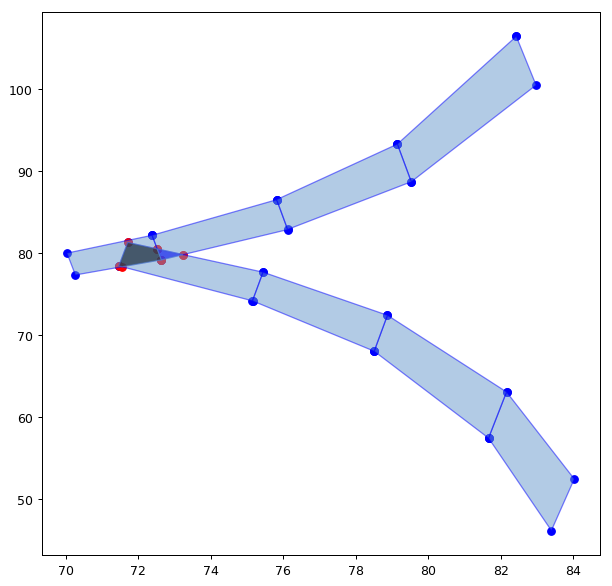

Successful overlap:
['S1A_EW_GRDM_1SDH_20141102T012557_20141102T012701_003096_0038C7_C60A.zip', 'S1A_EW_GRDM_1SDH_20141102T012701_20141102T012801_003096_0038C7_62D7.zip', 'S1A_EW_GRDM_1SDH_20141102T012801_20141102T012901_003096_0038C7_4AD2.zip', 'S1A_EW_GRDM_1SDH_20141102T012901_20141102T012941_003096_0038C7_D101.zip']
with
['S1A_EW_GRDM_1SDH_20141103T115254_20141103T115358_003117_003941_A507.zip', 'S1A_EW_GRDM_1SDH_20141103T115358_20141103T115458_003117_003941_8A13.zip', 'S1A_EW_GRDM_1SDH_20141103T115458_20141103T115558_003117_003941_0FFA.zip', 'S1A_EW_GRDM_1SDH_20141103T115558_20141103T115636_003117_003941_3EBD.zip']

Time difference is  1 day, 10:26:57
2014-11-02T012557 2014-11-03T115254
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141102T012557_20141102T012701_003096_0038C7_C60A.zip
71.4681930542 78.3515270456 72.6389694214 81.3065567017
78.4283 81.9907 83.5726 114.063
72.5270183785 79.1949081421 73.2375859683 80.5167519908
78.4283 81.990

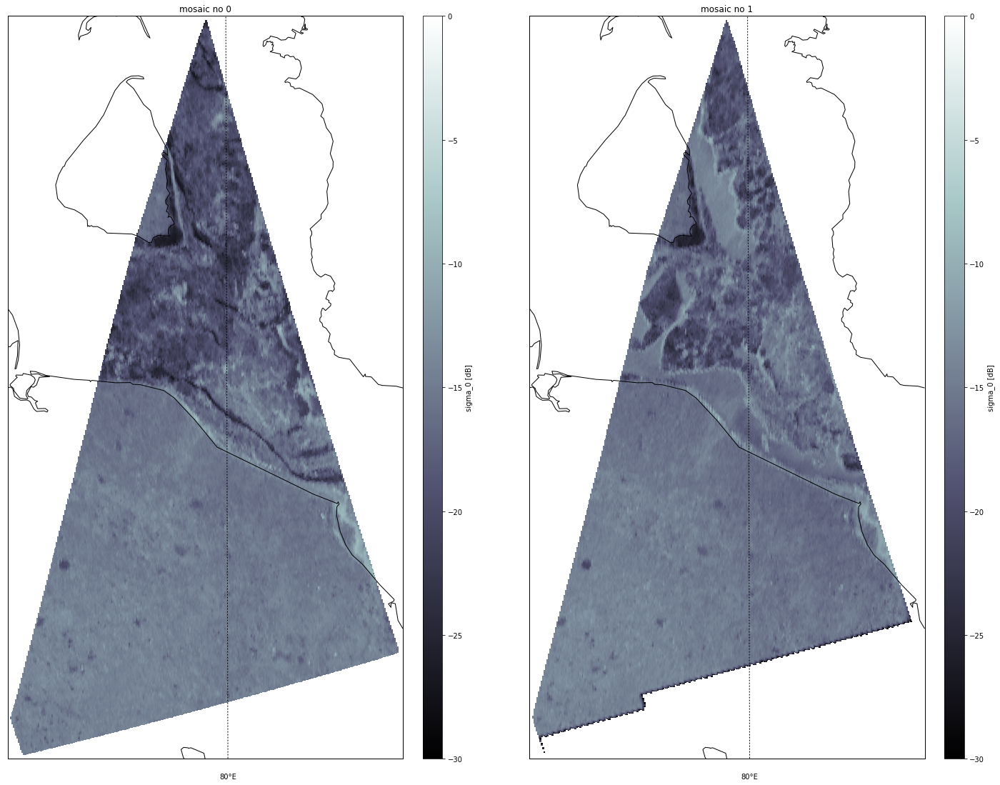

Kara_2014-11-02T012557_2014-11-03T115254_lat-3_lon-2_hh.pickle is created
2014-11-02 04:43:20 2014-11-02 11:14:38
area of intersection 0.0
cond_area False
2014-11-02 04:43:20 2014-11-03 00:28:21
area of intersection 0.0
cond_area False
2014-11-02 04:43:20 2014-11-03 03:46:52
area of intersection 0.0
cond_area False
2014-11-02 04:43:20 2014-11-03 08:37:13
area of intersection 0.0
cond_area False
2014-11-02 04:43:20 2014-11-03 11:52:54
area of intersection 5.20977061388
cond_area True
Images overlap


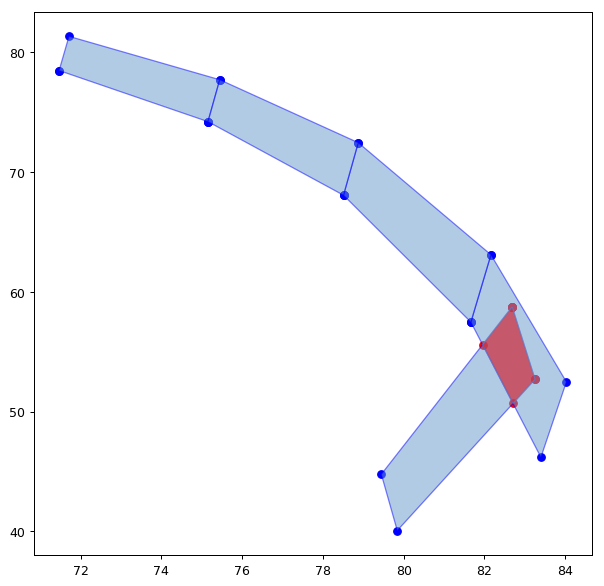

Successful overlap:
['S1A_EW_GRDM_1SDH_20141102T044320_20141102T044425_003098_0038D0_A887.zip']
with
['S1A_EW_GRDM_1SDH_20141103T115254_20141103T115358_003117_003941_A507.zip', 'S1A_EW_GRDM_1SDH_20141103T115358_20141103T115458_003117_003941_8A13.zip', 'S1A_EW_GRDM_1SDH_20141103T115458_20141103T115558_003117_003941_0FFA.zip', 'S1A_EW_GRDM_1SDH_20141103T115558_20141103T115636_003117_003941_3EBD.zip']

Time difference is  1 day, 7:09:34
2014-11-02T044320 2014-11-03T115254
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141102T044320_20141102T044425_003098_0038D0_A887.zip
False True
no HV data found
2014-11-02 11:14:38 2014-11-03 00:28:21
area of intersection 0.0
cond_area False


2014-11-02 11:14:38 2014-11-03 03:46:52
area of intersection 0.0
cond_area False
2014-11-02 11:14:38 2014-11-03 08:37:13
area of intersection 0.0
cond_area False
2014-11-02 11:14:38 2014-11-03 11:52:54
area of intersection 2.01551655208
cond_area True
Images overlap


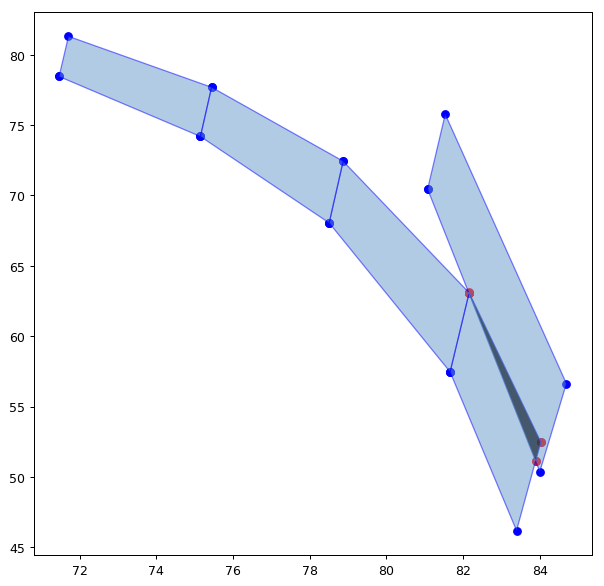

Successful overlap:
['S1A_EW_GRDM_1SSH_20141102T111438_20141102T111542_003102_0038E9_42BF.zip']
with
['S1A_EW_GRDM_1SDH_20141103T115254_20141103T115358_003117_003941_A507.zip', 'S1A_EW_GRDM_1SDH_20141103T115358_20141103T115458_003117_003941_8A13.zip', 'S1A_EW_GRDM_1SDH_20141103T115458_20141103T115558_003117_003941_0FFA.zip', 'S1A_EW_GRDM_1SDH_20141103T115558_20141103T115636_003117_003941_3EBD.zip']

Time difference is  1 day, 0:38:16
2014-11-02T111438 2014-11-03T115254
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SSH_20141102T111438_20141102T111542_003102_0038E9_42BF.zip
82.1578726424 51.131177631 84.0291824341 63.0804443359
80.2313 43.2023 85.498 83.8642
82.146633148 63.0465552803 82.1607131958 63.1218261944
80.2313 43.2023 85.498 83.8642
False False
82.147 84.028 51.13 63.11
Elapsed time is 12.5100579262 seconds.
Mosaic  1
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141103T115254_20141103T115358_003117_003941_A5

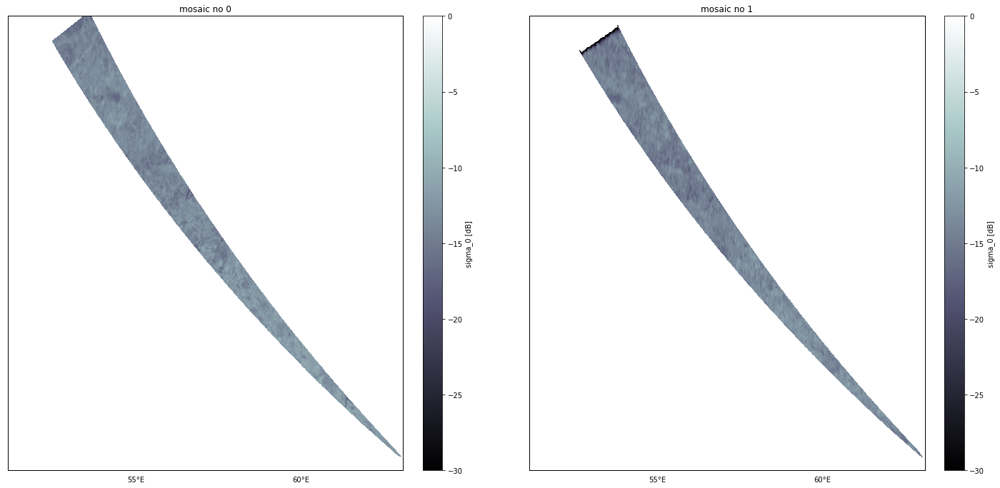

Kara_2014-11-02T111438_2014-11-03T115254_lat-3_lon-2_hh.pickle is created
2014-11-03 00:28:21 2014-11-03 03:46:52
area of intersection 0.0
cond_area False
2014-11-03 00:28:21 2014-11-03 08:37:13
area of intersection 2.46478843444
cond_area True
Images overlap


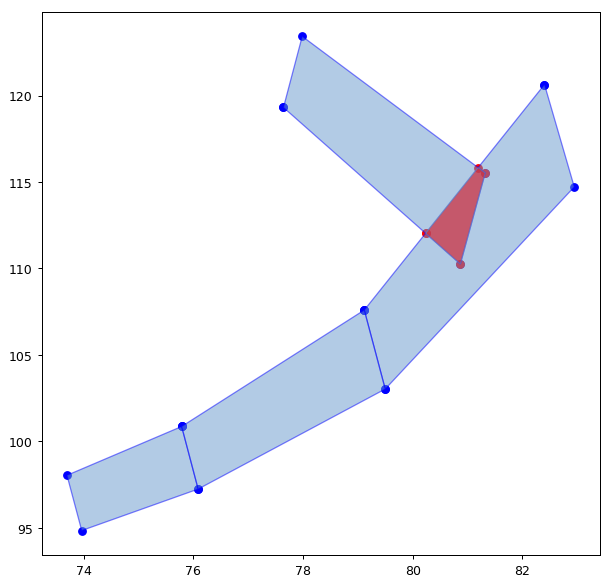

Successful overlap:
['S1A_EW_GRDM_1SDH_20141103T002821_20141103T002926_003110_003914_D44C.zip', 'S1A_EW_GRDM_1SDH_20141103T002926_20141103T003026_003110_003914_3BFE.zip', 'S1A_EW_GRDM_1SDH_20141103T003026_20141103T003102_003110_003914_8ADF.zip']
with
['S1A_EW_GRDM_1SDH_20141103T083713_20141103T083813_003115_003933_9283.zip']

Time difference is  8:08:52
2014-11-03T002821 2014-11-03T083713
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141103T002821_20141103T002926_003110_003914_D44C.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141103T002926_20141103T003026_003110_003914_3BFE.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141103T003026_20141103T003102_003110_003914_8ADF.zip
False True
no HV data found
2014-11-03 03:46:52 2014-11-03 08:37:13
area of intersection 0.0
cond_area False


2014-11-03 03:46:52 2014-11-03 11:52:54
area of intersection 0.0
cond_area False
2014-11-03 03:46:52 2014-11-03 13:33:19
area of intersection 0.0
cond_area False
2014-11-03 03:46:52 2014-11-03 23:32:53
area of intersection 0.0
cond_area False
2014-11-03 03:46:52 2014-11-04 01:09:10
area of intersection 0.0
cond_area False
2014-11-03 03:46:52 2014-11-04 02:48:13
area of intersection 0.0
cond_area False
2014-11-03 03:46:52 2014-11-04 04:26:55
area of intersection 0.0
cond_area False
2014-11-03 03:46:52 2014-11-04 10:56:04
area of intersection 0.0
cond_area False
2014-11-03 03:46:52 2014-11-05 05:07:58
area of intersection 0.0
cond_area False
2014-11-03 03:46:52 2014-11-05 09:57:49
area of intersection 0.0
cond_area False
2014-11-03 03:46:52 2014-11-05 13:14:22
area of intersection 5.76223668452
cond_area True
Images overlap


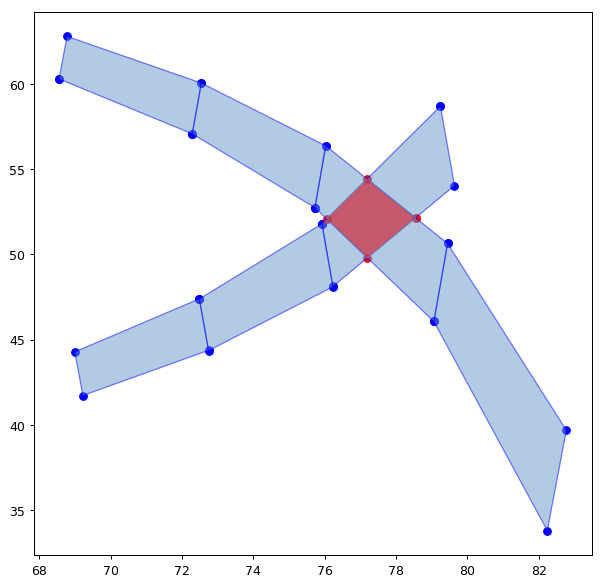

Successful overlap:
['S1A_EW_GRDM_1SDH_20141103T034652_20141103T034752_003112_003920_504D.zip', 'S1A_EW_GRDM_1SDH_20141103T034752_20141103T034852_003112_003920_85FF.zip', 'S1A_EW_GRDM_1SDH_20141103T034852_20141103T034952_003112_003920_C021.zip']
with
['S1A_EW_GRDM_1SDH_20141105T131422_20141105T131526_003147_0039E0_986B.zip', 'S1A_EW_GRDM_1SDH_20141105T131526_20141105T131626_003147_0039E0_244E.zip', 'S1A_EW_GRDM_1SDH_20141105T131626_20141105T131726_003147_0039E0_8EF5.zip', 'S1A_EW_GRDM_1SDH_20141105T131726_20141105T131827_003147_0039E0_F207.zip']

Time difference is  2 days, 9:27:30
2014-11-03T034652 2014-11-05T131422
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141103T034652_20141103T034752_003112_003920_504D.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141103T034752_20141103T034852_003112_003920_85FF.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20

2014-11-03 08:37:13 2014-11-03 13:33:19
area of intersection 0.0
cond_area False
2014-11-03 08:37:13 2014-11-03 23:32:53
area of intersection 0.0
cond_area False
2014-11-03 08:37:13 2014-11-04 01:09:10
area of intersection 0.0
cond_area False
2014-11-03 08:37:13 2014-11-04 02:48:13
area of intersection 0.0
cond_area False
2014-11-03 08:37:13 2014-11-04 04:26:55
area of intersection 0.0
cond_area False
2014-11-03 08:37:13 2014-11-04 10:56:04
area of intersection 0.0
cond_area False
2014-11-03 08:37:13 2014-11-05 05:07:58
area of intersection 0.0
cond_area False
2014-11-03 08:37:13 2014-11-05 09:57:49
area of intersection 0.0
cond_area False
2014-11-03 08:37:13 2014-11-05 13:14:22
area of intersection 0.0
cond_area False
2014-11-03 08:37:13 2014-11-06 00:52:44
area of intersection 0.0
cond_area False
2014-11-03 08:37:13 2014-11-06 02:31:44
area of intersection 0.0
cond_area False
2014-11-03 08:37:13 2014-11-06 04:09:58
area of intersection 0.0
cond_area False
2014-11-03 11:52:54 2014-11-

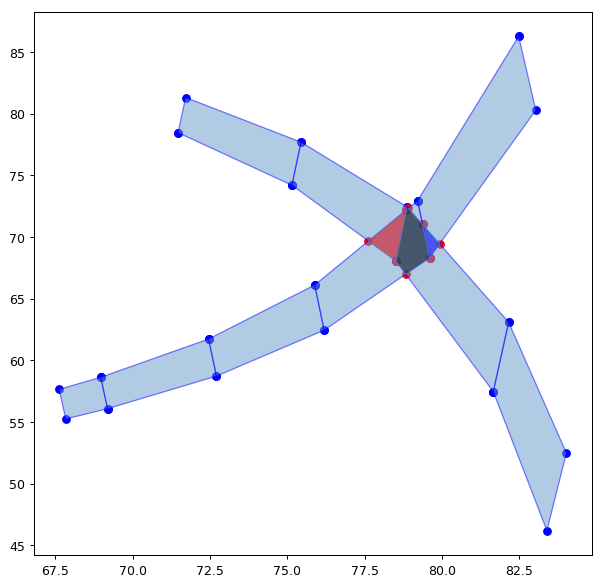

Successful overlap:
['S1A_EW_GRDM_1SDH_20141103T115254_20141103T115358_003117_003941_A507.zip', 'S1A_EW_GRDM_1SDH_20141103T115358_20141103T115458_003117_003941_8A13.zip', 'S1A_EW_GRDM_1SDH_20141103T115458_20141103T115558_003117_003941_0FFA.zip', 'S1A_EW_GRDM_1SDH_20141103T115558_20141103T115636_003117_003941_3EBD.zip']
with
['S1A_EW_GRDM_1SDH_20141104T024813_20141104T024917_003126_003974_210A.zip', 'S1A_EW_GRDM_1SDH_20141104T024917_20141104T025017_003126_003974_ED36.zip', 'S1A_EW_GRDM_1SDH_20141104T025017_20141104T025117_003126_003974_9385.zip', 'S1A_EW_GRDM_1SDH_20141104T025117_20141104T025217_003126_003974_B1E1.zip', 'S1A_EW_GRDM_1SDH_20141104T025217_20141104T025240_003126_003974_407E.zip']

Time difference is  14:55:19
2014-11-03T115254 2014-11-04T024813
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141103T115254_20141103T115358_003117_003941_A507.zip
78.5107879639 66.9753995825 79.6029129028 72.3186031149
71.0058 69.0331 75.7506 85.2755
79

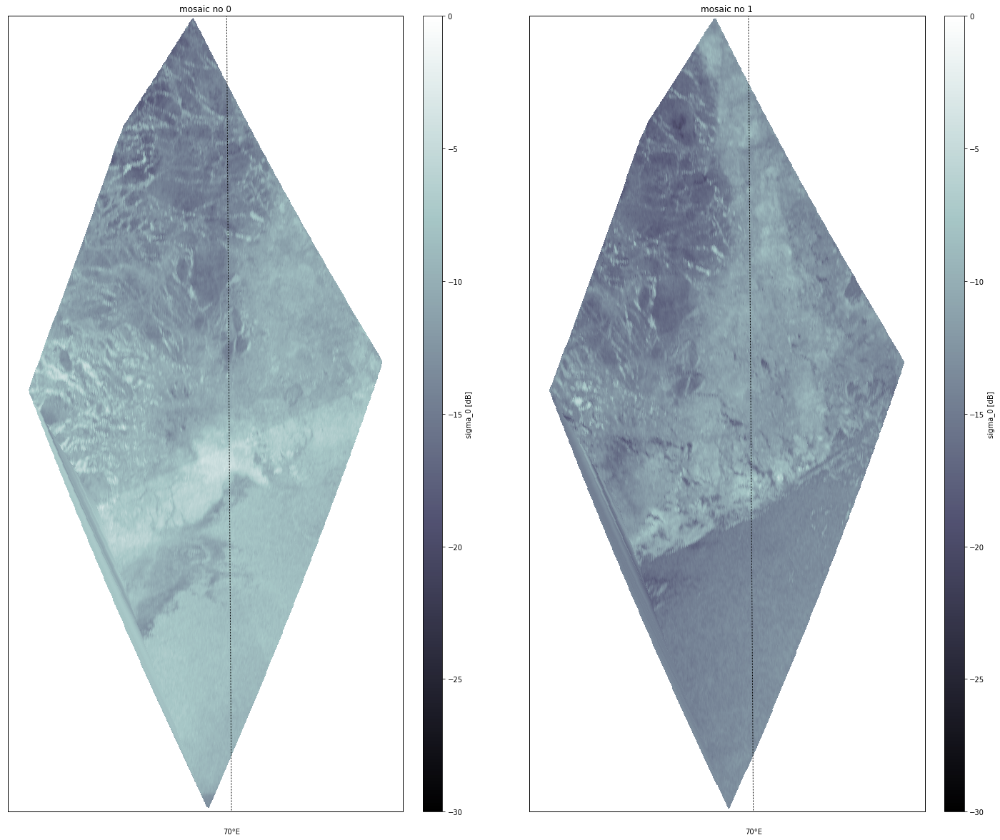

Kara_2014-11-03T115254_2014-11-04T024813_lat-3_lon-2_hh.pickle is created
2014-11-03 13:33:19 2014-11-03 23:32:53
area of intersection 0.0
cond_area False
2014-11-03 13:33:19 2014-11-04 01:09:10
area of intersection 0.0
cond_area False
2014-11-03 13:33:19 2014-11-04 02:48:13
area of intersection 0.0
cond_area False
2014-11-03 13:33:19 2014-11-04 04:26:55
area of intersection 6.28527437241
cond_area True
Images overlap


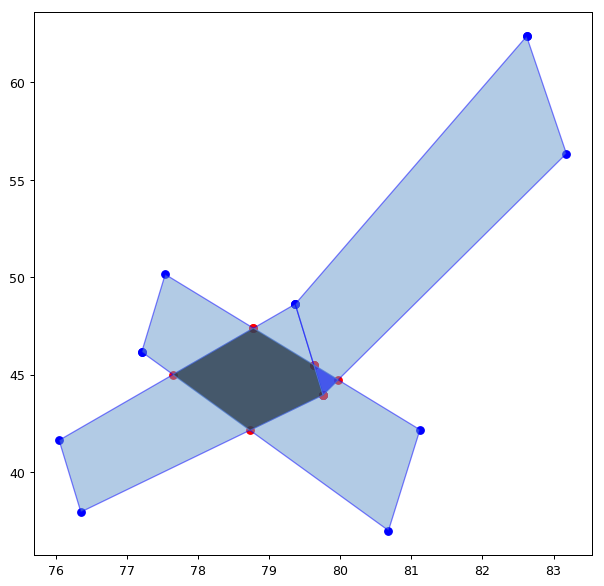

Successful overlap:
['S1A_EW_GRDM_1SDH_20141103T133319_20141103T133424_003118_003947_D816.zip']
with
['S1A_EW_GRDM_1SDH_20141104T042655_20141104T042759_003127_003978_2AC9.zip', 'S1A_EW_GRDM_1SDH_20141104T042759_20141104T042859_003127_003978_C37A.zip']

Time difference is  14:53:36
2014-11-03T133319 2014-11-04T042655
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141103T133319_20141103T133424_003118_003947_D816.zip
77.6513570679 42.1439083367 79.7590332031 47.3792642884
76.5878 29.9222 81.5913 55.8142
79.6310250275 43.9571456909 79.9726007642 45.4888387624
76.5878 29.9222 81.5913 55.8142
False False
77.651 79.973 42.14 47.38
Elapsed time is 19.4442000389 seconds.
Mosaic  1
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141104T042655_20141104T042759_003127_003978_2AC9.zip
77.6513570679 42.1439083367 79.7590332031 47.3792642884
78.6375 37.1232 83.7942 69.993
79.6310250275 43.9571456909 79.9726007642 45.4888387624
78

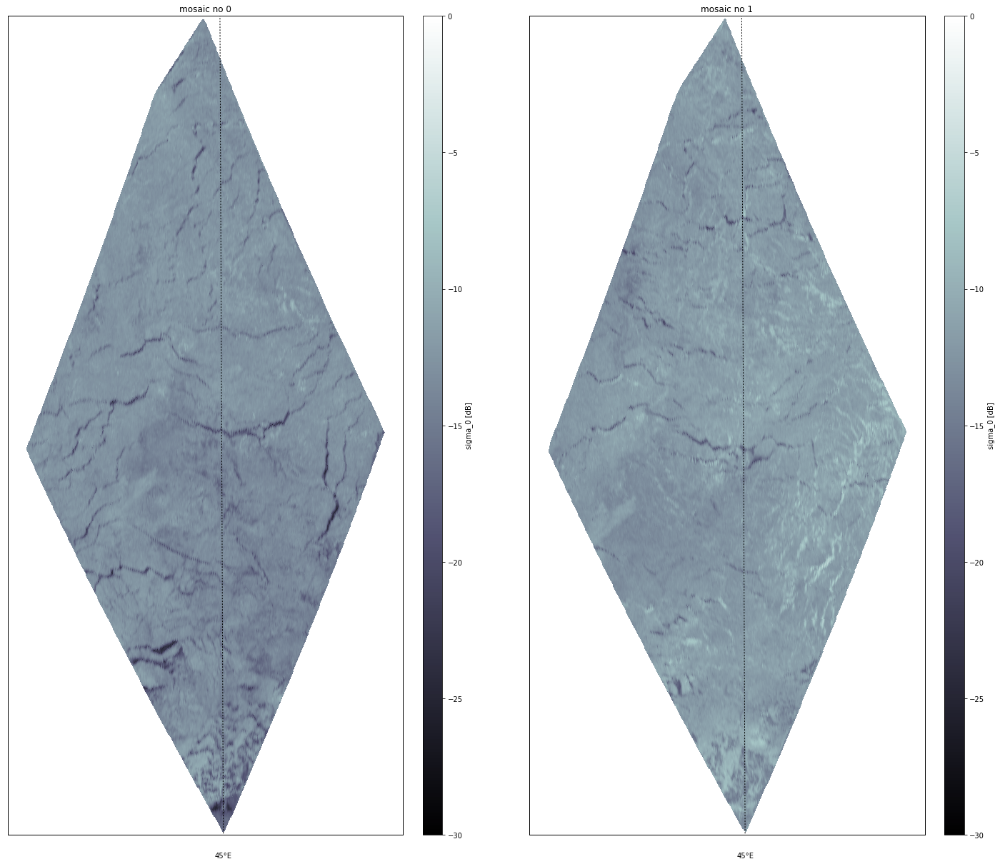

Kara_2014-11-03T133319_2014-11-04T042655_lat-3_lon-2_hh.pickle is created
2014-11-03 23:32:53 2014-11-04 01:09:10
area of intersection 0.0
cond_area False
2014-11-03 23:32:53 2014-11-04 02:48:13
area of intersection 0.0
cond_area False
2014-11-03 23:32:53 2014-11-04 04:26:55
area of intersection 0.0
cond_area False
2014-11-03 23:32:53 2014-11-04 10:56:04
area of intersection 0.0
cond_area False
2014-11-03 23:32:53 2014-11-05 05:07:58
area of intersection 0.0
cond_area False
2014-11-03 23:32:53 2014-11-05 09:57:49
area of intersection 0.398290996624
cond_area False
2014-11-03 23:32:53 2014-11-05 13:14:22
area of intersection 0.0
cond_area False
2014-11-03 23:32:53 2014-11-06 00:52:44
area of intersection 0.0
cond_area False
2014-11-03 23:32:53 2014-11-06 02:31:44
area of intersection 0.0
cond_area False
2014-11-03 23:32:53 2014-11-06 04:09:58
area of intersection 0.0
cond_area False
2014-11-03 23:32:53 2014-11-06 10:41:34
area of intersection 0.0
cond_area False
2014-11-03 23:32:53 2014

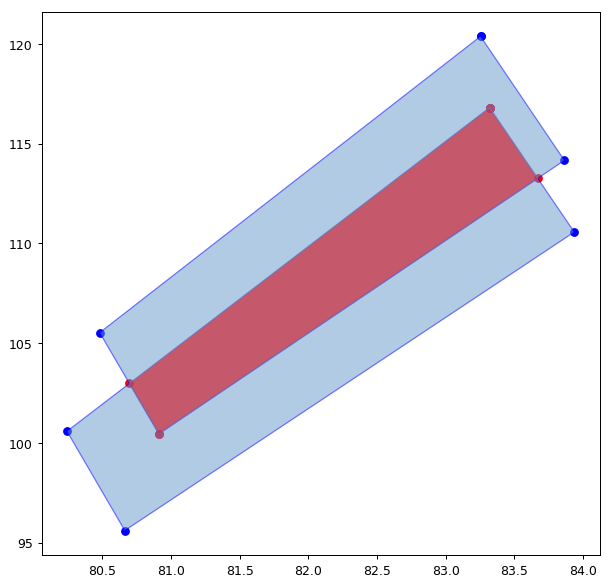

Successful overlap:
['S1A_EW_GRDM_1SSH_20141104T010910_20141104T011013_003125_00396C_582B.zip']
with
['S1A_EW_GRDM_1SSH_20141106T005244_20141106T005341_003154_003A08_60D0.zip']

Time difference is  1 day, 23:43:34
2014-11-04T010910 2014-11-06T005244
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SSH_20141104T010910_20141104T011013_003125_00396C_582B.zip
False True
no HV data found
2014-11-04 02:48:13 2014-11-04 04:26:55
area of intersection 0.0
cond_area False


2014-11-04 02:48:13 2014-11-04 10:56:04
area of intersection 6.64219709268
cond_area True
Images overlap


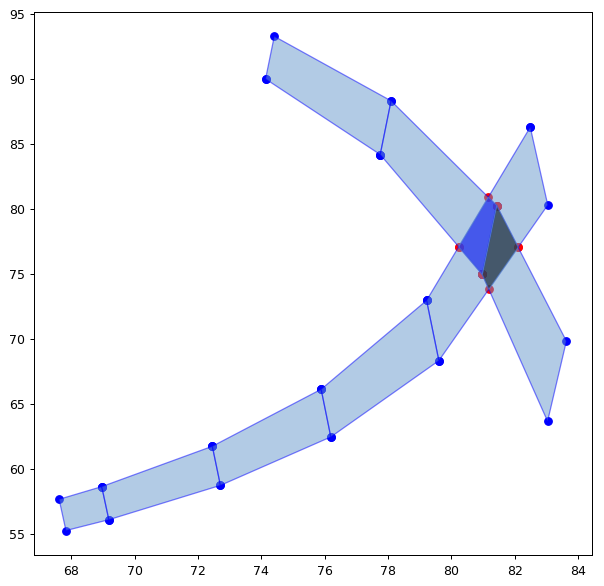

Successful overlap:
['S1A_EW_GRDM_1SDH_20141104T024813_20141104T024917_003126_003974_210A.zip', 'S1A_EW_GRDM_1SDH_20141104T024917_20141104T025017_003126_003974_ED36.zip', 'S1A_EW_GRDM_1SDH_20141104T025017_20141104T025117_003126_003974_9385.zip', 'S1A_EW_GRDM_1SDH_20141104T025117_20141104T025217_003126_003974_B1E1.zip', 'S1A_EW_GRDM_1SDH_20141104T025217_20141104T025240_003126_003974_407E.zip']
with
['S1A_EW_GRDM_1SDH_20141104T105604_20141104T105709_003131_003990_C5EB.zip', 'S1A_EW_GRDM_1SDH_20141104T105709_20141104T105809_003131_003990_E3A1.zip', 'S1A_EW_GRDM_1SDH_20141104T105809_20141104T105851_003131_003990_ACEE.zip']

Time difference is  8:07:51
2014-11-04T024813 2014-11-04T105604
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141104T024813_20141104T024917_003126_003974_210A.zip
80.9712753296 73.7964238478 82.1053665799 80.2335357666
78.4876 61.5252 83.6437 93.9184
80.228960933 74.9395523071 81.4273834229 80.8727797063
78.4876 61.5252 83.6437

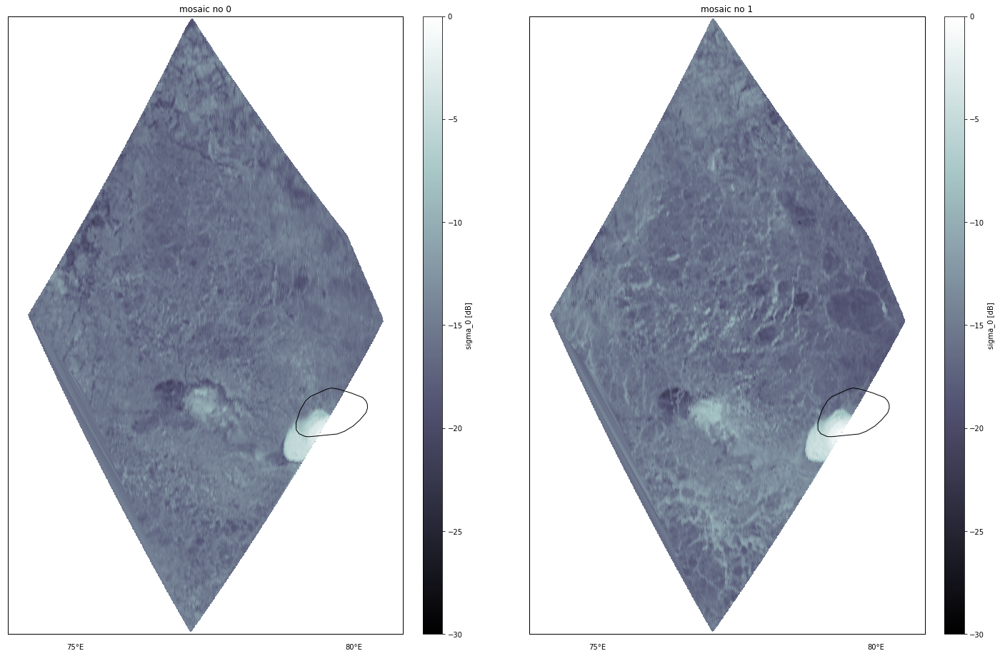

Kara_2014-11-04T024813_2014-11-04T105604_lat-3_lon-2_hh.pickle is created
2014-11-04 04:26:55 2014-11-04 10:56:04
area of intersection 0.0
cond_area False
2014-11-04 04:26:55 2014-11-05 05:07:58
area of intersection 0.0
cond_area False
2014-11-04 04:26:55 2014-11-05 09:57:49
area of intersection 0.0
cond_area False
2014-11-04 04:26:55 2014-11-05 13:14:22
area of intersection 5.62850903939
cond_area True
Images overlap


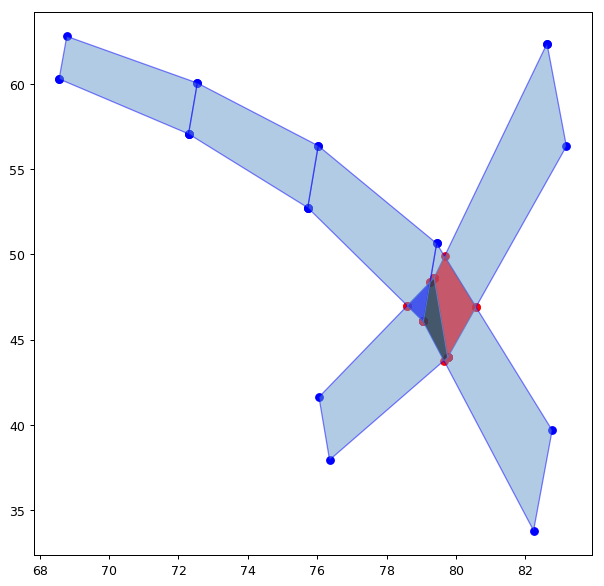

Successful overlap:
['S1A_EW_GRDM_1SDH_20141104T042655_20141104T042759_003127_003978_2AC9.zip', 'S1A_EW_GRDM_1SDH_20141104T042759_20141104T042859_003127_003978_C37A.zip']
with
['S1A_EW_GRDM_1SDH_20141105T131422_20141105T131526_003147_0039E0_986B.zip', 'S1A_EW_GRDM_1SDH_20141105T131526_20141105T131626_003147_0039E0_244E.zip', 'S1A_EW_GRDM_1SDH_20141105T131626_20141105T131726_003147_0039E0_8EF5.zip', 'S1A_EW_GRDM_1SDH_20141105T131726_20141105T131827_003147_0039E0_F207.zip']

Time difference is  1 day, 8:47:27
2014-11-04T042655 2014-11-05T131422
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141104T042655_20141104T042759_003127_003978_2AC9.zip
79.0579681396 43.7688940595 79.7590332031 48.6148719788
78.6375 37.1232 83.7942 69.993
78.5962238263 46.0648574829 79.2504209345 48.3659887764
78.6375 37.1232 83.7942 69.993
79.3689956665 43.9571456909 80.5748486069 49.8853188412
78.6375 37.1232 83.7942 69.993
False False
/home/cercache/users/atarasen/data/S

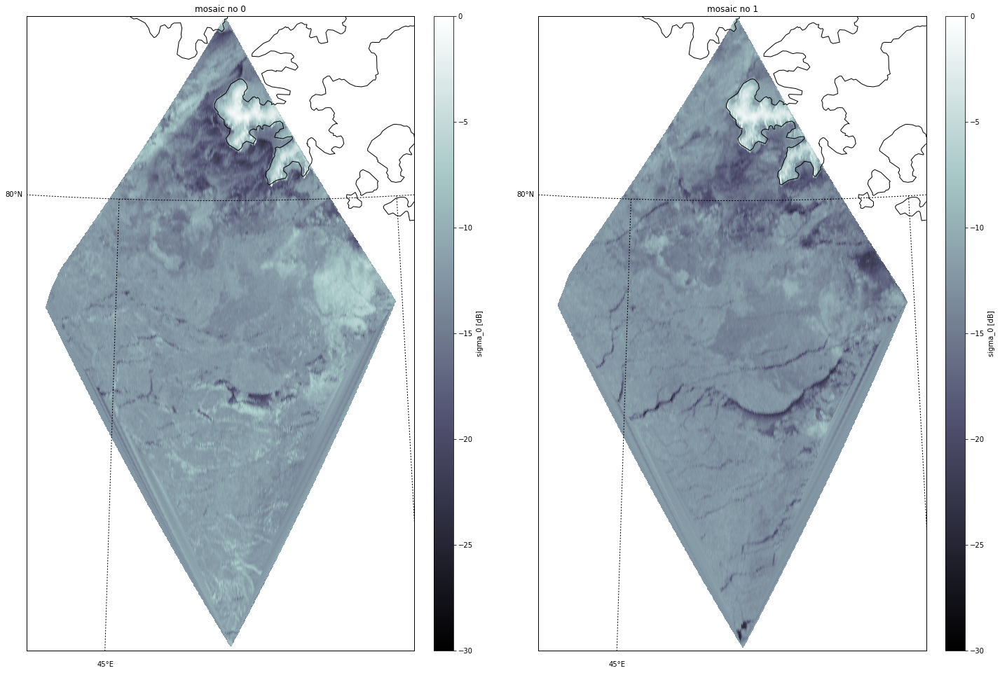

Kara_2014-11-04T042655_2014-11-05T131422_lat-3_lon-2_hh.pickle is created
2014-11-04 10:56:04 2014-11-05 05:07:58
area of intersection 0.0
cond_area False
2014-11-04 10:56:04 2014-11-05 09:57:49
area of intersection 0.0
cond_area False
2014-11-04 10:56:04 2014-11-05 13:14:22
area of intersection 0.0
cond_area False
2014-11-04 10:56:04 2014-11-06 00:52:44
area of intersection 0.0
cond_area False
2014-11-04 10:56:04 2014-11-06 02:31:44
area of intersection 6.51910840824
cond_area True
Images overlap


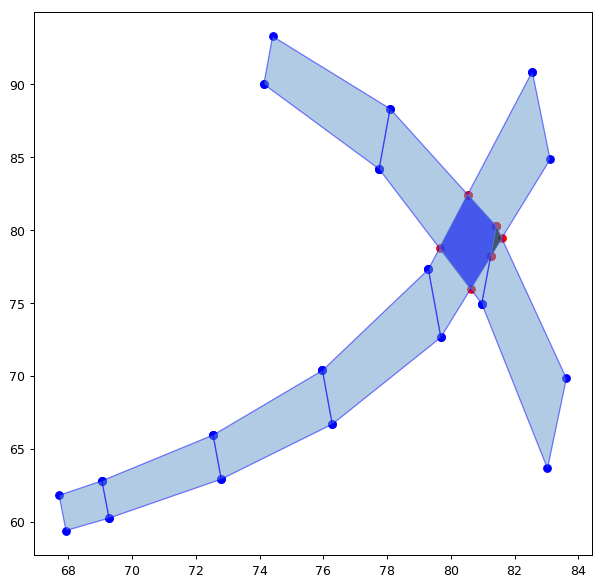

Successful overlap:
['S1A_EW_GRDM_1SDH_20141104T105604_20141104T105709_003131_003990_C5EB.zip', 'S1A_EW_GRDM_1SDH_20141104T105709_20141104T105809_003131_003990_E3A1.zip', 'S1A_EW_GRDM_1SDH_20141104T105809_20141104T105851_003131_003990_ACEE.zip']
with
['S1A_EW_GRDM_1SDH_20141106T023144_20141106T023248_003155_003A0C_D203.zip', 'S1A_EW_GRDM_1SDH_20141106T023248_20141106T023348_003155_003A0C_0322.zip', 'S1A_EW_GRDM_1SDH_20141106T023348_20141106T023448_003155_003A0C_2518.zip', 'S1A_EW_GRDM_1SDH_20141106T023448_20141106T023548_003155_003A0C_DE5F.zip', 'S1A_EW_GRDM_1SDH_20141106T023548_20141106T023611_003155_003A0C_16A2.zip']

Time difference is  1 day, 15:35:40
2014-11-04T105604 2014-11-06T023144
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141104T105604_20141104T105709_003131_003990_C5EB.zip
81.2506120595 78.179022257 81.5993363503 80.2335357666
73.6143 78.1991 78.4555 97.8549
79.646973323 75.9404694721 81.4273834229 82.4037891961
73.6143 78.1991 

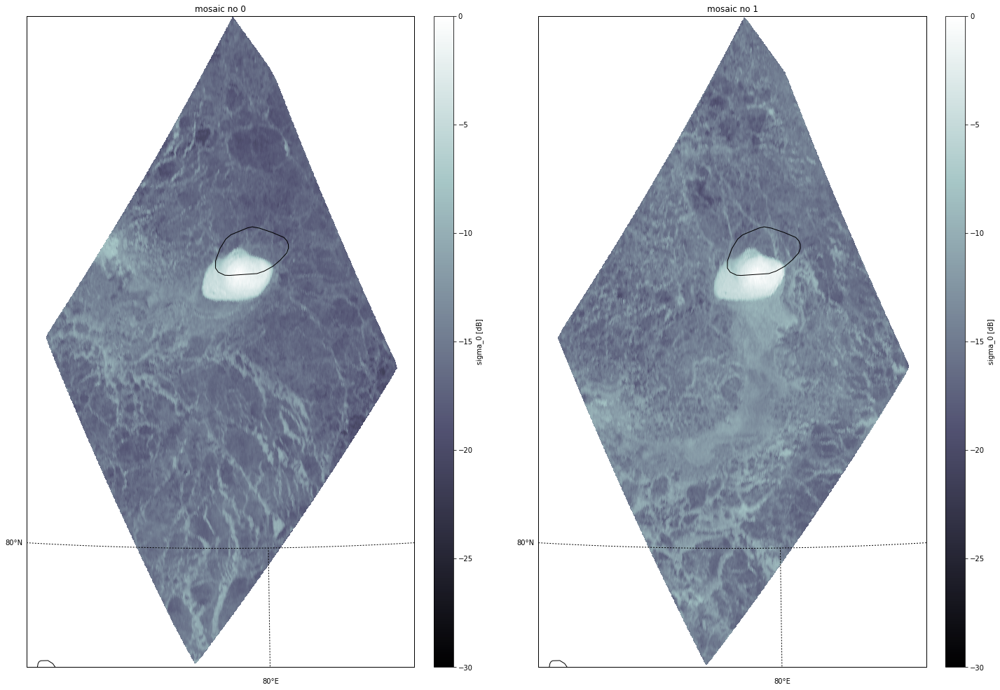

Kara_2014-11-04T105604_2014-11-06T023144_lat-3_lon-2_hh.pickle is created
2014-11-05 05:07:58 2014-11-05 09:57:49
area of intersection 0.0
cond_area False
2014-11-05 05:07:58 2014-11-05 13:14:22
area of intersection 6.48074368172
cond_area True
Images overlap


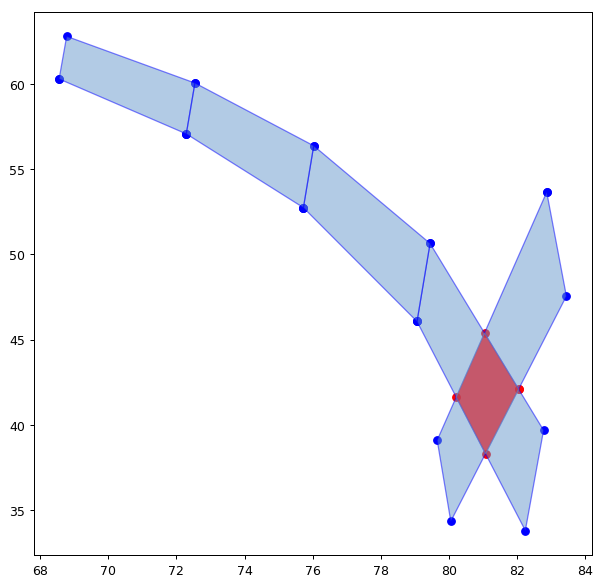

Successful overlap:
['S1A_EW_GRDM_1SDH_20141105T050758_20141105T050902_003142_0039CD_197B.zip']
with
['S1A_EW_GRDM_1SDH_20141105T131422_20141105T131526_003147_0039E0_986B.zip', 'S1A_EW_GRDM_1SDH_20141105T131526_20141105T131626_003147_0039E0_244E.zip', 'S1A_EW_GRDM_1SDH_20141105T131626_20141105T131726_003147_0039E0_8EF5.zip', 'S1A_EW_GRDM_1SDH_20141105T131726_20141105T131827_003147_0039E0_F207.zip']

Time difference is  8:06:24
2014-11-05T050758 2014-11-05T131422
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141105T050758_20141105T050902_003142_0039CD_197B.zip
False True
no HV data found
2014-11-05 09:57:49 2014-11-05 13:14:22
area of intersection 0.0
cond_area False


2014-11-05 09:57:49 2014-11-06 00:52:44
area of intersection 0.0
cond_area False
2014-11-05 09:57:49 2014-11-06 02:31:44
area of intersection 2.32529759481
cond_area True
Images overlap


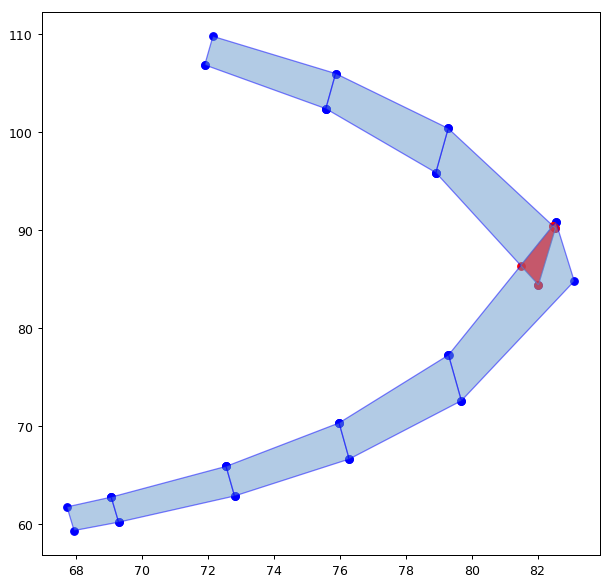

Successful overlap:
['S1A_EW_GRDM_1SDH_20141105T095749_20141105T095854_003145_0039D7_AE16.zip', 'S1A_EW_GRDM_1SDH_20141105T095854_20141105T095954_003145_0039D7_F9AF.zip', 'S1A_EW_GRDM_1SDH_20141105T095954_20141105T100054_003145_0039D7_9135.zip']
with
['S1A_EW_GRDM_1SDH_20141106T023144_20141106T023248_003155_003A0C_D203.zip', 'S1A_EW_GRDM_1SDH_20141106T023248_20141106T023348_003155_003A0C_0322.zip', 'S1A_EW_GRDM_1SDH_20141106T023348_20141106T023448_003155_003A0C_2518.zip', 'S1A_EW_GRDM_1SDH_20141106T023448_20141106T023548_003155_003A0C_DE5F.zip', 'S1A_EW_GRDM_1SDH_20141106T023548_20141106T023611_003155_003A0C_16A2.zip']

Time difference is  16:33:55
2014-11-05T095749 2014-11-06T023144
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141105T095749_20141105T095854_003145_0039D7_AE16.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141105T095854_20141105T095954_003145_0039D7_F9AF.zip
False True
/home/cerca

2014-11-05 13:14:22 2014-11-06 02:31:44
area of intersection 3.13213228858
cond_area True
Images overlap


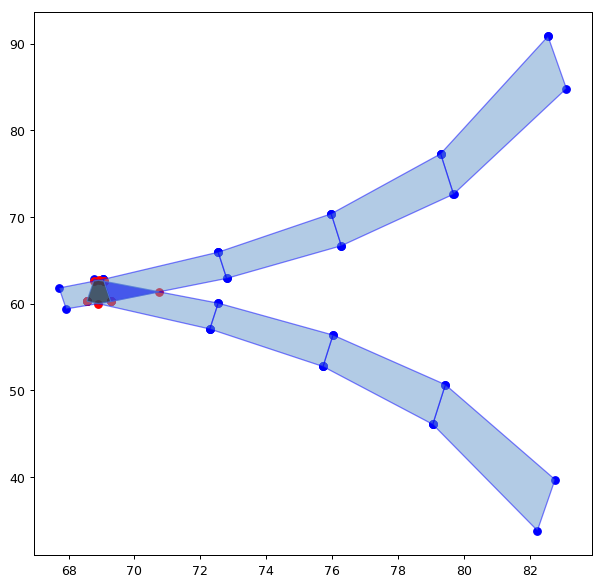

Successful overlap:
['S1A_EW_GRDM_1SDH_20141105T131422_20141105T131526_003147_0039E0_986B.zip', 'S1A_EW_GRDM_1SDH_20141105T131526_20141105T131626_003147_0039E0_244E.zip', 'S1A_EW_GRDM_1SDH_20141105T131626_20141105T131726_003147_0039E0_8EF5.zip', 'S1A_EW_GRDM_1SDH_20141105T131726_20141105T131827_003147_0039E0_F207.zip']
with
['S1A_EW_GRDM_1SDH_20141106T023144_20141106T023248_003155_003A0C_D203.zip', 'S1A_EW_GRDM_1SDH_20141106T023248_20141106T023348_003155_003A0C_0322.zip', 'S1A_EW_GRDM_1SDH_20141106T023348_20141106T023448_003155_003A0C_2518.zip', 'S1A_EW_GRDM_1SDH_20141106T023448_20141106T023548_003155_003A0C_DE5F.zip', 'S1A_EW_GRDM_1SDH_20141106T023548_20141106T023611_003155_003A0C_16A2.zip']

Time difference is  13:17:22
2014-11-05T131422 2014-11-06T023144
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141105T131422_20141105T131526_003147_0039E0_986B.zip
68.5591659546 59.9940484012 69.2802658081 62.6848016144
68.1433 52.5965 72.812 66.2406
69.

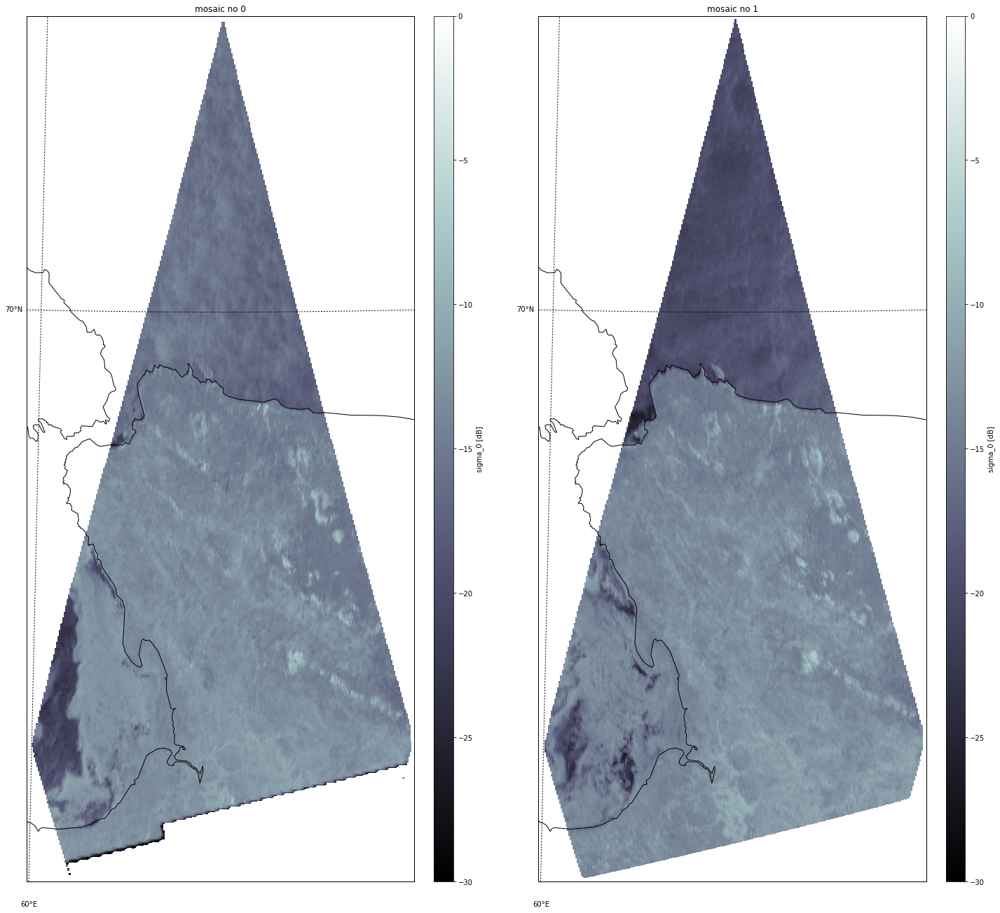

Kara_2014-11-05T131422_2014-11-06T023144_lat-3_lon-2_hh.pickle is created
2014-11-06 00:52:44 2014-11-06 02:31:44
area of intersection 0.0
cond_area False
2014-11-06 00:52:44 2014-11-06 04:09:58
area of intersection 0.0
cond_area False
2014-11-06 00:52:44 2014-11-06 10:41:34
area of intersection 0.0
cond_area False
2014-11-06 00:52:44 2014-11-06 12:17:01
area of intersection 0.0
cond_area False
2014-11-06 00:52:44 2014-11-06 13:57:17
area of intersection 0.0
cond_area False
2014-11-06 00:52:44 2014-11-06 23:56:34
area of intersection 0.0
cond_area False
2014-11-06 00:52:44 2014-11-07 01:34:08
area of intersection 0.0
cond_area False
2014-11-06 00:52:44 2014-11-07 04:51:35
area of intersection 0.0
cond_area False
2014-11-06 00:52:44 2014-11-07 11:20:14
area of intersection 0.0
cond_area False
2014-11-06 00:52:44 2014-11-08 00:36:36
area of intersection 7.6174048968
cond_area True
Images overlap


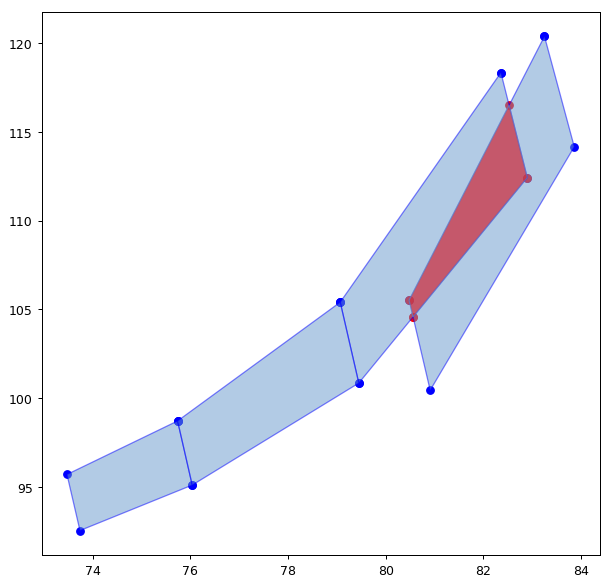

Successful overlap:
['S1A_EW_GRDM_1SSH_20141106T005244_20141106T005341_003154_003A08_60D0.zip']
with
['S1A_EW_GRDM_1SDH_20141108T003636_20141108T003740_003183_003AA6_E379.zip', 'S1A_EW_GRDM_1SDH_20141108T003740_20141108T003840_003183_003AA6_6D9B.zip', 'S1A_EW_GRDM_1SDH_20141108T003840_20141108T003920_003183_003AA6_1720.zip']

Time difference is  1 day, 23:43:52
2014-11-06T005244 2014-11-08T003636
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SSH_20141106T005244_20141106T005341_003154_003A08_60D0.zip
False True
no HV data found
2014-11-06 02:31:44 2014-11-06 04:09:58
area of intersection 0.0
cond_area False


2014-11-06 02:31:44 2014-11-06 10:41:34
area of intersection 5.36186627249
cond_area True
Images overlap


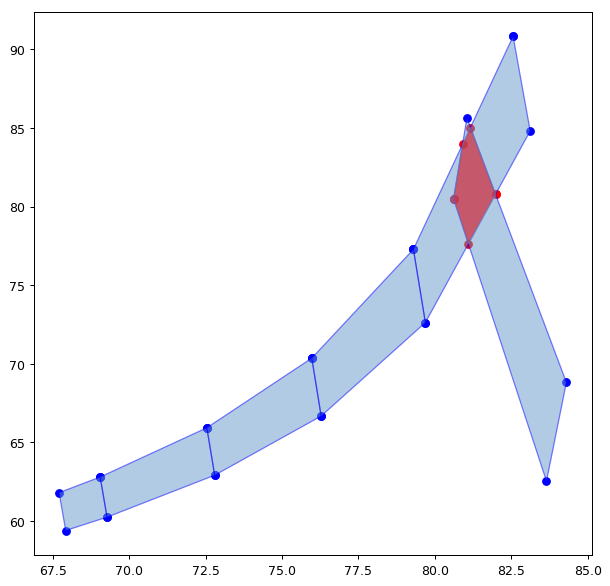

Successful overlap:
['S1A_EW_GRDM_1SDH_20141106T023144_20141106T023248_003155_003A0C_D203.zip', 'S1A_EW_GRDM_1SDH_20141106T023248_20141106T023348_003155_003A0C_0322.zip', 'S1A_EW_GRDM_1SDH_20141106T023348_20141106T023448_003155_003A0C_2518.zip', 'S1A_EW_GRDM_1SDH_20141106T023448_20141106T023548_003155_003A0C_DE5F.zip', 'S1A_EW_GRDM_1SDH_20141106T023548_20141106T023611_003155_003A0C_16A2.zip']
with
['S1A_EW_GRDM_1SSH_20141106T104134_20141106T104238_003160_003A23_0903.zip']

Time difference is  8:09:50
2014-11-06T023144 2014-11-06T104134
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141106T023144_20141106T023248_003155_003A0C_D203.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141106T023248_20141106T023348_003155_003A0C_0322.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141106T023348_20141106T023448_003155_003A0C_2518.zip
False True
/home/cercache/user

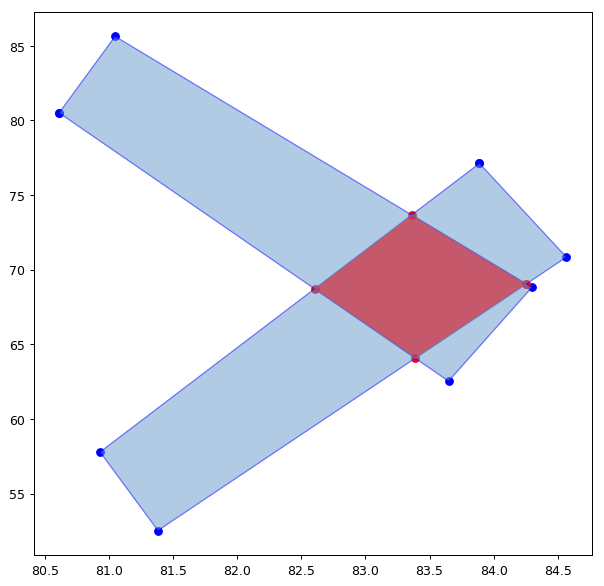

Successful overlap:
['S1A_EW_GRDM_1SSH_20141106T040958_20141106T041102_003156_003A10_6C70.zip']
with
['S1A_EW_GRDM_1SSH_20141106T104134_20141106T104238_003160_003A23_0903.zip']

Time difference is  6:31:36
2014-11-06T040958 2014-11-06T104134
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SSH_20141106T040958_20141106T041102_003156_003A10_6C70.zip
False True
no HV data found
2014-11-06 10:41:34 2014-11-06 12:17:01
area of intersection 0.0
cond_area False


2014-11-06 10:41:34 2014-11-06 13:57:17
area of intersection 0.0
cond_area False
2014-11-06 10:41:34 2014-11-06 23:56:34
area of intersection 0.0
cond_area False
2014-11-06 10:41:34 2014-11-07 01:34:08
area of intersection 0.0
cond_area False
2014-11-06 10:41:34 2014-11-07 04:51:35
area of intersection 0.0
cond_area False
2014-11-06 10:41:34 2014-11-07 11:20:14
area of intersection 0.168562767456
cond_area False
2014-11-06 10:41:34 2014-11-08 00:36:36
area of intersection 0.0
cond_area False
2014-11-06 10:41:34 2014-11-08 03:54:03
area of intersection 0.0126666809575
cond_area False
2014-11-06 10:41:34 2014-11-08 10:22:48
area of intersection 7.59113577079
cond_area True
Images overlap


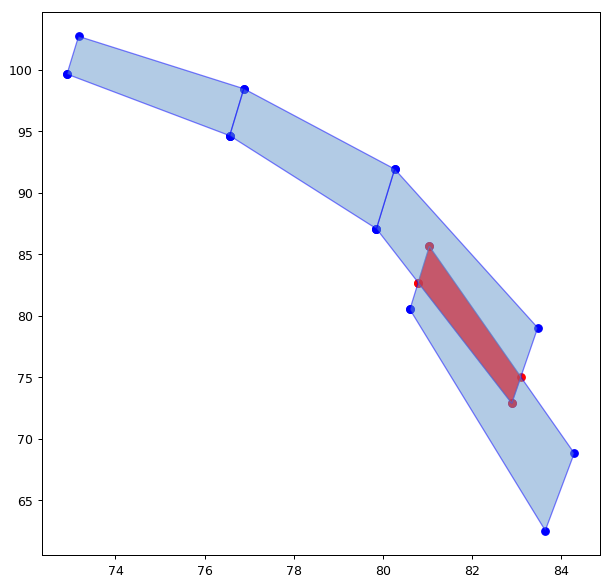

Successful overlap:
['S1A_EW_GRDM_1SSH_20141106T104134_20141106T104238_003160_003A23_0903.zip']
with
['S1A_EW_GRDM_1SDH_20141108T102248_20141108T102352_003189_003AC0_3DB7.zip', 'S1A_EW_GRDM_1SDH_20141108T102352_20141108T102452_003189_003AC0_F671.zip', 'S1A_EW_GRDM_1SDH_20141108T102452_20141108T102553_003189_003AC0_BE33.zip']

Time difference is  1 day, 23:41:14
2014-11-06T104134 2014-11-08T102248
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SSH_20141106T104134_20141106T104238_003160_003A23_0903.zip
False True
no HV data found
2014-11-06 12:17:01 2014-11-06 13:57:17
area of intersection 0.0
cond_area False


2014-11-06 12:17:01 2014-11-06 23:56:34
area of intersection 0.0
cond_area False
2014-11-06 12:17:01 2014-11-07 01:34:08
area of intersection 0.956427682808
cond_area True
Images overlap


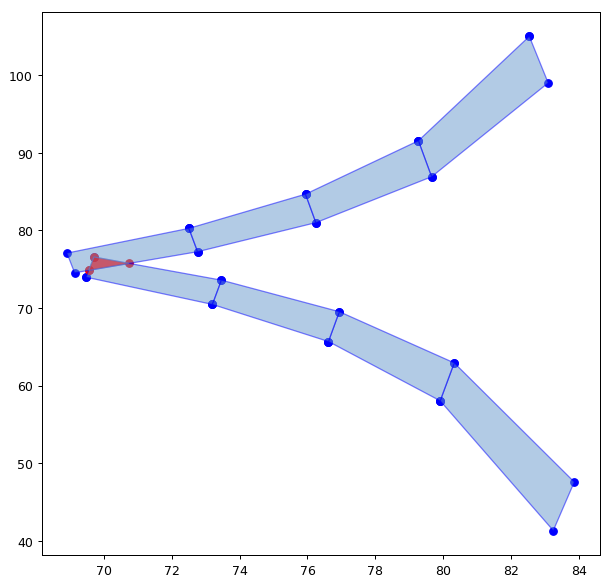

Successful overlap:
['S1A_EW_GRDM_1SDH_20141106T121701_20141106T121805_003161_003A28_DC65.zip', 'S1A_EW_GRDM_1SDH_20141106T121805_20141106T121905_003161_003A28_935B.zip', 'S1A_EW_GRDM_1SDH_20141106T121905_20141106T122005_003161_003A28_CF3F.zip', 'S1A_EW_GRDM_1SDH_20141106T122005_20141106T122113_003161_003A28_38BC.zip']
with
['S1A_EW_GRDM_1SDH_20141107T013408_20141107T013512_003169_003A5A_B0E9.zip', 'S1A_EW_GRDM_1SDH_20141107T013512_20141107T013612_003169_003A5A_CC0A.zip', 'S1A_EW_GRDM_1SDH_20141107T013612_20141107T013712_003169_003A5A_9DA1.zip', 'S1A_EW_GRDM_1SDH_20141107T013712_20141107T013814_003169_003A5A_0851.zip']

Time difference is  13:17:07
2014-11-06T121701 2014-11-07T013408
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141106T121701_20141106T121805_003161_003A28_DC65.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141106T121805_20141106T121905_003161_003A28_935B.zip
False True
/home/cerca

2014-11-06 13:57:17 2014-11-07 01:34:08
area of intersection 0.0
cond_area False
2014-11-06 13:57:17 2014-11-07 04:51:35
area of intersection 0.0
cond_area False
2014-11-06 13:57:17 2014-11-07 11:20:14
area of intersection 0.0
cond_area False
2014-11-06 13:57:17 2014-11-08 00:36:36
area of intersection 0.0
cond_area False
2014-11-06 13:57:17 2014-11-08 03:54:03
area of intersection 1.53115755044
cond_area True
Images overlap


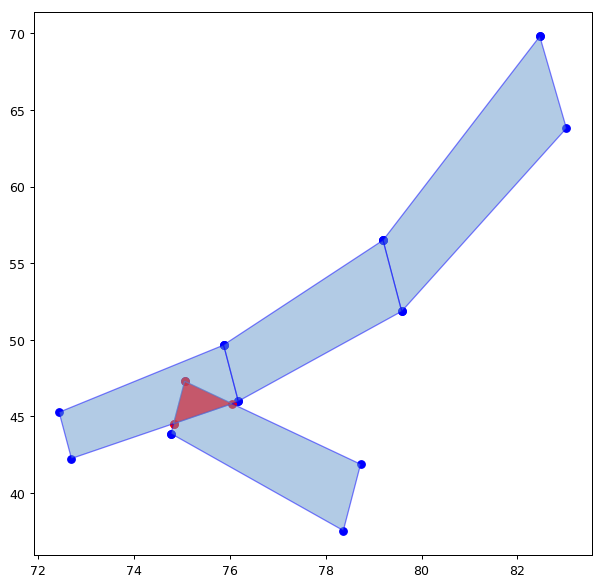

Successful overlap:
['S1A_EW_GRDM_1SDH_20141106T135717_20141106T135821_003162_003A2C_8899.zip']
with
['S1A_EW_GRDM_1SDH_20141108T035403_20141108T035507_003185_003AAF_2D66.zip', 'S1A_EW_GRDM_1SDH_20141108T035507_20141108T035607_003185_003AAF_124F.zip', 'S1A_EW_GRDM_1SDH_20141108T035607_20141108T035707_003185_003AAF_F9C1.zip']

Time difference is  1 day, 13:56:46
2014-11-06T135717 2014-11-08T035403
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141106T135717_20141106T135821_003162_003A2C_8899.zip
False True
no HV data found
2014-11-06 23:56:34 2014-11-07 01:34:08
area of intersection 0.0
cond_area False


2014-11-06 23:56:34 2014-11-07 04:51:35
area of intersection 0.0
cond_area False
2014-11-06 23:56:34 2014-11-07 11:20:14
area of intersection 0.0
cond_area False
2014-11-06 23:56:34 2014-11-08 00:36:36
area of intersection 0.0
cond_area False
2014-11-06 23:56:34 2014-11-08 03:54:03
area of intersection 0.0
cond_area False
2014-11-06 23:56:34 2014-11-08 10:22:48
area of intersection 0.0127189484793
cond_area False
2014-11-06 23:56:34 2014-11-08 13:38:53
area of intersection 0.0
cond_area False
2014-11-06 23:56:34 2014-11-08 23:41:05
area of intersection 0.00430645621952
cond_area False
2014-11-06 23:56:34 2014-11-09 02:56:24
area of intersection 0.0
cond_area False
2014-11-06 23:56:34 2014-11-09 04:35:09
area of intersection 0.0
cond_area False
2014-11-06 23:56:34 2014-11-09 11:04:10
area of intersection 0.0
cond_area False
2014-11-06 23:56:34 2014-11-09 12:45:02
area of intersection 0.0
cond_area False
2014-11-07 01:34:08 2014-11-07 04:51:35
area of intersection 0.0
cond_area False
201

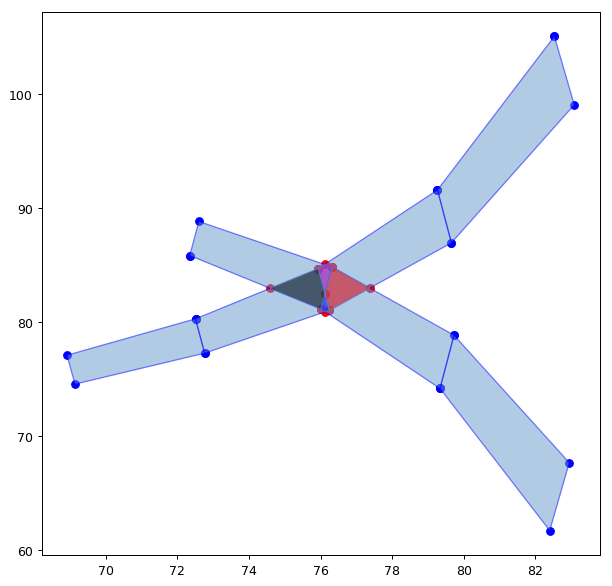

Successful overlap:
['S1A_EW_GRDM_1SDH_20141107T013408_20141107T013512_003169_003A5A_B0E9.zip', 'S1A_EW_GRDM_1SDH_20141107T013512_20141107T013612_003169_003A5A_CC0A.zip', 'S1A_EW_GRDM_1SDH_20141107T013612_20141107T013712_003169_003A5A_9DA1.zip', 'S1A_EW_GRDM_1SDH_20141107T013712_20141107T013814_003169_003A5A_0851.zip']
with
['S1A_EW_GRDM_1SDH_20141107T112014_20141107T112118_003175_003A7B_57A5.zip', 'S1A_EW_GRDM_1SDH_20141107T112118_20141107T112218_003175_003A7B_3196.zip', 'S1A_EW_GRDM_1SDH_20141107T112218_20141107T112318_003175_003A7B_1209.zip']

Time difference is  9:46:06
2014-11-07T013408 2014-11-07T112014
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141107T013408_20141107T013512_003169_003A5A_B0E9.zip
74.5931717972 81.1281585693 76.1257772259 84.6779937744
78.5363 80.1356 83.6917 112.672
76.0153579712 80.8843289231 76.24659729 82.4588017087
78.5363 80.1356 83.6917 112.672
76.1261696307 81.0085372925 77.3745943262 84.8150024414
78.5363 80.

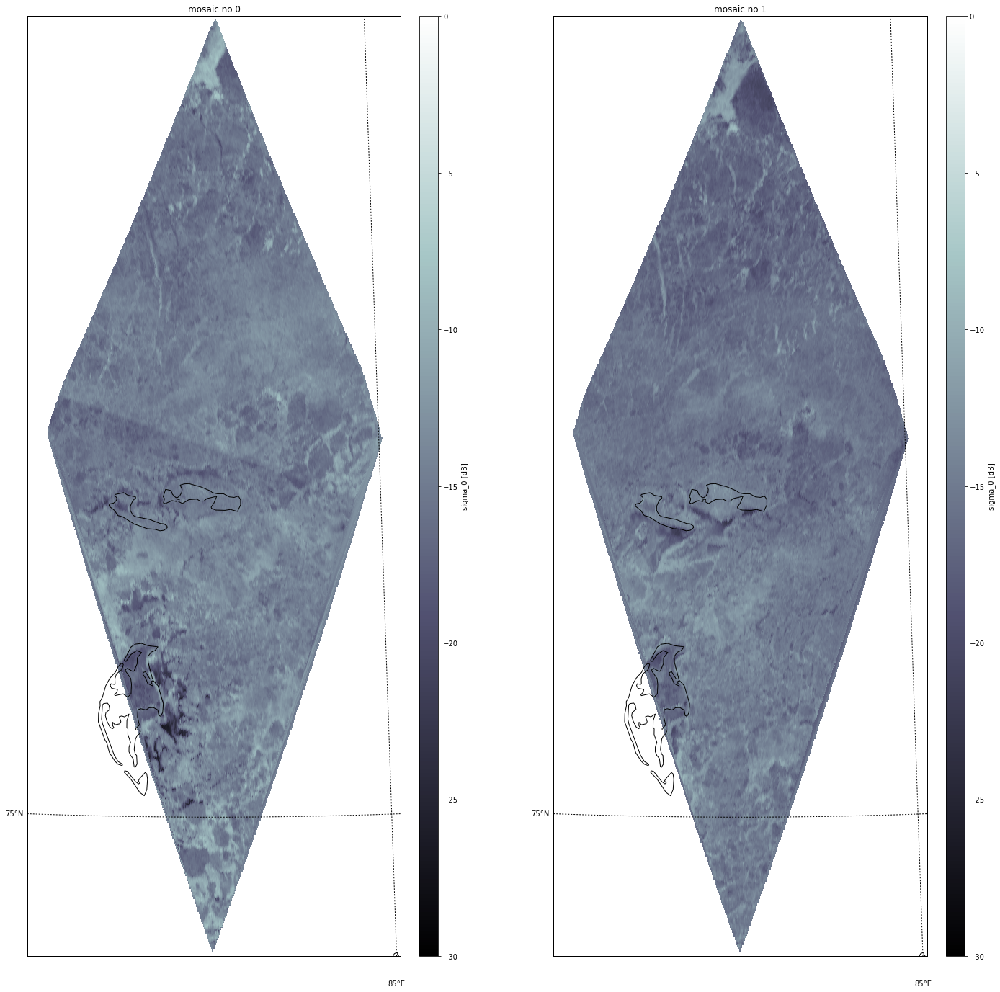

Kara_2014-11-07T013408_2014-11-07T112014_lat-3_lon-2_hh.pickle is created
2014-11-07 04:51:35 2014-11-07 11:20:14
area of intersection 0.0
cond_area False
2014-11-07 04:51:35 2014-11-08 00:36:36
area of intersection 0.0
cond_area False
2014-11-07 04:51:35 2014-11-08 03:54:03
area of intersection 0.0
cond_area False
2014-11-07 04:51:35 2014-11-08 10:22:48
area of intersection 0.0
cond_area False
2014-11-07 04:51:35 2014-11-08 13:38:53
area of intersection 3.20622130459
cond_area True
Images overlap


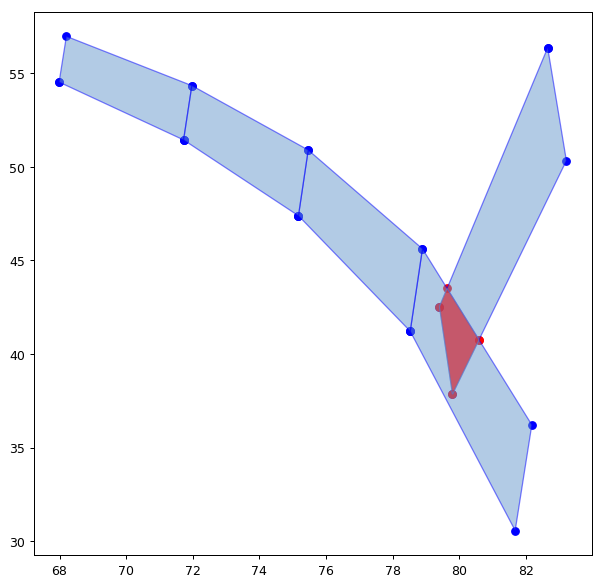

Successful overlap:
['S1A_EW_GRDM_1SDH_20141107T045135_20141107T045239_003171_003A66_5141.zip']
with
['S1A_EW_GRDM_1SDH_20141108T133853_20141108T133957_003191_003AC9_E3CE.zip', 'S1A_EW_GRDM_1SDH_20141108T133957_20141108T134057_003191_003AC9_D72F.zip', 'S1A_EW_GRDM_1SDH_20141108T134057_20141108T134157_003191_003AC9_5385.zip', 'S1A_EW_GRDM_1SDH_20141108T134157_20141108T134257_003191_003AC9_C214.zip']

Time difference is  1 day, 8:47:18
2014-11-07T045135 2014-11-08T133853
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141107T045135_20141107T045239_003171_003A66_5141.zip
False True
no HV data found
2014-11-07 11:20:14 2014-11-08 00:36:36
area of intersection 0.0
cond_area False


2014-11-07 11:20:14 2014-11-08 03:54:03
area of intersection 5.47914829953
cond_area True
Images overlap


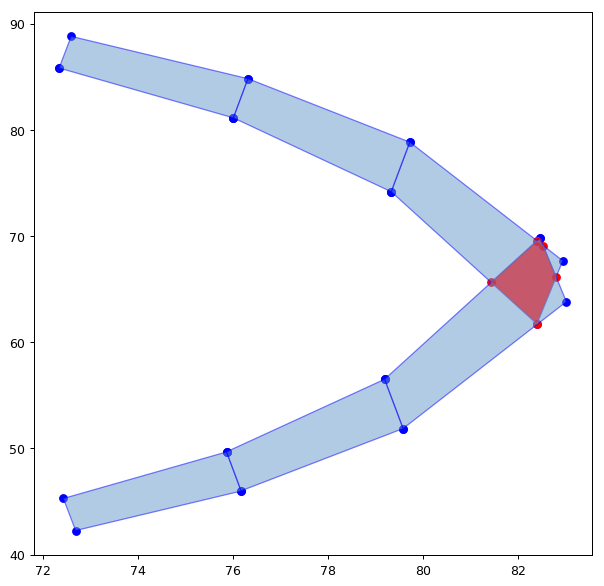

Successful overlap:
['S1A_EW_GRDM_1SDH_20141107T112014_20141107T112118_003175_003A7B_57A5.zip', 'S1A_EW_GRDM_1SDH_20141107T112118_20141107T112218_003175_003A7B_3196.zip', 'S1A_EW_GRDM_1SDH_20141107T112218_20141107T112318_003175_003A7B_1209.zip']
with
['S1A_EW_GRDM_1SDH_20141108T035403_20141108T035507_003185_003AAF_2D66.zip', 'S1A_EW_GRDM_1SDH_20141108T035507_20141108T035607_003185_003AAF_124F.zip', 'S1A_EW_GRDM_1SDH_20141108T035607_20141108T035707_003185_003AAF_F9C1.zip']

Time difference is  16:33:49
2014-11-07T112014 2014-11-08T035403
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141107T112014_20141107T112118_003175_003A7B_57A5.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141107T112118_20141107T112218_003175_003A7B_3196.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141107T112218_20141107T112318_003175_003A7B_1209.zip
False True
no HV data found
2

2014-11-08 00:36:36 2014-11-08 10:22:48
area of intersection 5.77508223066
cond_area True
Images overlap


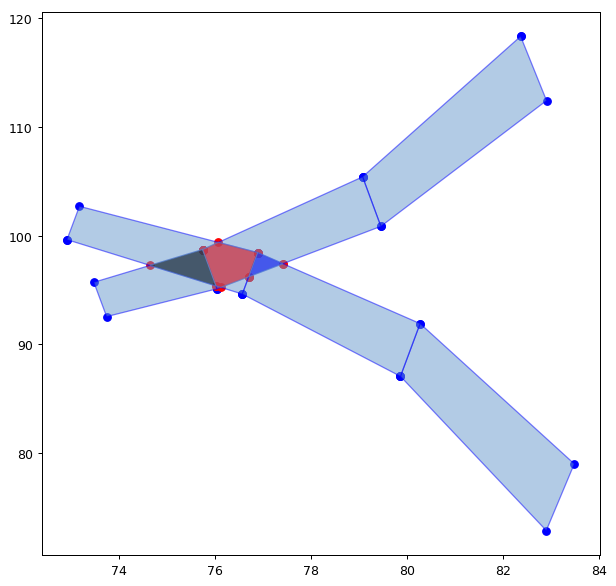

Successful overlap:
['S1A_EW_GRDM_1SDH_20141108T003636_20141108T003740_003183_003AA6_E379.zip', 'S1A_EW_GRDM_1SDH_20141108T003740_20141108T003840_003183_003AA6_6D9B.zip', 'S1A_EW_GRDM_1SDH_20141108T003840_20141108T003920_003183_003AA6_1720.zip']
with
['S1A_EW_GRDM_1SDH_20141108T102248_20141108T102352_003189_003AC0_3DB7.zip', 'S1A_EW_GRDM_1SDH_20141108T102352_20141108T102452_003189_003AC0_F671.zip', 'S1A_EW_GRDM_1SDH_20141108T102452_20141108T102553_003189_003AC0_BE33.zip']

Time difference is  9:46:12
2014-11-08T003636 2014-11-08T102248
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141108T003636_20141108T003740_003183_003AA6_E379.zip
74.6409350051 95.3818831347 76.014880088 98.7218780518
78.3553 94.2052 83.4895 125.933
76.6976409878 96.2237859299 77.4103937427 98.4425430298
78.3553 94.2052 83.4895 125.933
75.7377471924 95.2441883837 76.8813476562 99.379483939
78.3553 94.2052 83.4895 125.933
False True
/home/cercache/users/atarasen/data/Sentinel

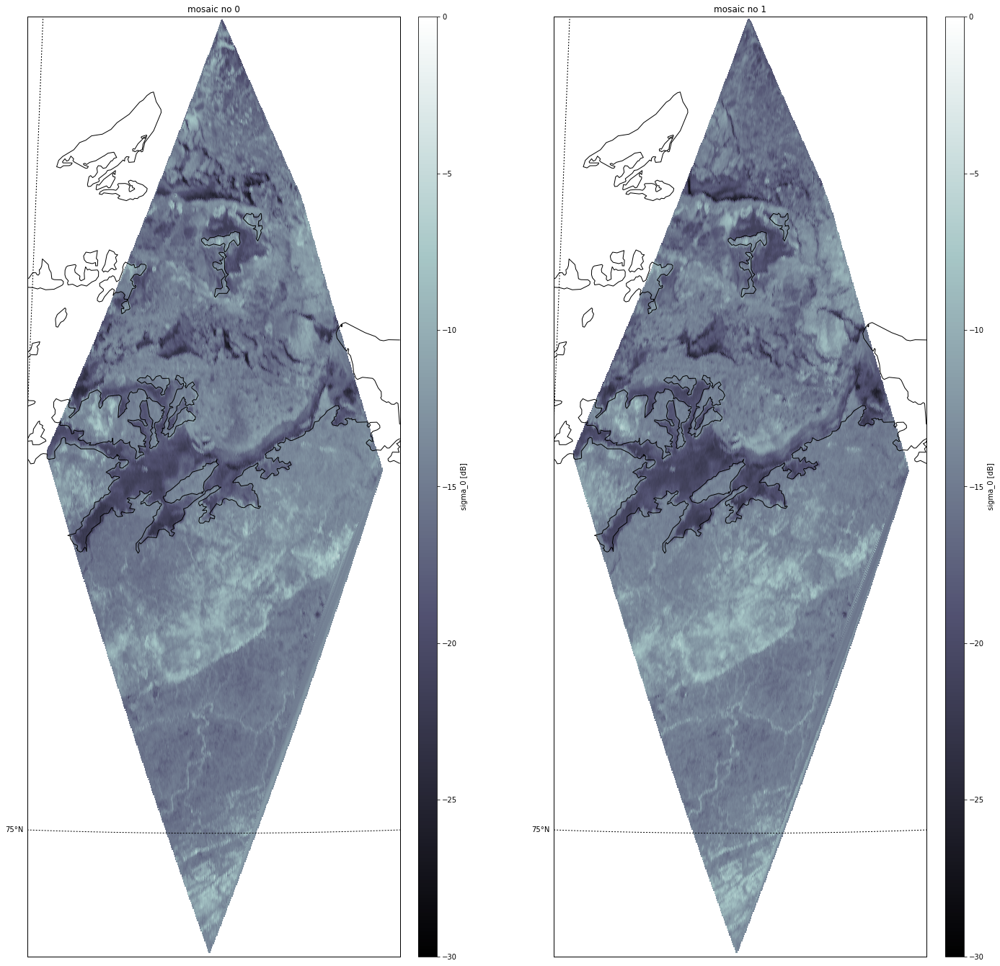

Kara_2014-11-08T003636_2014-11-08T102248_lat-3_lon-2_hh.pickle is created
2014-11-08 03:54:03 2014-11-08 10:22:48
area of intersection 0.0
cond_area False
2014-11-08 03:54:03 2014-11-08 13:38:53
area of intersection 5.5404029976
cond_area True
Images overlap


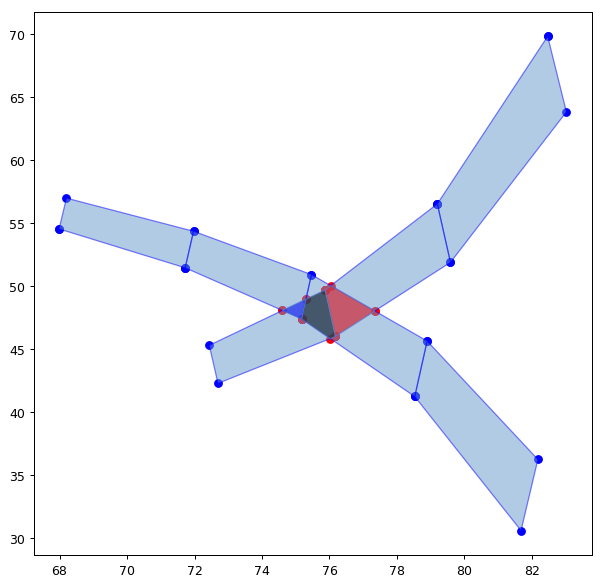

Successful overlap:
['S1A_EW_GRDM_1SDH_20141108T035403_20141108T035507_003185_003AAF_2D66.zip', 'S1A_EW_GRDM_1SDH_20141108T035507_20141108T035607_003185_003AAF_124F.zip', 'S1A_EW_GRDM_1SDH_20141108T035607_20141108T035707_003185_003AAF_F9C1.zip']
with
['S1A_EW_GRDM_1SDH_20141108T133853_20141108T133957_003191_003AC9_E3CE.zip', 'S1A_EW_GRDM_1SDH_20141108T133957_20141108T134057_003191_003AC9_D72F.zip', 'S1A_EW_GRDM_1SDH_20141108T134057_20141108T134157_003191_003AC9_5385.zip', 'S1A_EW_GRDM_1SDH_20141108T134157_20141108T134257_003191_003AC9_C214.zip']

Time difference is  9:44:50
2014-11-08T035403 2014-11-08T133853
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141108T035403_20141108T035507_003185_003AAF_2D66.zip
75.171875 45.8138496301 76.1781082153 49.6587409973
78.4646 45.0526 83.6287 77.4688
74.6070256199 47.3819313049 75.3009538313 48.9308368805
78.4646 45.0526 83.6287 77.4688
75.870513916 45.9969673157 77.3427937792 50.0122628527
78.4646 45.052

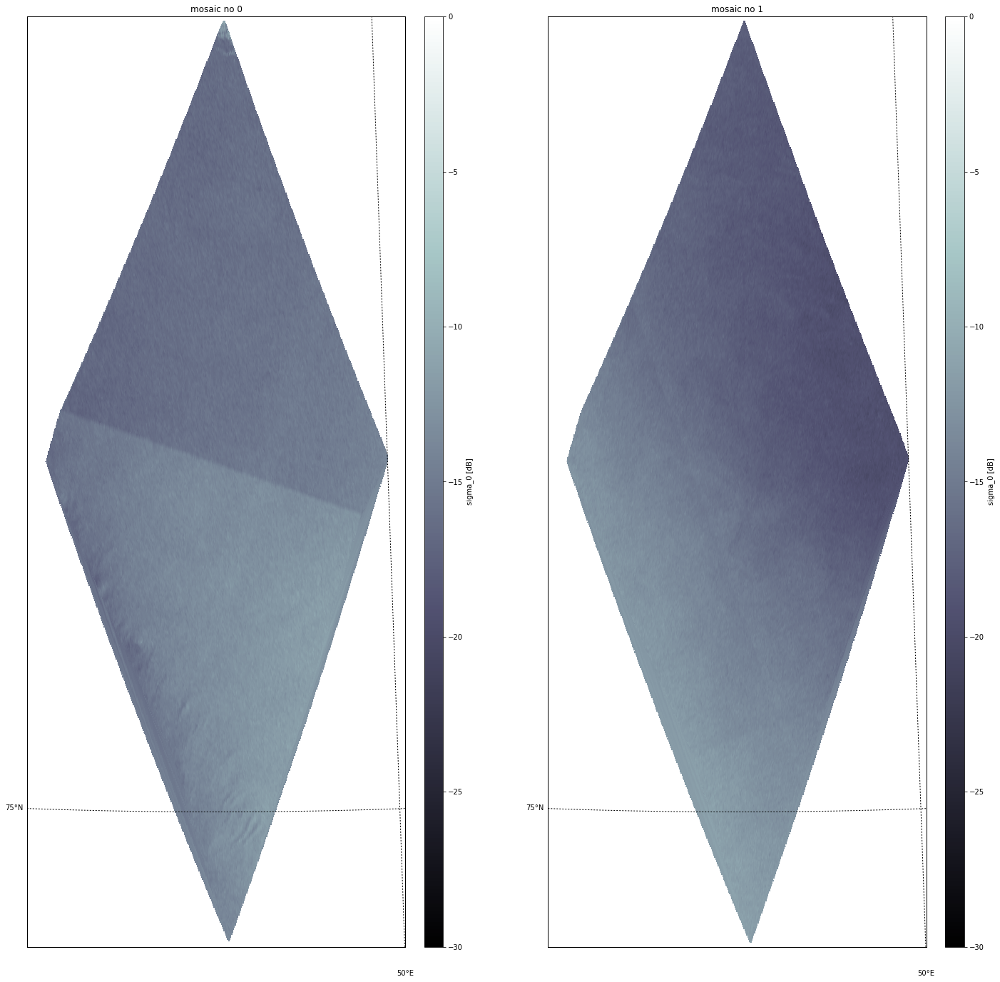

Kara_2014-11-08T035403_2014-11-08T133853_lat-3_lon-2_hh.pickle is created
2014-11-08 10:22:48 2014-11-08 13:38:53
area of intersection 0.0
cond_area False
2014-11-08 10:22:48 2014-11-08 23:41:05
area of intersection 0.0
cond_area False
2014-11-08 10:22:48 2014-11-09 02:56:24
area of intersection 7.44701900876
cond_area True
Images overlap


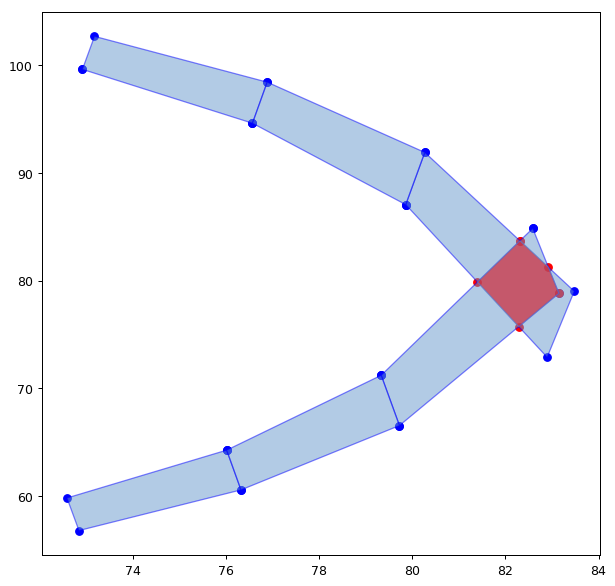

Successful overlap:
['S1A_EW_GRDM_1SDH_20141108T102248_20141108T102352_003189_003AC0_3DB7.zip', 'S1A_EW_GRDM_1SDH_20141108T102352_20141108T102452_003189_003AC0_F671.zip', 'S1A_EW_GRDM_1SDH_20141108T102452_20141108T102553_003189_003AC0_BE33.zip']
with
['S1A_EW_GRDM_1SDH_20141109T025624_20141109T025728_003199_003AFB_21F0.zip', 'S1A_EW_GRDM_1SDH_20141109T025728_20141109T025828_003199_003AFB_99EC.zip', 'S1A_EW_GRDM_1SDH_20141109T025828_20141109T025928_003199_003AFB_6992.zip']

Time difference is  16:33:36
2014-11-08T102248 2014-11-09T025624
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141108T102248_20141108T102352_003189_003AC0_3DB7.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141108T102352_20141108T102452_003189_003AC0_F671.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141108T102452_20141108T102553_003189_003AC0_BE33.zip
False True
no HV data found
2

2014-11-08 13:38:53 2014-11-09 02:56:24
area of intersection 0.0
cond_area False
2014-11-08 13:38:53 2014-11-09 04:35:09
area of intersection 6.22113052938
cond_area True
Images overlap


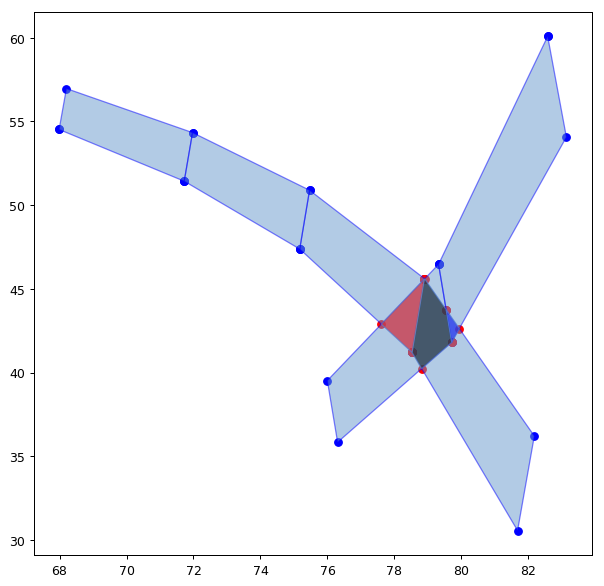

Successful overlap:
['S1A_EW_GRDM_1SDH_20141108T133853_20141108T133957_003191_003AC9_E3CE.zip', 'S1A_EW_GRDM_1SDH_20141108T133957_20141108T134057_003191_003AC9_D72F.zip', 'S1A_EW_GRDM_1SDH_20141108T134057_20141108T134157_003191_003AC9_5385.zip', 'S1A_EW_GRDM_1SDH_20141108T134157_20141108T134257_003191_003AC9_C214.zip']
with
['S1A_EW_GRDM_1SDH_20141109T043509_20141109T043613_003200_003B05_619A.zip', 'S1A_EW_GRDM_1SDH_20141109T043613_20141109T043713_003200_003B05_7883.zip']

Time difference is  14:56:16
2014-11-08T133853 2014-11-09T043509
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141108T133853_20141108T133957_003191_003AC9_E3CE.zip
78.526725769 40.2430259793 79.7082824707 45.5964598545
67.5786 47.0742 72.2356 60.3455
79.5460308975 41.8112030029 79.9371591735 43.7489930621
67.5786 47.0742 72.2356 60.3455
77.6104321408 41.214427948 78.8902714524 45.5740489646
67.5786 47.0742 72.2356 60.3455
False True
/home/cercache/users/atarasen/data/Sentine

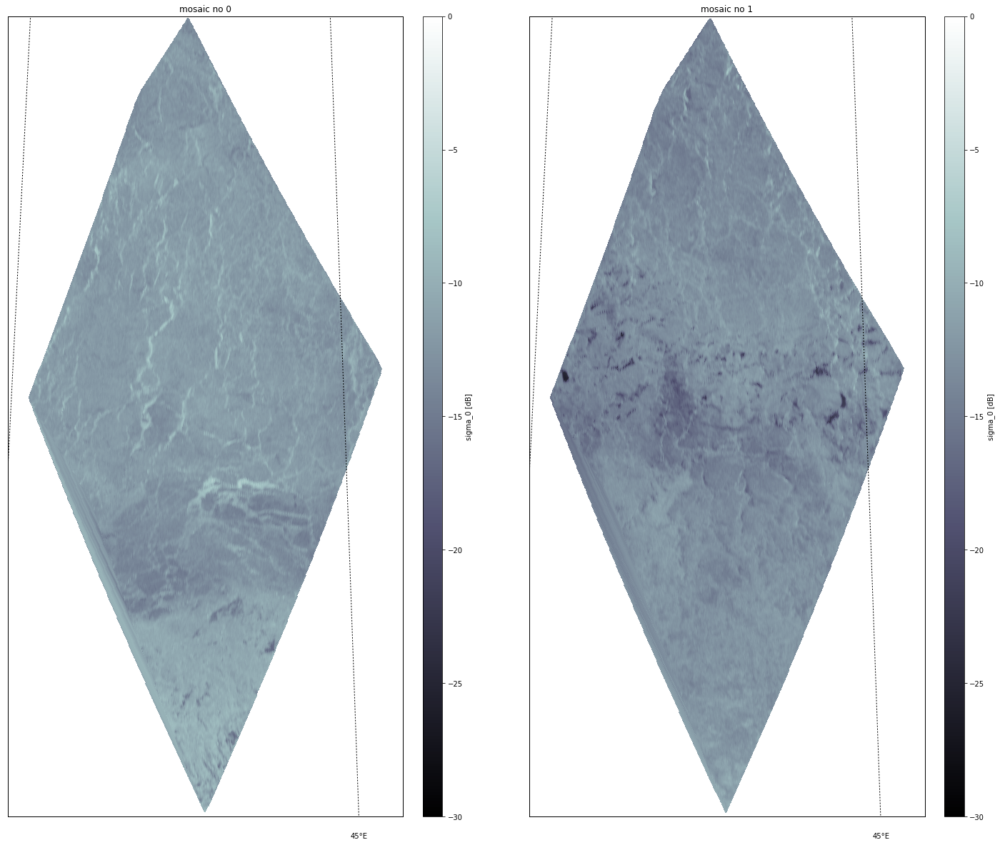

Kara_2014-11-08T133853_2014-11-09T043509_lat-3_lon-2_hh.pickle is created
2014-11-08 23:41:05 2014-11-09 02:56:24
area of intersection 0.0
cond_area False
2014-11-08 23:41:05 2014-11-09 04:35:09
area of intersection 0.0
cond_area False
2014-11-08 23:41:05 2014-11-09 11:04:10
area of intersection 0.0
cond_area False
2014-11-08 23:41:05 2014-11-09 12:45:02
area of intersection 0.0
cond_area False
2014-11-09 02:56:24 2014-11-09 04:35:09
area of intersection 0.0
cond_area False
2014-11-09 02:56:24 2014-11-09 11:04:10
area of intersection 6.19810492868
cond_area True
Images overlap


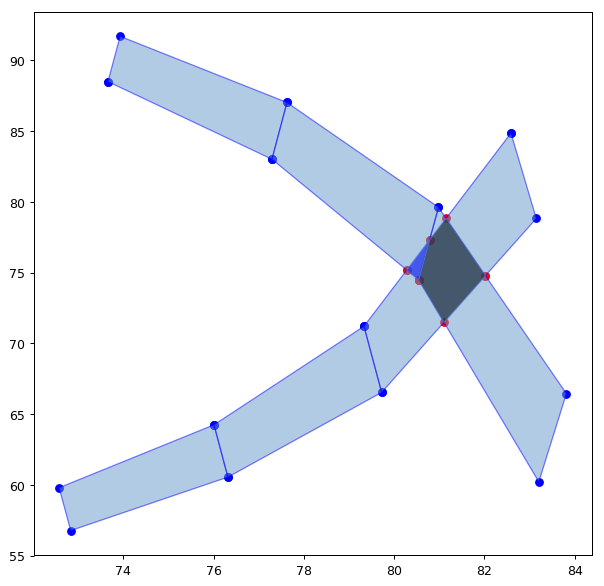

Successful overlap:
['S1A_EW_GRDM_1SDH_20141109T025624_20141109T025728_003199_003AFB_21F0.zip', 'S1A_EW_GRDM_1SDH_20141109T025728_20141109T025828_003199_003AFB_99EC.zip', 'S1A_EW_GRDM_1SDH_20141109T025828_20141109T025928_003199_003AFB_6992.zip']
with
['S1A_EW_GRDM_1SDH_20141109T110410_20141109T110514_003204_003B1A_2769.zip', 'S1A_EW_GRDM_1SDH_20141109T110514_20141109T110614_003204_003B1A_6F67.zip', 'S1A_EW_GRDM_1SDH_20141109T110614_20141109T110709_003204_003B1A_DBA4.zip']

Time difference is  8:07:46
2014-11-09T025624 2014-11-09T110410
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141109T025624_20141109T025728_003199_003AFB_21F0.zip
80.5444793701 71.4822592471 82.0213332582 78.8252590109
78.5968 59.6747 83.7618 92.5159
80.2801838201 74.4844055176 80.7833389765 77.2867075413
78.5968 59.6747 83.7618 92.5159
False False
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141109T025728_20141109T025828_003199_003AFB_99EC.

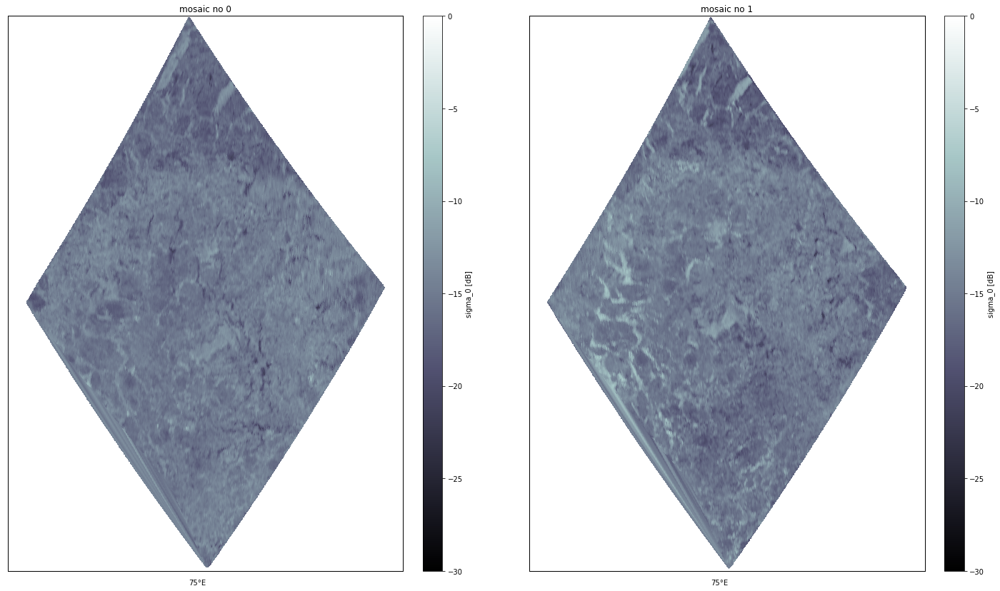

Kara_2014-11-09T025624_2014-11-09T110410_lat-3_lon-2_hh.pickle is created
2014-11-09 04:35:09 2014-11-09 11:04:10
area of intersection 0.0
cond_area False
2014-11-09 04:35:09 2014-11-09 12:45:02
area of intersection 4.62219542097
cond_area True
Images overlap


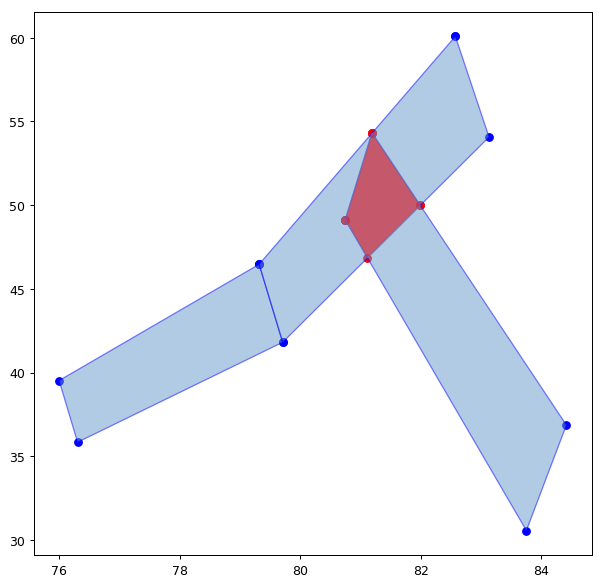

Successful overlap:
['S1A_EW_GRDM_1SDH_20141109T043509_20141109T043613_003200_003B05_619A.zip', 'S1A_EW_GRDM_1SDH_20141109T043613_20141109T043713_003200_003B05_7883.zip']
with
['S1A_EW_GRDM_1SSH_20141109T124502_20141109T124606_003205_003B1F_D6A1.zip']

Time difference is  8:09:53
2014-11-09T043509 2014-11-09T124502
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141109T043509_20141109T043613_003200_003B05_619A.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20141109T043613_20141109T043713_003200_003B05_7883.zip
False True
no HV data found
2014-11-09 11:04:10 2014-11-09 12:45:02
area of intersection 0.0
cond_area False


2015-07-20 03:39:36 2015-07-20 13:21:57
area of intersection 4.47204762579
cond_area True
Images overlap


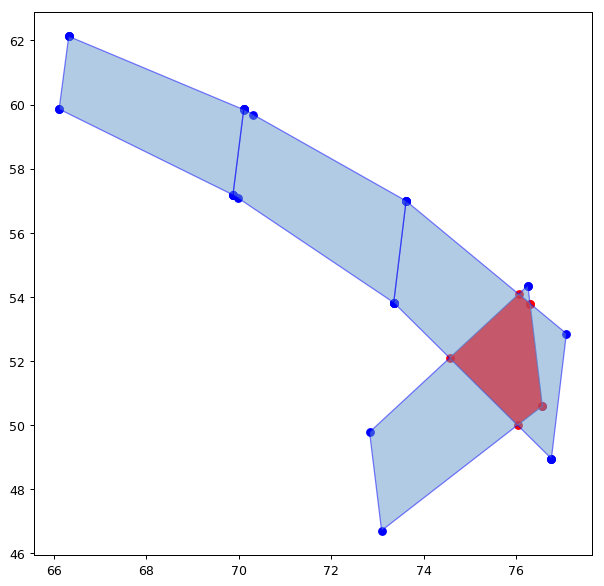

Successful overlap:
['S1A_EW_GRDM_1SDH_20150720T033936_20150720T034036_006889_0094DB_7E7A.zip']
with
['S1A_EW_GRDM_1SDH_20150720T132157_20150720T132301_006895_009508_2E4B.zip', 'S1A_EW_GRDM_1SDH_20150720T132157_20150720T132301_006895_009508_5FBD.zip', 'S1A_EW_GRDM_1SDH_20150720T132301_20150720T132401_006895_009508_47BA.zip', 'S1A_EW_GRDM_1SDH_20150720T132301_20150720T132401_006895_009508_7B5D.zip', 'S1A_EW_GRDM_1SDH_20150720T132401_20150720T132501_006895_009508_1F06.zip', 'S1A_EW_GRDM_1SDH_20150720T132401_20150720T132501_006895_009508_CAE5.zip']

Time difference is  9:42:21
2015-07-20T033936 2015-07-20T132157
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20150720T033936_20150720T034036_006889_0094DB_7E7A.zip
False True
no HV data found
2015-07-20 13:21:57 2015-07-21 02:42:00
area of intersection 1.2836380241
cond_area True
Images overlap


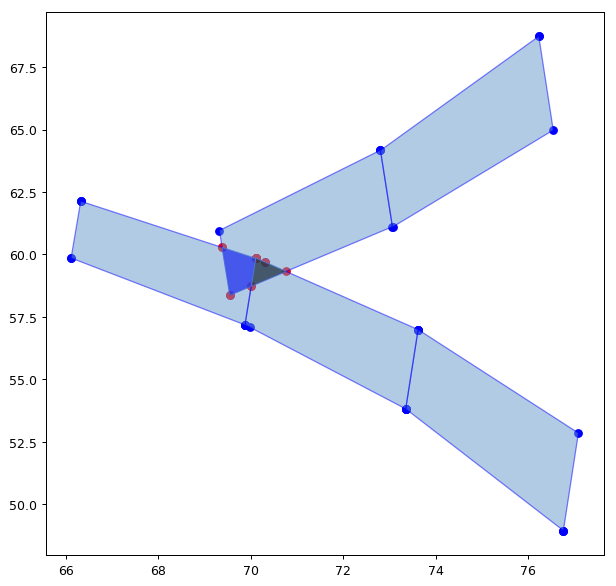

Successful overlap:
['S1A_EW_GRDM_1SDH_20150720T132157_20150720T132301_006895_009508_2E4B.zip', 'S1A_EW_GRDM_1SDH_20150720T132157_20150720T132301_006895_009508_5FBD.zip', 'S1A_EW_GRDM_1SDH_20150720T132301_20150720T132401_006895_009508_47BA.zip', 'S1A_EW_GRDM_1SDH_20150720T132301_20150720T132401_006895_009508_7B5D.zip', 'S1A_EW_GRDM_1SDH_20150720T132401_20150720T132501_006895_009508_1F06.zip', 'S1A_EW_GRDM_1SDH_20150720T132401_20150720T132501_006895_009508_CAE5.zip']
with
['S1A_EW_GRDM_1SDH_20150721T024200_20150721T024300_006903_009540_F685.zip', 'S1A_EW_GRDM_1SDH_20150721T024300_20150721T024400_006903_009540_64C2.zip']

Time difference is  13:20:03
2015-07-20T132157 2015-07-21T024200
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20150720T132157_20150720T132301_006895_009508_2E4B.zip
70.0088206485 58.7333962461 70.7617588082 59.8529014587
65.7244 53.1649 70.3522 65.2684
69.3803552034 58.3745956421 70.10521698 60.2779922823
65.7244 53.1649 70.3522

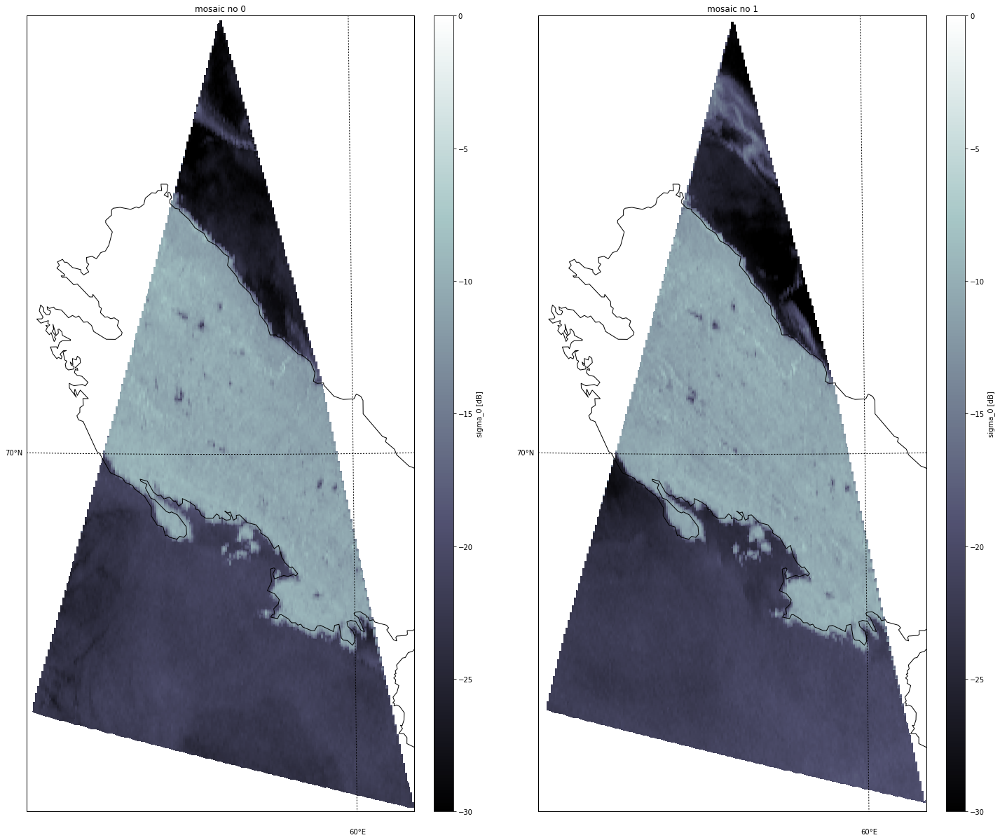

Kara_2015-07-20T132157_2015-07-21T024200_lat-3_lon-2_hh.pickle is created
2015-07-21 02:42:00 2015-07-21 19:08:46
area of intersection 1.09043707409
cond_area True
Images overlap


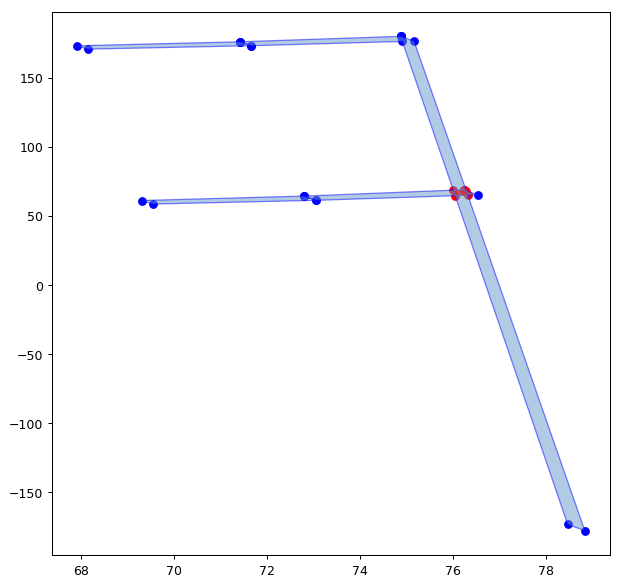

Successful overlap:
['S1A_EW_GRDM_1SDH_20150721T024200_20150721T024300_006903_009540_F685.zip', 'S1A_EW_GRDM_1SDH_20150721T024300_20150721T024400_006903_009540_64C2.zip']
with
['S1A_EW_GRDM_1SDH_20150721T190846_20150721T190950_006913_009584_424E.zip', 'S1A_EW_GRDM_1SDH_20150721T190950_20150721T191050_006913_009584_F52A.zip', 'S1A_EW_GRDM_1SDH_20150721T191050_20150721T191150_006913_009584_FA38.zip']

Time difference is  16:26:46
2015-07-21T024200 2015-07-21T190846
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20150721T024200_20150721T024300_006903_009540_F685.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20150721T024300_20150721T024400_006903_009540_64C2.zip
False True
no HV data found
2015-07-21 19:08:46 2015-07-22 13:06:38
area of intersection 1.17851688517
cond_area True
Images overlap


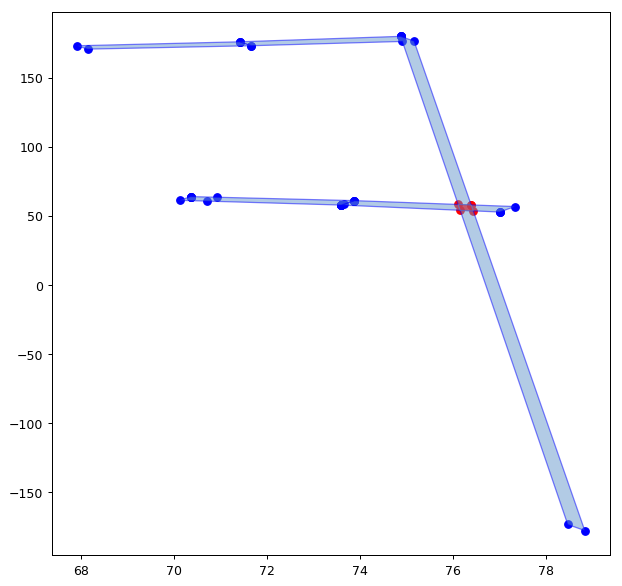

Successful overlap:
['S1A_EW_GRDM_1SDH_20150721T190846_20150721T190950_006913_009584_424E.zip', 'S1A_EW_GRDM_1SDH_20150721T190950_20150721T191050_006913_009584_F52A.zip', 'S1A_EW_GRDM_1SDH_20150721T191050_20150721T191150_006913_009584_FA38.zip']
with
['S1A_EW_GRDM_1SDH_20150722T130638_20150722T130738_006924_0095C0_6143.zip', 'S1A_EW_GRDM_1SDH_20150722T130638_20150722T130738_006924_0095C0_91D3.zip', 'S1A_EW_GRDM_1SDH_20150722T130738_20150722T130838_006924_0095C0_215C.zip', 'S1A_EW_GRDM_1SDH_20150722T130738_20150722T130838_006924_0095C0_7D67.zip']

Time difference is  17:57:52
2015-07-21T190846 2015-07-22T130638
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20150721T190846_20150721T190950_006913_009584_424E.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20150721T190950_20150721T191050_006913_009584_F52A.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20150721T

2015-07-22 13:06:38 2015-07-23 13:46:40
area of intersection 0.0
cond_area False
2015-07-22 13:06:38 2015-07-23 18:52:23
area of intersection 0.745306411286
cond_area True
Images overlap


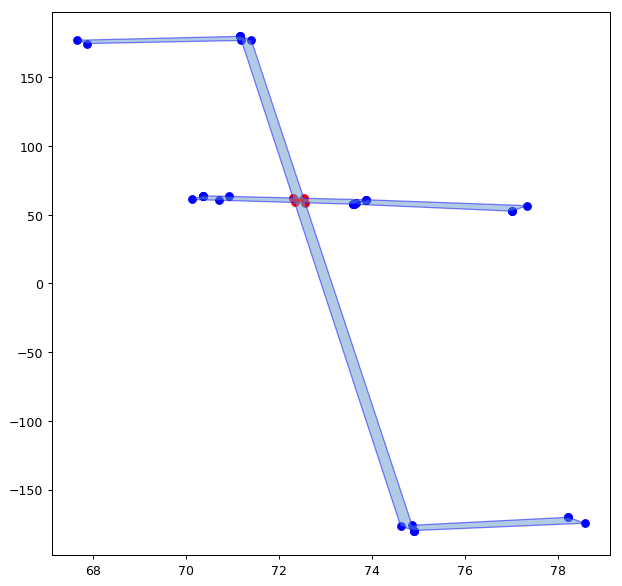

Successful overlap:
['S1A_EW_GRDM_1SDH_20150722T130638_20150722T130738_006924_0095C0_6143.zip', 'S1A_EW_GRDM_1SDH_20150722T130638_20150722T130738_006924_0095C0_91D3.zip', 'S1A_EW_GRDM_1SDH_20150722T130738_20150722T130838_006924_0095C0_215C.zip', 'S1A_EW_GRDM_1SDH_20150722T130738_20150722T130838_006924_0095C0_7D67.zip']
with
['S1A_EW_GRDM_1SDH_20150723T185223_20150723T185327_006942_009653_D157.zip', 'S1A_EW_GRDM_1SDH_20150723T185327_20150723T185427_006942_009653_305B.zip', 'S1A_EW_GRDM_1SDH_20150723T185427_20150723T185527_006942_009653_CC1B.zip']

Time difference is  1 day, 5:45:45
2015-07-22T130638 2015-07-23T185223
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20150722T130638_20150722T130738_006924_0095C0_6143.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20150722T130638_20150722T130738_006924_0095C0_91D3.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_201

2015-07-23 02:25:34 2015-07-23 18:52:23
area of intersection 0.717711584177
cond_area True
Images overlap


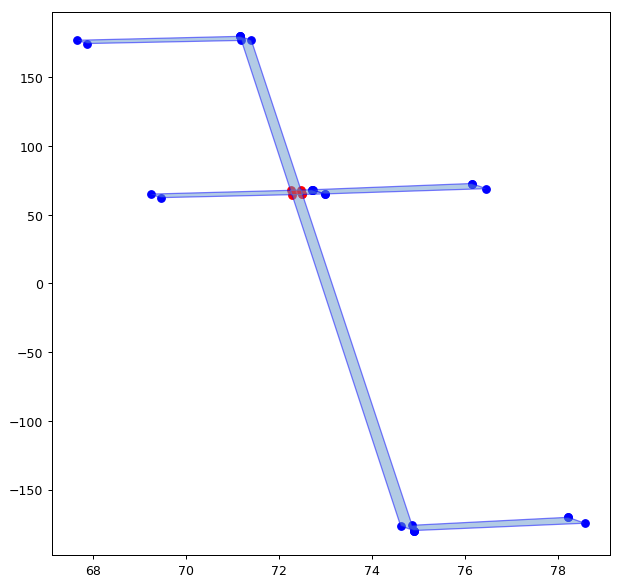

Successful overlap:
['S1A_EW_GRDM_1SDH_20150723T022534_20150723T022634_006932_00960D_2B7B.zip', 'S1A_EW_GRDM_1SDH_20150723T022634_20150723T022734_006932_00960D_D979.zip']
with
['S1A_EW_GRDM_1SDH_20150723T185223_20150723T185327_006942_009653_D157.zip', 'S1A_EW_GRDM_1SDH_20150723T185327_20150723T185427_006942_009653_305B.zip', 'S1A_EW_GRDM_1SDH_20150723T185427_20150723T185527_006942_009653_CC1B.zip']

Time difference is  16:26:49
2015-07-23T022534 2015-07-23T185223
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20150723T022534_20150723T022634_006932_00960D_2B7B.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20150723T022634_20150723T022734_006932_00960D_D979.zip
False True
no HV data found
2015-07-23 13:46:40 2015-07-23 18:52:23
area of intersection 0.75040056221
cond_area True
Images overlap


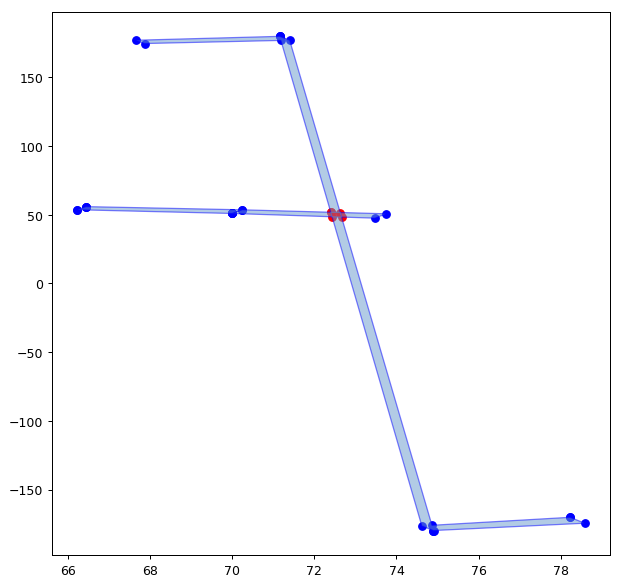

Successful overlap:
['S1A_EW_GRDM_1SDH_20150723T134640_20150723T134745_006939_00963B_76C5.zip', 'S1A_EW_GRDM_1SDH_20150723T134640_20150723T134745_006939_00963B_E685.zip', 'S1A_EW_GRDM_1SDH_20150723T134745_20150723T134845_006939_00963B_7856.zip']
with
['S1A_EW_GRDM_1SDH_20150723T185223_20150723T185327_006942_009653_D157.zip', 'S1A_EW_GRDM_1SDH_20150723T185327_20150723T185427_006942_009653_305B.zip', 'S1A_EW_GRDM_1SDH_20150723T185427_20150723T185527_006942_009653_CC1B.zip']

Time difference is  5:05:43
2015-07-23T134640 2015-07-23T185223
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20150723T134640_20150723T134745_006939_00963B_76C5.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20150723T134640_20150723T134745_006939_00963B_E685.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20150723T134745_20150723T134845_006939_00963B_7856.zip
False True
no HV data found
20

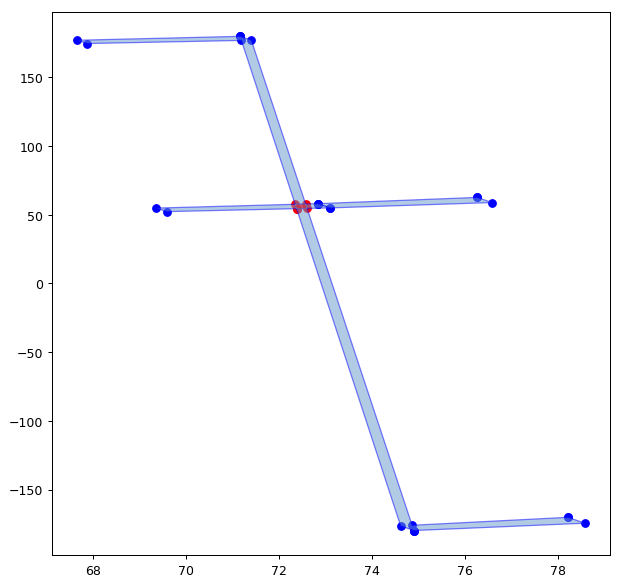

Successful overlap:
['S1A_EW_GRDM_1SDH_20150723T185223_20150723T185327_006942_009653_D157.zip', 'S1A_EW_GRDM_1SDH_20150723T185327_20150723T185427_006942_009653_305B.zip', 'S1A_EW_GRDM_1SDH_20150723T185427_20150723T185527_006942_009653_CC1B.zip']
with
['S1A_EW_GRDM_1SDH_20150724T030641_20150724T030741_006947_00967D_4876.zip', 'S1A_EW_GRDM_1SDH_20150724T030741_20150724T030841_006947_00967D_DBBE.zip']

Time difference is  8:14:18
2015-07-23T185223 2015-07-24T030641
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20150723T185223_20150723T185327_006942_009653_D157.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20150723T185327_20150723T185427_006942_009653_305B.zip
False True
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20150723T185427_20150723T185527_006942_009653_CC1B.zip
False True
no HV data found
2015-10-28 01:27:19 2015-10-29 02:08:13
area of intersection 0.0
cond_area Fa

2015-10-28 01:27:19 2015-10-30 01:10:53
area of intersection 1.23732593277
cond_area True
Images overlap


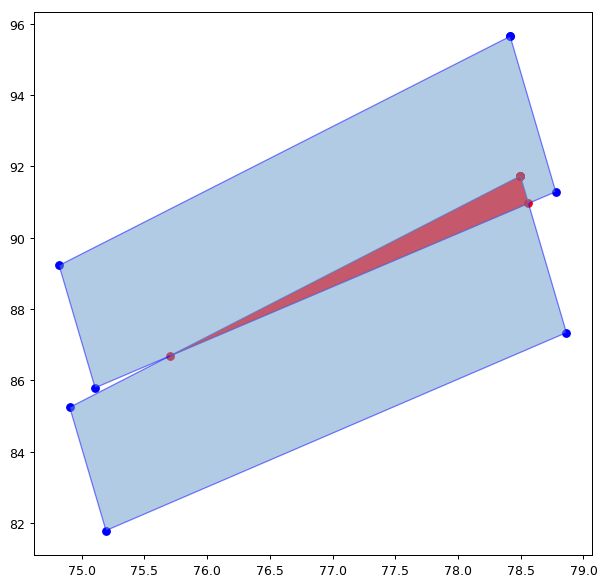

Successful overlap:
['S1A_EW_GRDM_1SDH_20151028T012719_20151028T012823_008346_00BC7A_5275.zip']
with
['S1A_EW_GRDM_1SDH_20151030T011053_20151030T011157_008375_00BD36_4B2A.zip']

Time difference is  1 day, 23:43:34
2015-10-28T012719 2015-10-30T011053
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20151028T012719_20151028T012823_008346_00BC7A_5275.zip
False True
no HV data found
2015-10-29 02:08:13 2015-10-30 01:10:53
area of intersection 0.0
cond_area False


2015-10-29 02:08:13 2015-10-31 01:51:50
area of intersection 2.32525756245
cond_area True
Images overlap


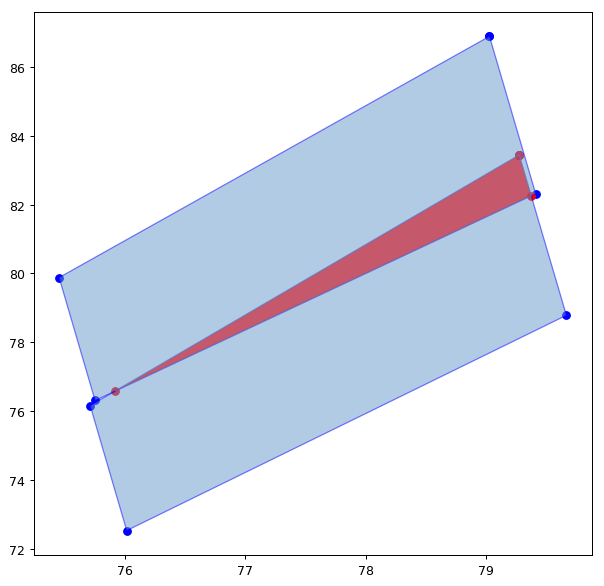

Successful overlap:
['S1A_EW_GRDM_1SDH_20151029T020813_20151029T020917_008361_00BCD2_9F88.zip']
with
['S1A_EW_GRDM_1SDH_20151031T015150_20151031T015255_008390_00BD99_F22B.zip']

Time difference is  1 day, 23:43:37
2015-10-29T020813 2015-10-31T015150
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20151029T020813_20151029T020917_008361_00BCD2_9F88.zip
False True
no HV data found
2015-10-30 01:10:53 2015-10-31 01:51:50
area of intersection 0.0
cond_area False


2015-12-16 13:31:14 2015-12-18 13:14:48
area of intersection 0.0
cond_area False
2015-12-16 13:31:14 2015-12-19 02:34:45
area of intersection 0.0
cond_area False
2015-12-18 13:14:48 2015-12-19 02:34:45
area of intersection 0.44835728449
cond_area False
2015-12-18 13:14:48 2015-12-20 12:58:25
area of intersection 0.0
cond_area False
2015-12-19 02:34:45 2015-12-20 12:58:25
area of intersection 5.31384580062
cond_area True
Images overlap


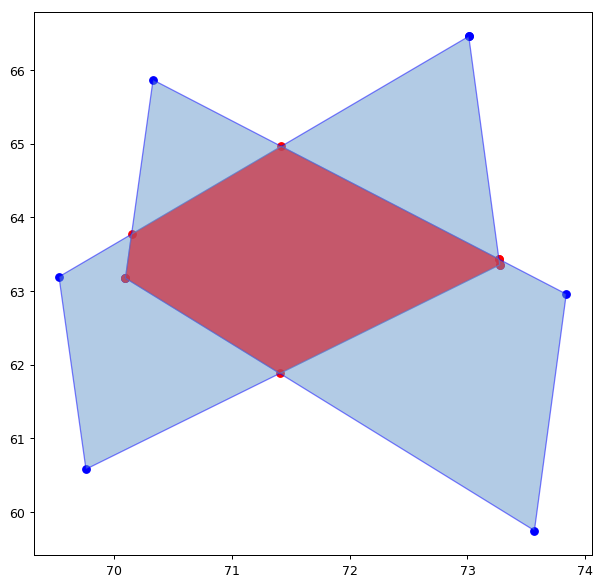

Successful overlap:
['S1A_EW_GRDM_1SDH_20151219T023445_20151219T023545_009105_00D15D_8BC0.zip']
with
['S1A_EW_GRDM_1SDH_20151220T125825_20151220T125925_009126_00D1F7_D15E.zip']

Time difference is  1 day, 10:23:40
2015-12-19T023445 2015-12-20T125825
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20151219T023445_20151219T023545_009105_00D15D_8BC0.zip
False True
no HV data found
2015-12-23 13:23:00 2015-12-24 02:42:59
area of intersection 0.627933539239
cond_area True
Images overlap


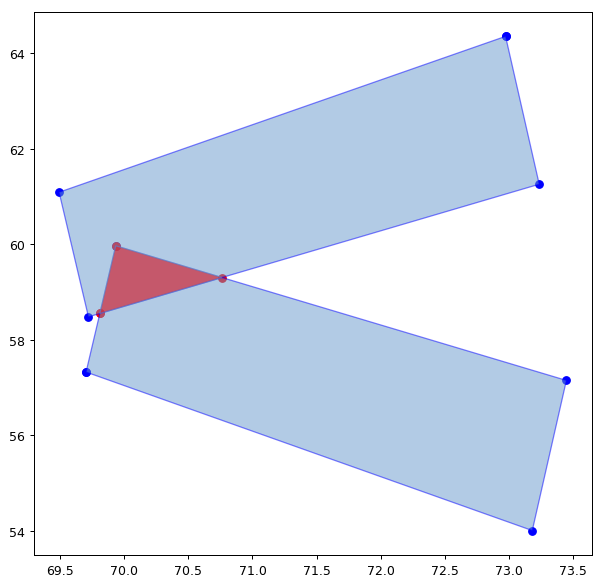

Successful overlap:
['S1A_EW_GRDM_1SDH_20151223T132300_20151223T132400_009170_00D332_8364.zip']
with
['S1A_EW_GRDM_1SDH_20151224T024259_20151224T024359_009178_00D371_FB09.zip']

Time difference is  13:19:59
2015-12-23T132300 2015-12-24T024259
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20151223T132300_20151223T132400_009170_00D332_8364.zip
False True
no HV data found
2015-12-24 02:42:59 2015-12-25 13:06:36
area of intersection 5.42028469218
cond_area True
Images overlap


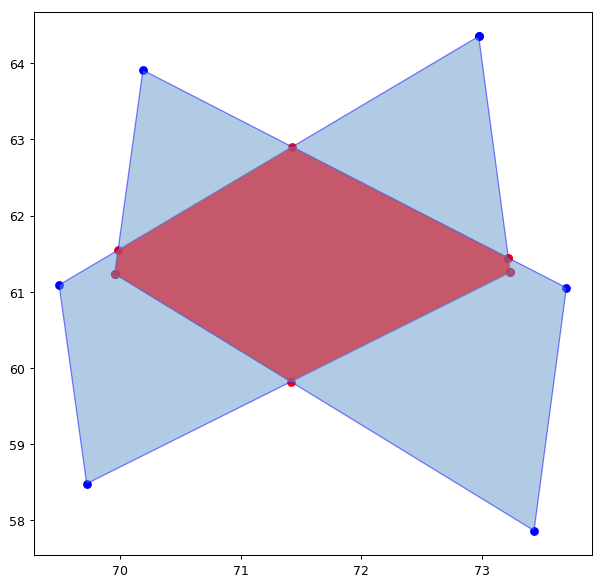

Successful overlap:
['S1A_EW_GRDM_1SDH_20151224T024259_20151224T024359_009178_00D371_FB09.zip']
with
['S1A_EW_GRDM_1SDH_20151225T130636_20151225T130736_009199_00D412_28F9.zip']

Time difference is  1 day, 10:23:37
2015-12-24T024259 2015-12-25T130636
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20151224T024259_20151224T024359_009178_00D371_FB09.zip
False True
no HV data found
2015-12-25 13:06:36 2015-12-26 02:26:33
area of intersection 0.311137213145
cond_area False


2015-12-25 13:06:36 2015-12-27 03:07:39
area of intersection 0.0
cond_area False
2015-12-25 13:06:36 2015-12-27 12:50:14
area of intersection 0.0
cond_area False
2015-12-26 02:26:33 2015-12-27 03:07:39
area of intersection 0.0
cond_area False
2015-12-26 02:26:33 2015-12-27 12:50:14
area of intersection 5.18437943434
cond_area True
Images overlap


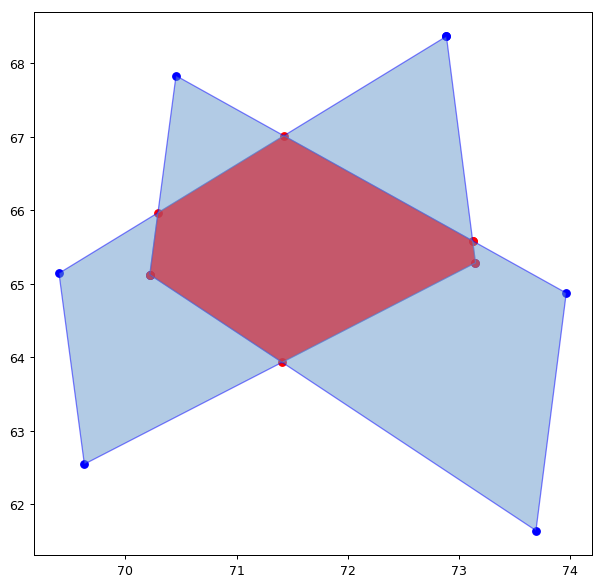

Successful overlap:
['S1A_EW_GRDM_1SDH_20151226T022633_20151226T022733_009207_00D44C_DEC8.zip']
with
['S1A_EW_GRDM_1SDH_20151227T125014_20151227T125114_009228_00D4E3_4B35.zip']

Time difference is  1 day, 10:23:41
2015-12-26T022633 2015-12-27T125014
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20151226T022633_20151226T022733_009207_00D44C_DEC8.zip
False True
no HV data found
2015-12-27 03:07:39 2015-12-27 12:50:14
area of intersection 0.0
cond_area False


2015-12-27 03:07:39 2015-12-28 13:31:14
area of intersection 5.47387058884
cond_area True
Images overlap


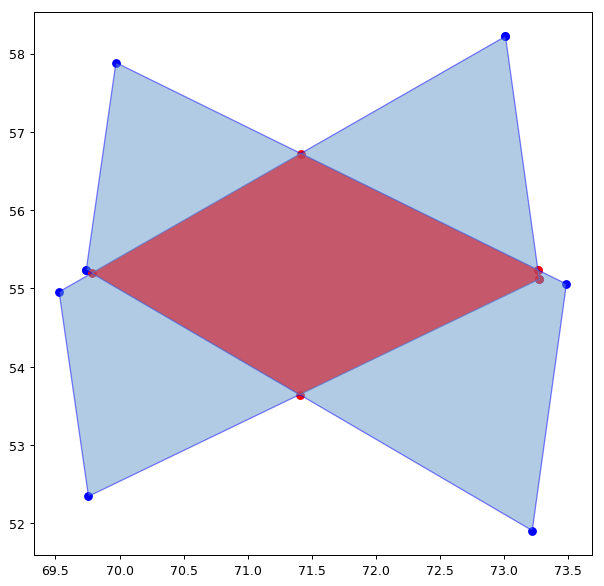

Successful overlap:
['S1A_EW_GRDM_1SDH_20151227T030739_20151227T030839_009222_00D4B4_1036.zip']
with
['S1A_EW_GRDM_1SDH_20151228T133114_20151228T133214_009243_00D553_8005.zip']

Time difference is  1 day, 10:23:35
2015-12-27T030739 2015-12-28T133114
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20151227T030739_20151227T030839_009222_00D4B4_1036.zip
False True
no HV data found
2015-12-27 12:50:14 2015-12-28 13:31:14
area of intersection 0.0
cond_area False


2015-12-28 13:31:14 2015-12-30 13:14:48
area of intersection 0.0
cond_area False
2015-12-28 13:31:14 2015-12-31 02:34:44
area of intersection 0.0
cond_area False
2015-12-30 13:14:48 2015-12-31 02:34:44
area of intersection 0.450388946072
cond_area False
2015-12-30 13:14:48 2016-01-01 12:58:25
area of intersection 0.0
cond_area False
2015-12-31 02:34:44 2016-01-01 12:58:25
area of intersection 5.31464083913
cond_area True
Images overlap


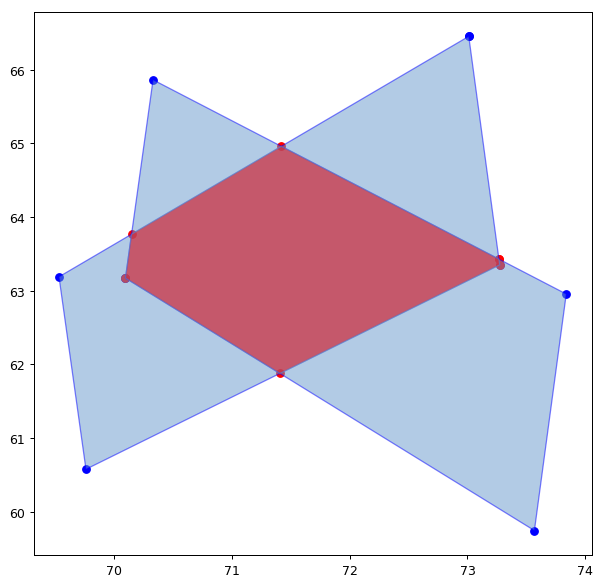

Successful overlap:
['S1A_EW_GRDM_1SDH_20151231T023444_20151231T023544_009280_00D65E_DC61.zip']
with
['S1A_EW_GRDM_1SDH_20160101T125825_20160101T125925_009301_00D6FA_E3C4.zip']

Time difference is  1 day, 10:23:41
2015-12-31T023444 2016-01-01T125825
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20151231T023444_20151231T023544_009280_00D65E_DC61.zip
False True
no HV data found
2016-01-01 12:58:25 2016-01-03 02:59:25
area of intersection 0.00121838722549
cond_area False


2016-01-03 02:59:25 2016-01-05 02:42:58
area of intersection 0.0
cond_area False
2016-01-05 02:42:58 2016-01-06 13:06:36
area of intersection 5.41821665425
cond_area True
Images overlap


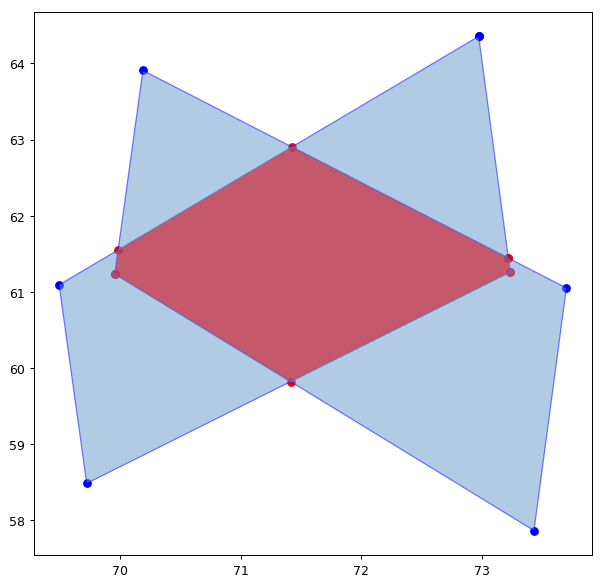

Successful overlap:
['S1A_EW_GRDM_1SDH_20160105T024258_20160105T024358_009353_00D86E_85E9.zip']
with
['S1A_EW_GRDM_1SDH_20160106T130636_20160106T130736_009374_00D90C_1FD1.zip']

Time difference is  1 day, 10:23:38
2016-01-05T024258 2016-01-06T130636
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20160105T024258_20160105T024358_009353_00D86E_85E9.zip
False True
no HV data found
2016-01-06 13:06:36 2016-01-07 02:26:32
area of intersection 0.308897998422
cond_area False


2016-01-06 13:06:36 2016-01-08 03:07:39
area of intersection 0.0
cond_area False
2016-01-07 02:26:32 2016-01-08 03:07:39
area of intersection 0.0
cond_area False
2016-01-07 02:26:32 2016-01-09 13:31:13
area of intersection 0.0
cond_area False
2016-01-08 03:07:39 2016-01-09 13:31:13
area of intersection 5.47466337192
cond_area True
Images overlap


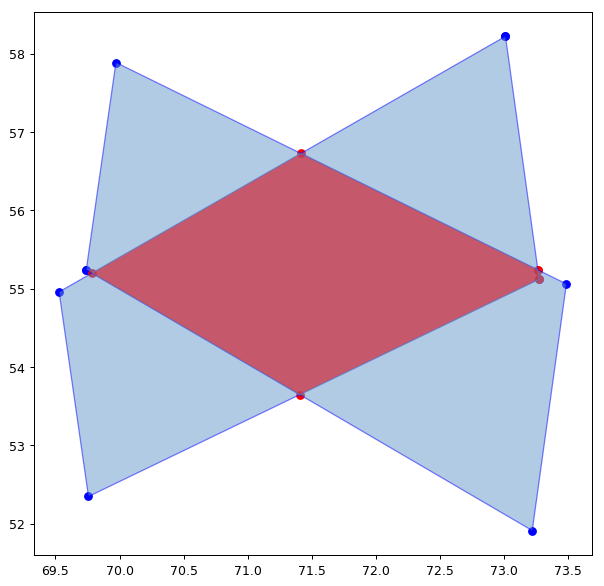

Successful overlap:
['S1A_EW_GRDM_1SDH_20160108T030739_20160108T030839_009397_00D9B6_65F2.zip']
with
['S1A_EW_GRDM_1SDH_20160109T133113_20160109T133213_009418_00DA52_5694.zip']

Time difference is  1 day, 10:23:34
2016-01-08T030739 2016-01-09T133113
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SDH_20160108T030739_20160108T030839_009397_00D9B6_65F2.zip
False True
no HV data found
2016-05-08 02:08:10 2016-05-10 11:38:30
area of intersection 0.0546735672324
cond_area False


2016-05-10 11:38:30 2016-05-11 02:32:41
area of intersection 5.2411984647
cond_area True
Images overlap


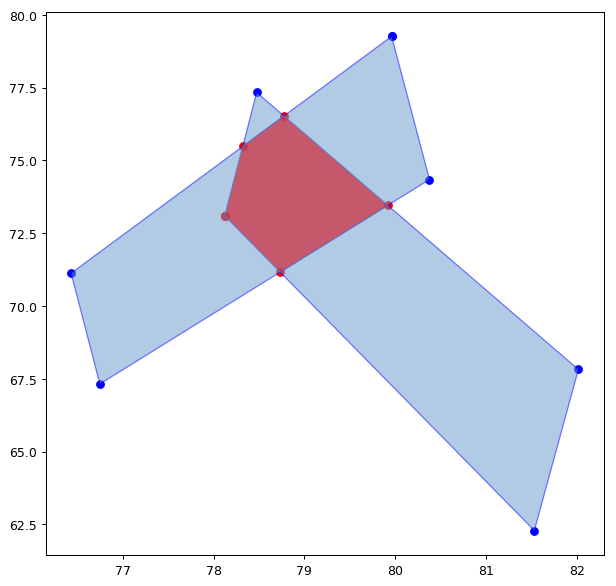

Successful overlap:
['S1A_EW_GRDM_1SSH_20160510T113830_20160510T113934_011196_010EA6_E823.zip']
with
['S1A_EW_GRDM_1SDH_20160511T023241_20160511T023346_011205_010EF1_A86C.zip']

Time difference is  14:54:11
2016-05-10T113830 2016-05-11T023241
Mosaic  0
/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/S1A_EW_GRDM_1SSH_20160510T113830_20160510T113934_011196_010EA6_E823.zip
False True
no HV data found
2016-05-11 02:32:41 2016-05-11 12:19:39
area of intersection 0.0
cond_area False


Total number of collocations 166
from  193 S1 files


In [8]:
#Part 3. Real collocation (NEW version with saving withing pickle files and dictionaries)
plt.close('all')
reload(colloc)
reload(plot_stereo)
reload(data_analysis)

### Open processed dictionaries
with open(fpath+'/Kara.pickle', 'rb') as handle:
    dicts = pickle.load(handle)
    
dates=dicts[0]; s1_names_dic=dicts[1]
lat_dic=dicts[2]; lon_dic=dicts[3]
corners_dic=dicts[4]  


n_of_collocations= 0
pol = 'hh'; spacing=500
deg_lat=3; deg_lon=2

coord_dic={}

# Run the loop over collection of dates (mosaics)
for i_date, date in enumerate(dates):
    if i_date < (len(dates)-1):
        ii=1
        while (ii+i_date)<(len(dates)) and dates[i_date+ii]-dates[i_date]<=datetime.timedelta(hours=72):
            print date, dates[i_date+ii]

# 3.1: Check if the images overlap:
            int_ans, coord, c = colloc.intersection_condition(corners_dic[date], corners_dic[dates[i_date+ii]], \
                                                           plot_cond=True)                     
            if int_ans==True:
                n_of_collocations = n_of_collocations + 1                        
                print 'Successful overlap:' 
                print s1_names_dic[date]
                print 'with'
                print s1_names_dic[dates[i_date+ii]]
                print ''
                print 'Time difference is ', (dates[i_date+ii])-date
 
                dates_temp = [date, dates[i_date+ii]]
                d1 = nf2.struct2string(date, ver='YYYY-mm-ddTHHMMSS')
                d2 = nf2.struct2string(dates[i_date+ii], ver='YYYY-mm-ddTHHMMSS')
                print d1, d2
                
                key_names = [d1, d2]
                dic_overlap={}; total_dic_overlap={}               
                total_dic_overlap[d1, d2]={}
                
                
# Preparations for plotting the overlapped days
                fig = plt.figure(figsize=(24, 24))
                fig_name = '/home3/homedir7/perso/atarasen/Figures/Kara/overlaps/'+d1+'_'+d2+'_'+pol+'.png'
                
# Run the loop for every mosaic:               
                try:                
                    for i_mosaic, mosaic in enumerate([s1_names_dic[date], s1_names_dic[dates[i_date+ii]]]):
                        data_flat_total = []; mask_flat_total=[]; lat_flat_total=[]; lon_flat_total=[]

                        print 'Mosaic ', i_mosaic
                        nf.tic()
                        key_name1 = key_names[i_mosaic] 
                        total_dic_overlap[d1, d2][key_name1]={}
    # 3.2 Open files from overlapping passages one by one                
                        for fn in mosaic:
                            print fpath+fn

                            sigma0, lat, lon180, _, elev_angle = S1_open.s1(fpath+fn, pol, spacing_m=spacing, excl_bord=True)
    #                         _, sigma_corr_lg = S1_open.s1_simple_processing(sigma0, elev_angle, pol=pol, corr=False)    
                            lon = plot_stereo.s1_lon360(lon180)


                            data_flat_total, lat_flat_total, lon_flat_total = colloc.overlap(c, sigma0, lat, lon, \
                                                                                      data_flat_total, lat_flat_total, lon_flat_total)
                            print sigma0==[], data_flat_total==[]

    # 3.3 Create regular grid and interpolate the vectors of flatten sigmas onto this grid           
                        regular_s1, regular_lat, regular_lon = colloc.regular_interpolate(data_flat_total, lat_flat_total, lon_flat_total, c, deg_lat, deg_lon)

    # 3.4. Collect all information of collocated images into one total dictionary                                  
                        total_dic_overlap[d1, d2][key_name1]['s_1_regular'] = regular_s1
                        total_dic_overlap[d1, d2][key_name1]['lat_regular'] = regular_lat
                        total_dic_overlap[d1, d2][key_name1]['lon_regular'] = regular_lon
                        total_dic_overlap[d1, d2]['overlap_poly'] = c

    # 3.5 Plotting                
                        ax1 = fig.add_subplot(1, 2, i_mosaic+1)
    #                     data_log = 10*np.log10(regular_s1.data)
    #                     data_log = ma.arrray(data_log, mask = regular_s1.mask)
                        data_log = 10*np.log10(regular_s1)
                        plot_stereo.zoom(data_log, regular_lat, regular_lon, \
                                     fn[:-4], pol=pol+'_log', case='Kara',\
                                     fig_title="mosaic no " + str(i_mosaic),\
                                     buoy_case=None,\
                                     col_bar=True, col_map_name='bone')

                        nf.toc()

                    plt.savefig(fig_name, dpi=300)
                    plt.show() 
    #                 nf.pause()


    # 3.6. Save total dictionary for 2 mosaics into one pickle file:
                    pickle_name = 'Kara_'+d1+'_'+d2+'_lat-'+str(deg_lat)+'_lon-'+str(deg_lon)+'_'+pol+'.pickle'
                    with open(fpathout+'/'+pickle_name, 'wb') as handle:
                        pickle.dump(total_dic_overlap, handle, protocol=pickle.HIGHEST_PROTOCOL)                    
                    print  pickle_name, 'is created'

                except:
                    print 'no HV data found'

                break
            ii=ii+1
    
print "Total number of collocations", n_of_collocations
print "from ", len(dates), "S1 files"                

In [ ]:
#Part 3. Real collocation (version with saving withing pickle files and dictionaries)
plt.close('all')
reload(colloc)
reload(plot_stereo)
reload(data_analysis)

### Open processed dictionaries
with open(fpath+'/Kara.pickle', 'rb') as handle:
    dicts = pickle.load(handle)
    
dates=dicts[0]; s1_names_dic=dicts[1]
lat_dic=dicts[2]; lon_dic=dicts[3]
corners_dic=dicts[4]  


n_of_collocations= 0
pol = 'hv'
spacing=500
deg_lat=3; deg_lon=2

coord_dic={}


# Run over the collection of dates (mosaics)
for i_date, date in enumerate(dates):
    if i_date < (len(dates)-1):
        ii=1
        while ii<(len(dates)-1) and dates[i_date+ii]-dates[i_date]<=datetime.timedelta(hours=72):
            print date, dates[i_date+ii]

# Step 3.1: Check if the images overlap:
            int_ans, coord, c = colloc.intersection_condition(corners_dic[date], corners_dic[dates[i_date+ii]], \
                                                           plot_cond=True)
                      
            if int_ans==True:
                n_of_collocations = n_of_collocations + 1                        
                print 'Successful overlap:' 
                print s1_names_dic[date]
                print 'with'
                print s1_names_dic[dates[i_date+ii]]
                print ''
                print 'Time difference is ', date-(dates[i_date+ii])
 

                regular_lat, regular_lon = colloc.regular_grid(c, deg_lat=deg_lat, deg_lon=deg_lon)
                

                dates_temp = [date, dates[i_date+ii]]
                d1 = nf2.struct2string(date, ver='YYYY-mm-ddTHHMMSS')
                d2 = nf2.struct2string(dates[i_date+ii], ver='YYYY-mm-ddTHHMMSS')
                print d1, d2
                
                key_names = [d1, d2]
                dic_overlap={}; temp_dic_overlap={}; total_dic_overlap={}               
                total_dic_overlap[d1, d2]={}
                
                
                try:                
    # Preparations for plotting the overlapped days
                    fig = plt.figure(figsize=(24,24))
                    fig_name = '/home3/homedir7/perso/atarasen/Figures/Kara/overlaps/'+d1+'_'+d2+'_'+pol+'.png'

    # 3.2 Open files from overlapping passages one by one                
                    for i_mosaic, mosaic in enumerate([s1_names_dic[date], s1_names_dic[dates[i_date+ii]]]):
                        print 'Mosaic ', i_mosaic

                        temp_dic_overlap[i_mosaic]={}
                        temp_dic_overlap[i_mosaic]['s_1'] = []
                        temp_dic_overlap[i_mosaic]['lat'] = []; temp_dic_overlap[i_mosaic]['lon'] = []

                        key_name1 =  key_names[i_mosaic] 
                        dic_overlap[key_name1]={}
                        dic_overlap[key_name1]['s1_names'] = s1_names_dic[dates_temp[i_mosaic]]
                        dic_overlap[key_name1]['s_1_regular']= {}

                        
                        nf.tic()
    # Open every S1 image in "mosaic"                    
                        for fn in mosaic:
                            print fpath+fn

                            sigma0, lat, lon180, _, elev_angle = S1_open.s1(fpath+fn, pol, spacing_m=spacing, excl_bord=True)
    #                         _, sigma_corr_lg = S1_open.s1_simple_processing(sigma0, elev_angle, pol=pol, corr=False)    
                            lon = plot_stereo.s1_lon360(lon180)

                            data_flat_total, lat_flat_total, lon_flat_total = overlap(c, sigma0, lat, lon, data_flat_total=[], lat_flat_total=[], lon_flat_total=[])
            
            
#                             s1_fn, lat_fn, lon_fn = colloc.contains_point_withshapely_v2(sigma0, lat, lon, c)
#                             if s1_fn!=[]:
#                                 print "sucessful overlap!"
#                                 temp_dic_overlap[i_mosaic]['s_1']+=s1_fn
#                                 temp_dic_overlap[i_mosaic]['lat']+=lat_fn
#                                 temp_dic_overlap[i_mosaic]['lon']+=lon_fn


    # Create a common regular grid and interpolate collected sigma_0 onto this grid

                        regular_s1, regular_lat, regular_lon = colloc.regular_interp(temp_dic_overlap[i_mosaic]['s_1'], temp_dic_overlap[i_mosaic]['lat'], temp_dic_overlap[i_mosaic]['lon'],\
                                                                                     c, regular_lat, regular_lon,\
                                                                                     deg_lat=deg_lat, deg_lon=deg_lon,\
                                                                                     mask_land=True)


                        dic_overlap[key_name1]['s_1_regular'][pol] = regular_s1
                        dic_overlap[key_name1]['lat_regular'] = regular_lat
                        dic_overlap[key_name1]['lon_regular'] = regular_lon

    # Collect all information of collocated images into one total dictionary                   
                        total_dic_overlap[d1, d2][key_name1] = dic_overlap[key_name1]
                        total_dic_overlap[d1, d2]['overlap_poly'] = c



    # Plotting                
                        ax1 = fig.add_subplot(1, 2, i_mosaic+1)
    #                     data_log = 10*np.log10(regular_s1.data)
    #                     data_log = ma.arrray(data_log, mask = regular_s1.mask)
                        data_log = 10*np.log10(regular_s1)
                        plot_stereo.zoom(data_log, regular_lat, regular_lon, \
                                     fn[:-4], pol=pol+'_log', case='Kara',\
                                     fig_title="mosaic no " + str(i_mosaic),\
                                     buoy_case=None,\
                                     col_bar=True, col_map_name='bone')

                        nf.toc()

                    plt.savefig(fig_name, dpi=300)
                    plt.show() 
    #                 nf.pause()


    #Save total dictionary for 2 mosaics into one pickle file:
                    pickle_name = 'Kara_'+d1+'_'+d2+'_lat-'+str(deg_lat)+'_lon-'+str(deg_lon)+'_'+pol+'_'+str(i_mosaic)+'.pickle'
                    with open(fpathout+'/'+pickle_name, 'wb') as handle:
                        pickle.dump(total_dic_overlap, handle, protocol=pickle.HIGHEST_PROTOCOL)                    
                    print  pickle_name, 'is created'
                    
                except:
                    print 'no HV data found'

                break
            ii=ii+1
    
print "Total number of collocations", n_of_collocations
print "from ", len(dates), "S1 files"
        

In [ ]:
# Last overlap before the kernel died out was :
#     2014-10-30 01:01:16 2014-10-30 04:18:43


In [ ]:
#Part 3. Real collocation(with necdfs)
plt.close('all')
reload(colloc)
reload(plot_stereo)
reload(data_analysis)

### Open processed dictionaries
with open(fpath+'/Kara.pickle', 'rb') as handle:
    dicts = pickle.load(handle)
    
dates=dicts[0]; s1_names_dic=dicts[1]
lat_dic=dicts[2]; lon_dic=dicts[3]
corners_dic=dicts[4]  


n_of_collocations= 0
pol = 'hv'
spacing=1000
deg_lat=1; deg_lon=1

coord_dic={}


# Run over the collection of dates (mosaics)
for i_date, date in enumerate(dates):
    if i_date < (len(dates)-1):
        ii=1
        while ii<(len(dates)-1) and dates[i_date+ii]-dates[i_date]<=datetime.timedelta(hours=72):
            print date, dates[i_date+ii]

# Step 3.1: Check if the images overlap:
            int_ans, coord, c = colloc.intersection_condition(corners_dic[date], corners_dic[dates[i_date+ii]], \
                                                           plot_cond=True)        
            if int_ans==True:
                print 'Successful overlap:' 
                print s1_names_dic[date]
                print s1_names_dic[dates[i_date+ii]]
                print 'Time difference is ', date-(dates[i_date+ii])
                
                regular_lat, regular_lon = colloc.regular_grid(c, deg_lat=deg_lat, deg_lon=deg_lon)
                
                n_of_collocations = n_of_collocations + 1

                dates_temp = [date, dates[i_date+ii]]
                d1 = nf2.struct2string(date, ver='YYYY-mm-ddTHHMMSS')
                d2 = nf2.struct2string(dates[i_date+ii], ver='YYYY-mm-ddTHHMMSS')
                print d1, d2
                
                key_names = [d1, d2]
                dic_overlap={}; temp_dic_overlap={}; total_dic_overlap={}               
                total_dic_overlap[d1, d2]={}

                
                
# write resulting netcdf:
                fn_out='Kara_'+d1+'_'+d2+'_lat-'+str(deg_lat)+'_lon-'+str(deg_lon)+'_'+pol+'.nc'
                if os.path.isfile(fpathout+'/'+fn_out)==True:
                    os.remove(fpathout+'/'+fn_out)
                
                ncout = netCDF4.Dataset(fpathout+'/'+fn_out, 'w', format='NETCDF4')
                lat_dimension = ncout.createDimension('lat', regular_lat.shape[0])
                lon_dimension = ncout.createDimension('lon', regular_lon.shape[1])
                time_dimension = ncout.createDimension('time')
                n_of_fnames_dim = ncout.createDimension('list of collocated S1 files')

                regular_lat_var = ncout.createVariable('regular_lat','f4',('lat', 'lon',))
                regular_lon_var = ncout.createVariable('regular_lon','f4',('lat', 'lon',))
                regular_sigma0_var = ncout.createVariable('regular_sigma0','f4',('lat', 'lon', 'time',))
                time = ncout.createVariable('time', str, ('time',))
                n_of_fnames = ncout.createVariable('S1_names_1', str ,('list of collocated S1 files', 'time',))
                
                regular_lat_var[:] = regular_lat
                regular_lon_var[:] = regular_lon
#                 print type(key_names)
                time[:] = np.array(key_names, dtype='object')                
                
                
#                 try:                
# Preparations for plotting the overlapped days
                fig = plt.figure(figsize=(24,24))
                fig_name = '/home3/homedir7/perso/atarasen/Figures/Kara/overlaps/'+d1+'_'+d2+'_'+pol+'.png'

# 3.2 Open files from overlapping passages one by one                
                for i_mosaic, mosaic in enumerate([s1_names_dic[date], s1_names_dic[dates[i_date+ii]]]):
                    print 'Mosaic ', i_mosaic

                    temp_dic_overlap[i_mosaic]={}
                    temp_dic_overlap[i_mosaic]['s_1'] = []
                    temp_dic_overlap[i_mosaic]['lat'] = []; temp_dic_overlap[i_mosaic]['lon'] = []

                    key_name1 =  key_names[i_mosaic] 
#                     dic_overlap[key_name1]={}
#                     dic_overlap[key_name1]['s1_names'] = s1_names_dic[dates_temp[i_mosaic]]
#                     dic_overlap[key_name1]['s_1_regular']= {}
                    
                    
                    nf.tic()
# Open every S1 image in "mosaic"                    
                    for fn in mosaic:
                        print fpath+fn

                        sigma0, lat, lon180, _, elev_angle = S1_open.s1(fpath+fn, pol, spacing_m=spacing, excl_bord=True)
#                         _, sigma_corr_lg = S1_open.s1_simple_processing(sigma0, elev_angle, pol=pol, corr=False)    
                        lon = plot_stereo.s1_lon360(lon180)


                        s1_fn, lat_fn, lon_fn = colloc.contains_point_withshapely_v2(sigma0, lat, lon, c)
                        if s1_fn!=[]:
                            print "sucessful overlap!"
                            temp_dic_overlap[i_mosaic]['s_1']+=s1_fn
                            temp_dic_overlap[i_mosaic]['lat']+=lat_fn
                            temp_dic_overlap[i_mosaic]['lon']+=lon_fn

#                             plt.scatter(lon_fn, lat_fn, c=s1_fn)
#                             plt.show()

# Create a common regular grid and interpolate collected sigma_0 onto this grid

                    regular_s1, regular_lat, regular_lon = colloc.regular_interp(temp_dic_overlap[i_mosaic]['s_1'], temp_dic_overlap[i_mosaic]['lat'], temp_dic_overlap[i_mosaic]['lon'],\
                                                                                 c, regular_lat, regular_lon,\
                                                                                 deg_lat=deg_lat, deg_lon=deg_lon,\
                                                                                 mask_land=True)
    
#                     regular_sigma0_var[:, :, i_mosaic] = regular_s1
#                     n_of_fnames[:, i_mosaic] = np.array(s1_names_dic[dates_temp[i_mosaic]], dtype='object') 
            
            
                    dic_overlap[key_name1]['s_1_regular'][pol] = regular_s1
#                     dic_overlap[key_name1]['lat_regular'] = regular_lat
#                     dic_overlap[key_name1]['lon_regular'] = regular_lon

# # Colect all information of collocated images into one total dictionary
#                     total_dic_overlap[d1, d2][key_name1] = dic_overlap[key_name1]

#                     pickle_name = 'Kara_'+d1+'_'+d2+'_lat-'+str(deg_lat)+'_lon-'+str(deg_lon)+'_'+pol+'.pickle'
#                     with open(fpathout+'/'+pickle_name, 'wb') as handle:
#                         pickle.dump(total_dic_overlap, handle, protocol=pickle.HIGHEST_PROTOCOL)                    
#                     print  pickle_name, 'is created'
                    
                 

                    
                    
#Plotting                

                    ax1 = fig.add_subplot(1, 2, i_mosaic+1)
                    data_log = 10*np.log10(dic_overlap[key_name1]['s_1_regular'][pol])
                    nf.pause()
#                     plt.pcolormesh(regular_lat, regular_lon, data_log.data)
                    plot_stereo.zoom(data_log, regular_lat, regular_lon, \
                                 fn[:-4], pol=pol+'_log', case='Kara',\
                                 fig_title="mosaic no " + str(i_mosaic),\
                                 buoy_case=None,\
                                 col_bar=True, col_map_name='bone')

                    nf.toc()

                plt.savefig(fig_name, dpi=300)
                plt.show() 
                nf.pause()

                ncout.close()   
                    
#                 except:
#                     print 'no HV data found'

                break
            ii=ii+1
    
print n_of_collocations
print len(dates)


# with open(fpathout+'/Kara_Pol-'+pol+'_deg-lat-'+deg_lat+'_deg-lon-'+deg_lon+'.pickle', 'wb') as handle:
#     pickle.dump(dic_overlap, handle, protocol=pickle.HIGHEST_PROTOCOL)

print 'S1 names sorted'  
        

In [ ]:
pick_nm = 'Kara_2014-10-03T003636_2014-10-03T102248_lat-3_lon-2_hv.pickle'
fpathout = '/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/mosaics/'
with open(fpathout+pick_nm, 'rb') as handle:
    all_data = pickle.load(handle)

print all_data[('2014-10-03T003636', '2014-10-03T102248')]['2014-10-03T003636']['s1_names'] 

In [ ]:
    reload(S1_open)
    fname = 'S1A_EW_GRDH_1SDH_20141005T100711_20141005T100811_002693_003022_63A6.zip'

#     'S1A_EW_GRDH_1SDH_20141003T003636_20141003T003740_002658_002F54_ECFA.zip'
#     'S1A_EW_GRDM_1SDH_20141003T134057_20141003T134157_002666_002F83_0B57.zip'
#     
#     'S1A_EW_GRDH_1SDH_20141003T102452_20141003T102553_002664_002F76_F611.zip'
#     'S1A_EW_GRDH_1SDH_20141003T102248_20141003T102352_002664_002F76_222F.zip'
#     'S1A_EW_GRDH_1SDH_20141003T102452_20141003T102553_002664_002F76_F611.zip'
    fn = '/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/'+fname
    pol = 'hv'
    spacing_m=100
    sigma0, lat, lon180, _, ele = S1_open.s1(fn, pol, spacing_m=spacing_m, excl_bord=True)

    
#     sarf = SAFEGeoTiffFile(url=fn, polarization=pol)
    
#     sarf.open()
#     sw = Swath()
#     sw.load(sarf)
#     sar = SAR(sw)
    
#     spacing = np.int0(sar.meters2pixels(spacing_m))
#     #ssr = sar.get_data('roughness', spacing=spacing)
#     sigma0 = sar.get_data('sigma0', spacing=spacing)
    
#     ele = sar.get_data('elevation', spacing=spacing)
#     inc = sar.get_data('incidence', spacing=spacing)
#     lat = sar.get_data('lat', spacing=spacing)
#     lon = sar.get_data('lon', spacing=spacing)
    

In [ ]:
    print sigma0.shape
#     sigma_mean=[]; ele_mean=[]
    
# #     print sigma0[:, 0]
#     for i, ix in enumerate(np.array(sigma0)):
    
    sigma_mean=np.mean(sigma0,0) #sigma mean along the azimouth
    ele_mean= np.mean(ele, 0)
    
    plt.plot(sigma_mean)
#     plt.plot(ele_mean, sigma_mean)
#     plt.plot(ele_mean[50:-50], sigma_mean[50:-50])

    plt.show()
    
    fft_result=np.fft.fft(sigma_mean)[range(len(sigma_mean)/2)]
    freq=1/len(sigma_mean)
    plt.plot(fft_result[0:500])
    plt.show()
    
    
    print np.median(sigma_mean), np.min(sigma_mean), len(sigma_mean)
    

#     sigma_new = sigma0[ind_left:ind_right]
    plt.pcolormesh(10*np.log10(sigma0))
    plt.show()


    plt.pcolormesh(10*np.log10(sigma0[:, 0:100]))
    plt.show()

In [ ]:
#backup

#Part 3. Real collocation
reload(colloc)
reload(plot_stereo)
reload(data_analysis)

### Open processed dictionaries
with open(fpathout+'/Kara.pickle', 'rb') as handle:
    dicts = pickle.load(handle)
    
dates=dicts[0]; s1_names_dic=dicts[1]
lat_dic=dicts[2]; lon_dic=dicts[3]
corners_dic=dicts[4]  



n_of_collocations= 0
pol = 'hv'
spacing=500
deg_lat=3; deg_lon=2

coord_dic={}


# Run over the collection of dates (mosaics)
for i_date, date in enumerate(dates):
    if i_date < (len(dates)-1):
        ii=1
        while ii<(len(dates)-1) and dates[i_date+ii]-dates[i_date]<=datetime.timedelta(hours=72):
            print date, dates[i_date+ii]

# Step 3.1: Check if the images overlap:
            int_ans, coord, c = colloc.intersection_condition(corners_dic[date], corners_dic[dates[i_date+ii]], \
                                                           plot_cond=True)        
            if int_ans==True:
                print 'Successful overlap: '
                print s1_names_dic[date] 
                print 'with', s1_names_dic[dates[i_date+ii]]
                
                coord_dic[date]={'coord':coord, 'collocated_with': dates[i_date+ii]}                             
                n_of_collocations = n_of_collocations + 1
                               
                nf.tic()
                dic_overlap={}; temp_dic_overlap={}
                try:
                
    # Preparations for plotting the overlapped days
                    fig = plt.figure(figsize=(24,24))
                    fig_name = '/home3/homedir7/perso/atarasen/Figures/Kara/overlaps/'+\
                               nf2.struct2string(date, ver='YYYY-mm-ddTHHMMSS')+'_'+\
                               nf2.struct2string(dates[i_date+ii], ver='YYYY-mm-ddTHHMMSS')+'_'+pol+'.png'

                    key_names = [date, dates[i_date+ii]]
    # 3.2 Open files from overlapping passages one by one                
                    for i_mosaic, mosaic in enumerate([s1_names_dic[date], s1_names_dic[dates[i_date+ii]]]):
                        print 'Mosaic ', i_mosaic

                        temp_dic_overlap[i_mosaic]={}
                        temp_dic_overlap[i_mosaic]['s_1']=[]
                        temp_dic_overlap[i_mosaic]['lat']=[] 
                        temp_dic_overlap[i_mosaic]['lon']=[]

                        key_name1 =  key_names[i_mosaic] 
                        dic_overlap[key_name1]={}
                        dic_overlap[key_name1]['s1_names'] = [s1_names_dic[date], s1_names_dic[dates[i_date+ii]]]


    # Open every S1 image in "mosaic"                    
                        for fn in mosaic:
                            print fpathout+fn

                            nf.tic()
                            sigma0, lat, lon180, _, elev_angle = S1_open.s1(fpathout+fn, pol, spacing_m=spacing, excl_bord=True)
    #                         _, sigma_corr_lg = S1_open.s1_simple_processing(sigma0, elev_angle, pol=pol, corr=False)    
                            lon = plot_stereo.s1_lon360(lon180)


                            s1_fn, lat_fn, lon_fn = colloc.contains_point_withshapely_v2(sigma0, lat, lon, c)
                            if s1_fn!=[]:
                                print "sucessful overlap!"
                                temp_dic_overlap[i_mosaic]['s_1']+=s1_fn
                                temp_dic_overlap[i_mosaic]['lat']+=lat_fn
                                temp_dic_overlap[i_mosaic]['lon']+=lon_fn

    #                             plt.scatter(lon_fn, lat_fn, c=s1_fn)
    #                             plt.show()

    # Create a common regular grid and interpolate collected sigma_0 onto this grid

                        regular_s1_masked, regular_lat_masked, regular_lon_masked, reg_s1 = colloc.regular_interp(temp_dic_overlap[i_mosaic]['s_1'], temp_dic_overlap[i_mosaic]['lat'], temp_dic_overlap[i_mosaic]['lon'],\
                                                                                                                  c, deg_lat=deg_lat, deg_lon=deg_lon,\
                                                                                                                  mask_land=False)


    #                     print np.array(regular_s1_masked).shape
    #                     print np.array(reg_s1).shape
    #                     plt.contourf(regular_lon_masked, regular_lat_masked, reg_s1)
    #                     plt.colorbar()                    
    #                     plt.title('regular_lon_masked/ regular_lat_masked/ reg_s1')

                        dic_overlap[key_name1]['s_1_regular'][pol] = regular_s1_masked
                        dic_overlap[key_name1]['lat_regular'] = regular_lat_masked
                        dic_overlap[key_name1]['lon_regular'] = regular_lon_masked
                        np.pause()

                        ax1 = fig.add_subplot(1, 2, i_mosaic+1)
                        data_log = 10*np.log10(dic_overlap[key_name1]['s_1_regular'][pol])
                        plot_stereo.zoom(data_log, dic_overlap[key_name1]['lat_regular'], dic_overlap[key_name1]['lon_regular'], \
                                     fn[:-4], pol='hv_log', case='Kara',\
                                     fig_title="mosaic no " + str(i_mosaic),\
                                     buoy_case=None,\
                                     col_bar=True, col_map_name='bone')

                    plt.savefig(fig_name, dpi=300)
                    plt.show()



                    def_matrix = data_analysis.corr_fft(dic_overlap[date]['s_1_regular'][pol], dic_overlap[dates[i_date+ii]]['s_1_regular'])                
                    dic_overlap[key_names[0]]['cross_corr'] = abs(def_matrix).squeeze()

                    data_corr =  abs(def_matrix).squeeze()
                    data_corr[int(np.ceil(data_corr.shape[0]/2.)), int(np.ceil(data_corr.shape[1]/2.))] = 0
                    data_corr[int(np.floor(data_corr.shape[0]/2.)), int(np.floor(data_corr.shape[1]/2.))] = 0

                    fig = plt.figure(figsize=(12,12))
                    col_map = plt.get_cmap('jet')
                    plt.pcolormesh(abs(data_corr).squeeze(), cmap = col_map)

                    plt.colorbar()
    #                 plot_stereo.zoom(abs(def_matrix).squeeze(), regular_lat_masked, regular_lon_masked, fn[:-4], pol='', \
    #                                  case='Kara', fig_title='def matrix',\
    #                                  buoy_case=None,\
    #                                  col_bar=True, col_map_name='nipy_spectral') #clim = [0, 1e2]), clim = [0, 1e-4]
    # #                                        col_bar=True, col_map_name='jet')

                    fig_name_ifft = '/home3/homedir7/perso/atarasen/Figures/Kara/overlaps/'+\
                                   nf2.struct2string(date, ver='YYYY-mm-ddTHHMMSS')+'_'+\
                                   nf2.struct2string(dates[i_date+ii], ver='YYYY-mm-ddTHHMMSS')+'def_matr.png'

                    plt.savefig(fig_name_ifft, dpi=300)
                    plt.show()
                    
                    
                    
                    np.pause()
                    

                    
                except:
                    print 'no HV data found'

                nf.toc()

        
                break
            ii=ii+1
    
print n_of_collocations
print len(dates)

In [ ]:

                    def_matrix = data_analysis.corr_fft(dic_overlap[date]['s_1_regular'][pol], dic_overlap[dates[i_date+ii]]['s_1_regular'])                
                    dic_overlap[key_names[0]]['cross_corr'] = abs(def_matrix).squeeze()

                    data_corr =  abs(def_matrix).squeeze()
                    data_corr[int(np.ceil(data_corr.shape[0]/2.)), int(np.ceil(data_corr.shape[1]/2.))] = 0
                    data_corr[int(np.floor(data_corr.shape[0]/2.)), int(np.floor(data_corr.shape[1]/2.))] = 0

                    fig = plt.figure(figsize=(12,12))
                    col_map = plt.get_cmap('jet')
                    plt.pcolormesh(abs(data_corr).squeeze(), cmap = col_map)

                    plt.colorbar()
    #                 plot_stereo.zoom(abs(def_matrix).squeeze(), regular_lat_masked, regular_lon_masked, fn[:-4], pol='', \
    #                                  case='Kara', fig_title='def matrix',\
    #                                  buoy_case=None,\
    #                                  col_bar=True, col_map_name='nipy_spectral') #clim = [0, 1e2]), clim = [0, 1e-4]
    # #                                        col_bar=True, col_map_name='jet')

                    fig_name_ifft = '/home3/homedir7/perso/atarasen/Figures/Kara/overlaps/'+\
                                   nf2.struct2string(date, ver='YYYY-mm-ddTHHMMSS')+'_'+\
                                   nf2.struct2string(dates[i_date+ii], ver='YYYY-mm-ddTHHMMSS')+'def_matr.png'

                    plt.savefig(fig_name_ifft, dpi=300)
                    plt.show()
                    
                    
with open(fpathout+'/Kara_Pol-'+pol+'_deg-lat-'+deg_lat+'_deg-lon-'+deg_lon+'.pickle', 'wb') as handle:
    pickle.dump([dic_overlap], handle, protocol=pickle.HIGHEST_PROTOCOL)

print 'S1 names sorted'  